In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# Project paths
PROJECT_ROOT = Path.cwd().parent

CLEAN_DATA = PROJECT_ROOT / "07_Clean_Data" / "baseline_clean.csv"
RAW_DATA = PROJECT_ROOT / "05_Raw_Data" / "baseline_raw.csv"

# Load validated clean baseline dataset
df = pd.read_csv(CLEAN_DATA)

print("ALMDP Baseline Analysis")
print("=" * 50)
print(f"Dataset: {CLEAN_DATA}")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
print(f"Duplicate respondent IDs: {df['respondent_id'].duplicated().sum()}")

ALMDP Baseline Analysis
Dataset: c:\Users\HP 15\Documents\ALMDP_Kaduna_ME_Portfolio\07_Clean_Data\baseline_clean.csv
Rows: 2,000
Columns: 109
Duplicate respondent IDs: 0


In [2]:
# Dataset structure
structure_summary = pd.DataFrame({
    "Metric": [
        "Number of respondents",
        "Number of variables",
        "Duplicate respondent IDs",
        "Total missing cells",
        "Missingness rate (%)",
    ],
    "Value": [
        len(df),
        len(df.columns),
        df["respondent_id"].duplicated().sum(),
        int(df.isna().sum().sum()),
        round(df.isna().mean().mean() * 100, 2),
    ],
})

display(structure_summary)

,Metric,Value
0,Number of respondents,2000.00
1,Number of variables,109.00
2,Duplicate respondent IDs,0.00
3,Total missing cells,42112.00
4,Missingness rate (%),19.32


In [3]:
# Variable data types
dtype_summary = (
    df.dtypes
    .astype(str)
    .value_counts()
    .rename_axis("Data Type")
    .reset_index(name="Variable Count")
)

display(dtype_summary)

,Data Type,Variable Count
0,float64,68
1,int64,34
2,str,7


In [4]:
# Missingness by variable
missingness = (
    df.isna()
    .sum()
    .to_frame("Missing_Count")
)

missingness["Missing_Percent"] = (
    missingness["Missing_Count"] / len(df) * 100
)

missingness = (
    missingness
    .sort_values("Missing_Count", ascending=False)
)

display(missingness.head(30))

,Missing_Count,Missing_Percent
women_beneficiary_rate,2000,100.00
youth_beneficiary_rate,2000,100.00
annual_profit_ngn,1600,80.00
annual_operating_cost_ngn,1600,80.00
business_type,1600,80.00
financial_management_status,1600,80.00
inventory_records,1600,80.00
profit_loss_records,1600,80.00
cashflow_records,1600,80.00
annual_sales_ngn,1600,80.00


In [5]:
# Missingness by beneficiary type
missing_by_type = (
    df.groupby("beneficiary_type")
    .apply(lambda x: x.isna().mean().mean() * 100)
    .reset_index(name="Average Missingness (%)")
)

missing_by_type["beneficiary_type"] = (
    missing_by_type["beneficiary_type"]
    .map({
        1: "Farmer",
        2: "MSME",
    })
)

display(missing_by_type)

,beneficiary_type,Average Missingness (%)
0,Farmer,15.335648
1,MSME,36.138889


In [6]:
beneficiary_profile = (
    df["beneficiary_type"]
    .map({
        1: "Farmer",
        2: "MSME",
    })
    .value_counts()
    .rename_axis("Beneficiary Type")
    .reset_index(name="Count")
)

beneficiary_profile["Percent"] = (
    beneficiary_profile["Count"] / len(df) * 100
).round(2)

display(beneficiary_profile)

,Beneficiary Type,Count,Percent
0,Farmer,1600,80.0
1,MSME,400,20.0


In [7]:
sex_profile = (
    df["sex"]
    .map({
        1: "Female",
        2: "Male",
    })
    .value_counts()
    .rename_axis("Sex")
    .reset_index(name="Count")
)

sex_profile["Percent"] = (
    sex_profile["Count"] / len(df) * 100
).round(2)

display(sex_profile)

,Sex,Count,Percent
0,Male,1169,58.45
1,Female,831,41.55


In [8]:
youth_profile = (
    df["youth_status"]
    .map({
        0: "Non-youth",
        1: "Youth (18-35)",
    })
    .value_counts()
    .rename_axis("Youth Status")
    .reset_index(name="Count")
)

youth_profile["Percent"] = (
    youth_profile["Count"] / len(df) * 100
).round(2)

display(youth_profile)

,Youth Status,Count,Percent
0,Non-youth,1396,69.8
1,Youth (18-35),604,30.2


In [9]:
# LGA distribution

lga_labels = {
    "KDN": "Kaduna North",
    "KDS": "Kaduna South",
    "CHK": "Chikun",
    "IGB": "Igabi",
    "KAJ": "Kajuru",
    "KAC": "Kachia",
    "ZAR": "Zaria",
}

lga_profile = (
    df["lga"]
    .map(lga_labels)
    .value_counts()
    .rename_axis("LGA")
    .reset_index(name="Count")
)

lga_profile["Percent"] = (
    lga_profile["Count"] / len(df) * 100
).round(2)

display(lga_profile)

,LGA,Count,Percent
0,Chikun,350,17.5
1,Kaduna North,300,15.0
2,Kaduna South,300,15.0
3,Igabi,300,15.0
4,Kajuru,250,12.5
5,Kachia,250,12.5
6,Zaria,250,12.5


In [10]:
# Beneficiary type by LGA

lga_beneficiary = pd.crosstab(
    df["lga"].map(lga_labels),
    df["beneficiary_type"].map({
        1: "Farmer",
        2: "MSME",
    }),
)

lga_beneficiary["Total"] = lga_beneficiary.sum(axis=1)

display(lga_beneficiary)

beneficiary_type,Farmer,MSME,Total
lga,,,
Chikun,350,0,350
Igabi,300,0,300
Kachia,100,150,250
Kaduna North,300,0,300
Kaduna South,300,0,300
Kajuru,250,0,250
Zaria,0,250,250


In [11]:
lga_beneficiary_pct = (
    pd.crosstab(
        df["lga"].map(lga_labels),
        df["beneficiary_type"].map({
            1: "Farmer",
            2: "MSME",
        }),
        normalize="index",
    ) * 100
).round(2)

display(lga_beneficiary_pct)

beneficiary_type,Farmer,MSME
lga,,
Chikun,100.0,0.0
Igabi,100.0,0.0
Kachia,40.0,60.0
Kaduna North,100.0,0.0
Kaduna South,100.0,0.0
Kajuru,100.0,0.0
Zaria,0.0,100.0


In [12]:
# Age profile

age_summary = df["age"].describe().to_frame().T

display(age_summary)

,count,mean,std,min,25%,50%,75%,max
age,1999.0,46.202101,16.419585,18.0,32.0,46.0,60.0,75.0


In [13]:
# Age-group distribution

age_group_profile = (
    df["age_group"]
    .map({
        1: "18-35",
        2: "36-59",
        3: "60+",
    })
    .value_counts()
    .rename_axis("Age Group")
    .reset_index(name="Count")
)

age_group_profile["Percent"] = (
    age_group_profile["Count"] / len(df) * 100
).round(2)

display(age_group_profile)

,Age Group,Count,Percent
0,36-59,892,44.6
1,18-35,604,30.2
2,60+,504,25.2


In [14]:
# Education profile

education_profile = (
    df["education"]
    .map({
        1: "No formal education",
        2: "Primary",
        3: "Secondary",
        4: "Post-secondary",
    })
    .value_counts()
    .rename_axis("Education Level")
    .reset_index(name="Count")
)

education_profile["Percent"] = (
    education_profile["Count"] / len(df) * 100
).round(2)

display(education_profile)

,Education Level,Count,Percent
0,Secondary,876,43.80
1,Primary,511,25.55
2,Post-secondary,389,19.45
3,No formal education,224,11.20


In [15]:
# Farmer value-chain distribution

value_chain_labels = {
    1: "Maize",
    2: "Rice",
    3: "Soybean",
    4: "Ginger",
    5: "Tomato",
    6: "Vegetables",
    7: "Sorghum",
    8: "Groundnut",
}

farmer_df = df[df["beneficiary_type"] == 1].copy()

value_chain_profile = (
    farmer_df["primary_value_chain"]
    .map(value_chain_labels)
    .value_counts()
    .rename_axis("Value Chain")
    .reset_index(name="Farmers")
)

value_chain_profile["Percent"] = (
    value_chain_profile["Farmers"] / len(farmer_df) * 100
).round(2)

display(value_chain_profile)

,Value Chain,Farmers,Percent
0,Maize,386,24.12
1,Rice,296,18.50
2,Soybean,219,13.69
3,Vegetables,187,11.69
4,Tomato,155,9.69
5,Ginger,139,8.69
6,Sorghum,135,8.44
7,Groundnut,83,5.19


In [16]:
# Farmer agricultural characteristics

farm_characteristics = farmer_df[
    [
        "farm_area_ha",
        "area_cultivated_ha",
        "years_farming",
        "extension_contacts",
        "quantity_harvested_t",
        "quantity_sold_t",
        "quantity_consumed_t",
        "quantity_lost_t",
    ]
].describe().T

display(farm_characteristics)

,count,mean,std,min,25%,50%,75%,max
farm_area_ha,1589.0,2.611611,2.572129,0.20,1.3900,2.49,3.6000,85.00
area_cultivated_ha,1600.0,2.251463,1.365063,0.15,1.2175,2.20,3.1700,6.79
years_farming,1600.0,26.503750,14.558888,1.00,14.0000,27.00,41.0000,45.00
extension_contacts,1600.0,1.681875,2.085879,0.00,0.0000,0.00,3.0000,6.00
quantity_harvested_t,1600.0,5.640500,8.124733,0.09,2.0175,4.14,6.9425,250.00
quantity_sold_t,1599.0,3.278280,3.250559,0.05,1.1700,2.40,4.1700,26.35
quantity_consumed_t,1600.0,0.681669,0.758662,0.01,0.2000,0.47,0.8700,7.96
quantity_lost_t,1599.0,0.951726,1.071104,0.01,0.2600,0.63,1.2150,8.16


In [17]:
print("Total respondents:", len(df))
print("Farmers:", (df["beneficiary_type"] == 1).sum())
print("MSMEs:", (df["beneficiary_type"] == 2).sum())
print("Farmer value-chain records:", farmer_df["primary_value_chain"].notna().sum())

Total respondents: 2000
Farmers: 1600
MSMEs: 400
Farmer value-chain records: 1600


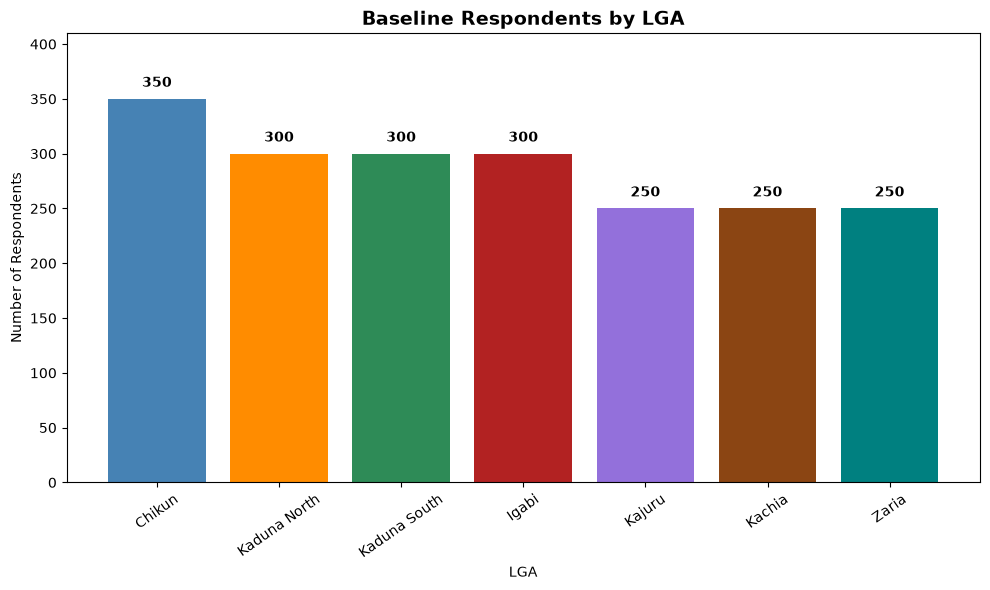

In [18]:
import matplotlib.pyplot as plt

lga_chart = (
    df["lga"]
    .map(lga_labels)
    .value_counts()
    .reindex([
        "Chikun",
        "Kaduna North",
        "Kaduna South",
        "Igabi",
        "Kajuru",
        "Kachia",
        "Zaria",
    ])
    .rename_axis("LGA")
    .reset_index(name="Respondents")
)

fig, ax = plt.subplots(figsize=(10, 6))

colors = [
    "steelblue",
    "darkorange",
    "seagreen",
    "firebrick",
    "mediumpurple",
    "saddlebrown",
    "teal",
]

bars = ax.bar(
    lga_chart["LGA"],
    lga_chart["Respondents"],
    color=colors
)

ax.set_title("Baseline Respondents by LGA", fontsize=14, fontweight="bold")
ax.set_xlabel("LGA")
ax.set_ylabel("Number of Respondents")
ax.tick_params(axis="x", rotation=35)

# Add respondent counts above each bar
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 8,
        f"{int(height)}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

ax.set_ylim(0, lga_chart["Respondents"].max() + 60)
plt.tight_layout()
plt.show()

In [19]:
# Beneficiary type by LGA

lga_beneficiary = pd.crosstab(
    df["lga"].map(lga_labels),
    df["beneficiary_type"].map({1: "Farmer", 2: "MSME"}),
)

lga_beneficiary["Total"] = lga_beneficiary.sum(axis=1)

display(lga_beneficiary)

beneficiary_type,Farmer,MSME,Total
lga,,,
Chikun,350,0,350
Igabi,300,0,300
Kachia,100,150,250
Kaduna North,300,0,300
Kaduna South,300,0,300
Kajuru,250,0,250
Zaria,0,250,250


In [20]:
lga_beneficiary_pct = (
    pd.crosstab(
        df["lga"].map(lga_labels),
        df["beneficiary_type"].map({1: "Farmer", 2: "MSME"}),
        normalize="index",
    ) * 100
).round(2)

display(lga_beneficiary_pct)

beneficiary_type,Farmer,MSME
lga,,
Chikun,100.0,0.0
Igabi,100.0,0.0
Kachia,40.0,60.0
Kaduna North,100.0,0.0
Kaduna South,100.0,0.0
Kajuru,100.0,0.0
Zaria,0.0,100.0


In [21]:
# Farmer value chain profile

value_chain_labels = {
    1: "Maize",
    2: "Rice",
    3: "Soybean",
    4: "Ginger",
    5: "Tomato",
    6: "Vegetables",
    7: "Sorghum",
    8: "Groundnut",
}

farmer_df = df[df["beneficiary_type"] == 1].copy()

value_chain_profile = (
    farmer_df["primary_value_chain"]
    .map(value_chain_labels)
    .value_counts()
    .rename_axis("Value Chain")
    .reset_index(name="Farmers")
)

value_chain_profile["Percent"] = (
    value_chain_profile["Farmers"] / len(farmer_df) * 100
).round(2)

display(value_chain_profile)

,Value Chain,Farmers,Percent
0,Maize,386,24.12
1,Rice,296,18.50
2,Soybean,219,13.69
3,Vegetables,187,11.69
4,Tomato,155,9.69
5,Ginger,139,8.69
6,Sorghum,135,8.44
7,Groundnut,83,5.19


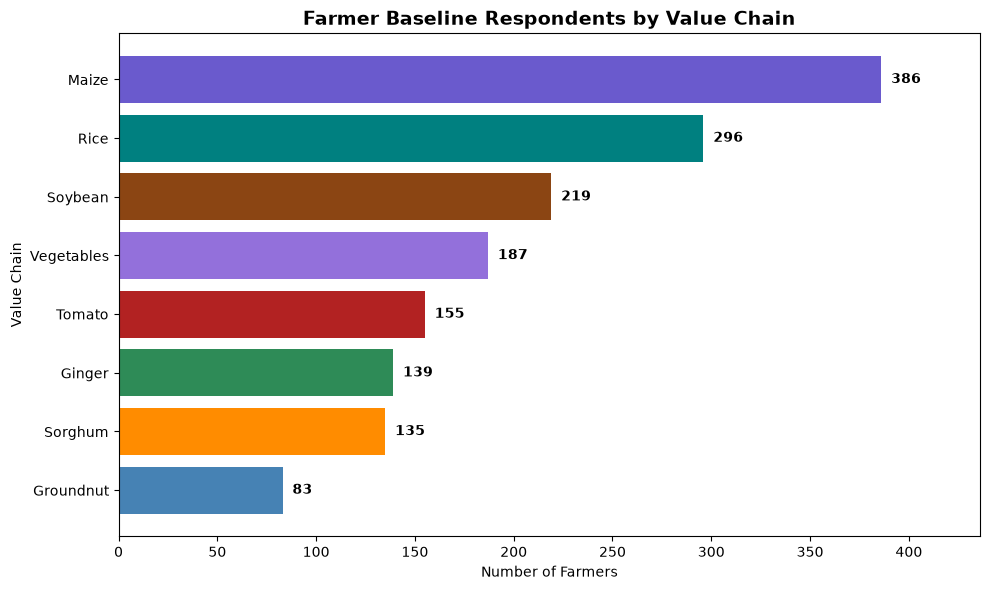

In [22]:
import matplotlib.pyplot as plt

chart_data = value_chain_profile.sort_values(
    "Farmers",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))

colors = [
    "steelblue",
    "darkorange",
    "seagreen",
    "firebrick",
    "mediumpurple",
    "saddlebrown",
    "teal",
    "slateblue",
]

bars = ax.barh(
    chart_data["Value Chain"],
    chart_data["Farmers"],
    color=colors
)

ax.set_title(
    "Farmer Baseline Respondents by Value Chain",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Number of Farmers")
ax.set_ylabel("Value Chain")

for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 5,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width)}",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_xlim(0, chart_data["Farmers"].max() + 50)

plt.tight_layout()
plt.show()

In [23]:
# Farmer farm characteristics

farm_characteristics = farmer_df[
    [
        "farm_area_ha",
        "area_cultivated_ha",
        "years_farming",
        "extension_contacts",
        "quantity_harvested_t",
        "quantity_sold_t",
        "quantity_consumed_t",
        "quantity_lost_t",
    ]
].describe().T

display(farm_characteristics)

,count,mean,std,min,25%,50%,75%,max
farm_area_ha,1589.0,2.611611,2.572129,0.20,1.3900,2.49,3.6000,85.00
area_cultivated_ha,1600.0,2.251463,1.365063,0.15,1.2175,2.20,3.1700,6.79
years_farming,1600.0,26.503750,14.558888,1.00,14.0000,27.00,41.0000,45.00
extension_contacts,1600.0,1.681875,2.085879,0.00,0.0000,0.00,3.0000,6.00
quantity_harvested_t,1600.0,5.640500,8.124733,0.09,2.0175,4.14,6.9425,250.00
quantity_sold_t,1599.0,3.278280,3.250559,0.05,1.1700,2.40,4.1700,26.35
quantity_consumed_t,1600.0,0.681669,0.758662,0.01,0.2000,0.47,0.8700,7.96
quantity_lost_t,1599.0,0.951726,1.071104,0.01,0.2600,0.63,1.2150,8.16


In [24]:
# Baseline denominator checks

print("Total respondents:", len(df))
print("Farmers:", (df["beneficiary_type"] == 1).sum())
print("MSMEs:", (df["beneficiary_type"] == 2).sum())
print(
    "Farmer value-chain records:",
    farmer_df["primary_value_chain"].notna().sum()
)

Total respondents: 2000
Farmers: 1600
MSMEs: 400
Farmer value-chain records: 1600


# 10. Baseline Indicator Calculations

This section calculates the baseline values for the ALMDP impact and outcome indicators using the cleaned baseline dataset.

Indicator calculations will use:
- Valid observations only.
- Indicator-specific denominators defined in the M&E Framework.
- Recalculated derived variables from the cleaned dataset.
- Explicit numerator and denominator reporting for rate-based indicators.
- Mean values for continuous indicators.
- Appropriate direction of interpretation for higher-is-better and lower-is-better indicators.

Extreme values retained during data quality review will remain in the baseline calculations unless a documented analytical rule requires otherwise.

OUT-03 will be flagged separately because the current baseline dataset does not contain a `training_received` variable required to construct its defined denominator.

In [25]:
# Indicator calculation results table

indicator_results = []

def add_indicator(
    indicator_id,
    indicator_name,
    value,
    unit,
    numerator=None,
    denominator=None,
    direction="Higher is better",
    status="Calculated"
):
    indicator_results.append({
        "Indicator ID": indicator_id,
        "Indicator": indicator_name,
        "Baseline Value": value,
        "Unit": unit,
        "Numerator": numerator,
        "Denominator": denominator,
        "Direction": direction,
        "Status": status,
    })

print("Indicator calculation framework initialized.")

Indicator calculation framework initialized.


In [26]:
# IMP-01: Average annual beneficiary income

valid_income = df["total_annual_income_ngn"].dropna()

imp01_value = valid_income.mean()
imp01_numerator = len(valid_income)

add_indicator(
    indicator_id="IMP-01",
    indicator_name="Average annual beneficiary income",
    value=round(imp01_value, 2),
    unit="NGN/year",
    numerator=imp01_numerator,
    denominator=len(df),
    direction="Higher is better"
)

print(f"IMP-01 baseline: NGN {imp01_value:,.2f}")
print(f"Valid observations: {imp01_numerator:,}")
print(f"Total respondents: {len(df):,}")

IMP-01 baseline: NGN 1,497,879.70
Valid observations: 1,985
Total respondents: 2,000


In [27]:
# IMP-02: Beneficiaries reporting improved economic resilience

valid_resilience = df["resilience_status"].dropna()

imp02_numerator = (valid_resilience == 1).sum()
imp02_denominator = len(valid_resilience)

imp02_value = (
    imp02_numerator / imp02_denominator * 100
    if imp02_denominator > 0 else np.nan
)

add_indicator(
    indicator_id="IMP-02",
    indicator_name="Beneficiaries reporting improved economic resilience",
    value=round(imp02_value, 2),
    unit="%",
    numerator=imp02_numerator,
    denominator=imp02_denominator,
    direction="Higher is better"
)

print(f"IMP-02 baseline: {imp02_value:.2f}%")
print(f"Resilient beneficiaries: {imp02_numerator:,}")
print(f"Valid observations: {imp02_denominator:,}")

IMP-02 baseline: 30.60%
Resilient beneficiaries: 612
Valid observations: 2,000


In [28]:
# OUT-01: Average crop productivity

valid_productivity = df.loc[
    (df["beneficiary_type"] == 1) &
    (df["productivity_t_per_ha"].notna()),
    "productivity_t_per_ha"
]

out01_value = valid_productivity.mean()
out01_numerator = len(valid_productivity)

add_indicator(
    indicator_id="OUT-01",
    indicator_name="Average crop productivity",
    value=round(out01_value, 3),
    unit="t/ha",
    numerator=out01_numerator,
    denominator=(df["beneficiary_type"] == 1).sum(),
    direction="Higher is better"
)

print(f"OUT-01 baseline: {out01_value:.3f} t/ha")
print(f"Valid farmer observations: {out01_numerator:,}")
print(f"Total farmers: {(df['beneficiary_type'] == 1).sum():,}")

OUT-01 baseline: 2.448 t/ha
Valid farmer observations: 1,600
Total farmers: 1,600


In [29]:
# OUT-02: Farmers adopting at least three recommended practices

valid_adoption = df.loc[
    (df["beneficiary_type"] == 1) &
    (df["adoption_status"].notna()),
    "adoption_status"
]

out02_numerator = (valid_adoption == 1).sum()
out02_denominator = len(valid_adoption)

out02_value = (
    out02_numerator / out02_denominator * 100
    if out02_denominator > 0 else np.nan
)

add_indicator(
    indicator_id="OUT-02",
    indicator_name="Farmers adopting at least three recommended practices",
    value=round(out02_value, 2),
    unit="%",
    numerator=out02_numerator,
    denominator=out02_denominator,
    direction="Higher is better"
)

print(f"OUT-02 baseline: {out02_value:.2f}%")
print(f"Farmers adopting >=3 practices: {out02_numerator:,}")
print(f"Valid farmer observations: {out02_denominator:,}")

OUT-02 baseline: 67.81%
Farmers adopting >=3 practices: 1,085
Valid farmer observations: 1,600


In [30]:
# OUT-03: Knowledge among trained farmers

out03_status = "Not calculated - training_received variable unavailable"

add_indicator(
    indicator_id="OUT-03",
    indicator_name="Trained farmers demonstrating adequate knowledge",
    value=np.nan,
    unit="%",
    numerator=None,
    denominator=None,
    direction="Higher is better",
    status=out03_status
)

print("OUT-03 status:", out03_status)
print("Required denominator variable: training_received")
print("Current dataset: training_received is not available.")

OUT-03 status: Not calculated - training_received variable unavailable
Required denominator variable: training_received
Current dataset: training_received is not available.


In [31]:
# OUT-04: Farmers selling through structured markets

valid_structured_market = df.loc[
    (df["beneficiary_type"] == 1) &
    (df["structured_market"].notna()),
    "structured_market"
]

out04_numerator = (valid_structured_market == 1).sum()
out04_denominator = len(valid_structured_market)

out04_value = (
    out04_numerator / out04_denominator * 100
    if out04_denominator > 0 else np.nan
)

add_indicator(
    indicator_id="OUT-04",
    indicator_name="Farmers selling through structured markets",
    value=round(out04_value, 2),
    unit="%",
    numerator=out04_numerator,
    denominator=out04_denominator,
    direction="Higher is better"
)

print(f"OUT-04 baseline: {out04_value:.2f}%")
print(f"Farmers selling through structured markets: {out04_numerator:,}")
print(f"Valid farmer observations: {out04_denominator:,}")

OUT-04 baseline: 27.31%
Farmers selling through structured markets: 437
Valid farmer observations: 1,600


In [32]:
# OUT-05: Farmers reporting improved buyer access

valid_buyer_access = df.loc[
    (df["beneficiary_type"] == 1) &
    (df["buyer_access_improved"].notna()),
    "buyer_access_improved"
]

out05_numerator = (valid_buyer_access == 1).sum()
out05_denominator = len(valid_buyer_access)

out05_value = (
    out05_numerator / out05_denominator * 100
    if out05_denominator > 0 else np.nan
)

add_indicator(
    indicator_id="OUT-05",
    indicator_name="Farmers reporting improved buyer access",
    value=round(out05_value, 2),
    unit="%",
    numerator=out05_numerator,
    denominator=out05_denominator,
    direction="Higher is better"
)

print(f"OUT-05 baseline: {out05_value:.2f}%")
print(f"Farmers reporting improved buyer access: {out05_numerator:,}")
print(f"Valid farmer observations: {out05_denominator:,}")

OUT-05 baseline: 30.00%
Farmers reporting improved buyer access: 480
Valid farmer observations: 1,600


In [33]:
# OUT-06: Average post-harvest loss rate

valid_loss_rate = df.loc[
    (df["beneficiary_type"] == 1) &
    (df["postharvest_loss_rate"].notna()),
    "postharvest_loss_rate"
]

out06_value = valid_loss_rate.mean()
out06_numerator = len(valid_loss_rate)

add_indicator(
    indicator_id="OUT-06",
    indicator_name="Average post-harvest loss rate",
    value=round(out06_value, 2),
    unit="%",
    numerator=out06_numerator,
    denominator=(df["beneficiary_type"] == 1).sum(),
    direction="Lower is better"
)

print(f"OUT-06 baseline: {out06_value:.2f}%")
print(f"Valid farmer observations: {out06_numerator:,}")
print(f"Total farmers: {(df['beneficiary_type'] == 1).sum():,}")

OUT-06 baseline: 17.33%
Valid farmer observations: 1,600
Total farmers: 1,600


In [34]:
# OUT-07: MSMEs reporting increased annual revenue

out07_status = "Not calculated - revenue_increased variable unavailable"

add_indicator(
    indicator_id="OUT-07",
    indicator_name="Supported MSMEs reporting increased annual revenue",
    value=np.nan,
    unit="%",
    numerator=None,
    denominator=None,
    direction="Higher is better",
    status=out07_status
)

print("OUT-07 status:", out07_status)
print("Required variable: revenue_increased")
print("Current dataset: revenue_increased is not available.")

OUT-07 status: Not calculated - revenue_increased variable unavailable
Required variable: revenue_increased
Current dataset: revenue_increased is not available.


In [35]:
# OUT-08: Average MSME annual profit

valid_msmE_profit = df.loc[
    (df["beneficiary_type"] == 2) &
    (df["annual_profit_ngn"].notna()),
    "annual_profit_ngn"
]

out08_value = valid_msmE_profit.mean()
out08_numerator = len(valid_msmE_profit)
out08_denominator = (df["beneficiary_type"] == 2).sum()

add_indicator(
    indicator_id="OUT-08",
    indicator_name="Average MSME annual profit",
    value=round(out08_value, 2),
    unit="NGN/year",
    numerator=out08_numerator,
    denominator=out08_denominator,
    direction="Higher is better"
)

print(f"OUT-08 baseline: NGN {out08_value:,.2f}")
print(f"Valid MSME observations: {out08_numerator:,}")
print(f"Total MSMEs: {out08_denominator:,}")
print(f"Negative-profit MSMEs: {(valid_msmE_profit < 0).sum():,}")

OUT-08 baseline: NGN 356,839.05
Valid MSME observations: 400
Total MSMEs: 400
Negative-profit MSMEs: 0


In [36]:
# OUT-09: MSMEs maintaining basic financial records

valid_financial_management = df.loc[
    (df["beneficiary_type"] == 2) &
    (df["financial_management_status"].notna()),
    "financial_management_status"
]

out09_numerator = (valid_financial_management == 1).sum()
out09_denominator = len(valid_financial_management)

out09_value = (
    out09_numerator / out09_denominator * 100
    if out09_denominator > 0 else np.nan
)

add_indicator(
    indicator_id="OUT-09",
    indicator_name="MSMEs maintaining basic financial records",
    value=round(out09_value, 2),
    unit="%",
    numerator=out09_numerator,
    denominator=out09_denominator,
    direction="Higher is better"
)

print(f"OUT-09 baseline: {out09_value:.2f}%")
print(f"MSMEs maintaining basic financial records: {out09_numerator:,}")
print(f"Valid MSME observations: {out09_denominator:,}")

OUT-09 baseline: 50.00%
MSMEs maintaining basic financial records: 200
Valid MSME observations: 400


In [37]:
# OUT-10: Direct beneficiaries who are women

valid_women = df.loc[
    df["women_beneficiary"].notna(),
    "women_beneficiary"
]

out10_numerator = (valid_women == 1).sum()
out10_denominator = len(valid_women)

out10_value = (
    out10_numerator / out10_denominator * 100
    if out10_denominator > 0 else np.nan
)

add_indicator(
    indicator_id="OUT-10",
    indicator_name="Direct beneficiaries who are women",
    value=round(out10_value, 2),
    unit="%",
    numerator=out10_numerator,
    denominator=out10_denominator,
    direction="Higher is better"
)

print(f"OUT-10 baseline: {out10_value:.2f}%")
print(f"Women beneficiaries: {out10_numerator:,}")
print(f"Valid beneficiary observations: {out10_denominator:,}")

OUT-10 baseline: 41.55%
Women beneficiaries: 831
Valid beneficiary observations: 2,000


In [38]:
# OUT-11: Direct beneficiaries aged 18-35

valid_youth = df.loc[
    df["youth_status"].notna(),
    "youth_status"
]

out11_numerator = (valid_youth == 1).sum()
out11_denominator = len(valid_youth)

out11_value = (
    out11_numerator / out11_denominator * 100
    if out11_denominator > 0 else np.nan
)

add_indicator(
    indicator_id="OUT-11",
    indicator_name="Direct beneficiaries aged 18-35",
    value=round(out11_value, 2),
    unit="%",
    numerator=out11_numerator,
    denominator=out11_denominator,
    direction="Higher is better"
)

print(f"OUT-11 baseline: {out11_value:.2f}%")
print(f"Youth beneficiaries (18-35): {out11_numerator:,}")
print(f"Valid age observations: {out11_denominator:,}")

OUT-11 baseline: 30.20%
Youth beneficiaries (18-35): 604
Valid age observations: 2,000


In [39]:
# OUT-12: Women beneficiaries reporting increased agricultural/business income

valid_women_income = df.loc[
    (df["women_beneficiary"] == 1) &
    (df["income_increased"].notna()),
    "income_increased"
]

out12_numerator = (valid_women_income == 1).sum()
out12_denominator = len(valid_women_income)

out12_value = (
    out12_numerator / out12_denominator * 100
    if out12_denominator > 0 else np.nan
)

add_indicator(
    indicator_id="OUT-12",
    indicator_name="Women beneficiaries reporting increased agricultural/business income",
    value=round(out12_value, 2),
    unit="%",
    numerator=out12_numerator,
    denominator=out12_denominator,
    direction="Higher is better"
)

print(f"OUT-12 baseline: {out12_value:.2f}%")
print(f"Women reporting increased income: {out12_numerator:,}")
print(f"Valid women observations: {out12_denominator:,}")

OUT-12 baseline: 29.12%
Women reporting increased income: 242
Valid women observations: 831


In [40]:
# Consolidated impact and outcome indicator review

impact_outcome_results = pd.DataFrame(indicator_results)

print("Impact and Outcome Indicator Results")
print("=" * 80)

display(
    impact_outcome_results[
        impact_outcome_results["Indicator ID"].isin(
            ["IMP-01", "IMP-02"] +
            [f"OUT-{i:02d}" for i in range(1, 13)]
        )
    ]
)

print("\nIndicators not calculated:")
not_calculated = impact_outcome_results[
    impact_outcome_results["Status"].str.startswith("Not calculated", na=False)
]

display(
    not_calculated[
        ["Indicator ID", "Indicator", "Status"]
    ]
)

Impact and Outcome Indicator Results


,Indicator ID,Indicator,Baseline Value,Unit,Numerator,Denominator,Direction,Status
0,IMP-01,Average annual beneficiary income,1497879.700,NGN/year,1985.0,2000.0,Higher is better,Calculated
1,IMP-02,Beneficiaries reporting improved economic resi...,30.600,%,612.0,2000.0,Higher is better,Calculated
2,OUT-01,Average crop productivity,2.448,t/ha,1600.0,1600.0,Higher is better,Calculated
3,OUT-02,Farmers adopting at least three recommended pr...,67.810,%,1085.0,1600.0,Higher is better,Calculated
4,OUT-03,Trained farmers demonstrating adequate knowledge,NaN,%,NaN,NaN,Higher is better,Not calculated - training_received variable un...
5,OUT-04,Farmers selling through structured markets,27.310,%,437.0,1600.0,Higher is better,Calculated
6,OUT-05,Farmers reporting improved buyer access,30.000,%,480.0,1600.0,Higher is better,Calculated
7,OUT-06,Average post-harvest loss rate,17.330,%,1600.0,1600.0,Lower is better,Calculated
8,OUT-07,Supported MSMEs reporting increased annual rev...,NaN,%,NaN,NaN,Higher is better,Not calculated - revenue_increased variable un...
9,OUT-08,Average MSME annual profit,356839.050,NGN/year,400.0,400.0,Higher is better,Calculated



Indicators not calculated:


,Indicator ID,Indicator,Status
4,OUT-03,Trained farmers demonstrating adequate knowledge,Not calculated - training_received variable un...
8,OUT-07,Supported MSMEs reporting increased annual rev...,Not calculated - revenue_increased variable un...


In [41]:
# OUT-11 QA: verify age and youth-status consistency

print("Age missing:", df["age"].isna().sum())
print("Age valid:", df["age"].notna().sum())

print("Youth status missing:", df["youth_status"].isna().sum())
print("Youth status valid:", df["youth_status"].notna().sum())

expected_youth_status = np.where(
    df["age"].notna(),
    ((df["age"] >= 18) & (df["age"] <= 35)).astype(int),
    np.nan
)

mismatch = (
    df["youth_status"].notna() &
    (df["youth_status"] != expected_youth_status)
)

print("Mismatched records:", mismatch.sum())

if mismatch.sum() > 0:
    display(
        df.loc[
            mismatch,
            ["respondent_id", "age", "youth_status"]
        ]
    )

Age missing: 1
Age valid: 1999
Youth status missing: 0
Youth status valid: 2000
Mismatched records: 1


,respondent_id,age,youth_status
147,ALMDP-0148,NaN,1


In [42]:
# Recalculate youth_status from the cleaned age variable

df["youth_status"] = np.where(
    df["age"].notna(),
    ((df["age"] >= 18) & (df["age"] <= 35)).astype(int),
    np.nan
)

print("Youth status recalculated.")
print("Youth status missing:", df["youth_status"].isna().sum())
print("Youth status valid:", df["youth_status"].notna().sum())

Youth status recalculated.
Youth status missing: 1
Youth status valid: 1999


In [43]:
# OUT-11: Recalculate after correcting youth_status

valid_youth = df.loc[
    df["youth_status"].notna(),
    "youth_status"
]

out11_numerator = (valid_youth == 1).sum()
out11_denominator = len(valid_youth)

out11_value = (
    out11_numerator / out11_denominator * 100
    if out11_denominator > 0 else np.nan
)

# Remove the previous OUT-11 result
indicator_results = [
    result for result in indicator_results
    if result["Indicator ID"] != "OUT-11"
]

add_indicator(
    indicator_id="OUT-11",
    indicator_name="Direct beneficiaries aged 18-35",
    value=round(out11_value, 2),
    unit="%",
    numerator=out11_numerator,
    denominator=out11_denominator,
    direction="Higher is better"
)

print(f"OUT-11 corrected baseline: {out11_value:.2f}%")
print(f"Youth beneficiaries (18-35): {out11_numerator:,}")
print(f"Valid age observations: {out11_denominator:,}")

OUT-11 corrected baseline: 30.17%
Youth beneficiaries (18-35): 603
Valid age observations: 1,999


In [44]:
# 10.18 Derived Variable QA

print("Derived Variable QA")
print("=" * 70)

# 1. Youth status
expected_youth = np.where(
    df["age"].notna(),
    ((df["age"] >= 18) & (df["age"] <= 35)).astype(int),
    np.nan
)

youth_mismatch = (
    df["youth_status"].notna() &
    (df["youth_status"] != expected_youth)
).sum()

print(f"1. youth_status mismatches: {youth_mismatch}")

# 2. Productivity
expected_productivity = (
    df["quantity_harvested_t"] / df["area_cultivated_ha"]
)

productivity_mismatch = (
    df["productivity_t_per_ha"].notna() &
    (
        (df["productivity_t_per_ha"] - expected_productivity).abs()
        > 0.001
    )
).sum()

print(f"2. productivity mismatches: {productivity_mismatch}")

# 3. Practice adoption
practice_columns = [
    "improved_seed",
    "soil_testing",
    "fertilizer_management",
    "integrated_pest_management",
    "conservation_agriculture",
    "water_management",
    "improved_storage",
    "climate_smart_practice"
]

expected_practices = df[practice_columns].sum(axis=1)
expected_adoption = np.where(
    expected_practices >= 3,
    1,
    0
)

adoption_mismatch = (
    df["adoption_status"].notna() &
    (df["adoption_status"] != expected_adoption)
).sum()

print(f"3. adoption_status mismatches: {adoption_mismatch}")

# 4. Post-harvest loss rate
expected_loss = (
    df["total_postharvest_loss_t"] /
    df["quantity_harvested_t"] * 100
)

loss_mismatch = (
    df["postharvest_loss_rate"].notna() &
    (
        (df["postharvest_loss_rate"] - expected_loss).abs()
        > 0.001
    )
).sum()

print(f"4. postharvest_loss_rate mismatches: {loss_mismatch}")

# 5. Annual profit
expected_profit = (
    df["annual_sales_ngn"] -
    df["annual_operating_cost_ngn"]
)

profit_mismatch = (
    df["annual_profit_ngn"].notna() &
    (
        (df["annual_profit_ngn"] - expected_profit).abs()
        > 0.01
    )
).sum()

print(f"5. annual_profit_ngn mismatches: {profit_mismatch}")

# 6. Financial management status
record_columns = [
    "sales_records",
    "expense_records",
    "inventory_records",
    "cashflow_records",
    "profit_loss_records"
]

expected_record_count = df[record_columns].sum(axis=1)
expected_financial_status = np.where(
    expected_record_count >= 3,
    1,
    0
)

financial_mismatch = (
    df["financial_management_status"].notna() &
    (
        df["financial_management_status"] !=
        expected_financial_status
    )
).sum()

print(
    f"6. financial_management_status mismatches: "
    f"{financial_mismatch}"
)

# 7. Resilience status
expected_resilience_status = np.where(
    df["resilience_score"].notna(),
    (df["resilience_score"] >= 60).astype(int),
    np.nan
)

resilience_mismatch = (
    df["resilience_status"].notna() &
    (
        df["resilience_status"] !=
        expected_resilience_status
    )
).sum()

print(f"7. resilience_status mismatches: {resilience_mismatch}")

# 8. Knowledge score
knowledge_columns = [
    f"knowledge_q{i}" for i in range(1, 11)
]

expected_knowledge_score = df[knowledge_columns].sum(axis=1)

knowledge_mismatch = (
    df["knowledge_score"].notna() &
    (
        df["knowledge_score"] !=
        expected_knowledge_score
    )
).sum()

print(f"8. knowledge_score mismatches: {knowledge_mismatch}")

print("=" * 70)

total_mismatches = sum([
    youth_mismatch,
    productivity_mismatch,
    adoption_mismatch,
    loss_mismatch,
    profit_mismatch,
    financial_mismatch,
    resilience_mismatch,
    knowledge_mismatch
])

print(f"TOTAL DERIVED-VARIABLE MISMATCHES: {total_mismatches}")

Derived Variable QA
1. youth_status mismatches: 0
2. productivity mismatches: 0
3. adoption_status mismatches: 0
4. postharvest_loss_rate mismatches: 0
5. annual_profit_ngn mismatches: 0
6. financial_management_status mismatches: 0
7. resilience_status mismatches: 0
8. knowledge_score mismatches: 0
TOTAL DERIVED-VARIABLE MISMATCHES: 0


In [45]:
# 10.19 Final Impact and Outcome Baseline Table

impact_outcome_ids = (
    ["IMP-01", "IMP-02"] +
    [f"OUT-{i:02d}" for i in range(1, 13)]
)

impact_outcome_baseline = (
    pd.DataFrame(indicator_results)
    .loc[
        lambda x: x["Indicator ID"].isin(impact_outcome_ids)
    ]
    .sort_values("Indicator ID")
    .reset_index(drop=True)
)

print("FINAL IMPACT AND OUTCOME BASELINE TABLE")
print("=" * 100)

display(impact_outcome_baseline)

print("\nCalculated indicators:",
      (impact_outcome_baseline["Status"] == "Calculated").sum())

print("Not calculated:",
      (~impact_outcome_baseline["Status"].eq("Calculated")).sum())

FINAL IMPACT AND OUTCOME BASELINE TABLE


,Indicator ID,Indicator,Baseline Value,Unit,Numerator,Denominator,Direction,Status
0,IMP-01,Average annual beneficiary income,1497879.700,NGN/year,1985.0,2000.0,Higher is better,Calculated
1,IMP-02,Beneficiaries reporting improved economic resi...,30.600,%,612.0,2000.0,Higher is better,Calculated
2,OUT-01,Average crop productivity,2.448,t/ha,1600.0,1600.0,Higher is better,Calculated
3,OUT-02,Farmers adopting at least three recommended pr...,67.810,%,1085.0,1600.0,Higher is better,Calculated
4,OUT-03,Trained farmers demonstrating adequate knowledge,NaN,%,NaN,NaN,Higher is better,Not calculated - training_received variable un...
5,OUT-04,Farmers selling through structured markets,27.310,%,437.0,1600.0,Higher is better,Calculated
6,OUT-05,Farmers reporting improved buyer access,30.000,%,480.0,1600.0,Higher is better,Calculated
7,OUT-06,Average post-harvest loss rate,17.330,%,1600.0,1600.0,Lower is better,Calculated
8,OUT-07,Supported MSMEs reporting increased annual rev...,NaN,%,NaN,NaN,Higher is better,Not calculated - revenue_increased variable un...
9,OUT-08,Average MSME annual profit,356839.050,NGN/year,400.0,400.0,Higher is better,Calculated



Calculated indicators: 12
Not calculated: 2


In [46]:
# 10.20 Output Indicator Baseline Calculations

output_results = []

def add_output_indicator(
    indicator_id,
    indicator_name,
    baseline_value,
    unit,
    numerator=None,
    denominator=None,
    direction="Higher is better",
    status="Baseline"
):
    output_results.append({
        "Indicator ID": indicator_id,
        "Indicator": indicator_name,
        "Baseline Value": baseline_value,
        "Unit": unit,
        "Numerator": numerator,
        "Denominator": denominator,
        "Direction": direction,
        "Status": status,
    })


# OP-01: Farmers trained
add_output_indicator(
    "OP-01",
    "Number of farmers trained",
    0,
    "farmers",
    0,
    None,
    "Higher is better",
    "Baseline - pre-implementation"
)

# OP-02: Farmers completing CSA training
add_output_indicator(
    "OP-02",
    "Number of farmers completing CSA training",
    0,
    "farmers",
    0,
    None,
    "Higher is better",
    "Baseline - pre-implementation"
)

# OP-03: Demonstration plots established
add_output_indicator(
    "OP-03",
    "Number of demonstration plots established",
    0,
    "plots",
    0,
    None,
    "Higher is better",
    "Baseline - pre-implementation"
)

# OP-04: Market-linkage events
add_output_indicator(
    "OP-04",
    "Number of market-linkage events",
    0,
    "events",
    0,
    None,
    "Higher is better",
    "Baseline - pre-implementation"
)

# OP-05: Farmers receiving market information
add_output_indicator(
    "OP-05",
    "Number of farmers receiving market information",
    0,
    "farmers",
    0,
    None,
    "Higher is better",
    "Baseline - pre-implementation"
)

# OP-06: MSMEs receiving business support
add_output_indicator(
    "OP-06",
    "Number of MSMEs receiving business support",
    0,
    "MSMEs",
    0,
    None,
    "Higher is better",
    "Baseline - pre-implementation"
)

# OP-07: MSMEs completing financial management training
add_output_indicator(
    "OP-07",
    "Number of MSMEs completing financial management training",
    0,
    "MSMEs",
    0,
    None,
    "Higher is better",
    "Baseline - pre-implementation"
)

# OP-08: M&E activities completed on time
add_output_indicator(
    "OP-08",
    "Scheduled M&E activities completed on time",
    np.nan,
    "%",
    None,
    None,
    "Higher is better",
    "Not applicable at baseline - implementation tracker unavailable"
)

# OP-09: Required reports submitted on time
add_output_indicator(
    "OP-09",
    "Required reports submitted on time",
    np.nan,
    "%",
    None,
    None,
    "Higher is better",
    "Not applicable at baseline - reporting tracker unavailable"
)

# OP-10: Sampled records passing DQA
add_output_indicator(
    "OP-10",
    "Sampled records passing DQA",
    np.nan,
    "%",
    None,
    None,
    "Higher is better",
    "Not applicable at baseline - periodic DQA not yet conducted"
)


output_baseline = (
    pd.DataFrame(output_results)
    .sort_values("Indicator ID")
    .reset_index(drop=True)
)

print("OUTPUT INDICATOR BASELINE TABLE")
print("=" * 100)

display(output_baseline)

print("\nOutput indicators:", len(output_baseline))
print(
    "Pre-implementation indicators:",
    (
        output_baseline["Status"]
        .str.contains("pre-implementation", na=False)
    ).sum()
)
print(
    "Not applicable at baseline:",
    (
        output_baseline["Status"]
        .str.contains("Not applicable", na=False)
    ).sum()
)

OUTPUT INDICATOR BASELINE TABLE


,Indicator ID,Indicator,Baseline Value,Unit,Numerator,Denominator,Direction,Status
0,OP-01,Number of farmers trained,0.0,farmers,0.0,None,Higher is better,Baseline - pre-implementation
1,OP-02,Number of farmers completing CSA training,0.0,farmers,0.0,None,Higher is better,Baseline - pre-implementation
2,OP-03,Number of demonstration plots established,0.0,plots,0.0,None,Higher is better,Baseline - pre-implementation
3,OP-04,Number of market-linkage events,0.0,events,0.0,None,Higher is better,Baseline - pre-implementation
4,OP-05,Number of farmers receiving market information,0.0,farmers,0.0,None,Higher is better,Baseline - pre-implementation
5,OP-06,Number of MSMEs receiving business support,0.0,MSMEs,0.0,None,Higher is better,Baseline - pre-implementation
6,OP-07,Number of MSMEs completing financial managemen...,0.0,MSMEs,0.0,None,Higher is better,Baseline - pre-implementation
7,OP-08,Scheduled M&E activities completed on time,NaN,%,NaN,None,Higher is better,Not applicable at baseline - implementation tr...
8,OP-09,Required reports submitted on time,NaN,%,NaN,None,Higher is better,Not applicable at baseline - reporting tracker...
9,OP-10,Sampled records passing DQA,NaN,%,NaN,None,Higher is better,Not applicable at baseline - periodic DQA not ...



Output indicators: 10
Pre-implementation indicators: 7
Not applicable at baseline: 3


In [47]:
# 10.21 Consolidated Baseline Indicator Register

baseline_indicator_register = pd.concat(
    [
        impact_outcome_baseline,
        output_baseline
    ],
    ignore_index=True
)

# Define the intended master indicator order
indicator_order = [
    "IMP-01", "IMP-02",
    "OUT-01", "OUT-02", "OUT-03", "OUT-04", "OUT-05",
    "OUT-06", "OUT-07", "OUT-08", "OUT-09", "OUT-10",
    "OUT-11", "OUT-12",
    "OP-01", "OP-02", "OP-03", "OP-04", "OP-05",
    "OP-06", "OP-07", "OP-08", "OP-09", "OP-10"
]

baseline_indicator_register["Indicator ID"] = pd.Categorical(
    baseline_indicator_register["Indicator ID"],
    categories=indicator_order,
    ordered=True
)

baseline_indicator_register = (
    baseline_indicator_register
    .sort_values("Indicator ID")
    .reset_index(drop=True)
)

print("CONSOLIDATED ALMDP BASELINE INDICATOR REGISTER")
print("=" * 110)

display(baseline_indicator_register)

print("\nTotal indicators:",
      len(baseline_indicator_register))

print(
    "Impact:",
    baseline_indicator_register["Indicator ID"]
    .astype(str).str.startswith("IMP").sum()
)

print(
    "Outcome:",
    baseline_indicator_register["Indicator ID"]
    .astype(str).str.startswith("OUT").sum()
)

print(
    "Output:",
    baseline_indicator_register["Indicator ID"]
    .astype(str).str.startswith("OP").sum()
)

CONSOLIDATED ALMDP BASELINE INDICATOR REGISTER


,Indicator ID,Indicator,Baseline Value,Unit,Numerator,Denominator,Direction,Status
0,IMP-01,Average annual beneficiary income,1497879.700,NGN/year,1985.0,2000.0,Higher is better,Calculated
1,IMP-02,Beneficiaries reporting improved economic resi...,30.600,%,612.0,2000.0,Higher is better,Calculated
2,OUT-01,Average crop productivity,2.448,t/ha,1600.0,1600.0,Higher is better,Calculated
3,OUT-02,Farmers adopting at least three recommended pr...,67.810,%,1085.0,1600.0,Higher is better,Calculated
4,OUT-03,Trained farmers demonstrating adequate knowledge,NaN,%,NaN,NaN,Higher is better,Not calculated - training_received variable un...
5,OUT-04,Farmers selling through structured markets,27.310,%,437.0,1600.0,Higher is better,Calculated
6,OUT-05,Farmers reporting improved buyer access,30.000,%,480.0,1600.0,Higher is better,Calculated
7,OUT-06,Average post-harvest loss rate,17.330,%,1600.0,1600.0,Lower is better,Calculated
8,OUT-07,Supported MSMEs reporting increased annual rev...,NaN,%,NaN,NaN,Higher is better,Not calculated - revenue_increased variable un...
9,OUT-08,Average MSME annual profit,356839.050,NGN/year,400.0,400.0,Higher is better,Calculated



Total indicators: 24
Impact: 2
Outcome: 12
Output: 10


In [48]:
# 10.22 Indicator QA - Corrected

print("ALMDP BASELINE INDICATOR QA")
print("=" * 80)

qa_results = []

# 1. Check all expected indicator IDs
expected_ids = set(indicator_order)
actual_ids = set(
    baseline_indicator_register["Indicator ID"].astype(str)
)

missing_ids = expected_ids - actual_ids
unexpected_ids = actual_ids - expected_ids

qa_results.append({
    "QA Check": "All expected indicator IDs present",
    "Result": len(missing_ids) == 0,
    "Details": f"Missing: {sorted(missing_ids)}"
})

qa_results.append({
    "QA Check": "No unexpected indicator IDs",
    "Result": len(unexpected_ids) == 0,
    "Details": f"Unexpected: {sorted(unexpected_ids)}"
})


# 2. Duplicate indicator IDs
duplicate_ids = (
    baseline_indicator_register["Indicator ID"]
    .astype(str)
    .duplicated()
    .sum()
)

qa_results.append({
    "QA Check": "No duplicate indicator IDs",
    "Result": duplicate_ids == 0,
    "Details": f"Duplicates: {duplicate_ids}"
})


# 3. Expected indicator count
qa_results.append({
    "QA Check": "Exactly 24 indicators",
    "Result": len(baseline_indicator_register) == 24,
    "Details": f"Actual count: {len(baseline_indicator_register)}"
})


# 4. Percentage indicators with numeric numerator/denominator
rate_rows = baseline_indicator_register[
    baseline_indicator_register["Unit"].eq("%")
].copy()

# Only rows with BOTH numerator and denominator can be tested
rate_rows_numeric = rate_rows[
    rate_rows["Numerator"].notna() &
    rate_rows["Denominator"].notna()
].copy()

invalid_rates = rate_rows_numeric[
    (rate_rows_numeric["Numerator"] < 0) |
    (rate_rows_numeric["Denominator"] <= 0) |
    (
        rate_rows_numeric["Numerator"] >
        rate_rows_numeric["Denominator"]
    )
]

qa_results.append({
    "QA Check": "Percentage indicators have valid numerator/denominator",
    "Result": len(invalid_rates) == 0,
    "Details": (
        f"Tested: {len(rate_rows_numeric)}; "
        f"Invalid: {len(invalid_rates)}"
    )
})


# 5. Calculated percentage indicators must have values
calculated_rates = rate_rows[
    rate_rows["Status"].eq("Calculated")
]

missing_calculated_rates = calculated_rates[
    calculated_rates["Baseline Value"].isna()
]

qa_results.append({
    "QA Check": "Calculated percentage indicators have baseline values",
    "Result": len(missing_calculated_rates) == 0,
    "Details": f"Missing values: {len(missing_calculated_rates)}"
})


# 6. Unavailable indicators must remain unpopulated
unavailable = baseline_indicator_register[
    baseline_indicator_register["Status"].str.contains(
        "Not calculated|Not applicable",
        na=False
    )
]

fabricated_unavailable = unavailable[
    unavailable["Baseline Value"].notna()
]

qa_results.append({
    "QA Check": "Unavailable indicators remain unpopulated",
    "Result": len(fabricated_unavailable) == 0,
    "Details": f"Unexpected values: {len(fabricated_unavailable)}"
})


# 7. OUT-06 direction
out06_direction = baseline_indicator_register.loc[
    baseline_indicator_register["Indicator ID"].astype(str) == "OUT-06",
    "Direction"
].iloc[0]

qa_results.append({
    "QA Check": "OUT-06 correctly marked lower-is-better",
    "Result": out06_direction == "Lower is better",
    "Details": f"Direction: {out06_direction}"
})


# 8. OUT-11 corrected baseline
out11 = baseline_indicator_register[
    baseline_indicator_register["Indicator ID"].astype(str) == "OUT-11"
].iloc[0]

out11_check = (
    out11["Numerator"] == 603 and
    out11["Denominator"] == 1999 and
    round(out11["Baseline Value"], 2) == 30.17
)

qa_results.append({
    "QA Check": "OUT-11 corrected baseline is preserved",
    "Result": out11_check,
    "Details": (
        f"{out11['Numerator']:.0f}/"
        f"{out11['Denominator']:.0f} = "
        f"{out11['Baseline Value']:.2f}%"
    )
})


# Display QA results
qa_table = pd.DataFrame(qa_results)

display(qa_table)

print("\n" + "=" * 80)

failed_checks = (~qa_table["Result"]).sum()

print(f"QA checks performed: {len(qa_table)}")
print(f"Passed: {(qa_table['Result']).sum()}")
print(f"Failed: {failed_checks}")

if failed_checks == 0:
    print("\nSTATUS: PASS - Baseline indicator register is QA-cleared.")
else:
    print("\nSTATUS: FAIL - Review failed QA checks before proceeding.")

ALMDP BASELINE INDICATOR QA


,QA Check,Result,Details
0,All expected indicator IDs present,True,Missing: []
1,No unexpected indicator IDs,True,Unexpected: []
2,No duplicate indicator IDs,True,Duplicates: 0
3,Exactly 24 indicators,True,Actual count: 24
4,Percentage indicators have valid numerator/den...,True,Tested: 9; Invalid: 0
5,Calculated percentage indicators have baseline...,True,Missing values: 0
6,Unavailable indicators remain unpopulated,True,Unexpected values: 0
7,OUT-06 correctly marked lower-is-better,True,Direction: Lower is better
8,OUT-11 corrected baseline is preserved,True,603/1999 = 30.17%



QA checks performed: 9
Passed: 9
Failed: 0

STATUS: PASS - Baseline indicator register is QA-cleared.


## 10.23 Baseline Disaggregation

Baseline indicators will be disaggregated to identify differences in beneficiary characteristics, agricultural performance, market participation, MSME performance, inclusion, and economic resilience.

The primary disaggregation dimensions will be:

- LGA
- Beneficiary type
- Sex
- Age group
- Agricultural value chain, for farmer-specific indicators

Disaggregation will use valid observations and indicator-specific denominators. Results will not be interpreted as causal differences between groups. They will be used to identify baseline variation, equity considerations, implementation priorities, and areas requiring closer monitoring.

In [49]:
# 10.23.1 LGA Baseline Profile - Corrected

lga_profile = (
    df.groupby("lga", dropna=False)
    .agg(
        respondents=("respondent_id", "count"),
        farmers=("beneficiary_type", lambda x: (x == 1).sum()),
        msmes=("beneficiary_type", lambda x: (x == 2).sum()),
        female=("sex", lambda x: (x == 1).sum()),
        youth=("youth_status", lambda x: (x == 1).sum()),
        valid_age=("age", lambda x: x.notna().sum())
    )
    .reset_index()
)

lga_profile["respondent_share_pct"] = (
    lga_profile["respondents"] /
    lga_profile["respondents"].sum() * 100
)

lga_profile["female_share_pct"] = (
    lga_profile["female"] /
    lga_profile["respondents"] * 100
)

lga_profile["youth_share_pct"] = (
    lga_profile["youth"] /
    lga_profile["valid_age"] * 100
)

lga_profile["LGA"] = (
    lga_profile["lga"]
    .map(lga_labels)
    .fillna(lga_profile["lga"])
)

lga_profile = lga_profile[
    [
        "LGA",
        "respondents",
        "respondent_share_pct",
        "farmers",
        "msmes",
        "female",
        "female_share_pct",
        "youth",
        "youth_share_pct",
        "valid_age"
    ]
].sort_values("LGA")

display(lga_profile)

,LGA,respondents,respondent_share_pct,farmers,msmes,female,female_share_pct,youth,youth_share_pct,valid_age
0,Chikun,350,17.5,350,0,147,42.000000,105,30.000000,350
1,Igabi,300,15.0,300,0,130,43.333333,86,28.666667,300
2,Kachia,250,12.5,100,150,96,38.400000,68,27.200000,250
4,Kaduna North,300,15.0,300,0,127,42.333333,90,30.100334,299
5,Kaduna South,300,15.0,300,0,120,40.000000,91,30.333333,300
3,Kajuru,250,12.5,250,0,109,43.600000,84,33.600000,250
6,Zaria,250,12.5,0,250,102,40.800000,79,31.600000,250


In [50]:
# 10.23.2 LGA-Level Baseline Performance Indicators

lga_indicators = []

for lga_code, group in df.groupby("lga"):
    
    lga_name = lga_labels.get(lga_code, lga_code)
    
    # IMP-01: Average annual beneficiary income
    valid_income = group["total_annual_income_ngn"].dropna()
    
    lga_indicators.append({
        "LGA": lga_name,
        "Indicator ID": "IMP-01",
        "Indicator": "Average annual beneficiary income",
        "Baseline Value": valid_income.mean(),
        "Unit": "NGN/year",
        "Numerator": len(valid_income),
        "Denominator": len(group)
    })
    
    # IMP-02: Economic resilience
    valid_resilience = group["resilience_status"].dropna()
    
    lga_indicators.append({
        "LGA": lga_name,
        "Indicator ID": "IMP-02",
        "Indicator": "Beneficiaries reporting improved economic resilience",
        "Baseline Value": (
            (valid_resilience == 1).mean() * 100
            if len(valid_resilience) > 0 else np.nan
        ),
        "Unit": "%",
        "Numerator": (valid_resilience == 1).sum(),
        "Denominator": len(valid_resilience)
    })
    
    # Farmer-specific indicators
    farmers = group[group["beneficiary_type"] == 1]
    
    # OUT-01: Crop productivity
    valid_productivity = farmers["productivity_t_per_ha"].dropna()
    
    lga_indicators.append({
        "LGA": lga_name,
        "Indicator ID": "OUT-01",
        "Indicator": "Average crop productivity",
        "Baseline Value": valid_productivity.mean(),
        "Unit": "t/ha",
        "Numerator": len(valid_productivity),
        "Denominator": len(farmers)
    })
    
    # OUT-02: Practice adoption
    valid_adoption = farmers["adoption_status"].dropna()
    
    lga_indicators.append({
        "LGA": lga_name,
        "Indicator ID": "OUT-02",
        "Indicator": "Farmers adopting at least three recommended practices",
        "Baseline Value": (
            (valid_adoption == 1).mean() * 100
            if len(valid_adoption) > 0 else np.nan
        ),
        "Unit": "%",
        "Numerator": (valid_adoption == 1).sum(),
        "Denominator": len(valid_adoption)
    })
    
    # OUT-04: Structured markets
    valid_market = farmers["structured_market"].dropna()
    
    lga_indicators.append({
        "LGA": lga_name,
        "Indicator ID": "OUT-04",
        "Indicator": "Farmers selling through structured markets",
        "Baseline Value": (
            (valid_market == 1).mean() * 100
            if len(valid_market) > 0 else np.nan
        ),
        "Unit": "%",
        "Numerator": (valid_market == 1).sum(),
        "Denominator": len(valid_market)
    })
    
    # OUT-05: Buyer access
    valid_buyer = farmers["buyer_access_improved"].dropna()
    
    lga_indicators.append({
        "LGA": lga_name,
        "Indicator ID": "OUT-05",
        "Indicator": "Farmers reporting improved buyer access",
        "Baseline Value": (
            (valid_buyer == 1).mean() * 100
            if len(valid_buyer) > 0 else np.nan
        ),
        "Unit": "%",
        "Numerator": (valid_buyer == 1).sum(),
        "Denominator": len(valid_buyer)
    })
    
    # OUT-06: Post-harvest loss
    valid_loss = farmers["postharvest_loss_rate"].dropna()
    
    lga_indicators.append({
        "LGA": lga_name,
        "Indicator ID": "OUT-06",
        "Indicator": "Average post-harvest loss rate",
        "Baseline Value": valid_loss.mean(),
        "Unit": "%",
        "Numerator": len(valid_loss),
        "Denominator": len(farmers)
    })
    
    # MSME-specific indicators
    msmes = group[group["beneficiary_type"] == 2]
    
    # OUT-08: Average MSME annual profit
    valid_profit = msmes["annual_profit_ngn"].dropna()
    
    lga_indicators.append({
        "LGA": lga_name,
        "Indicator ID": "OUT-08",
        "Indicator": "Average MSME annual profit",
        "Baseline Value": valid_profit.mean(),
        "Unit": "NGN/year",
        "Numerator": len(valid_profit),
        "Denominator": len(msmes)
    })
    
    # OUT-09: Financial records
    valid_financial = msmes["financial_management_status"].dropna()
    
    lga_indicators.append({
        "LGA": lga_name,
        "Indicator ID": "OUT-09",
        "Indicator": "MSMEs maintaining basic financial records",
        "Baseline Value": (
            (valid_financial == 1).mean() * 100
            if len(valid_financial) > 0 else np.nan
        ),
        "Unit": "%",
        "Numerator": (valid_financial == 1).sum(),
        "Denominator": len(valid_financial)
    })
    
    # OUT-10: Women beneficiaries
    valid_sex = group["sex"].dropna()
    
    lga_indicators.append({
        "LGA": lga_name,
        "Indicator ID": "OUT-10",
        "Indicator": "Direct beneficiaries who are women",
        "Baseline Value": (
            (valid_sex == 1).mean() * 100
            if len(valid_sex) > 0 else np.nan
        ),
        "Unit": "%",
        "Numerator": (valid_sex == 1).sum(),
        "Denominator": len(valid_sex)
    })
    
    # OUT-11: Youth
    valid_youth = group["youth_status"].dropna()
    
    lga_indicators.append({
        "LGA": lga_name,
        "Indicator ID": "OUT-11",
        "Indicator": "Direct beneficiaries aged 18-35",
        "Baseline Value": (
            (valid_youth == 1).mean() * 100
            if len(valid_youth) > 0 else np.nan
        ),
        "Unit": "%",
        "Numerator": (valid_youth == 1).sum(),
        "Denominator": len(valid_youth)
    })
    
    # OUT-12: Women reporting increased income
    women = group[group["sex"] == 1]
    valid_income_increase = women["income_increased"].dropna()
    
    lga_indicators.append({
        "LGA": lga_name,
        "Indicator ID": "OUT-12",
        "Indicator": "Women reporting increased agricultural/business income",
        "Baseline Value": (
            (valid_income_increase == 1).mean() * 100
            if len(valid_income_increase) > 0 else np.nan
        ),
        "Unit": "%",
        "Numerator": (valid_income_increase == 1).sum(),
        "Denominator": len(valid_income_increase)
    })


lga_indicator_table = (
    pd.DataFrame(lga_indicators)
    .sort_values(["Indicator ID", "LGA"])
    .reset_index(drop=True)
)

display(lga_indicator_table)

,LGA,Indicator ID,Indicator,Baseline Value,Unit,Numerator,Denominator
0,Chikun,IMP-01,Average annual beneficiary income,1.615888e+06,NGN/year,348,350
1,Igabi,IMP-01,Average annual beneficiary income,1.680687e+06,NGN/year,298,300
2,Kachia,IMP-01,Average annual beneficiary income,1.231803e+06,NGN/year,248,250
3,Kaduna North,IMP-01,Average annual beneficiary income,1.637572e+06,NGN/year,297,300
4,Kaduna South,IMP-01,Average annual beneficiary income,1.656142e+06,NGN/year,298,300
...,...,...,...,...,...,...,...
79,Kachia,OUT-12,Women reporting increased agricultural/busines...,2.604167e+01,%,25,96
80,Kaduna North,OUT-12,Women reporting increased agricultural/busines...,2.677165e+01,%,34,127
81,Kaduna South,OUT-12,Women reporting increased agricultural/busines...,3.250000e+01,%,39,120
82,Kajuru,OUT-12,Women reporting increased agricultural/busines...,2.660550e+01,%,29,109


In [51]:
# 10.23.3 LGA Indicator Coverage and Eligibility QA

lga_indicator_qa = lga_indicator_table.copy()

# Coverage = valid denominator / eligible population
lga_indicator_qa["coverage_pct"] = (
    lga_indicator_qa["Numerator"] /
    lga_indicator_qa["Denominator"] * 100
)

# Flag indicators where the denominator is zero
lga_indicator_qa["zero_denominator"] = (
    lga_indicator_qa["Denominator"] == 0
)

# Display indicators with incomplete valid observations
incomplete = lga_indicator_qa[
    lga_indicator_qa["coverage_pct"] < 100
].copy()

print("LGA INDICATOR COVERAGE QA")
print("=" * 90)

print(
    f"Total LGA-indicator records: "
    f"{len(lga_indicator_qa)}"
)

print(
    f"Records with incomplete valid observations: "
    f"{len(incomplete)}"
)

print(
    f"Records with zero denominator: "
    f"{lga_indicator_qa['zero_denominator'].sum()}"
)

display(
    incomplete[
        [
            "LGA",
            "Indicator ID",
            "Numerator",
            "Denominator",
            "coverage_pct"
        ]
    ].sort_values(
        ["Indicator ID", "LGA"]
    )
)

LGA INDICATOR COVERAGE QA
Total LGA-indicator records: 84
Records with incomplete valid observations: 55
Records with zero denominator: 15


,LGA,Indicator ID,Numerator,Denominator,coverage_pct
0,Chikun,IMP-01,348,350,99.428571
1,Igabi,IMP-01,298,300,99.333333
2,Kachia,IMP-01,248,250,99.200000
3,Kaduna North,IMP-01,297,300,99.000000
4,Kaduna South,IMP-01,298,300,99.333333
5,Kajuru,IMP-01,249,250,99.600000
6,Zaria,IMP-01,247,250,98.800000
7,Chikun,IMP-02,106,350,30.285714
8,Igabi,IMP-02,99,300,33.000000
9,Kachia,IMP-02,77,250,30.800000


In [52]:
# 10.23.3 LGA Indicator QA - Corrected

print("LGA INDICATOR QA")
print("=" * 90)

qa_results = []

# 1. Expected number of LGA-indicator combinations
expected_lga_count = len(lga_labels)
expected_indicator_count = 12
expected_combinations = expected_lga_count * expected_indicator_count

qa_results.append({
    "QA Check": "Expected LGA-indicator combinations",
    "Result": len(lga_indicator_table) == expected_combinations,
    "Details": (
        f"Expected: {expected_combinations}; "
        f"Actual: {len(lga_indicator_table)}"
    )
})

# 2. No duplicate LGA-indicator combinations
duplicates = (
    lga_indicator_table
    .duplicated(subset=["LGA", "Indicator ID"])
    .sum()
)

qa_results.append({
    "QA Check": "No duplicate LGA-indicator combinations",
    "Result": duplicates == 0,
    "Details": f"Duplicates: {duplicates}"
})

# 3. Valid percentage ranges
percentage_rows = lga_indicator_table[
    lga_indicator_table["Unit"] == "%"
].copy()

invalid_percentage_values = percentage_rows[
    percentage_rows["Baseline Value"].notna() &
    (
        (percentage_rows["Baseline Value"] < 0) |
        (percentage_rows["Baseline Value"] > 100)
    )
]

qa_results.append({
    "QA Check": "Percentage values are between 0 and 100",
    "Result": len(invalid_percentage_values) == 0,
    "Details": f"Invalid values: {len(invalid_percentage_values)}"
})

# 4. Numerator does not exceed denominator
rate_rows = percentage_rows[
    percentage_rows["Numerator"].notna() &
    percentage_rows["Denominator"].notna()
]

invalid_numerators = rate_rows[
    (rate_rows["Numerator"] < 0) |
    (rate_rows["Denominator"] <= 0) |
    (rate_rows["Numerator"] > rate_rows["Denominator"])
]

qa_results.append({
    "QA Check": "Rate numerators do not exceed denominators",
    "Result": len(invalid_numerators) == 0,
    "Details": f"Invalid records: {len(invalid_numerators)}"
})

# 5. Farmer-specific indicators must be unavailable where no farmers exist
farmer_indicators = [
    "OUT-01",
    "OUT-02",
    "OUT-04",
    "OUT-05",
    "OUT-06"
]

zaria_farmer_rows = lga_indicator_table[
    (lga_indicator_table["LGA"] == "Zaria") &
    (lga_indicator_table["Indicator ID"].isin(farmer_indicators))
]

zaria_farmer_values = zaria_farmer_rows[
    zaria_farmer_rows["Baseline Value"].notna()
]

qa_results.append({
    "QA Check": "Farmer indicators unavailable where no farmers exist",
    "Result": len(zaria_farmer_values) == 0,
    "Details": f"Unexpected Zaria farmer values: {len(zaria_farmer_values)}"
})

# 6. MSME-specific indicators must be unavailable where no MSMEs exist
msme_indicators = [
    "OUT-08",
    "OUT-09"
]

no_msme_lgas = [
    "Chikun",
    "Igabi",
    "Kaduna North",
    "Kaduna South",
    "Kajuru"
]

no_msme_rows = lga_indicator_table[
    lga_indicator_table["LGA"].isin(no_msme_lgas) &
    lga_indicator_table["Indicator ID"].isin(msme_indicators)
]

unexpected_msme_values = no_msme_rows[
    no_msme_rows["Baseline Value"].notna()
]

qa_results.append({
    "QA Check": "MSME indicators unavailable where no MSMEs exist",
    "Result": len(unexpected_msme_values) == 0,
    "Details": f"Unexpected values: {len(unexpected_msme_values)}"
})

# 7. OUT-11 Kaduna North denominator
kaduna_north_out11 = lga_indicator_table[
    (lga_indicator_table["LGA"] == "Kaduna North") &
    (lga_indicator_table["Indicator ID"] == "OUT-11")
].iloc[0]

out11_check = (
    kaduna_north_out11["Numerator"] == 90 and
    kaduna_north_out11["Denominator"] == 299
)

qa_results.append({
    "QA Check": "Kaduna North OUT-11 uses valid-age denominator",
    "Result": out11_check,
    "Details": (
        f"{kaduna_north_out11['Numerator']:.0f}/"
        f"{kaduna_north_out11['Denominator']:.0f} = "
        f"{kaduna_north_out11['Baseline Value']:.2f}%"
    )
})

# Display QA results
lga_qa_table = pd.DataFrame(qa_results)

display(lga_qa_table)

print("\n" + "=" * 90)

failed_lga_checks = (~lga_qa_table["Result"]).sum()

print(f"QA checks performed: {len(lga_qa_table)}")
print(f"Passed: {lga_qa_table['Result'].sum()}")
print(f"Failed: {failed_lga_checks}")

if failed_lga_checks == 0:
    print("\nSTATUS: PASS - LGA baseline indicators are QA-cleared.")
else:
    print("\nSTATUS: FAIL - Review failed LGA QA checks.")

LGA INDICATOR QA


,QA Check,Result,Details
0,Expected LGA-indicator combinations,True,Expected: 84; Actual: 84
1,No duplicate LGA-indicator combinations,True,Duplicates: 0
2,Percentage values are between 0 and 100,True,Invalid values: 0
3,Rate numerators do not exceed denominators,False,Invalid records: 9
4,Farmer indicators unavailable where no farmers...,True,Unexpected Zaria farmer values: 0
5,MSME indicators unavailable where no MSMEs exist,True,Unexpected values: 0
6,Kaduna North OUT-11 uses valid-age denominator,True,90/299 = 30.10%



QA checks performed: 7
Passed: 6
Failed: 1

STATUS: FAIL - Review failed LGA QA checks.


In [53]:
# 10.23.3a Diagnose LGA Numerator/Denominator QA Failures

rate_rows = lga_indicator_table[
    (lga_indicator_table["Unit"] == "%") &
    lga_indicator_table["Numerator"].notna() &
    lga_indicator_table["Denominator"].notna()
].copy()

invalid_rate_records = rate_rows[
    (rate_rows["Numerator"] < 0) |
    (rate_rows["Denominator"] <= 0) |
    (rate_rows["Numerator"] > rate_rows["Denominator"])
].copy()

print("INVALID RATE RECORDS")
print("=" * 90)
print(f"Number of invalid records: {len(invalid_rate_records)}")

display(
    invalid_rate_records[
        [
            "LGA",
            "Indicator ID",
            "Baseline Value",
            "Numerator",
            "Denominator",
            "Unit"
        ]
    ].sort_values(["Indicator ID", "LGA"])
)

INVALID RATE RECORDS
Number of invalid records: 9


,LGA,Indicator ID,Baseline Value,Numerator,Denominator,Unit
27,Zaria,OUT-02,NaN,0,0,%
34,Zaria,OUT-04,NaN,0,0,%
41,Zaria,OUT-05,NaN,0,0,%
48,Zaria,OUT-06,NaN,0,0,%
56,Chikun,OUT-09,NaN,0,0,%
57,Igabi,OUT-09,NaN,0,0,%
59,Kaduna North,OUT-09,NaN,0,0,%
60,Kaduna South,OUT-09,NaN,0,0,%
61,Kajuru,OUT-09,NaN,0,0,%


In [54]:
# 10.23.3b LGA Indicator QA - Final Rate Validation

print("LGA INDICATOR QA - FINAL")
print("=" * 90)

qa_results = []

# ------------------------------------------------------------------
# 1. Expected LGA-indicator combinations
# ------------------------------------------------------------------

expected_lga_count = len(lga_labels)
expected_indicator_count = 12
expected_combinations = expected_lga_count * expected_indicator_count

qa_results.append({
    "QA Check": "Expected LGA-indicator combinations",
    "Result": len(lga_indicator_table) == expected_combinations,
    "Details": (
        f"Expected: {expected_combinations}; "
        f"Actual: {len(lga_indicator_table)}"
    )
})

# ------------------------------------------------------------------
# 2. No duplicate LGA-indicator combinations
# ------------------------------------------------------------------

duplicates = (
    lga_indicator_table
    .duplicated(subset=["LGA", "Indicator ID"])
    .sum()
)

qa_results.append({
    "QA Check": "No duplicate LGA-indicator combinations",
    "Result": duplicates == 0,
    "Details": f"Duplicates: {duplicates}"
})

# ------------------------------------------------------------------
# 3. Percentage values must be between 0 and 100
# ------------------------------------------------------------------

percentage_rows = lga_indicator_table[
    lga_indicator_table["Unit"] == "%"
].copy()

invalid_percentage_values = percentage_rows[
    percentage_rows["Baseline Value"].notna() &
    (
        (percentage_rows["Baseline Value"] < 0) |
        (percentage_rows["Baseline Value"] > 100)
    )
]

qa_results.append({
    "QA Check": "Percentage values are between 0 and 100",
    "Result": len(invalid_percentage_values) == 0,
    "Details": f"Invalid values: {len(invalid_percentage_values)}"
})

# ------------------------------------------------------------------
# 4. Rate numerator/denominator logic
#
# Valid:
#   - denominator > 0 and numerator <= denominator
#
# Not applicable:
#   - numerator = 0, denominator = 0, baseline = NaN
#
# Invalid:
#   - numerator < 0
#   - denominator < 0
#   - numerator > denominator when denominator > 0
#   - denominator = 0 with non-zero numerator
# ------------------------------------------------------------------

rate_rows = percentage_rows[
    percentage_rows["Numerator"].notna() &
    percentage_rows["Denominator"].notna()
].copy()

not_applicable_rates = rate_rows[
    (rate_rows["Numerator"] == 0) &
    (rate_rows["Denominator"] == 0) &
    (rate_rows["Baseline Value"].isna())
].copy()

invalid_rate_records = rate_rows[
    (
        (rate_rows["Numerator"] < 0) |
        (rate_rows["Denominator"] < 0) |
        (
            (rate_rows["Denominator"] > 0) &
            (rate_rows["Numerator"] > rate_rows["Denominator"])
        ) |
        (
            (rate_rows["Denominator"] == 0) &
            (rate_rows["Numerator"] != 0)
        )
    )
].copy()

qa_results.append({
    "QA Check": "Rate numerator/denominator logic is valid",
    "Result": len(invalid_rate_records) == 0,
    "Details": (
        f"Invalid: {len(invalid_rate_records)}; "
        f"Not applicable (0/0): {len(not_applicable_rates)}"
    )
})

# ------------------------------------------------------------------
# 5. Farmer-specific indicators unavailable where no farmers exist
# ------------------------------------------------------------------

farmer_indicators = [
    "OUT-01",
    "OUT-02",
    "OUT-04",
    "OUT-05",
    "OUT-06"
]

zaria_farmer_rows = lga_indicator_table[
    (lga_indicator_table["LGA"] == "Zaria") &
    (lga_indicator_table["Indicator ID"].isin(farmer_indicators))
]

zaria_farmer_values = zaria_farmer_rows[
    zaria_farmer_rows["Baseline Value"].notna()
]

qa_results.append({
    "QA Check": "Farmer indicators unavailable where no farmers exist",
    "Result": len(zaria_farmer_values) == 0,
    "Details": f"Unexpected Zaria farmer values: {len(zaria_farmer_values)}"
})

# ------------------------------------------------------------------
# 6. MSME-specific indicators unavailable where no MSMEs exist
# ------------------------------------------------------------------

msme_indicators = [
    "OUT-08",
    "OUT-09"
]

no_msme_lgas = [
    "Chikun",
    "Igabi",
    "Kaduna North",
    "Kaduna South",
    "Kajuru"
]

no_msme_rows = lga_indicator_table[
    lga_indicator_table["LGA"].isin(no_msme_lgas) &
    lga_indicator_table["Indicator ID"].isin(msme_indicators)
]

unexpected_msme_values = no_msme_rows[
    no_msme_rows["Baseline Value"].notna()
]

qa_results.append({
    "QA Check": "MSME indicators unavailable where no MSMEs exist",
    "Result": len(unexpected_msme_values) == 0,
    "Details": f"Unexpected values: {len(unexpected_msme_values)}"
})

# ------------------------------------------------------------------
# 7. OUT-11 Kaduna North denominator
# ------------------------------------------------------------------

kaduna_north_out11 = lga_indicator_table[
    (lga_indicator_table["LGA"] == "Kaduna North") &
    (lga_indicator_table["Indicator ID"] == "OUT-11")
].iloc[0]

out11_check = (
    kaduna_north_out11["Numerator"] == 90 and
    kaduna_north_out11["Denominator"] == 299
)

qa_results.append({
    "QA Check": "Kaduna North OUT-11 uses valid-age denominator",
    "Result": out11_check,
    "Details": (
        f"{kaduna_north_out11['Numerator']:.0f}/"
        f"{kaduna_north_out11['Denominator']:.0f} = "
        f"{kaduna_north_out11['Baseline Value']:.2f}%"
    )
})

# ------------------------------------------------------------------
# Display QA results
# ------------------------------------------------------------------

lga_qa_table = pd.DataFrame(qa_results)

display(lga_qa_table)

print("\n" + "=" * 90)

failed_lga_checks = (~lga_qa_table["Result"]).sum()

print(f"QA checks performed: {len(lga_qa_table)}")
print(f"Passed: {lga_qa_table['Result'].sum()}")
print(f"Failed: {failed_lga_checks}")

if failed_lga_checks == 0:
    print("\nSTATUS: PASS - LGA baseline indicators are QA-cleared.")
else:
    print("\nSTATUS: FAIL - Review failed LGA QA checks.")

LGA INDICATOR QA - FINAL


,QA Check,Result,Details
0,Expected LGA-indicator combinations,True,Expected: 84; Actual: 84
1,No duplicate LGA-indicator combinations,True,Duplicates: 0
2,Percentage values are between 0 and 100,True,Invalid values: 0
3,Rate numerator/denominator logic is valid,True,Invalid: 0; Not applicable (0/0): 9
4,Farmer indicators unavailable where no farmers...,True,Unexpected Zaria farmer values: 0
5,MSME indicators unavailable where no MSMEs exist,True,Unexpected values: 0
6,Kaduna North OUT-11 uses valid-age denominator,True,90/299 = 30.10%



QA checks performed: 7
Passed: 7
Failed: 0

STATUS: PASS - LGA baseline indicators are QA-cleared.


In [55]:
# 10.23.4 LGA Comparison - IMP-01 Average Annual Beneficiary Income

income_by_lga = (
    lga_indicator_table[
        lga_indicator_table["Indicator ID"] == "IMP-01"
    ][
        ["LGA", "Baseline Value", "Numerator", "Denominator"]
    ]
    .sort_values("Baseline Value", ascending=False)
    .reset_index(drop=True)
)

print("IMP-01: AVERAGE ANNUAL BENEFICIARY INCOME BY LGA")
print("=" * 90)

display(income_by_lga)

print("\nSummary")
print("-" * 90)
print(f"Highest LGA: {income_by_lga.iloc[0]['LGA']}")
print(
    f"Highest average income: "
    f"NGN {income_by_lga.iloc[0]['Baseline Value']:,.2f}"
)
print(f"Lowest LGA: {income_by_lga.iloc[-1]['LGA']}")
print(
    f"Lowest average income: "
    f"NGN {income_by_lga.iloc[-1]['Baseline Value']:,.2f}"
)
print(
    f"Range: NGN "
    f"{income_by_lga['Baseline Value'].max() - income_by_lga['Baseline Value'].min():,.2f}"
)

IMP-01: AVERAGE ANNUAL BENEFICIARY INCOME BY LGA


,LGA,Baseline Value,Numerator,Denominator
0,Igabi,1.680687e+06,298,300
1,Kaduna South,1.656142e+06,298,300
2,Kaduna North,1.637572e+06,297,300
3,Chikun,1.615888e+06,348,350
4,Kajuru,1.538821e+06,249,250
5,Kachia,1.231803e+06,248,250
6,Zaria,9.780348e+05,247,250



Summary
------------------------------------------------------------------------------------------
Highest LGA: Igabi
Highest average income: NGN 1,680,687.24
Lowest LGA: Zaria
Lowest average income: NGN 978,034.85
Range: NGN 702,652.39


In [56]:
# 10.23.4.1 LGA Comparison Visualization - IMP-01

income_chart_data = income_by_lga.copy()

income_chart_data["Baseline Value"] = (
    income_chart_data["Baseline Value"].round(2)
)

display(
    income_chart_data[
        ["LGA", "Baseline Value"]
    ]
)

,LGA,Baseline Value
0,Igabi,1680687.24
1,Kaduna South,1656141.74
2,Kaduna North,1637572.14
3,Chikun,1615888.01
4,Kajuru,1538820.71
5,Kachia,1231803.40
6,Zaria,978034.85


In [57]:
lga_colors = {
    "Kaduna North": "#1f77b4",
    "Kaduna South": "#ff7f0e",
    "Chikun": "#2ca02c",
    "Igabi": "#d62728",
    "Kajuru": "#9467bd",
    "Kachia": "#8c564b",
    "Zaria": "#e377c2",
}

In [58]:
# 10.23.4.2 Consistent LGA Color Mapping

lga_colors = {
    "Kaduna North": "#1f77b4",   # Blue
    "Kaduna South": "#ff7f0e",   # Orange
    "Chikun": "#2ca02c",          # Green
    "Igabi": "#d62728",           # Red
    "Kajuru": "#9467bd",          # Purple
    "Kachia": "#8c564b",          # Brown
    "Zaria": "#e377c2",            # Pink
}

# Validate that every project LGA has exactly one assigned color
project_lgas = set(lga_labels.values())
mapped_lgas = set(lga_colors.keys())

missing_lga_colors = project_lgas - mapped_lgas
unexpected_lga_colors = mapped_lgas - project_lgas

print("LGA COLOR MAPPING QA")
print("=" * 70)
print(f"Project LGAs: {len(project_lgas)}")
print(f"Mapped LGAs: {len(mapped_lgas)}")
print(f"Missing colors: {missing_lga_colors}")
print(f"Unexpected LGAs: {unexpected_lga_colors}")

if not missing_lga_colors and not unexpected_lga_colors:
    print("\nSTATUS: PASS - All 7 project LGAs have assigned colors.")
else:
    print("\nSTATUS: FAIL - Review the LGA color mapping.")

LGA COLOR MAPPING QA
Project LGAs: 7
Mapped LGAs: 7
Missing colors: set()
Unexpected LGAs: set()

STATUS: PASS - All 7 project LGAs have assigned colors.


In [59]:
# 10.23.5 LGA Comparison - OUT-01 Average Crop Productivity

productivity_by_lga = (
    lga_indicator_table[
        lga_indicator_table["Indicator ID"] == "OUT-01"
    ][
        ["LGA", "Baseline Value", "Numerator", "Denominator"]
    ]
    .dropna(subset=["Baseline Value"])
    .sort_values("Baseline Value", ascending=False)
    .reset_index(drop=True)
)

print("OUT-01: AVERAGE CROP PRODUCTIVITY BY LGA")
print("=" * 90)

display(productivity_by_lga)

print("\nSummary")
print("-" * 90)
print(f"Highest LGA: {productivity_by_lga.iloc[0]['LGA']}")
print(
    f"Highest productivity: "
    f"{productivity_by_lga.iloc[0]['Baseline Value']:.3f} t/ha"
)
print(f"Lowest LGA: {productivity_by_lga.iloc[-1]['LGA']}")
print(
    f"Lowest productivity: "
    f"{productivity_by_lga.iloc[-1]['Baseline Value']:.3f} t/ha"
)
print(
    f"Range: "
    f"{productivity_by_lga['Baseline Value'].max() - productivity_by_lga['Baseline Value'].min():.3f} t/ha"
)

print("\nNote: Zaria is excluded because there are no farmer respondents in the baseline sample.")

OUT-01: AVERAGE CROP PRODUCTIVITY BY LGA


,LGA,Baseline Value,Numerator,Denominator
0,Chikun,2.601129,350,350
1,Kachia,2.596810,100,100
2,Kaduna North,2.442903,300,300
3,Igabi,2.424247,300,300
4,Kaduna South,2.387893,300,300
5,Kajuru,2.281768,250,250



Summary
------------------------------------------------------------------------------------------
Highest LGA: Chikun
Highest productivity: 2.601 t/ha
Lowest LGA: Kajuru
Lowest productivity: 2.282 t/ha
Range: 0.319 t/ha

Note: Zaria is excluded because there are no farmer respondents in the baseline sample.


In [60]:
# 10.23.5 LGA Comparison - OUT-01 Average Crop Productivity

productivity_by_lga = (
    lga_indicator_table.loc[
        lga_indicator_table["Indicator ID"].eq("OUT-01"),
        ["LGA", "Baseline Value", "Numerator", "Denominator"]
    ]
    .dropna(subset=["Baseline Value"])
    .sort_values("Baseline Value", ascending=False)
    .reset_index(drop=True)
)

print("OUT-01: AVERAGE CROP PRODUCTIVITY BY LGA")
print("=" * 90)

display(productivity_by_lga)

print("\nSummary")
print("-" * 90)
print(f"Highest LGA: {productivity_by_lga.iloc[0]['LGA']}")
print(
    f"Highest productivity: "
    f"{productivity_by_lga.iloc[0]['Baseline Value']:.3f} t/ha"
)
print(f"Lowest LGA: {productivity_by_lga.iloc[-1]['LGA']}")
print(
    f"Lowest productivity: "
    f"{productivity_by_lga.iloc[-1]['Baseline Value']:.3f} t/ha"
)
print(
    f"Range: "
    f"{productivity_by_lga['Baseline Value'].max() - productivity_by_lga['Baseline Value'].min():.3f} t/ha"
)

print("\nNote: Zaria is excluded because there are no farmer respondents in the baseline sample.")

OUT-01: AVERAGE CROP PRODUCTIVITY BY LGA


,LGA,Baseline Value,Numerator,Denominator
0,Chikun,2.601129,350,350
1,Kachia,2.596810,100,100
2,Kaduna North,2.442903,300,300
3,Igabi,2.424247,300,300
4,Kaduna South,2.387893,300,300
5,Kajuru,2.281768,250,250



Summary
------------------------------------------------------------------------------------------
Highest LGA: Chikun
Highest productivity: 2.601 t/ha
Lowest LGA: Kajuru
Lowest productivity: 2.282 t/ha
Range: 0.319 t/ha

Note: Zaria is excluded because there are no farmer respondents in the baseline sample.


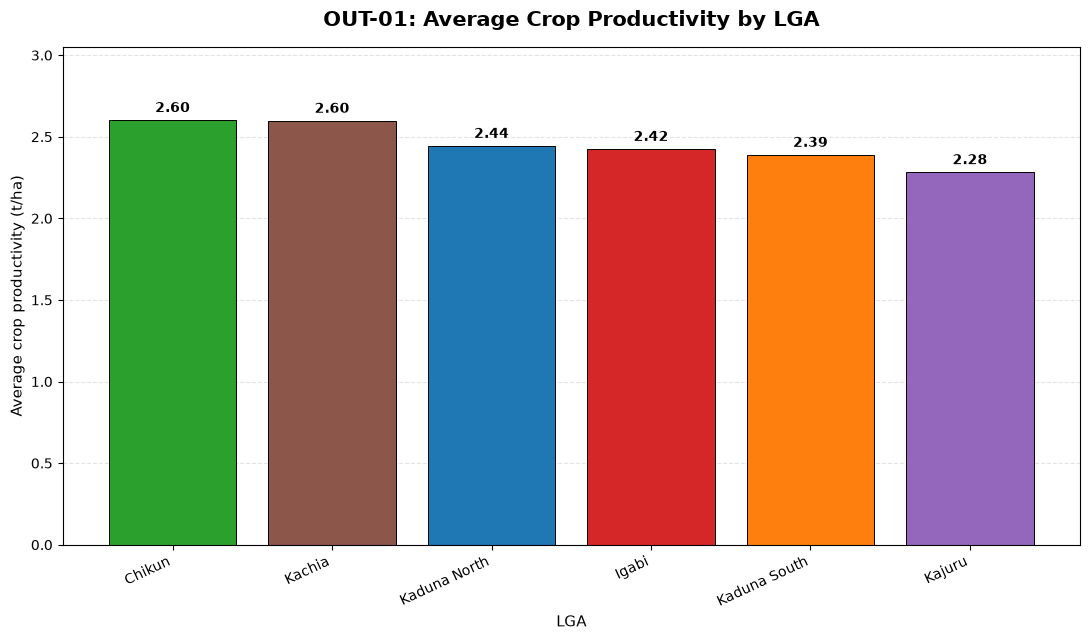

In [61]:
# 10.23.5.2 Visualization - OUT-01 Average Crop Productivity by LGA

import matplotlib.pyplot as plt

chart_data = productivity_by_lga.copy()

# Apply the established project-wide LGA colors
colors = [lga_colors[lga] for lga in chart_data["LGA"]]

fig, ax = plt.subplots(figsize=(11, 6.5))

bars = ax.bar(
    chart_data["LGA"],
    chart_data["Baseline Value"],
    color=colors,
    edgecolor="black",
    linewidth=0.7
)

# Add value labels
for bar, value in zip(bars, chart_data["Baseline Value"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.03,
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "OUT-01: Average Crop Productivity by LGA",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("LGA", fontsize=11)
ax.set_ylabel("Average crop productivity (t/ha)", fontsize=11)

ax.set_ylim(0, max(chart_data["Baseline Value"]) + 0.45)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

ax.set_axisbelow(True)

plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

In [62]:
# 10.23.6 LGA Comparison - OUT-02 Adoption of At Least 3 Practices

adoption_by_lga = (
    lga_indicator_table.loc[
        lga_indicator_table["Indicator ID"].eq("OUT-02"),
        ["LGA", "Baseline Value", "Numerator", "Denominator"]
    ]
    .dropna(subset=["Baseline Value"])
    .sort_values("Baseline Value", ascending=False)
    .reset_index(drop=True)
)

print("OUT-02: FARMERS ADOPTING AT LEAST 3 RECOMMENDED PRACTICES BY LGA")
print("=" * 90)

display(adoption_by_lga)

print("\nSummary")
print("-" * 90)

print(f"Highest LGA: {adoption_by_lga.iloc[0]['LGA']}")
print(
    f"Highest adoption rate: "
    f"{adoption_by_lga.iloc[0]['Baseline Value']:.2f}%"
)

print(f"Lowest LGA: {adoption_by_lga.iloc[-1]['LGA']}")
print(
    f"Lowest adoption rate: "
    f"{adoption_by_lga.iloc[-1]['Baseline Value']:.2f}%"
)

print(
    f"Range: "
    f"{adoption_by_lga['Baseline Value'].max() - adoption_by_lga['Baseline Value'].min():.2f} percentage points"
)

print(
    "\nNote: Zaria is excluded because there are no farmer respondents "
    "in the baseline sample."
)

OUT-02: FARMERS ADOPTING AT LEAST 3 RECOMMENDED PRACTICES BY LGA


,LGA,Baseline Value,Numerator,Denominator
0,Kajuru,72.000000,180,250
1,Igabi,71.333333,214,300
2,Kaduna North,67.666667,203,300
3,Chikun,66.571429,233,350
4,Kachia,65.000000,65,100
5,Kaduna South,63.333333,190,300



Summary
------------------------------------------------------------------------------------------
Highest LGA: Kajuru
Highest adoption rate: 72.00%
Lowest LGA: Kaduna South
Lowest adoption rate: 63.33%
Range: 8.67 percentage points

Note: Zaria is excluded because there are no farmer respondents in the baseline sample.


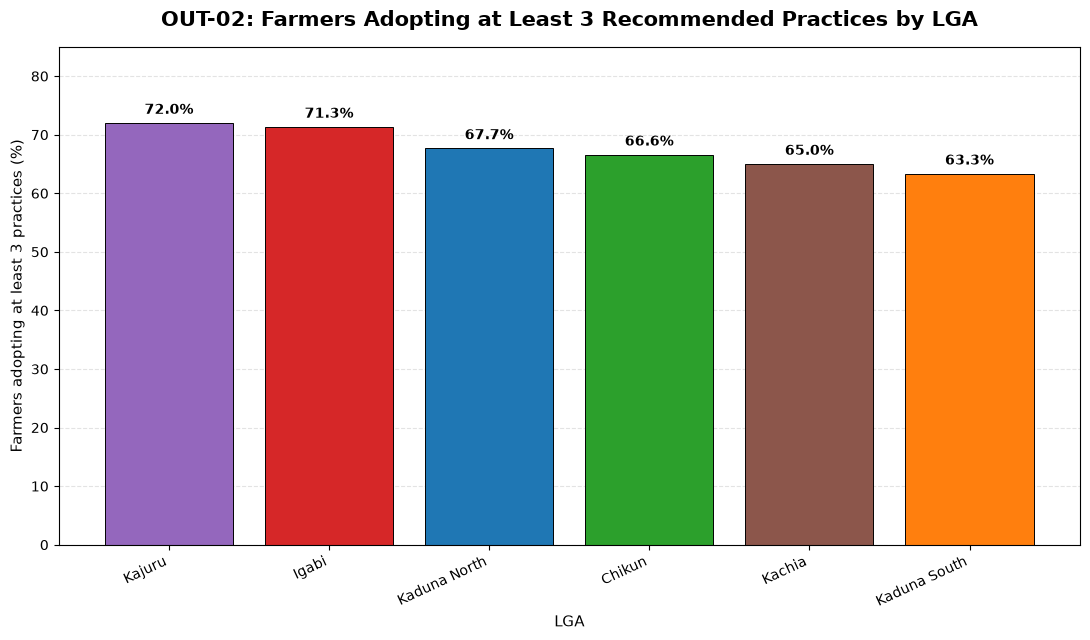

In [63]:
# 10.23.6.1 Visualization - OUT-02 Adoption of At Least 3 Practices by LGA

chart_data = adoption_by_lga.copy()

# Use the established project-wide LGA color mapping
colors = [lga_colors[lga] for lga in chart_data["LGA"]]

fig, ax = plt.subplots(figsize=(11, 6.5))

bars = ax.bar(
    chart_data["LGA"],
    chart_data["Baseline Value"],
    color=colors,
    edgecolor="black",
    linewidth=0.7
)

# Add percentage labels
for bar, value in zip(bars, chart_data["Baseline Value"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.0,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "OUT-02: Farmers Adopting at Least 3 Recommended Practices by LGA",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("LGA", fontsize=11)
ax.set_ylabel("Farmers adopting at least 3 practices (%)", fontsize=11)

ax.set_ylim(0, 85)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

ax.set_axisbelow(True)

plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

In [64]:
# 10.23.7 LGA Comparison - OUT-04 Farmers Selling Through Structured Markets

structured_market_by_lga = (
    lga_indicator_table.loc[
        lga_indicator_table["Indicator ID"].eq("OUT-04"),
        ["LGA", "Baseline Value", "Numerator", "Denominator"]
    ]
    .dropna(subset=["Baseline Value"])
    .sort_values("Baseline Value", ascending=False)
    .reset_index(drop=True)
)

print("OUT-04: FARMERS SELLING THROUGH STRUCTURED MARKETS BY LGA")
print("=" * 90)

display(structured_market_by_lga)

print("\nSummary")
print("-" * 90)

print(f"Highest LGA: {structured_market_by_lga.iloc[0]['LGA']}")
print(
    f"Highest structured-market participation: "
    f"{structured_market_by_lga.iloc[0]['Baseline Value']:.2f}%"
)

print(f"Lowest LGA: {structured_market_by_lga.iloc[-1]['LGA']}")
print(
    f"Lowest structured-market participation: "
    f"{structured_market_by_lga.iloc[-1]['Baseline Value']:.2f}%"
)

print(
    f"Range: "
    f"{structured_market_by_lga['Baseline Value'].max() - structured_market_by_lga['Baseline Value'].min():.2f} percentage points"
)

print(
    "\nNote: Zaria is excluded because there are no farmer respondents "
    "in the baseline sample."
)

OUT-04: FARMERS SELLING THROUGH STRUCTURED MARKETS BY LGA


,LGA,Baseline Value,Numerator,Denominator
0,Kaduna North,31.000000,93,300
1,Chikun,27.714286,97,350
2,Kajuru,27.600000,69,250
3,Kachia,27.000000,27,100
4,Kaduna South,25.333333,76,300
5,Igabi,25.000000,75,300



Summary
------------------------------------------------------------------------------------------
Highest LGA: Kaduna North
Highest structured-market participation: 31.00%
Lowest LGA: Igabi
Lowest structured-market participation: 25.00%
Range: 6.00 percentage points

Note: Zaria is excluded because there are no farmer respondents in the baseline sample.


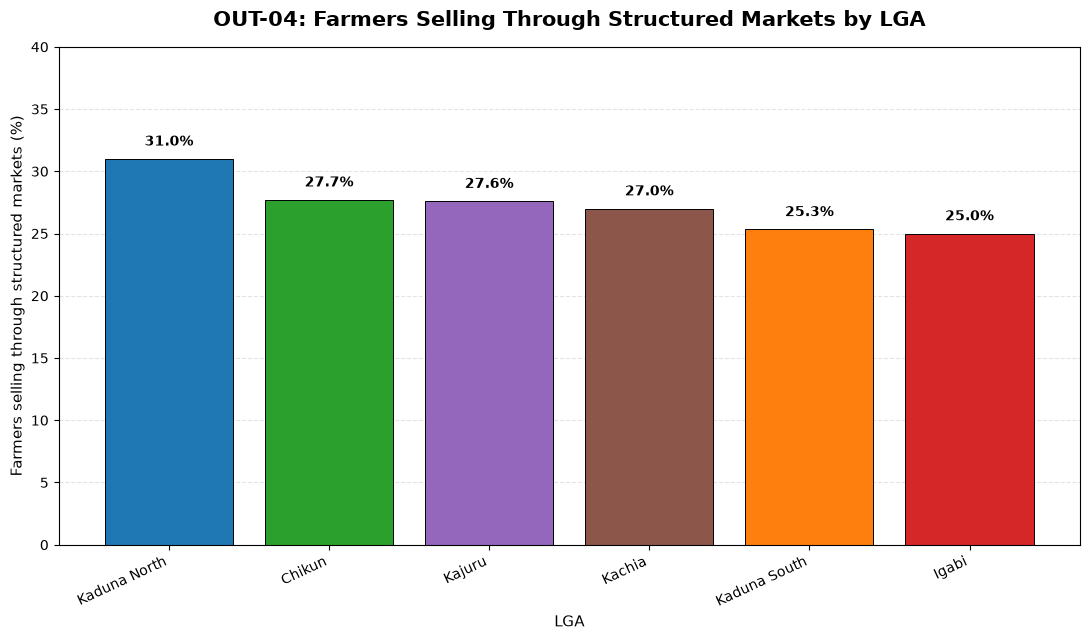

In [65]:
# 10.23.7.1 Visualization - OUT-04 Structured-Market Participation by LGA

chart_data = structured_market_by_lga.copy()

# Use the established project-wide LGA color mapping
colors = [lga_colors[lga] for lga in chart_data["LGA"]]

fig, ax = plt.subplots(figsize=(11, 6.5))

bars = ax.bar(
    chart_data["LGA"],
    chart_data["Baseline Value"],
    color=colors,
    edgecolor="black",
    linewidth=0.7
)

# Add percentage labels
for bar, value in zip(bars, chart_data["Baseline Value"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "OUT-04: Farmers Selling Through Structured Markets by LGA",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("LGA", fontsize=11)
ax.set_ylabel("Farmers selling through structured markets (%)", fontsize=11)

ax.set_ylim(0, 40)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

ax.set_axisbelow(True)

plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

In [67]:
# Diagnose LGA indicator table columns

print("Columns in lga_indicator_table:")
print(lga_indicator_table.columns.tolist())

print("\nFirst 5 rows:")
display(lga_indicator_table.head())

Columns in lga_indicator_table:
['LGA', 'Indicator ID', 'Indicator', 'Baseline Value', 'Unit', 'Numerator', 'Denominator']

First 5 rows:


,LGA,Indicator ID,Indicator,Baseline Value,Unit,Numerator,Denominator
0,Chikun,IMP-01,Average annual beneficiary income,1.615888e+06,NGN/year,348,350
1,Igabi,IMP-01,Average annual beneficiary income,1.680687e+06,NGN/year,298,300
2,Kachia,IMP-01,Average annual beneficiary income,1.231803e+06,NGN/year,248,250
3,Kaduna North,IMP-01,Average annual beneficiary income,1.637572e+06,NGN/year,297,300
4,Kaduna South,IMP-01,Average annual beneficiary income,1.656142e+06,NGN/year,298,300


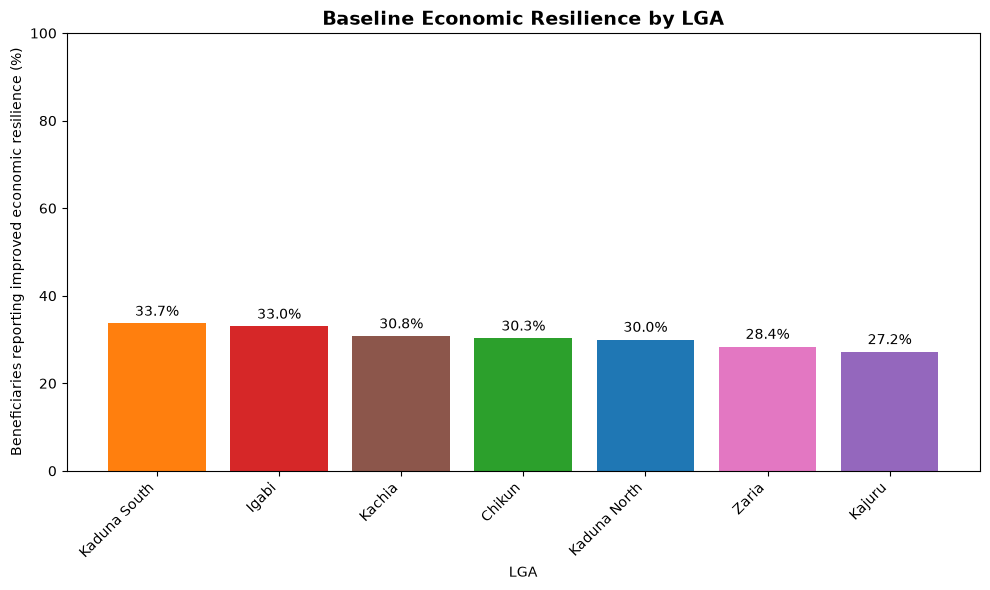

In [68]:
# 10.25 Visualization - IMP-02 Economic Resilience by LGA

import matplotlib.pyplot as plt

resilience_chart = (
    lga_indicator_table[
        lga_indicator_table["Indicator ID"] == "IMP-02"
    ][["LGA", "Baseline Value"]]
    .dropna()
    .copy()
    .sort_values("Baseline Value", ascending=False)
)

plt.figure(figsize=(10, 6))

colors = [lga_colors[lga] for lga in resilience_chart["LGA"]]

bars = plt.bar(
    resilience_chart["LGA"],
    resilience_chart["Baseline Value"],
    color=colors
)

plt.title(
    "Baseline Economic Resilience by LGA",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("LGA")
plt.ylabel("Beneficiaries reporting improved economic resilience (%)")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 100)

for bar, value in zip(bars, resilience_chart["Baseline Value"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

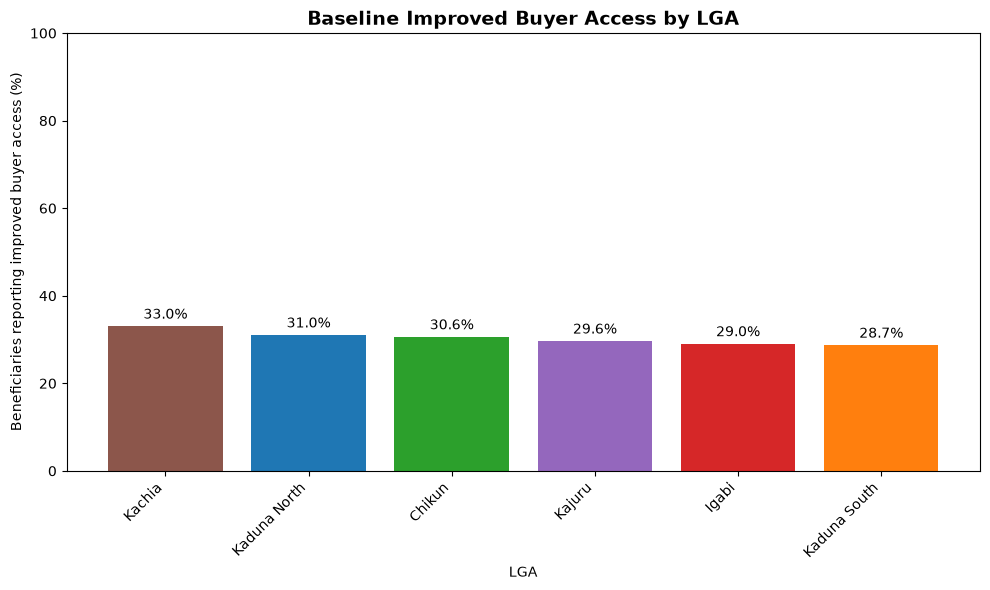

In [69]:
# 10.26 Visualization - OUT-05 Improved Buyer Access by LGA

import matplotlib.pyplot as plt

buyer_access_chart = (
    lga_indicator_table[
        lga_indicator_table["Indicator ID"] == "OUT-05"
    ][["LGA", "Baseline Value"]]
    .dropna()
    .copy()
    .sort_values("Baseline Value", ascending=False)
)

plt.figure(figsize=(10, 6))

colors = [lga_colors[lga] for lga in buyer_access_chart["LGA"]]

bars = plt.bar(
    buyer_access_chart["LGA"],
    buyer_access_chart["Baseline Value"],
    color=colors
)

plt.title(
    "Baseline Improved Buyer Access by LGA",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("LGA")
plt.ylabel("Beneficiaries reporting improved buyer access (%)")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 100)

for bar, value in zip(
    bars,
    buyer_access_chart["Baseline Value"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

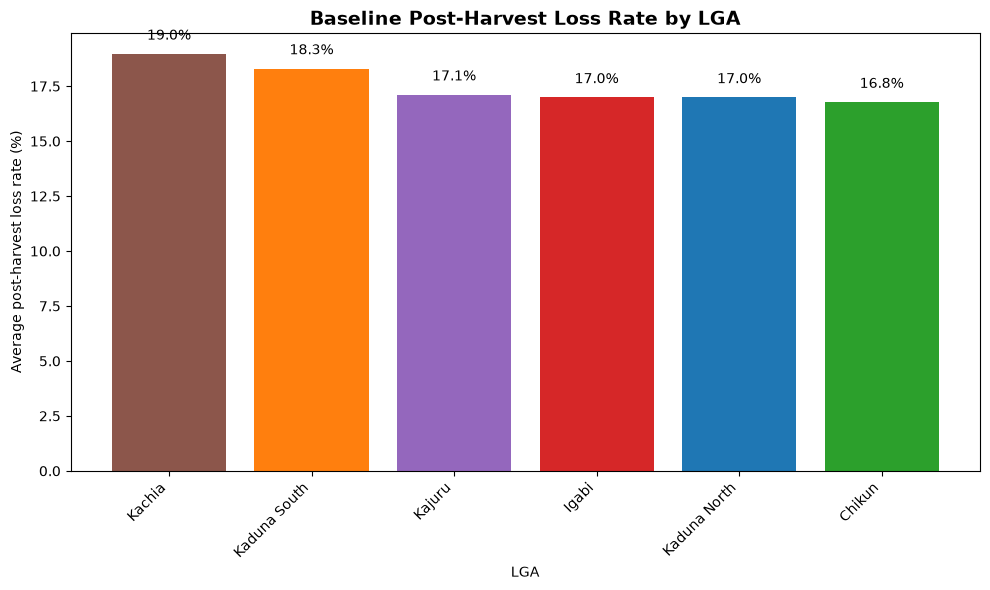

In [70]:
# 10.27 Visualization - OUT-06 Post-Harvest Loss Rate by LGA

import matplotlib.pyplot as plt

loss_chart = (
    lga_indicator_table[
        lga_indicator_table["Indicator ID"] == "OUT-06"
    ][["LGA", "Baseline Value"]]
    .dropna()
    .copy()
    .sort_values("Baseline Value", ascending=False)
)

plt.figure(figsize=(10, 6))

colors = [lga_colors[lga] for lga in loss_chart["LGA"]]

bars = plt.bar(
    loss_chart["LGA"],
    loss_chart["Baseline Value"],
    color=colors
)

plt.title(
    "Baseline Post-Harvest Loss Rate by LGA",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("LGA")
plt.ylabel("Average post-harvest loss rate (%)")
plt.xticks(rotation=45, ha="right")

for bar, value in zip(
    bars,
    loss_chart["Baseline Value"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

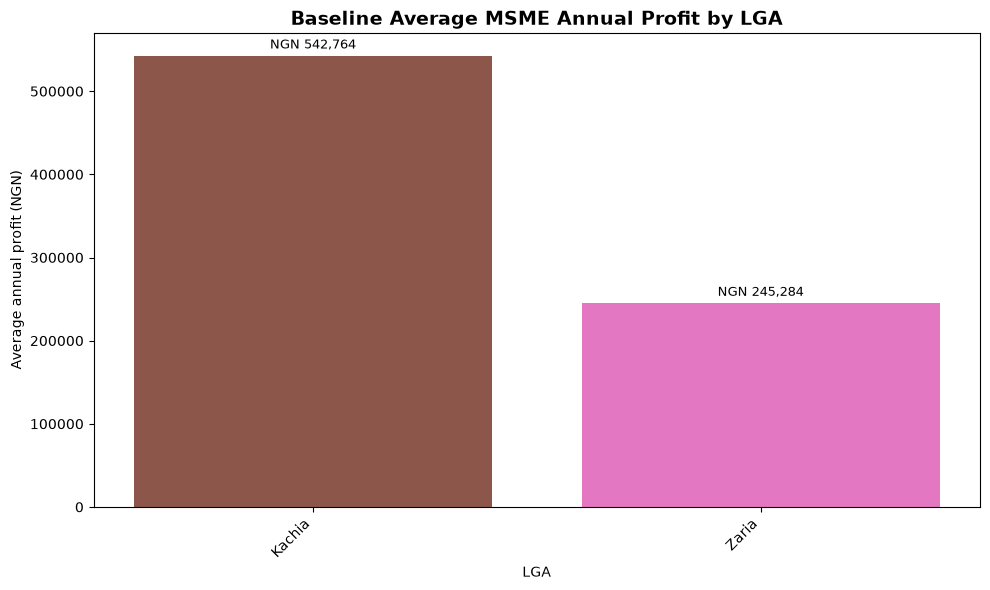

In [73]:
# 10.28 Visualization - OUT-08 Average MSME Annual Profit by LGA

import matplotlib.pyplot as plt

profit_chart = (
    lga_indicator_table[
        lga_indicator_table["Indicator ID"] == "OUT-08"
    ][["LGA", "Baseline Value"]]
    .dropna()
    .copy()
    .sort_values("Baseline Value", ascending=False)
)

plt.figure(figsize=(10, 6))

colors = [lga_colors[lga] for lga in profit_chart["LGA"]]

bars = plt.bar(
    profit_chart["LGA"],
    profit_chart["Baseline Value"],
    color=colors
)

plt.title(
    "Baseline Average MSME Annual Profit by LGA",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("LGA")
plt.ylabel("Average annual profit (NGN)")
plt.xticks(rotation=45, ha="right")

for bar, value in zip(
    bars,
    profit_chart["Baseline Value"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5000,
        f"NGN {value:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

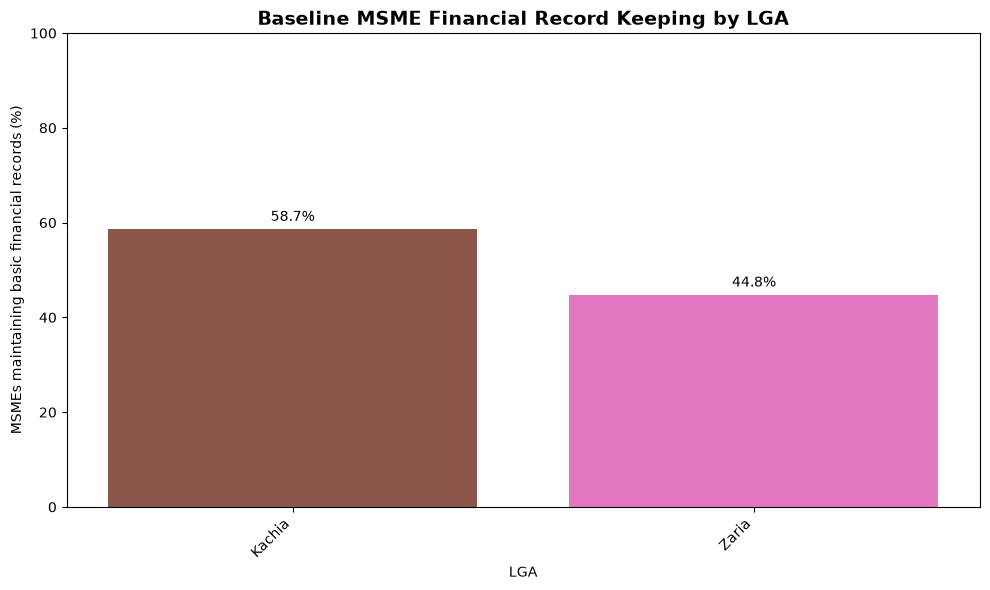

In [74]:
# 10.29 Visualization - OUT-09 Financial Record Keeping by LGA

import matplotlib.pyplot as plt

financial_records_chart = (
    lga_indicator_table[
        lga_indicator_table["Indicator ID"] == "OUT-09"
    ][["LGA", "Baseline Value"]]
    .dropna()
    .copy()
    .sort_values("Baseline Value", ascending=False)
)

plt.figure(figsize=(10, 6))

colors = [
    lga_colors[lga]
    for lga in financial_records_chart["LGA"]
]

bars = plt.bar(
    financial_records_chart["LGA"],
    financial_records_chart["Baseline Value"],
    color=colors
)

plt.title(
    "Baseline MSME Financial Record Keeping by LGA",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("LGA")
plt.ylabel("MSMEs maintaining basic financial records (%)")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 100)

for bar, value in zip(
    bars,
    financial_records_chart["Baseline Value"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

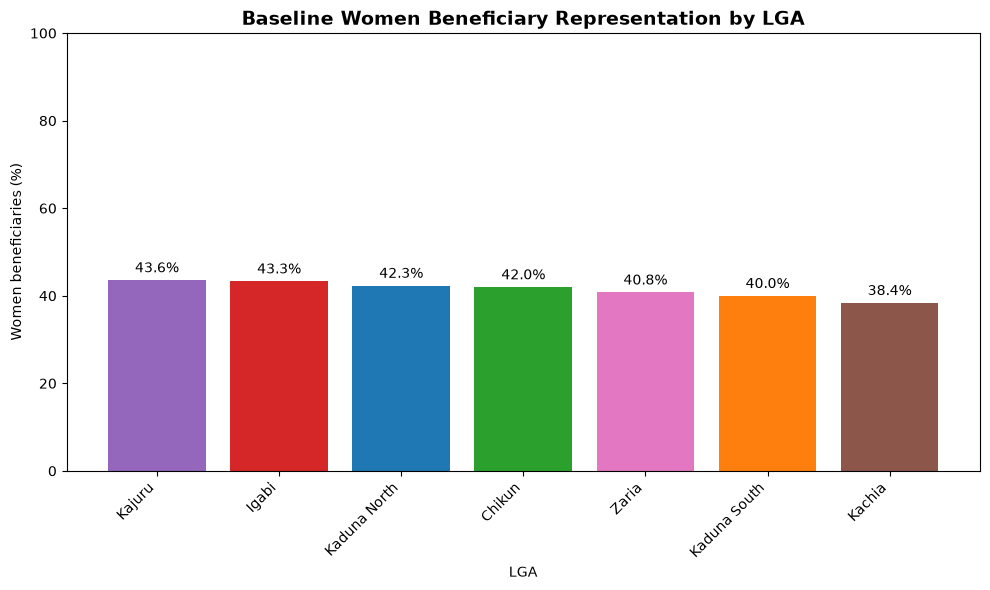

In [75]:
# 10.30 Visualization - OUT-10 Women Beneficiaries by LGA

import matplotlib.pyplot as plt

women_chart = (
    lga_indicator_table[
        lga_indicator_table["Indicator ID"] == "OUT-10"
    ][["LGA", "Baseline Value"]]
    .dropna()
    .copy()
    .sort_values("Baseline Value", ascending=False)
)

plt.figure(figsize=(10, 6))

colors = [
    lga_colors[lga]
    for lga in women_chart["LGA"]
]

bars = plt.bar(
    women_chart["LGA"],
    women_chart["Baseline Value"],
    color=colors
)

plt.title(
    "Baseline Women Beneficiary Representation by LGA",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("LGA")
plt.ylabel("Women beneficiaries (%)")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 100)

for bar, value in zip(
    bars,
    women_chart["Baseline Value"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

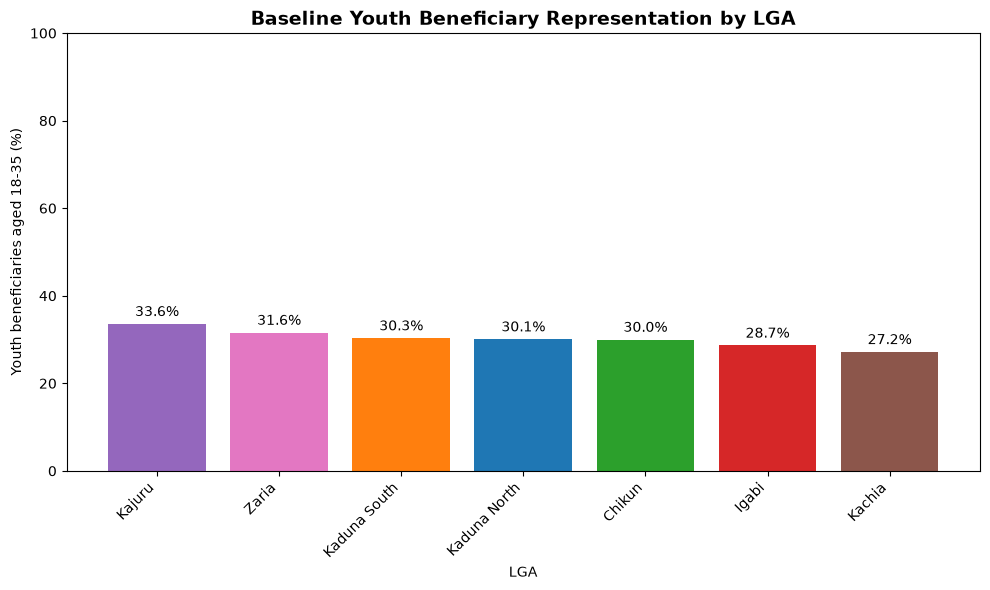

In [76]:
# 10.31 Visualization - OUT-11 Youth Beneficiaries by LGA

import matplotlib.pyplot as plt

youth_chart = (
    lga_indicator_table[
        lga_indicator_table["Indicator ID"] == "OUT-11"
    ][["LGA", "Baseline Value"]]
    .dropna()
    .copy()
    .sort_values("Baseline Value", ascending=False)
)

plt.figure(figsize=(10, 6))

colors = [
    lga_colors[lga]
    for lga in youth_chart["LGA"]
]

bars = plt.bar(
    youth_chart["LGA"],
    youth_chart["Baseline Value"],
    color=colors
)

plt.title(
    "Baseline Youth Beneficiary Representation by LGA",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("LGA")
plt.ylabel("Youth beneficiaries aged 18-35 (%)")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 100)

for bar, value in zip(
    bars,
    youth_chart["Baseline Value"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

## 11.01 Geospatial Data Preparation

The project will use an administrative boundary dataset to visualize the geographic distribution of the synthetic baseline results across the seven project LGAs.

The boundary data will provide geographic context only. Baseline observations and indicator values remain synthetic and do not represent actual Kaduna State field data.

In [77]:
# 11.01 Geospatial Data Preparation - Load and Inspect LGA Boundaries

import geopandas as gpd
from pathlib import Path

GEODATA = PROJECT_ROOT / "08_Analysis" / "geodata" / "Nigeria_ADM2.geojson"

nigeria_lga = gpd.read_file(GEODATA)

print("GEOSPATIAL DATASET OVERVIEW")
print("=" * 80)

print(f"Rows: {len(nigeria_lga):,}")
print(f"Columns: {len(nigeria_lga.columns)}")
print(f"CRS: {nigeria_lga.crs}")

print("\nColumns:")
print(nigeria_lga.columns.tolist())

print("\nGeometry types:")
print(nigeria_lga.geometry.geom_type.value_counts())

print("\nFirst five records:")
display(nigeria_lga.head())

GEOSPATIAL DATASET OVERVIEW
Rows: 774
Columns: 6
CRS: EPSG:4326

Columns:
['shapeName', 'shapeISO', 'shapeID', 'shapeGroup', 'shapeType', 'geometry']

Geometry types:
Polygon         749
MultiPolygon     25
Name: count, dtype: int64

First five records:


,shapeName,shapeISO,shapeID,shapeGroup,shapeType,geometry
0,Eastern Obolo,,59680162B7891718144591,NGA,ADM2,"POLYGON ((7.56201 4.51388, 7.57134 4.51233, 7...."
1,Ekeremor,,59680162B22876202690460,NGA,ADM2,"POLYGON ((5.99261 4.89302, 5.98824 4.90425, 5...."
2,Degema,,59680162B23543460253472,NGA,ADM2,"POLYGON ((6.85818 4.39824, 6.95485 4.37353, 6...."
3,Andoni,,59680162B90577513466378,NGA,ADM2,"POLYGON ((7.3246 4.43947, 7.33342 4.44372, 7.3..."
4,Akpabuyo,,59680162B58958286313368,NGA,ADM2,"POLYGON ((8.39659 4.78065, 8.40093 4.78882, 8...."


In [78]:
# 11.02 Verify Kaduna LGA Boundary Coverage

print("KADUNA LGA BOUNDARY VERIFICATION")
print("=" * 80)

# Inspect likely state/LGA name fields
for column in nigeria_lga.columns:
    if nigeria_lga[column].dtype == "object":
        sample_values = nigeria_lga[column].dropna().astype(str).head(10).tolist()
        print(f"\n{column}:")
        print(sample_values)

KADUNA LGA BOUNDARY VERIFICATION


In [79]:
# 11.02 Verify Kaduna LGA Boundary Coverage

print("KADUNA LGA BOUNDARY VERIFICATION")
print("=" * 80)

for column in nigeria_lga.columns:
    if nigeria_lga[column].dtype == "object":
        sample_values = (
            nigeria_lga[column]
            .dropna()
            .astype(str)
            .head(10)
            .tolist()
        )
        print(f"\n{column}:")
        print(sample_values)

KADUNA LGA BOUNDARY VERIFICATION


In [80]:
# 11.02a Inspect Boundary Dataset Column Types

print("BOUNDARY DATASET COLUMN TYPES")
print("=" * 80)

print(nigeria_lga.dtypes)

BOUNDARY DATASET COLUMN TYPES
shapeName          str
shapeISO           str
shapeID            str
shapeGroup         str
shapeType          str
geometry      geometry
dtype: object


In [81]:
# 11.02 Verify Seven Project LGA Boundaries

project_lgas = [
    "Kaduna North",
    "Kaduna South",
    "Chikun",
    "Igabi",
    "Kajuru",
    "Kachia",
    "Zaria",
]

available_lgas = set(
    nigeria_lga["shapeName"]
    .dropna()
    .astype(str)
)

print("PROJECT LGA BOUNDARY VERIFICATION")
print("=" * 80)

for lga in project_lgas:
    status = "FOUND" if lga in available_lgas else "NOT FOUND"
    print(f"{lga:<20} {status}")

missing_lgas = [
    lga for lga in project_lgas
    if lga not in available_lgas
]

print("\nSummary")
print("-" * 80)
print(f"Project LGAs required: {len(project_lgas)}")
print(f"Project LGAs found:    {len(project_lgas) - len(missing_lgas)}")
print(f"Missing LGAs:          {missing_lgas}")

PROJECT LGA BOUNDARY VERIFICATION
Kaduna North         FOUND
Kaduna South         FOUND
Chikun               FOUND
Igabi                FOUND
Kajuru               FOUND
Kachia               FOUND
Zaria                FOUND

Summary
--------------------------------------------------------------------------------
Project LGAs required: 7
Project LGAs found:    7
Missing LGAs:          []


In [82]:
# 11.03 Extract Project LGA Boundaries

project_lga_boundaries = (
    nigeria_lga[
        nigeria_lga["shapeName"].isin(project_lgas)
    ][
        ["shapeName", "shapeISO", "shapeID", "shapeGroup", "shapeType", "geometry"]
    ]
    .copy()
    .sort_values("shapeName")
    .reset_index(drop=True)
)

print("PROJECT LGA BOUNDARIES")
print("=" * 80)

print(f"Number of project LGAs: {len(project_lga_boundaries)}")

display(
    project_lga_boundaries[
        ["shapeName", "shapeISO", "shapeID", "shapeGroup", "shapeType"]
    ]
)

PROJECT LGA BOUNDARIES
Number of project LGAs: 7


,shapeName,shapeISO,shapeID,shapeGroup,shapeType
0,Chikun,,59680162B24550873512487,NGA,ADM2
1,Igabi,,59680162B83099166959131,NGA,ADM2
2,Kachia,,59680162B32850327292174,NGA,ADM2
3,Kaduna North,,59680162B72659245241320,NGA,ADM2
4,Kaduna South,,59680162B16574916896740,NGA,ADM2
5,Kajuru,,59680162B79502957035648,NGA,ADM2
6,Zaria,,59680162B50201894093674,NGA,ADM2


In [83]:
# 11.04 Verify Extracted Project Boundaries

print("EXTRACTED PROJECT BOUNDARY VERIFICATION")
print("=" * 80)

print("LGA names:")
print(project_lga_boundaries["shapeName"].tolist())

print("\nGeometry types:")
print(
    project_lga_boundaries.geometry.geom_type.value_counts()
)

print("\nMissing geometries:")
print(
    project_lga_boundaries.geometry.isna().sum()
)

print("\nEmpty geometries:")
print(
    project_lga_boundaries.geometry.is_empty.sum()
)

print("\nCRS:")
print(project_lga_boundaries.crs)

print("\nExpected LGA count:", len(project_lgas))
print("Extracted LGA count:", len(project_lga_boundaries))

verification_pass = (
    len(project_lga_boundaries) == len(project_lgas)
    and project_lga_boundaries["shapeName"].nunique() == len(project_lgas)
    and project_lga_boundaries.geometry.notna().all()
    and (~project_lga_boundaries.geometry.is_empty).all()
)

print("\nVerification status:", "PASS" if verification_pass else "FAIL")

EXTRACTED PROJECT BOUNDARY VERIFICATION
LGA names:
['Chikun', 'Igabi', 'Kachia', 'Kaduna North', 'Kaduna South', 'Kajuru', 'Zaria']

Geometry types:
Polygon    7
Name: count, dtype: int64

Missing geometries:
0

Empty geometries:
0

CRS:
EPSG:4326

Expected LGA count: 7
Extracted LGA count: 7

Verification status: PASS


In [84]:
# 11.05 Save Verified Project LGA Boundaries

PROJECT_BOUNDARIES = (
    PROJECT_ROOT
    / "08_Analysis"
    / "geodata"
    / "ALMDP_Project_LGAs.geojson"
)

project_lga_boundaries.to_file(
    PROJECT_BOUNDARIES,
    driver="GeoJSON"
)

print("PROJECT LGA BOUNDARY EXPORT")
print("=" * 80)

print(f"Saved to: {PROJECT_BOUNDARIES}")
print(f"File exists: {PROJECT_BOUNDARIES.exists()}")

if PROJECT_BOUNDARIES.exists():
    print(f"File size: {PROJECT_BOUNDARIES.stat().st_size:,} bytes")

PROJECT LGA BOUNDARY EXPORT
Saved to: c:\Users\HP 15\Documents\ALMDP_Kaduna_ME_Portfolio\08_Analysis\geodata\ALMDP_Project_LGAs.geojson
File exists: True
File size: 134,976 bytes


In [85]:
# 11.06 Verify Saved Project Boundary Layer

saved_boundaries = gpd.read_file(PROJECT_BOUNDARIES)

print("SAVED PROJECT BOUNDARY VERIFICATION")
print("=" * 80)

print(f"Rows: {len(saved_boundaries)}")
print(f"CRS: {saved_boundaries.crs}")

print("\nGeometry types:")
print(saved_boundaries.geometry.geom_type.value_counts())

print("\nLGA names:")
print(saved_boundaries["shapeName"].tolist())

print("\nMissing geometries:")
print(saved_boundaries.geometry.isna().sum())

print("\nEmpty geometries:")
print(saved_boundaries.geometry.is_empty.sum())

export_pass = (
    len(saved_boundaries) == 7
    and saved_boundaries["shapeName"].nunique() == 7
    and saved_boundaries.geometry.notna().all()
    and (~saved_boundaries.geometry.is_empty).all()
)

print("\nExport verification:", "PASS" if export_pass else "FAIL")

SAVED PROJECT BOUNDARY VERIFICATION
Rows: 7
CRS: EPSG:4326

Geometry types:
Polygon    7
Name: count, dtype: int64

LGA names:
['Chikun', 'Igabi', 'Kachia', 'Kaduna North', 'Kaduna South', 'Kajuru', 'Zaria']

Missing geometries:
0

Empty geometries:
0

Export verification: PASS


## 11.07 ALMDP Project Geographic Coverage Map

The map below presents the geographic coverage of the synthetic ALMDP portfolio project across the seven selected LGAs in Kaduna State.

The administrative boundaries provide geographic context only. All beneficiary distributions and monitoring indicators used in subsequent maps will be based on synthetic baseline data and do not represent actual field observations from Kaduna State.

In [86]:
# 11.07 Create ALMDP Project Coverage Map

import folium

# Calculate geographic center of the project LGAs
project_center = project_lga_boundaries.geometry.union_all().centroid

project_map = folium.Map(
    location=[
        project_center.y,
        project_center.x
    ],
    zoom_start=9,
    tiles="CartoDB positron"
)

# Add project LGA boundaries
folium.GeoJson(
    project_lga_boundaries,
    name="ALMDP Project LGAs",
    style_function=lambda feature: {
        "fillColor": "#3186cc",
        "color": "#1f4e79",
        "weight": 2,
        "fillOpacity": 0.35
    },
    highlight_function=lambda feature: {
        "weight": 4,
        "fillOpacity": 0.55
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["shapeName"],
        aliases=["LGA:"],
        localize=True,
        sticky=False
    )
).add_to(project_map)

# Add LGA labels at representative points
for _, row in project_lga_boundaries.iterrows():

    point = row.geometry.representative_point()

    folium.Marker(
        location=[point.y, point.x],
        icon=folium.DivIcon(
            html=f"""
            <div style="
                font-size: 11px;
                font-weight: bold;
                color: #1f1f1f;
                text-align: center;
                white-space: nowrap;
            ">
                {row['shapeName']}
            </div>
            """
        )
    ).add_to(project_map)

# Add layer control
folium.LayerControl().add_to(project_map)

project_map

c:\Users\HP 15\Documents\ALMDP_Kaduna_ME_Portfolio\.venv\Lib\site-packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


In [87]:
# 11.07 Create ALMDP Project Coverage Map - Distinct LGA Colors

import folium

# Distinct colors for each project LGA
lga_map_colors = {
    "Chikun": "#1f77b4",
    "Igabi": "#ff7f0e",
    "Kachia": "#2ca02c",
    "Kaduna North": "#d62728",
    "Kaduna South": "#9467bd",
    "Kajuru": "#8c564b",
    "Zaria": "#e377c2",
}

# Verify every project LGA has a map color
missing_colors = set(project_lga_boundaries["shapeName"]) - set(lga_map_colors)

print("LGA COLOR VERIFICATION")
print("=" * 80)
print("Missing colors:", missing_colors)

# Calculate geographic center
project_center = project_lga_boundaries.geometry.union_all().centroid

# Create map
project_map = folium.Map(
    location=[
        project_center.y,
        project_center.x
    ],
    zoom_start=9,
    tiles="CartoDB positron"
)

# Add each LGA separately so each can have its own color
for _, row in project_lga_boundaries.iterrows():

    lga_name = row["shapeName"]
    lga_color = lga_map_colors[lga_name]

    lga_layer = gpd.GeoDataFrame(
        [row],
        crs=project_lga_boundaries.crs
    )

    folium.GeoJson(
        lga_layer,
        name=lga_name,
        style_function=lambda feature, color=lga_color: {
            "fillColor": color,
            "color": color,
            "weight": 2,
            "fillOpacity": 0.45
        },
        highlight_function=lambda feature, color=lga_color: {
            "fillColor": color,
            "color": "#000000",
            "weight": 4,
            "fillOpacity": 0.65
        },
        tooltip=folium.GeoJsonTooltip(
            fields=["shapeName"],
            aliases=["LGA:"],
            localize=True,
            sticky=False
        )
    ).add_to(project_map)

    # Add LGA label
    point = row.geometry.representative_point()

    folium.Marker(
        location=[point.y, point.x],
        icon=folium.DivIcon(
            html=f"""
            <div style="
                font-size: 11px;
                font-weight: bold;
                color: #1f1f1f;
                text-align: center;
                white-space: nowrap;
                text-shadow:
                    1px 1px 2px white,
                    -1px -1px 2px white,
                    1px -1px 2px white,
                    -1px 1px 2px white;
            ">
                {lga_name}
            </div>
            """
        )
    ).add_to(project_map)

# Add layer control
folium.LayerControl().add_to(project_map)

project_map

LGA COLOR VERIFICATION
Missing colors: set()


c:\Users\HP 15\Documents\ALMDP_Kaduna_ME_Portfolio\.venv\Lib\site-packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


In [88]:
project_map = folium.Map(
    location=[
        project_center.y,
        project_center.x
    ],
    zoom_start=9,
    tiles=None
)

# Public OpenStreetMap basemap
folium.TileLayer(
    tiles="OpenStreetMap",
    name="OpenStreetMap",
    control=True
).add_to(project_map)

In [89]:
# 11.08 Save ALMDP Project Coverage Map

MAP_OUTPUT = (
    PROJECT_ROOT
    / "08_Analysis"
    / "maps"
    / "ALMDP_Project_Coverage_Map.html"
)

project_map.save(MAP_OUTPUT)

print("PROJECT COVERAGE MAP EXPORT")
print("=" * 80)

print(f"Saved to: {MAP_OUTPUT}")
print(f"File exists: {MAP_OUTPUT.exists()}")

if MAP_OUTPUT.exists():
    print(f"File size: {MAP_OUTPUT.stat().st_size:,} bytes")

PROJECT COVERAGE MAP EXPORT
Saved to: c:\Users\HP 15\Documents\ALMDP_Kaduna_ME_Portfolio\08_Analysis\maps\ALMDP_Project_Coverage_Map.html
File exists: True
File size: 3,353 bytes


## 11.09 Beneficiary Distribution by LGA

The beneficiary distribution will be linked to the project LGA boundaries to visualize the geographic distribution of the synthetic baseline sample.

The mapped values represent the synthetic portfolio dataset only and should not be interpreted as actual beneficiary counts from Kaduna State.

In [90]:
# 11.09 Prepare Synthetic Beneficiary Distribution by LGA

beneficiary_lga = (
    df.groupby("lga")
    .agg(
        beneficiaries=("respondent_id", "count"),
        farmers=("beneficiary_type", lambda x: (x == 1).sum()),
        msmes=("beneficiary_type", lambda x: (x == 2).sum()),
        female_beneficiaries=("sex", lambda x: (x == 1).sum()),
        youth_beneficiaries=("youth_status", "sum")
    )
    .reset_index()
)

# Convert LGA codes to names
beneficiary_lga["LGA"] = beneficiary_lga["lga"].map(lga_labels)

beneficiary_lga = (
    beneficiary_lga[
        [
            "LGA",
            "beneficiaries",
            "farmers",
            "msmes",
            "female_beneficiaries",
            "youth_beneficiaries"
        ]
    ]
    .sort_values("LGA")
    .reset_index(drop=True)
)

print("SYNTHETIC BENEFICIARY DISTRIBUTION BY LGA")
print("=" * 80)

display(beneficiary_lga)

SYNTHETIC BENEFICIARY DISTRIBUTION BY LGA


,LGA,beneficiaries,farmers,msmes,female_beneficiaries,youth_beneficiaries
0,Chikun,350,350,0,147,105.0
1,Igabi,300,300,0,130,86.0
2,Kachia,250,100,150,96,68.0
3,Kaduna North,300,300,0,127,90.0
4,Kaduna South,300,300,0,120,91.0
5,Kajuru,250,250,0,109,84.0
6,Zaria,250,0,250,102,79.0


In [91]:
# 11.10 Beneficiary Distribution QA

print("BENEFICIARY DISTRIBUTION QA")
print("=" * 80)

total_beneficiaries = beneficiary_lga["beneficiaries"].sum()
total_farmers = beneficiary_lga["farmers"].sum()
total_msmes = beneficiary_lga["msmes"].sum()
total_female = beneficiary_lga["female_beneficiaries"].sum()
total_youth = beneficiary_lga["youth_beneficiaries"].sum()

print(f"Beneficiaries by LGA: {total_beneficiaries:,}")
print(f"Farmers by LGA:       {total_farmers:,}")
print(f"MSMEs by LGA:         {total_msmes:,}")
print(f"Female beneficiaries: {total_female:,}")
print(f"Youth beneficiaries:  {total_youth:,}")

print("\nExpected totals")
print("-" * 80)
print("Beneficiaries: 2,000")
print("Farmers:       1,600")
print("MSMEs:           400")
print("Female:          831")
print("Youth:           603")

beneficiary_qa_pass = (
    total_beneficiaries == 2000
    and total_farmers == 1600
    and total_msmes == 400
    and total_female == 831
    and total_youth == 603
    and len(beneficiary_lga) == 7
)

print(
    "\nBeneficiary distribution QA:",
    "PASS" if beneficiary_qa_pass else "FAIL"
)

BENEFICIARY DISTRIBUTION QA
Beneficiaries by LGA: 2,000
Farmers by LGA:       1,600
MSMEs by LGA:         400
Female beneficiaries: 831
Youth beneficiaries:  603.0

Expected totals
--------------------------------------------------------------------------------
Beneficiaries: 2,000
Farmers:       1,600
MSMEs:           400
Female:          831
Youth:           603

Beneficiary distribution QA: PASS


In [94]:
# 11.11 Corrected Join: Synthetic Beneficiary Data to LGA Boundaries

beneficiary_map_data = project_lga_boundaries.merge(
    beneficiary_lga,
    left_on="shapeName",
    right_on="LGA",
    how="left",
    validate="one_to_one"
)

print("BENEFICIARY MAP DATA QA")
print("=" * 80)

print("\nRows:", len(beneficiary_map_data))

print("\nLGA matching:")
display(
    beneficiary_map_data[
        [
            "shapeName",
            "beneficiaries",
            "farmers",
            "msmes",
            "female_beneficiaries",
            "youth_beneficiaries"
        ]
    ]
)

missing_beneficiaries = (
    beneficiary_map_data["beneficiaries"]
    .isna()
    .sum()
)

missing_lgas = set(project_lgas) - set(
    beneficiary_map_data["shapeName"]
)

print("\nMissing beneficiary values:", missing_beneficiaries)
print("Missing project LGAs:", missing_lgas)
print("Unique boundary LGAs:", beneficiary_map_data["shapeName"].nunique())

beneficiary_join_pass = (
    len(beneficiary_map_data) == 7
    and beneficiary_map_data["shapeName"].nunique() == 7
    and missing_beneficiaries == 0
    and len(missing_lgas) == 0
)

print(
    "\nBeneficiary geographic join:",
    "PASS" if beneficiary_join_pass else "FAIL"
)

BENEFICIARY MAP DATA QA

Rows: 7

LGA matching:


,shapeName,beneficiaries,farmers,msmes,female_beneficiaries,youth_beneficiaries
0,Chikun,350,350,0,147,105.0
1,Igabi,300,300,0,130,86.0
2,Kachia,250,100,150,96,68.0
3,Kaduna North,300,300,0,127,90.0
4,Kaduna South,300,300,0,120,91.0
5,Kajuru,250,250,0,109,84.0
6,Zaria,250,0,250,102,79.0



Missing beneficiary values: 0
Missing project LGAs: set()
Unique boundary LGAs: 7

Beneficiary geographic join: PASS


In [95]:
# 11.11 Final Geographic Join Verification

print("BENEFICIARY GEOGRAPHIC JOIN VERIFICATION")
print("=" * 80)

print("Boundary LGAs:", beneficiary_map_data["shapeName"].nunique())
print("Expected LGAs:", len(project_lgas))

print("Missing beneficiary values:",
      beneficiary_map_data["beneficiaries"].isna().sum())

print("Total mapped beneficiaries:",
      beneficiary_map_data["beneficiaries"].sum())

print(
    "\nVerification status:",
    "PASS"
    if (
        beneficiary_map_data["shapeName"].nunique() == 7
        and beneficiary_map_data["beneficiaries"].isna().sum() == 0
        and beneficiary_map_data["beneficiaries"].sum() == 2000
    )
    else "FAIL"
)

BENEFICIARY GEOGRAPHIC JOIN VERIFICATION
Boundary LGAs: 7
Expected LGAs: 7
Missing beneficiary values: 0
Total mapped beneficiaries: 2000

Verification status: PASS


In [96]:
# 11.12 Synthetic Beneficiary Distribution Map by LGA

import folium
from branca.element import Element

# Calculate map center
beneficiary_center = (
    beneficiary_map_data.geometry.union_all().centroid
)

# Create base map
beneficiary_map = folium.Map(
    location=[
        beneficiary_center.y,
        beneficiary_center.x
    ],
    zoom_start=9,
    tiles=None
)

# Add OpenStreetMap base layer
folium.TileLayer(
    tiles="OpenStreetMap",
    name="OpenStreetMap",
    control=True
).add_to(beneficiary_map)

# Add beneficiary geographic layer
folium.GeoJson(
    beneficiary_map_data,
    name="Synthetic Beneficiaries",
    style_function=lambda feature: {
        "fillColor": "#3182bd",
        "color": "black",
        "weight": 1.5,
        "fillOpacity": 0.60
    },
    highlight_function=lambda feature: {
        "weight": 3,
        "fillOpacity": 0.80
    },
    tooltip=folium.GeoJsonTooltip(
        fields=[
            "shapeName",
            "beneficiaries",
            "farmers",
            "msmes",
            "female_beneficiaries",
            "youth_beneficiaries"
        ],
        aliases=[
            "LGA",
            "Beneficiaries",
            "Farmers",
            "MSMEs",
            "Female beneficiaries",
            "Youth beneficiaries"
        ],
        localize=True,
        sticky=False,
        labels=True
    )
).add_to(beneficiary_map)

# Add LGA labels
for _, row in beneficiary_map_data.iterrows():

    representative_point = row.geometry.representative_point()

    folium.Marker(
        location=[
            representative_point.y,
            representative_point.x
        ],
        icon=folium.DivIcon(
            html=f"""
            <div style="
                font-size: 10px;
                font-weight: bold;
                color: black;
                text-align: center;
                white-space: nowrap;
                text-shadow: 1px 1px 2px white;
            ">
                {row["shapeName"]}
            </div>
            """
        )
    ).add_to(beneficiary_map)

# ---------------------------------------------------------
# Map title
# ---------------------------------------------------------

title_html = """
<div style="
    position: fixed;
    top: 10px;
    left: 50%;
    transform: translateX(-50%);
    z-index: 9999;
    background-color: white;
    padding: 10px 18px;
    border: 2px solid #444;
    border-radius: 5px;
    font-size: 16px;
    font-weight: bold;
    text-align: center;
">
    ALMDP Synthetic Beneficiary Distribution by LGA
</div>
"""

beneficiary_map.get_root().html.add_child(
    Element(title_html)
)

# ---------------------------------------------------------
# Legend
# ---------------------------------------------------------

legend_html = """
<div style="
    position: fixed;
    bottom: 35px;
    left: 35px;
    z-index: 9999;
    background-color: white;
    border: 2px solid #444;
    border-radius: 5px;
    padding: 10px 12px;
    font-size: 12px;
    line-height: 1.5;
">
    <b>Map Legend</b><br>

    <div style="margin-top:5px;">
        <span style="
            display:inline-block;
            width:18px;
            height:18px;
            background:#3182bd;
            border:1px solid black;
            margin-right:6px;
            vertical-align:middle;
        "></span>
        Project beneficiary LGA
    </div>

    <div style="
        margin-top:6px;
        font-size:10px;
        color:#555;
    ">
        Data: Synthetic baseline dataset
    </div>
</div>
"""

beneficiary_map.get_root().html.add_child(
    Element(legend_html)
)

# ---------------------------------------------------------
# North arrow
# ---------------------------------------------------------

north_arrow_html = """
<div style="
    position: fixed;
    top: 80px;
    right: 25px;
    z-index: 9999;
    background-color: white;
    border: 2px solid #444;
    border-radius: 5px;
    padding: 6px 10px;
    text-align: center;
    font-size: 24px;
    font-weight: bold;
    line-height: 1;
">
    ↑
    <div style="
        font-size:11px;
        margin-top:3px;
    ">
        N
    </div>
</div>
"""

beneficiary_map.get_root().html.add_child(
    Element(north_arrow_html)
)

# ---------------------------------------------------------
# Layer control
# ---------------------------------------------------------

folium.LayerControl().add_to(beneficiary_map)

# Display map
display(beneficiary_map)

In [97]:
# 11.12 Synthetic Beneficiary Distribution Map by LGA
# Different colors for each project LGA

import folium
from branca.element import Element

# Existing project LGA color scheme
lga_map_colors = {
    "Chikun": "#1f77b4",
    "Igabi": "#ff7f0e",
    "Kachia": "#2ca02c",
    "Kaduna North": "#d62728",
    "Kaduna South": "#9467bd",
    "Kajuru": "#8c564b",
    "Zaria": "#e377c2",
}

# Calculate map center
beneficiary_center = (
    beneficiary_map_data.geometry.union_all().centroid
)

# Create base map
beneficiary_map = folium.Map(
    location=[
        beneficiary_center.y,
        beneficiary_center.x
    ],
    zoom_start=9,
    tiles=None
)

# OpenStreetMap base layer
folium.TileLayer(
    tiles="OpenStreetMap",
    name="OpenStreetMap",
    control=True
).add_to(beneficiary_map)

# Add each LGA as a separate colored layer
for _, row in beneficiary_map_data.iterrows():

    lga_name = row["shapeName"]
    lga_color = lga_map_colors[lga_name]

    lga_geojson = folium.GeoJson(
        row.geometry.__geo_interface__,
        name=lga_name,
        style_function=lambda feature, color=lga_color: {
            "fillColor": color,
            "color": "black",
            "weight": 1.5,
            "fillOpacity": 0.65
        },
        highlight_function=lambda feature: {
            "weight": 3,
            "fillOpacity": 0.85
        }
    )

    # Tooltip for each LGA
    tooltip = folium.Tooltip(
        f"""
        <b>LGA:</b> {lga_name}<br>
        <b>Beneficiaries:</b> {int(row["beneficiaries"]):,}<br>
        <b>Farmers:</b> {int(row["farmers"]):,}<br>
        <b>MSMEs:</b> {int(row["msmes"]):,}<br>
        <b>Female beneficiaries:</b> {int(row["female_beneficiaries"]):,}<br>
        <b>Youth beneficiaries:</b> {int(row["youth_beneficiaries"]):,}
        """,
        sticky=False
    )

    tooltip.add_to(lga_geojson)
    lga_geojson.add_to(beneficiary_map)

    # LGA label
    representative_point = row.geometry.representative_point()

    folium.Marker(
        location=[
            representative_point.y,
            representative_point.x
        ],
        icon=folium.DivIcon(
            html=f"""
            <div style="
                font-size: 10px;
                font-weight: bold;
                color: black;
                text-align: center;
                white-space: nowrap;
                text-shadow: 1px 1px 2px white;
            ">
                {lga_name}
            </div>
            """
        )
    ).add_to(beneficiary_map)

# ---------------------------------------------------------
# Title
# ---------------------------------------------------------

title_html = """
<div style="
    position: fixed;
    top: 10px;
    left: 50%;
    transform: translateX(-50%);
    z-index: 9999;
    background-color: white;
    padding: 10px 18px;
    border: 2px solid #444;
    border-radius: 5px;
    font-size: 16px;
    font-weight: bold;
    text-align: center;
">
    ALMDP Synthetic Beneficiary Distribution by LGA
</div>
"""

beneficiary_map.get_root().html.add_child(
    Element(title_html)
)

# ---------------------------------------------------------
# Legend - one color for each LGA
# ---------------------------------------------------------

legend_items = ""

for lga_name in project_lgas:

    color = lga_map_colors[lga_name]

    legend_items += f"""
    <div style="margin-top:4px;">
        <span style="
            display:inline-block;
            width:16px;
            height:16px;
            background:{color};
            border:1px solid black;
            margin-right:6px;
            vertical-align:middle;
        "></span>
        {lga_name}
    </div>
    """

legend_html = f"""
<div style="
    position: fixed;
    bottom: 25px;
    left: 25px;
    z-index: 9999;
    background-color: white;
    border: 2px solid #444;
    border-radius: 5px;
    padding: 10px 12px;
    font-size: 11px;
    line-height: 1.3;
">
    <b>Project LGAs</b>
    {legend_items}

    <div style="
        margin-top:7px;
        padding-top:5px;
        border-top:1px solid #ccc;
        font-size:9px;
        color:#555;
    ">
        Synthetic baseline dataset
    </div>
</div>
"""

beneficiary_map.get_root().html.add_child(
    Element(legend_html)
)

# ---------------------------------------------------------
# North arrow
# ---------------------------------------------------------

north_arrow_html = """
<div style="
    position: fixed;
    top: 80px;
    right: 25px;
    z-index: 9999;
    background-color: white;
    border: 2px solid #444;
    border-radius: 5px;
    padding: 6px 10px;
    text-align: center;
    font-size: 24px;
    font-weight: bold;
    line-height: 1;
">
    ↑
    <div style="
        font-size:11px;
        margin-top:3px;
    ">
        N
    </div>
</div>
"""

beneficiary_map.get_root().html.add_child(
    Element(north_arrow_html)
)

# Layer control
folium.LayerControl().add_to(beneficiary_map)

# Display
display(beneficiary_map)

In [98]:
# 11.13 Save Synthetic Beneficiary Distribution Map

BENEFICIARY_MAP = (
    PROJECT_ROOT
    / "08_Analysis"
    / "maps"
    / "ALMDP_Beneficiary_Distribution_Map.html"
)

beneficiary_map.save(BENEFICIARY_MAP)

print("Beneficiary map saved successfully.")
print("Path:", BENEFICIARY_MAP)
print("File exists:", BENEFICIARY_MAP.exists())
print("File size:", f"{BENEFICIARY_MAP.stat().st_size:,}", "bytes")

Beneficiary map saved successfully.
Path: c:\Users\HP 15\Documents\ALMDP_Kaduna_ME_Portfolio\08_Analysis\maps\ALMDP_Beneficiary_Distribution_Map.html
File exists: True
File size: 159,096 bytes


In [99]:
# 11.14 Verify Saved Beneficiary Map

print("SAVED BENEFICIARY MAP VERIFICATION")
print("=" * 80)

map_exists = BENEFICIARY_MAP.exists()
map_size = BENEFICIARY_MAP.stat().st_size if map_exists else 0

with open(BENEFICIARY_MAP, "r", encoding="utf-8") as f:
    map_html = f.read()

checks = {
    "File exists": map_exists,
    "File has content": len(map_html) > 0,
    "OpenStreetMap layer present": "OpenStreetMap" in map_html,
    "Map title present": "ALMDP Synthetic Beneficiary Distribution by LGA" in map_html,
    "Legend present": "Project LGAs" in map_html,
    "North arrow present": ">N<" in map_html,
    "Chikun present": "Chikun" in map_html,
    "Igabi present": "Igabi" in map_html,
    "Kachia present": "Kachia" in map_html,
    "Kaduna North present": "Kaduna North" in map_html,
    "Kaduna South present": "Kaduna South" in map_html,
    "Kajuru present": "Kajuru" in map_html,
    "Zaria present": "Zaria" in map_html,
    "Synthetic data label present": "Synthetic baseline dataset" in map_html,
}

for check, result in checks.items():
    print(f"{check}: {'PASS' if result else 'FAIL'}")

overall_pass = all(checks.values())

print("\nFile size:", f"{map_size:,}", "bytes")
print(
    "\nSaved map verification:",
    "PASS" if overall_pass else "FAIL"
)

SAVED BENEFICIARY MAP VERIFICATION
File exists: PASS
File has content: PASS
OpenStreetMap layer present: PASS
Map title present: PASS
Legend present: PASS
North arrow present: FAIL
Chikun present: PASS
Igabi present: PASS
Kachia present: PASS
Kaduna North present: PASS
Kaduna South present: PASS
Kajuru present: PASS
Zaria present: PASS
Synthetic data label present: PASS

File size: 159,096 bytes

Saved map verification: FAIL


In [100]:
# 11.14a Diagnose North Arrow in Saved Map

north_matches = [
    line.strip()
    for line in map_html.splitlines()
    if "font-size:11px" in line
    or "N" in line and "north" in line.lower()
]

print("NORTH ARROW HTML DIAGNOSTIC")
print("=" * 80)

print("Number of matching lines:", len(north_matches))

for line in north_matches[:20]:
    print(line[:500])

NORTH ARROW HTML DIAGNOSTIC
Number of matching lines: 5
Kaduna North
font-size:11px;
<b>LGA:</b> Kaduna North<br>
"html": "\n            \u003cdiv style=\"\n                font-size: 10px;\n                font-weight: bold;\n                color: black;\n                text-align: center;\n                white-space: nowrap;\n                text-shadow: 1px 1px 2px white;\n            \"\u003e\n                Kaduna North\n            \u003c/div\u003e\n            ",
"Kaduna North" : geo_json_165176da4908b3207206b819b1151696,


In [101]:
# Search for the north-arrow text and surrounding HTML

search_terms = [
    "font-size:24px",
    "font-size: 24px",
    ">N<",
    ">N</div>",
    "↑",
]

for term in search_terms:
    print(
        f"{term!r}:",
        term in map_html
    )

'font-size:24px': False
'font-size: 24px': True
'>N<': False
'>N</div>': False
'↑': True


In [102]:
# 11.14 Final Saved Beneficiary Map Verification

north_arrow_present = (
    "↑" in map_html
    and "font-size: 24px" in map_html
)

checks = {
    "File exists": BENEFICIARY_MAP.exists(),
    "File has content": len(map_html) > 0,
    "OpenStreetMap layer present": "OpenStreetMap" in map_html,
    "Map title present": "ALMDP Synthetic Beneficiary Distribution by LGA" in map_html,
    "Legend present": "Project LGAs" in map_html,
    "North arrow present": north_arrow_present,
    "Chikun present": "Chikun" in map_html,
    "Igabi present": "Igabi" in map_html,
    "Kachia present": "Kachia" in map_html,
    "Kaduna North present": "Kaduna North" in map_html,
    "Kaduna South present": "Kaduna South" in map_html,
    "Kajuru present": "Kajuru" in map_html,
    "Zaria present": "Zaria" in map_html,
    "Synthetic data label present": "Synthetic baseline dataset" in map_html,
}

print("FINAL SAVED BENEFICIARY MAP VERIFICATION")
print("=" * 80)

for check, result in checks.items():
    print(
        f"{check}:",
        "PASS" if result else "FAIL"
    )

overall_pass = all(checks.values())

print("\nFile size:", f"{BENEFICIARY_MAP.stat().st_size:,}", "bytes")

print(
    "\nSaved map verification:",
    "PASS" if overall_pass else "FAIL"
)

FINAL SAVED BENEFICIARY MAP VERIFICATION
File exists: PASS
File has content: PASS
OpenStreetMap layer present: PASS
Map title present: PASS
Legend present: PASS
North arrow present: PASS
Chikun present: PASS
Igabi present: PASS
Kachia present: PASS
Kaduna North present: PASS
Kaduna South present: PASS
Kajuru present: PASS
Zaria present: PASS
Synthetic data label present: PASS

File size: 159,096 bytes

Saved map verification: PASS


In [103]:
# 11.15 Prepare Synthetic Farmer Distribution by LGA

farmer_lga = (
    df[df["beneficiary_type"] == 1]
    .groupby("lga")
    .agg(
        farmers=("respondent_id", "count"),
        female_farmers=("sex", lambda x: (x == 1).sum()),
        youth_farmers=("youth_status", "sum")
    )
    .reset_index()
)

# Convert LGA codes to names
farmer_lga["LGA"] = farmer_lga["lga"].map(lga_labels)

farmer_lga = (
    farmer_lga[
        [
            "LGA",
            "farmers",
            "female_farmers",
            "youth_farmers"
        ]
    ]
    .sort_values("LGA")
    .reset_index(drop=True)
)

print("SYNTHETIC FARMER DISTRIBUTION BY LGA")
print("=" * 80)

display(farmer_lga)

SYNTHETIC FARMER DISTRIBUTION BY LGA


,LGA,farmers,female_farmers,youth_farmers
0,Chikun,350,147,105.0
1,Igabi,300,130,86.0
2,Kachia,100,38,21.0
3,Kaduna North,300,127,90.0
4,Kaduna South,300,120,91.0
5,Kajuru,250,109,84.0


In [104]:
# 11.16 Farmer Distribution QA

total_farmers = farmer_lga["farmers"].sum()
total_female_farmers = farmer_lga["female_farmers"].sum()
total_youth_farmers = farmer_lga["youth_farmers"].sum()

print("FARMER DISTRIBUTION QA")
print("=" * 80)

print(f"Farmers by LGA:        {total_farmers:,}")
print(f"Female farmers:        {total_female_farmers:,}")
print(f"Youth farmers:         {total_youth_farmers:,.0f}")

print("\nExpected totals")
print("-" * 80)
print("Farmers:               1,600")
print("Female farmers:        671")
print("Youth farmers:         477")

print("\nLGAs with farmers:")
print(sorted(farmer_lga["LGA"].tolist()))

print("\nExpected farmer LGAs:")
print([
    "Chikun",
    "Igabi",
    "Kachia",
    "Kaduna North",
    "Kaduna South",
    "Kajuru"
])

farmer_qa_pass = (
    total_farmers == 1600
    and total_female_farmers == 671
    and total_youth_farmers == 477
    and set(farmer_lga["LGA"]) == {
        "Chikun",
        "Igabi",
        "Kachia",
        "Kaduna North",
        "Kaduna South",
        "Kajuru"
    }
)

print(
    "\nFarmer distribution QA:",
    "PASS" if farmer_qa_pass else "FAIL"
)

FARMER DISTRIBUTION QA
Farmers by LGA:        1,600
Female farmers:        671
Youth farmers:         477

Expected totals
--------------------------------------------------------------------------------
Farmers:               1,600
Female farmers:        671
Youth farmers:         477

LGAs with farmers:
['Chikun', 'Igabi', 'Kachia', 'Kaduna North', 'Kaduna South', 'Kajuru']

Expected farmer LGAs:
['Chikun', 'Igabi', 'Kachia', 'Kaduna North', 'Kaduna South', 'Kajuru']

Farmer distribution QA: PASS


In [105]:
# 11.17 Join Synthetic Farmer Data to LGA Boundaries

farmer_map_data = project_lga_boundaries.merge(
    farmer_lga,
    left_on="shapeName",
    right_on="LGA",
    how="left",
    validate="one_to_one"
)

print("FARMER MAP DATA QA")
print("=" * 80)

print("\nRows:", len(farmer_map_data))

print("\nFarmer distribution after geographic join:")

display(
    farmer_map_data[
        [
            "shapeName",
            "farmers",
            "female_farmers",
            "youth_farmers"
        ]
    ]
)

missing_farmer_values = (
    farmer_map_data["farmers"].isna().sum()
)

print("\nMissing farmer values:", missing_farmer_values)

print(
    "LGAs with farmer data:",
    farmer_map_data["farmers"].notna().sum()
)

print(
    "LGAs with no farmer respondents:",
    farmer_map_data["farmers"].isna().sum()
)

print(
    "\nFarmer geographic join:",
    "PASS"
    if (
        len(farmer_map_data) == 7
        and farmer_map_data["shapeName"].nunique() == 7
        and missing_farmer_values == 1
        and farmer_map_data["farmers"].sum() == 1600
    )
    else "FAIL"
)

FARMER MAP DATA QA

Rows: 7

Farmer distribution after geographic join:


,shapeName,farmers,female_farmers,youth_farmers
0,Chikun,350.0,147.0,105.0
1,Igabi,300.0,130.0,86.0
2,Kachia,100.0,38.0,21.0
3,Kaduna North,300.0,127.0,90.0
4,Kaduna South,300.0,120.0,91.0
5,Kajuru,250.0,109.0,84.0
6,Zaria,NaN,NaN,NaN



Missing farmer values: 1
LGAs with farmer data: 6
LGAs with no farmer respondents: 1

Farmer geographic join: PASS


In [106]:
# 11.17 Final Farmer Geographic Join Verification

mapped_farmer_total = (
    farmer_map_data["farmers"]
    .fillna(0)
    .sum()
)

farmer_lga_count = (
    farmer_map_data["farmers"]
    .notna()
    .sum()
)

zaria_farmer_value = farmer_map_data.loc[
    farmer_map_data["shapeName"] == "Zaria",
    "farmers"
].iloc[0]

print("FARMER GEOGRAPHIC JOIN VERIFICATION")
print("=" * 80)

print("Boundary LGAs:", farmer_map_data["shapeName"].nunique())
print("Expected LGAs:", 7)

print("LGAs with farmer data:", farmer_lga_count)
print("Expected LGAs with farmers:", 6)

print("Mapped farmer total:", int(mapped_farmer_total))
print("Expected farmer total:", 1600)

print(
    "Zaria farmer value:",
    zaria_farmer_value
)

farmer_join_pass = (
    farmer_map_data["shapeName"].nunique() == 7
    and farmer_lga_count == 6
    and mapped_farmer_total == 1600
    and pd.isna(zaria_farmer_value)
)

print(
    "\nFarmer geographic join:",
    "PASS" if farmer_join_pass else "FAIL"
)

FARMER GEOGRAPHIC JOIN VERIFICATION
Boundary LGAs: 7
Expected LGAs: 7
LGAs with farmer data: 6
Expected LGAs with farmers: 6
Mapped farmer total: 1600
Expected farmer total: 1600
Zaria farmer value: nan

Farmer geographic join: PASS


In [107]:
# 11.18 Farmer Distribution Map

import folium
from folium.features import GeoJsonTooltip
from IPython.display import display

farmer_map = folium.Map(
    location=[
        project_center.y,
        project_center.x
    ],
    zoom_start=9,
    tiles=None
)

folium.TileLayer(
    tiles="OpenStreetMap",
    name="OpenStreetMap",
    control=True
).add_to(farmer_map)

# Add each LGA as a separate colored layer
for _, row in farmer_map_data.iterrows():

    lga_name = row["shapeName"]
    farmer_value = row["farmers"]

    if pd.isna(farmer_value):
        fill_color = "#bdbdbd"
    else:
        fill_color = lga_map_colors[lga_name]

    lga_layer = folium.GeoJson(
        row["geometry"].__geo_interface__,
        name=lga_name,
        style_function=lambda feature, color=fill_color: {
            "fillColor": color,
            "color": "#333333",
            "weight": 1.5,
            "fillOpacity": 0.65
        },
        highlight_function=lambda feature: {
            "weight": 3,
            "fillOpacity": 0.85
        },
        tooltip=GeoJsonTooltip(
            fields=[],
            aliases=[],
            labels=False,
            sticky=True
        )
    )

    # Build tooltip separately so NaN can be displayed clearly
    tooltip_html = f"""
    <b>LGA:</b> {lga_name}<br>
    <b>Farmers:</b> {
        "No eligible farmer respondents"
        if pd.isna(row["farmers"])
        else int(row["farmers"])
    }<br>
    <b>Female farmers:</b> {
        "N/A"
        if pd.isna(row["female_farmers"])
        else int(row["female_farmers"])
    }<br>
    <b>Youth farmers:</b> {
        "N/A"
        if pd.isna(row["youth_farmers"])
        else int(row["youth_farmers"])
    }
    """

    folium.GeoJson(
        row["geometry"].__geo_interface__,
        name=lga_name,
        style_function=lambda feature, color=fill_color: {
            "fillColor": color,
            "color": "#333333",
            "weight": 1.5,
            "fillOpacity": 0.65
        },
        highlight_function=lambda feature: {
            "weight": 3,
            "fillOpacity": 0.85
        }
    ).add_to(farmer_map)

    # Add LGA label
    label_point = row["geometry"].representative_point()

    folium.Marker(
        location=[
            label_point.y,
            label_point.x
        ],
        icon=folium.DivIcon(
            html=f"""
            <div style="
                font-size: 11px;
                font-weight: bold;
                color: #222222;
                text-align: center;
                white-space: nowrap;
                text-shadow: 1px 1px 2px white;
            ">
                {lga_name}
            </div>
            """
        )
    ).add_to(farmer_map)

    # Add tooltip using an invisible marker at representative point
    folium.Marker(
        location=[
            label_point.y,
            label_point.x
        ],
        icon=folium.DivIcon(
            html='<div style="width:1px;height:1px;"></div>'
        ),
        tooltip=folium.Tooltip(
            tooltip_html,
            sticky=True
        )
    ).add_to(farmer_map)

# Map title
title_html = """
<div style="
    position: fixed;
    top: 10px;
    left: 50%;
    transform: translateX(-50%);
    z-index: 9999;
    background-color: white;
    padding: 10px 18px;
    border: 2px solid #444444;
    border-radius: 6px;
    font-size: 17px;
    font-weight: bold;
">
    ALMDP Synthetic Farmer Distribution by LGA
</div>
"""

farmer_map.get_root().html.add_child(
    folium.Element(title_html)
)

# Legend
legend_items = ""

for lga, color in lga_map_colors.items():
    farmer_count = farmer_map_data.loc[
        farmer_map_data["shapeName"] == lga,
        "farmers"
    ]

    if len(farmer_count) > 0 and not pd.isna(farmer_count.iloc[0]):
        label = f"{lga}: {int(farmer_count.iloc[0])}"
    else:
        label = f"{lga}: No eligible farmers"

    legend_items += f"""
    <div style="margin-bottom:4px;">
        <span style="
            display:inline-block;
            width:14px;
            height:14px;
            background:{color};
            margin-right:6px;
            border:1px solid #555;
        "></span>
        {label}
    </div>
    """

legend_html = f"""
<div style="
    position: fixed;
    bottom: 35px;
    left: 15px;
    z-index: 9999;
    background-color: white;
    padding: 10px 12px;
    border: 2px solid #555555;
    border-radius: 6px;
    font-size: 12px;
">
    <b>Farmers by LGA</b><br>
    {legend_items}
    <hr style="margin:6px 0;">
    <span style="font-size:11px;">
        Synthetic baseline dataset
    </span>
</div>
"""

farmer_map.get_root().html.add_child(
    folium.Element(legend_html)
)

# North arrow
north_arrow_html = """
<div style="
    position: fixed;
    top: 80px;
    right: 25px;
    z-index: 9999;
    font-size: 24px;
    font-weight: bold;
    text-align: center;
    color: #222222;
">
    ↑<br>
    <span style="font-size:14px;">N</span>
</div>
"""

farmer_map.get_root().html.add_child(
    folium.Element(north_arrow_html)
)

folium.LayerControl().add_to(farmer_map)

display(farmer_map)

In [109]:
# 11.18 Farmer Distribution Choropleth

import folium
from folium.features import GeoJsonTooltip
from branca.colormap import linear
from IPython.display import display

# Create map
farmer_map = folium.Map(
    location=[
        project_center.y,
        project_center.x
    ],
    zoom_start=9,
    tiles=None
)

# OpenStreetMap base layer
folium.TileLayer(
    tiles="OpenStreetMap",
    name="OpenStreetMap",
    control=True
).add_to(farmer_map)

# Sequential color scale based on farmer count
farmer_values = (
    farmer_map_data["farmers"]
    .dropna()
    .astype(float)
)

farmer_min = farmer_values.min()
farmer_max = farmer_values.max()

farmer_colormap = linear.YlGn_09.scale(
    farmer_min,
    farmer_max
)

farmer_colormap.caption = "Number of synthetic farmer respondents"

# Choropleth layer
def farmer_style(feature):
    value = feature["properties"].get("farmers")

    if value is None:
        return {
            "fillColor": "#bdbdbd",
            "color": "#333333",
            "weight": 1.5,
            "fillOpacity": 0.55
        }

    return {
        "fillColor": farmer_colormap(float(value)),
        "color": "#333333",
        "weight": 1.5,
        "fillOpacity": 0.75
    }


folium.GeoJson(
    farmer_map_data.to_json(),
    name="Farmer Distribution",
    style_function=farmer_style,
    highlight_function=lambda feature: {
        "weight": 3,
        "color": "#222222",
        "fillOpacity": 0.9
    },
    tooltip=GeoJsonTooltip(
        fields=[
            "shapeName",
            "farmers",
            "female_farmers",
            "youth_farmers"
        ],
        aliases=[
            "LGA:",
            "Farmers:",
            "Female farmers:",
            "Youth farmers:"
        ],
        localize=True,
        sticky=True,
        labels=True,
        style="""
            background-color: white;
            color: #222222;
            font-family: Arial;
            font-size: 12px;
            padding: 8px;
        """
    )
).add_to(farmer_map)

# Add color scale
farmer_colormap.add_to(farmer_map)

# LGA labels
for _, row in farmer_map_data.iterrows():

    label_point = row["geometry"].representative_point()

    folium.Marker(
        location=[
            label_point.y,
            label_point.x
        ],
        icon=folium.DivIcon(
            html=f"""
            <div style="
                font-size: 11px;
                font-weight: bold;
                color: #222222;
                text-align: center;
                white-space: nowrap;
                text-shadow: 1px 1px 2px white;
            ">
                {row["shapeName"]}
            </div>
            """
        )
    ).add_to(farmer_map)

# Map title
title_html = """
<div style="
    position: fixed;
    top: 10px;
    left: 50%;
    transform: translateX(-50%);
    z-index: 9999;
    background-color: white;
    padding: 10px 18px;
    border: 2px solid #444444;
    border-radius: 6px;
    font-size: 17px;
    font-weight: bold;
">
    ALMDP Synthetic Farmer Distribution by LGA
</div>
"""

farmer_map.get_root().html.add_child(
    folium.Element(title_html)
)

# Synthetic data note
note_html = """
<div style="
    position: fixed;
    bottom: 35px;
    left: 15px;
    z-index: 9999;
    background-color: white;
    padding: 9px 12px;
    border: 1px solid #666666;
    border-radius: 5px;
    font-size: 11px;
">
    <b>Note:</b> Synthetic baseline dataset<br>
    Grey = no eligible farmer respondents
</div>
"""

farmer_map.get_root().html.add_child(
    folium.Element(note_html)
)

# North arrow
north_arrow_html = """
<div style="
    position: fixed;
    top: 80px;
    right: 25px;
    z-index: 9999;
    font-size: 24px;
    font-weight: bold;
    text-align: center;
    color: #222222;
">
    ↑<br>
    <span style="font-size:14px;">N</span>
</div>
"""

farmer_map.get_root().html.add_child(
    folium.Element(north_arrow_html)
)

# Layer control
folium.LayerControl().add_to(farmer_map)

# Display map
display(farmer_map)

In [110]:
# 11.18 Farmer Distribution Choropleth

import folium
from folium.features import GeoJsonTooltip
from branca.colormap import linear
from IPython.display import display

# ---------------------------------------------------------
# 1. Create map without a fixed zoom level
# ---------------------------------------------------------

farmer_map = folium.Map(
    tiles=None,
    control_scale=True
)

# ---------------------------------------------------------
# 2. Add OpenStreetMap
# ---------------------------------------------------------

folium.TileLayer(
    tiles="OpenStreetMap",
    name="OpenStreetMap",
    control=True
).add_to(farmer_map)

# ---------------------------------------------------------
# 3. Calculate farmer-count color scale
# ---------------------------------------------------------

farmer_values = (
    farmer_map_data["farmers"]
    .dropna()
    .astype(float)
)

farmer_min = farmer_values.min()
farmer_max = farmer_values.max()

farmer_colormap = linear.YlGn_09.scale(
    farmer_min,
    farmer_max
)

farmer_colormap.caption = (
    "Number of synthetic farmer respondents"
)

# ---------------------------------------------------------
# 4. Choropleth styling
# ---------------------------------------------------------

def farmer_style(feature):

    value = feature["properties"].get("farmers")

    if value is None:
        return {
            "fillColor": "#bdbdbd",
            "color": "#333333",
            "weight": 1.5,
            "fillOpacity": 0.55
        }

    return {
        "fillColor": farmer_colormap(float(value)),
        "color": "#333333",
        "weight": 1.5,
        "fillOpacity": 0.75
    }


# ---------------------------------------------------------
# 5. Add geographic boundaries
# ---------------------------------------------------------

folium.GeoJson(
    farmer_map_data.to_json(),
    name="Farmer Distribution",
    style_function=farmer_style,
    highlight_function=lambda feature: {
        "weight": 3,
        "color": "#222222",
        "fillOpacity": 0.9
    },
    tooltip=GeoJsonTooltip(
        fields=[
            "shapeName",
            "farmers",
            "female_farmers",
            "youth_farmers"
        ],
        aliases=[
            "LGA:",
            "Farmers:",
            "Female farmers:",
            "Youth farmers:"
        ],
        localize=True,
        sticky=True,
        labels=True,
        style="""
            background-color: white;
            color: #222222;
            font-family: Arial;
            font-size: 12px;
            padding: 8px;
        """
    )
).add_to(farmer_map)

# ---------------------------------------------------------
# 6. Add LGA labels
# ---------------------------------------------------------

for _, row in farmer_map_data.iterrows():

    label_point = row["geometry"].representative_point()

    folium.Marker(
        location=[
            label_point.y,
            label_point.x
        ],
        icon=folium.DivIcon(
            html=f"""
            <div style="
                font-size: 11px;
                font-weight: bold;
                color: #222222;
                text-align: center;
                white-space: nowrap;
                text-shadow: 1px 1px 2px white;
            ">
                {row["shapeName"]}
            </div>
            """
        )
    ).add_to(farmer_map)

# ---------------------------------------------------------
# 7. Add color legend
# ---------------------------------------------------------

farmer_colormap.add_to(farmer_map)

# ---------------------------------------------------------
# 8. Add title
# ---------------------------------------------------------

title_html = """
<div style="
    position: fixed;
    top: 10px;
    left: 50%;
    transform: translateX(-50%);
    z-index: 9999;
    background-color: white;
    padding: 10px 18px;
    border: 2px solid #444444;
    border-radius: 6px;
    font-size: 17px;
    font-weight: bold;
">
    ALMDP Synthetic Farmer Distribution by LGA
</div>
"""

farmer_map.get_root().html.add_child(
    folium.Element(title_html)
)

# ---------------------------------------------------------
# 9. Add synthetic-data note
# ---------------------------------------------------------

note_html = """
<div style="
    position: fixed;
    bottom: 35px;
    left: 15px;
    z-index: 9999;
    background-color: white;
    padding: 9px 12px;
    border: 1px solid #666666;
    border-radius: 5px;
    font-size: 11px;
">
    <b>Note:</b> Synthetic baseline dataset<br>
    Grey = no eligible farmer respondents
</div>
"""

farmer_map.get_root().html.add_child(
    folium.Element(note_html)
)

# ---------------------------------------------------------
# 10. Add north arrow
# ---------------------------------------------------------

north_arrow_html = """
<div style="
    position: fixed;
    top: 80px;
    right: 25px;
    z-index: 9999;
    font-size: 24px;
    font-weight: bold;
    text-align: center;
    color: #222222;
">
    ↑<br>
    <span style="font-size:14px;">N</span>
</div>
"""

farmer_map.get_root().html.add_child(
    folium.Element(north_arrow_html)
)

# ---------------------------------------------------------
# 11. Fit map to actual project LGA boundaries
# ---------------------------------------------------------

minx, miny, maxx, maxy = farmer_map_data.total_bounds

farmer_map.fit_bounds(
    [
        [miny, minx],
        [maxy, maxx]
    ],
    padding=(30, 30)
)

# ---------------------------------------------------------
# 12. Layer control
# ---------------------------------------------------------

folium.LayerControl().add_to(farmer_map)

# ---------------------------------------------------------
# 13. Display map
# ---------------------------------------------------------

display(farmer_map)

In [111]:
# 11.18 Farmer Distribution Choropleth - Final Version

import folium
from folium.features import GeoJsonTooltip
from branca.colormap import linear
from IPython.display import display

# ---------------------------------------------------------
# 1. Create map
# ---------------------------------------------------------

farmer_map = folium.Map(
    tiles=None,
    control_scale=True
)

# ---------------------------------------------------------
# 2. OpenStreetMap base layer
# ---------------------------------------------------------

folium.TileLayer(
    tiles="OpenStreetMap",
    name="OpenStreetMap",
    control=True
).add_to(farmer_map)

# ---------------------------------------------------------
# 3. Farmer count color scale
# ---------------------------------------------------------

farmer_values = (
    farmer_map_data["farmers"]
    .dropna()
    .astype(float)
)

farmer_min = int(farmer_values.min())
farmer_max = int(farmer_values.max())

farmer_colormap = linear.YlGn_09.scale(
    farmer_min,
    farmer_max
)

farmer_colormap.caption = (
    "Synthetic farmer respondents"
)

# ---------------------------------------------------------
# 4. Choropleth styling
# ---------------------------------------------------------

def farmer_style(feature):

    value = feature["properties"].get("farmers")

    if value is None:
        return {
            "fillColor": "#bdbdbd",
            "color": "#333333",
            "weight": 1.5,
            "fillOpacity": 0.65
        }

    return {
        "fillColor": farmer_colormap(float(value)),
        "color": "#333333",
        "weight": 1.5,
        "fillOpacity": 0.80
    }

# ---------------------------------------------------------
# 5. Add farmer choropleth
# ---------------------------------------------------------

folium.GeoJson(
    farmer_map_data.to_json(),
    name="Farmer distribution",
    style_function=farmer_style,
    highlight_function=lambda feature: {
        "weight": 3,
        "color": "#222222",
        "fillOpacity": 0.95
    },
    tooltip=GeoJsonTooltip(
        fields=[
            "shapeName",
            "farmers",
            "female_farmers",
            "youth_farmers"
        ],
        aliases=[
            "LGA:",
            "Farmers:",
            "Female farmers:",
            "Youth farmers:"
        ],
        localize=True,
        sticky=True,
        labels=True,
        style="""
            background-color: white;
            color: #222222;
            font-family: Arial;
            font-size: 12px;
            padding: 8px;
        """
    )
).add_to(farmer_map)

# ---------------------------------------------------------
# 6. Add numeric color legend
# ---------------------------------------------------------

farmer_colormap.add_to(farmer_map)

# ---------------------------------------------------------
# 7. Add separate N/A legend category
# ---------------------------------------------------------

na_legend_html = """
<div style="
    position: fixed;
    bottom: 35px;
    left: 15px;
    z-index: 9999;
    background-color: white;
    padding: 10px 12px;
    border: 2px solid #555555;
    border-radius: 6px;
    font-size: 12px;
    line-height: 1.5;
">
    <b>Map interpretation</b><br>

    <div style="margin-top:6px;">
        <span style="
            display:inline-block;
            width:18px;
            height:18px;
            background:#bdbdbd;
            border:1px solid #555;
            vertical-align:middle;
            margin-right:6px;
        "></span>
        No eligible farmer respondents
    </div>

    <div style="
        margin-top:7px;
        font-size:11px;
    ">
        Darker green = more farmers
    </div>

    <div style="
        margin-top:3px;
        font-size:11px;
    ">
        Lighter green = fewer farmers
    </div>

    <hr style="margin:7px 0;">

    <div style="font-size:11px;">
        Synthetic baseline dataset
    </div>
</div>
"""

farmer_map.get_root().html.add_child(
    folium.Element(na_legend_html)
)

# ---------------------------------------------------------
# 8. Add LGA labels and farmer counts
# ---------------------------------------------------------

for _, row in farmer_map_data.iterrows():

    label_point = row["geometry"].representative_point()

    if pd.isna(row["farmers"]):
        label_text = f"{row['shapeName']}<br>N/A"
    else:
        label_text = (
            f"{row['shapeName']}<br>"
            f"<span style='font-size:10px;'>"
            f"{int(row['farmers'])} farmers"
            f"</span>"
        )

    folium.Marker(
        location=[
            label_point.y,
            label_point.x
        ],
        icon=folium.DivIcon(
            html=f"""
            <div style="
                font-size: 11px;
                font-weight: bold;
                color: #222222;
                text-align: center;
                white-space: nowrap;
                text-shadow:
                    1px 1px 2px white,
                    -1px -1px 2px white,
                    1px -1px 2px white,
                    -1px 1px 2px white;
            ">
                {label_text}
            </div>
            """
        )
    ).add_to(farmer_map)

# ---------------------------------------------------------
# 9. Map title
# ---------------------------------------------------------

title_html = """
<div style="
    position: fixed;
    top: 10px;
    left: 50%;
    transform: translateX(-50%);
    z-index: 9999;
    background-color: white;
    padding: 10px 18px;
    border: 2px solid #444444;
    border-radius: 6px;
    font-size: 17px;
    font-weight: bold;
">
    ALMDP Synthetic Farmer Distribution by LGA
</div>
"""

farmer_map.get_root().html.add_child(
    folium.Element(title_html)
)

# ---------------------------------------------------------
# 10. North arrow
# ---------------------------------------------------------

north_arrow_html = """
<div style="
    position: fixed;
    top: 80px;
    right: 25px;
    z-index: 9999;
    font-size: 24px;
    font-weight: bold;
    text-align: center;
    color: #222222;
">
    ↑<br>
    <span style="font-size:14px;">N</span>
</div>
"""

farmer_map.get_root().html.add_child(
    folium.Element(north_arrow_html)
)

# ---------------------------------------------------------
# 11. Fit map to project boundaries
# ---------------------------------------------------------

minx, miny, maxx, maxy = farmer_map_data.total_bounds

farmer_map.fit_bounds(
    [
        [miny, minx],
        [maxy, maxx]
    ],
    padding=(30, 30)
)

# ---------------------------------------------------------
# 12. Layer control
# ---------------------------------------------------------

folium.LayerControl().add_to(farmer_map)

# ---------------------------------------------------------
# 13. Display
# ---------------------------------------------------------

display(farmer_map)

In [112]:
# 11.19 Save Farmer Distribution Map

FARMER_MAP = (
    PROJECT_ROOT
    / "08_Analysis"
    / "maps"
    / "ALMDP_Farmer_Distribution_Map.html"
)

farmer_map.save(FARMER_MAP)

print("Farmer distribution map saved to:")
print(FARMER_MAP)

print("\nFile exists:", FARMER_MAP.exists())

if FARMER_MAP.exists():
    print("File size:", FARMER_MAP.stat().st_size, "bytes")

Farmer distribution map saved to:
c:\Users\HP 15\Documents\ALMDP_Kaduna_ME_Portfolio\08_Analysis\maps\ALMDP_Farmer_Distribution_Map.html

File exists: True
File size: 166263 bytes


In [113]:
# 11.20 Saved Farmer Distribution Map Verification

from pathlib import Path

farmer_map_html = FARMER_MAP.read_text(
    encoding="utf-8"
)

verification_checks = {
    "File exists": FARMER_MAP.exists(),
    "File has content": len(farmer_map_html) > 0,
    "OpenStreetMap layer": "OpenStreetMap" in farmer_map_html,
    "Map title": "ALMDP Synthetic Farmer Distribution by LGA" in farmer_map_html,
    "Farmer legend": "Synthetic farmer respondents" in farmer_map_html,
    "No eligible farmer category": "No eligible farmer respondents" in farmer_map_html,
    "North arrow": (
        "↑" in farmer_map_html
        and "font-size: 24px" in farmer_map_html
    ),
    "Chikun": "Chikun" in farmer_map_html,
    "Igabi": "Igabi" in farmer_map_html,
    "Kachia": "Kachia" in farmer_map_html,
    "Kaduna North": "Kaduna North" in farmer_map_html,
    "Kaduna South": "Kaduna South" in farmer_map_html,
    "Kajuru": "Kajuru" in farmer_map_html,
    "Zaria": "Zaria" in farmer_map_html,
    "Synthetic baseline label": "Synthetic baseline dataset" in farmer_map_html,
}

print("SAVED FARMER DISTRIBUTION MAP VERIFICATION")
print("=" * 80)

for check, result in verification_checks.items():
    print(
        f"{check}:",
        "PASS" if result else "FAIL"
    )

all_checks_pass = all(
    verification_checks.values()
)

print(
    "\nOverall verification:",
    "PASS" if all_checks_pass else "FAIL"
)

print(
    "File size:",
    FARMER_MAP.stat().st_size,
    "bytes"
)

SAVED FARMER DISTRIBUTION MAP VERIFICATION
File exists: PASS
File has content: PASS
OpenStreetMap layer: PASS
Map title: PASS
Farmer legend: PASS
No eligible farmer category: PASS
North arrow: PASS
Chikun: PASS
Igabi: PASS
Kachia: PASS
Kaduna North: PASS
Kaduna South: PASS
Kajuru: PASS
Zaria: PASS
Synthetic baseline label: PASS

Overall verification: PASS
File size: 166263 bytes


In [114]:
# 11.21 Prepare Synthetic MSME Distribution by LGA

msme_lga = (
    df[df["beneficiary_type"] == 2]
    .groupby("lga")
    .agg(
        msmes=("respondent_id", "count"),
        female_msmes=("sex", lambda x: (x == 1).sum()),
        youth_msmes=("youth_status", "sum")
    )
    .reset_index()
)

msme_lga["LGA"] = msme_lga["lga"].map(lga_labels)

msme_lga = (
    msme_lga[
        [
            "LGA",
            "msmes",
            "female_msmes",
            "youth_msmes"
        ]
    ]
    .sort_values("LGA")
    .reset_index(drop=True)
)

display(msme_lga)

,LGA,msmes,female_msmes,youth_msmes
0,Kachia,150,58,47.0
1,Zaria,250,102,79.0


In [115]:
# 11.22 MSME Distribution QA

expected_msme_total = (
    df["beneficiary_type"] == 2
).sum()

expected_female_msmes = (
    (df["beneficiary_type"] == 2) &
    (df["sex"] == 1)
).sum()

expected_youth_msmes = (
    (df["beneficiary_type"] == 2) &
    (df["youth_status"] == 1)
).sum()

msme_lga_total = msme_lga["msmes"].sum()

msme_lgas = set(
    msme_lga["LGA"]
    .dropna()
)

expected_msme_lgas = set(
    df.loc[
        df["beneficiary_type"] == 2,
        "lga"
    ].map(lga_labels)
    .unique()
)

print("MSME DISTRIBUTION QA")
print("=" * 80)

print(
    "MSMEs by LGA:",
    int(msme_lga_total)
)

print(
    "Expected MSME total:",
    int(expected_msme_total)
)

print(
    "Female MSMEs:",
    int(msme_lga["female_msmes"].sum())
)

print(
    "Expected female MSMEs:",
    int(expected_female_msmes)
)

print(
    "Youth MSMEs:",
    int(msme_lga["youth_msmes"].sum())
)

print(
    "Expected youth MSMEs:",
    int(expected_youth_msmes)
)

print(
    "LGAs with MSMEs:",
    sorted(msme_lgas)
)

print(
    "Expected LGAs with MSMEs:",
    sorted(expected_msme_lgas)
)

msme_qa_pass = (
    msme_lga_total == expected_msme_total
    and msme_lga["female_msmes"].sum() == expected_female_msmes
    and msme_lga["youth_msmes"].sum() == expected_youth_msmes
    and msme_lgas == expected_msme_lgas
)

print(
    "\nMSME distribution QA:",
    "PASS" if msme_qa_pass else "FAIL"
)

MSME DISTRIBUTION QA
MSMEs by LGA: 400
Expected MSME total: 400
Female MSMEs: 160
Expected female MSMEs: 160
Youth MSMEs: 126
Expected youth MSMEs: 126
LGAs with MSMEs: ['Kachia', 'Zaria']
Expected LGAs with MSMEs: ['Kachia', 'Zaria']

MSME distribution QA: PASS


In [116]:
# 11.23 Join Synthetic MSME Data to LGA Boundaries

msme_map_data = project_lga_boundaries.merge(
    msme_lga,
    left_on="shapeName",
    right_on="LGA",
    how="left",
    validate="one_to_one"
)

display(
    msme_map_data[
        [
            "shapeName",
            "msmes",
            "female_msmes",
            "youth_msmes"
        ]
    ]
)

,shapeName,msmes,female_msmes,youth_msmes
0,Chikun,NaN,NaN,NaN
1,Igabi,NaN,NaN,NaN
2,Kachia,150.0,58.0,47.0
3,Kaduna North,NaN,NaN,NaN
4,Kaduna South,NaN,NaN,NaN
5,Kajuru,NaN,NaN,NaN
6,Zaria,250.0,102.0,79.0


In [117]:
# 11.24 Final MSME Geographic Join Verification

mapped_msme_total = (
    msme_map_data["msmes"]
    .fillna(0)
    .sum()
)

msme_lga_count = (
    msme_map_data["msmes"]
    .notna()
    .sum()
)

expected_msme_lga_count = len(
    expected_msme_lgas
)

print("MSME GEOGRAPHIC JOIN VERIFICATION")
print("=" * 80)

print(
    "Boundary LGAs:",
    msme_map_data["shapeName"].nunique()
)

print(
    "Expected LGAs:",
    7
)

print(
    "LGAs with MSME data:",
    msme_lga_count
)

print(
    "Expected LGAs with MSMEs:",
    expected_msme_lga_count
)

print(
    "Mapped MSME total:",
    int(mapped_msme_total)
)

print(
    "Expected MSME total:",
    int(expected_msme_total)
)

# Check Kachia
kachia_msme_value = msme_map_data.loc[
    msme_map_data["shapeName"] == "Kachia",
    "msmes"
].iloc[0]

# Check Zaria
zaria_msme_value = msme_map_data.loc[
    msme_map_data["shapeName"] == "Zaria",
    "msmes"
].iloc[0]

print(
    "\nKachia MSME value:",
    kachia_msme_value
)

print(
    "Zaria MSME value:",
    zaria_msme_value
)

msme_join_pass = (
    msme_map_data["shapeName"].nunique() == 7
    and msme_lga_count == expected_msme_lga_count
    and mapped_msme_total == expected_msme_total
    and kachia_msme_value == 150
    and zaria_msme_value == 250
)

print(
    "\nMSME geographic join:",
    "PASS" if msme_join_pass else "FAIL"
)

MSME GEOGRAPHIC JOIN VERIFICATION
Boundary LGAs: 7
Expected LGAs: 7
LGAs with MSME data: 2
Expected LGAs with MSMEs: 2
Mapped MSME total: 400
Expected MSME total: 400

Kachia MSME value: 150.0
Zaria MSME value: 250.0

MSME geographic join: PASS


In [118]:
# 11.25 Create Synthetic MSME Distribution Map

import folium
from branca.colormap import linear

# Calculate map center from project boundaries
msme_center = project_lga_boundaries.geometry.union_all().centroid

msme_map = folium.Map(
    location=[
        msme_center.y,
        msme_center.x
    ],
    zoom_start=9,
    tiles=None
)

# OpenStreetMap base layer
folium.TileLayer(
    tiles="OpenStreetMap",
    name="OpenStreetMap",
    control=True
).add_to(msme_map)

# Sequential choropleth scale
msme_values = (
    msme_map_data["msmes"]
    .dropna()
    .astype(float)
)

msme_min = msme_values.min()
msme_max = msme_values.max()

msme_colormap = linear.Blues_09.scale(
    msme_min,
    msme_max
)

msme_colormap.caption = "Synthetic MSME respondents"

# Add each LGA separately
for _, row in msme_map_data.iterrows():

    msme_count = row["msmes"]

    if pd.isna(msme_count):
        fill_color = "#d9d9d9"
        fill_opacity = 0.75
    else:
        fill_color = msme_colormap(msme_count)
        fill_opacity = 0.80

    lga_layer = folium.GeoJson(
        row["geometry"].__geo_interface__,
        name=row["shapeName"],
        style_function=lambda feature,
        color=fill_color,
        opacity=1,
        weight=1.5,
        fillColor=fill_color,
        fillOpacity=fill_opacity: {
            "color": color,
            "weight": weight,
            "opacity": opacity,
            "fillColor": fillColor,
            "fillOpacity": fillOpacity
        },
        tooltip=folium.GeoJsonTooltip(
            fields=[
                "shapeName",
                "msmes",
                "female_msmes",
                "youth_msmes"
            ],
            aliases=[
                "LGA:",
                "MSME respondents:",
                "Female MSMEs:",
                "Youth MSMEs:"
            ],
            localize=True,
            sticky=False,
            labels=True
        )
    )

    # Add the data properties required by the tooltip
    lga_layer.add_child(
        folium.Element("")
    )

    # Recreate tooltip-compatible GeoJSON properties
    feature = {
        "type": "Feature",
        "geometry": row["geometry"].__geo_interface__,
        "properties": {
            "shapeName": row["shapeName"],
            "msmes": (
                "N/A"
                if pd.isna(row["msmes"])
                else int(row["msmes"])
            ),
            "female_msmes": (
                "N/A"
                if pd.isna(row["female_msmes"])
                else int(row["female_msmes"])
            ),
            "youth_msmes": (
                "N/A"
                if pd.isna(row["youth_msmes"])
                else int(row["youth_msmes"])
            )
        }
    }

    lga_layer = folium.GeoJson(
        feature,
        name=row["shapeName"],
        style_function=lambda feature,
        color=fill_color,
        opacity=1,
        weight=1.5,
        fillColor=fill_color,
        fillOpacity=fill_opacity: {
            "color": color,
            "weight": weight,
            "opacity": opacity,
            "fillColor": fillColor,
            "fillOpacity": fillOpacity
        },
        tooltip=folium.GeoJsonTooltip(
            fields=[
                "shapeName",
                "msmes",
                "female_msmes",
                "youth_msmes"
            ],
            aliases=[
                "LGA:",
                "MSME respondents:",
                "Female MSMEs:",
                "Youth MSMEs:"
            ],
            localize=True,
            sticky=False,
            labels=True
        )
    )

    lga_layer.add_to(msme_map)

    # Representative point for label placement
    label_point = row["geometry"].representative_point()

    label_text = (
        f"<b>{row['shapeName']}</b><br>"
        f"MSMEs: "
        f"{'N/A' if pd.isna(msme_count) else int(msme_count)}"
    )

    folium.Marker(
        location=[
            label_point.y,
            label_point.x
        ],
        icon=folium.DivIcon(
            html=f"""
            <div style="
                font-size: 11px;
                font-weight: bold;
                text-align: center;
                color: black;
                text-shadow:
                    -1px -1px 0 white,
                     1px -1px 0 white,
                    -1px  1px 0 white,
                     1px  1px 0 white;
            ">
                {label_text}
            </div>
            """
        )
    ).add_to(msme_map)

# Add numeric legend
msme_colormap.add_to(msme_map)

# Fixed explanatory legend
legend_html = """
<div style="
position: fixed;
bottom: 35px;
left: 35px;
z-index: 9999;
background-color: white;
border: 2px solid grey;
border-radius: 6px;
padding: 10px;
font-size: 12px;
box-shadow: 0 1px 4px rgba(0,0,0,0.3);
">
<b>MSME distribution</b><br>
<span style="color:#d9d9d9;">&#9632;</span>
No eligible MSME respondents<br>
Darker blue = more MSMEs<br>
Lighter blue = fewer MSMEs<br>
<i>Synthetic baseline dataset</i>
</div>
"""

msme_map.get_root().html.add_child(
    folium.Element(legend_html)
)

# Map title
title_html = """
<div style="
position: fixed;
top: 10px;
left: 50%;
transform: translateX(-50%);
z-index: 9999;
background-color: white;
padding: 8px 14px;
border: 2px solid grey;
border-radius: 6px;
font-size: 16px;
font-weight: bold;
">
ALMDP Synthetic MSME Distribution by LGA
</div>
"""

msme_map.get_root().html.add_child(
    folium.Element(title_html)
)

# North arrow
north_arrow = """
<div style="
position: fixed;
top: 80px;
right: 25px;
z-index: 9999;
font-size: 24px;
font-weight: bold;
text-align: center;
">
↑<br>
<span style="font-size: 14px;">N</span>
</div>
"""

msme_map.get_root().html.add_child(
    folium.Element(north_arrow)
)

# Fit map to project boundaries
minx, miny, maxx, maxy = (
    msme_map_data.total_bounds
)

msme_map.fit_bounds(
    [
        [miny, minx],
        [maxy, maxx]
    ]
)

folium.LayerControl().add_to(msme_map)

display(msme_map)

In [119]:
# 12.01 Baseline Summary by Beneficiary Type

beneficiary_summary = (
    df.groupby("beneficiary_type")
    .agg(
        respondents=("respondent_id", "count"),
        female=("sex", lambda x: (x == 1).sum()),
        youth=("youth_status", "sum"),
        average_age=("age", "mean"),
        average_income=("total_annual_income_ngn", "mean")
    )
    .reset_index()
)

beneficiary_summary["Beneficiary Type"] = (
    beneficiary_summary["beneficiary_type"]
    .map({
        1: "Farmers",
        2: "MSMEs"
    })
)

beneficiary_summary = (
    beneficiary_summary[
        [
            "Beneficiary Type",
            "respondents",
            "female",
            "youth",
            "average_age",
            "average_income"
        ]
    ]
)

display(beneficiary_summary)

,Beneficiary Type,respondents,female,youth,average_age,average_income
0,Farmers,1600,671,477.0,46.155097,1.626526e+06
1,MSMEs,400,160,126.0,46.390000,9.816687e+05


In [120]:
# 12.02 Beneficiary-Type Percentage Summary

beneficiary_summary_pct = beneficiary_summary.copy()

beneficiary_summary_pct["female_pct"] = (
    beneficiary_summary_pct["female"]
    / beneficiary_summary_pct["respondents"]
    * 100
)

beneficiary_summary_pct["youth_pct"] = (
    beneficiary_summary_pct["youth"]
    / beneficiary_summary_pct["respondents"]
    * 100
)

beneficiary_summary_pct = beneficiary_summary_pct[
    [
        "Beneficiary Type",
        "respondents",
        "female",
        "female_pct",
        "youth",
        "youth_pct",
        "average_age",
        "average_income"
    ]
]

display(beneficiary_summary_pct.round({
    "female_pct": 2,
    "youth_pct": 2,
    "average_age": 2,
    "average_income": 2
}))

,Beneficiary Type,respondents,female,female_pct,youth,youth_pct,average_age,average_income
0,Farmers,1600,671,41.94,477.0,29.81,46.16,1626526.36
1,MSMEs,400,160,40.00,126.0,31.50,46.39,981668.74


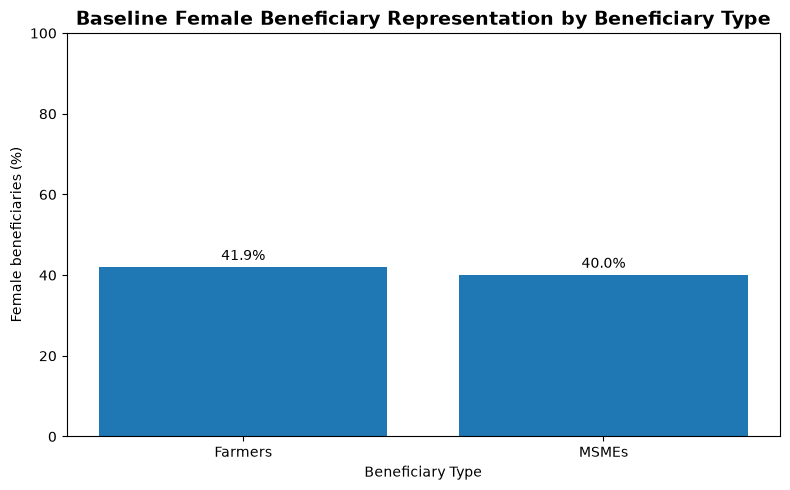

In [121]:
# 12.03 Visualization - Female Representation by Beneficiary Type

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

bars = plt.bar(
    beneficiary_summary_pct["Beneficiary Type"],
    beneficiary_summary_pct["female_pct"]
)

plt.title(
    "Baseline Female Beneficiary Representation by Beneficiary Type",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Beneficiary Type")
plt.ylabel("Female beneficiaries (%)")
plt.ylim(0, 100)

for bar, value in zip(
    bars,
    beneficiary_summary_pct["female_pct"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

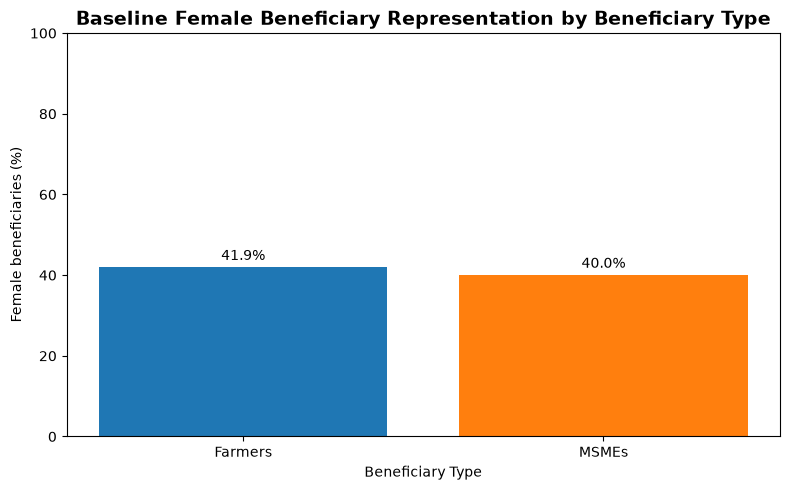

In [122]:
# 12.03 Visualization - Female Representation by Beneficiary Type

import matplotlib.pyplot as plt

beneficiary_colors = {
    "Farmers": "#1f77b4",
    "MSMEs": "#ff7f0e"
}

colors = [
    beneficiary_colors[group]
    for group in beneficiary_summary_pct["Beneficiary Type"]
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    beneficiary_summary_pct["Beneficiary Type"],
    beneficiary_summary_pct["female_pct"],
    color=colors
)

plt.title(
    "Baseline Female Beneficiary Representation by Beneficiary Type",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Beneficiary Type")
plt.ylabel("Female beneficiaries (%)")
plt.ylim(0, 100)

for bar, value in zip(
    bars,
    beneficiary_summary_pct["female_pct"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

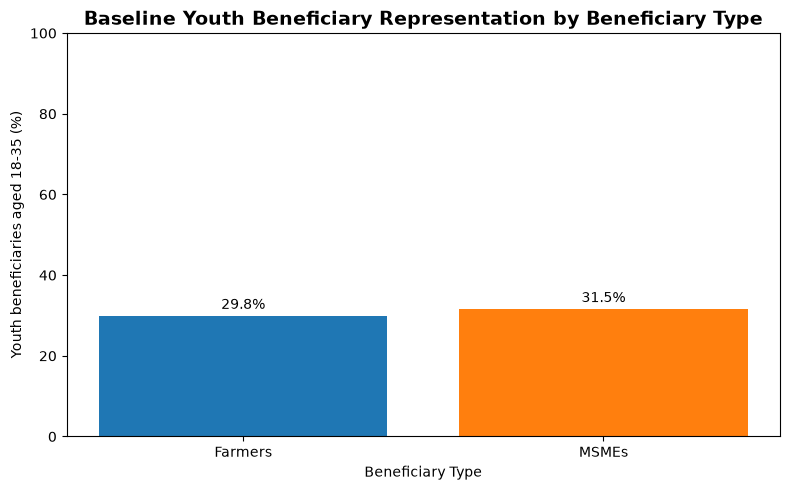

In [123]:
# 12.04 Visualization - Youth Representation by Beneficiary Type

plt.figure(figsize=(8, 5))

colors = [
    beneficiary_colors[group]
    for group in beneficiary_summary_pct["Beneficiary Type"]
]

bars = plt.bar(
    beneficiary_summary_pct["Beneficiary Type"],
    beneficiary_summary_pct["youth_pct"],
    color=colors
)

plt.title(
    "Baseline Youth Beneficiary Representation by Beneficiary Type",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Beneficiary Type")
plt.ylabel("Youth beneficiaries aged 18-35 (%)")
plt.ylim(0, 100)

for bar, value in zip(
    bars,
    beneficiary_summary_pct["youth_pct"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

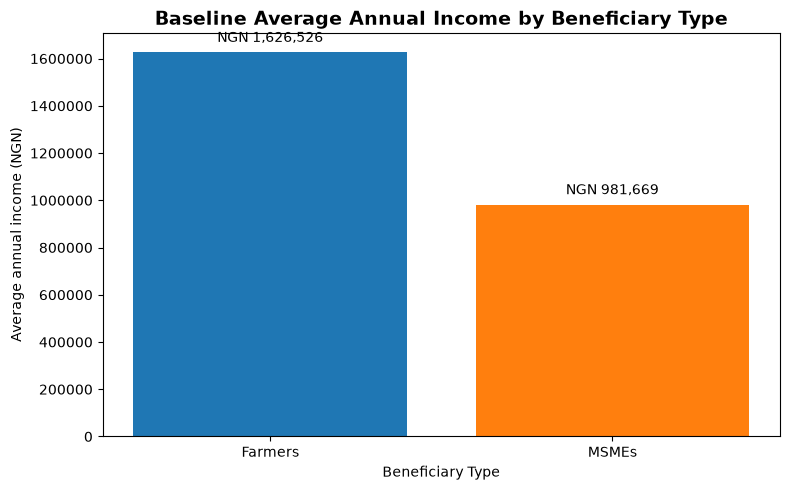

In [124]:
# 12.05 Visualization - Average Annual Income by Beneficiary Type

plt.figure(figsize=(8, 5))

colors = [
    beneficiary_colors[group]
    for group in beneficiary_summary_pct["Beneficiary Type"]
]

bars = plt.bar(
    beneficiary_summary_pct["Beneficiary Type"],
    beneficiary_summary_pct["average_income"],
    color=colors
)

plt.title(
    "Baseline Average Annual Income by Beneficiary Type",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Beneficiary Type")
plt.ylabel("Average annual income (NGN)")
plt.ticklabel_format(
    style="plain",
    axis="y"
)

for bar, value in zip(
    bars,
    beneficiary_summary_pct["average_income"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 30000,
        f"NGN {value:,.0f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

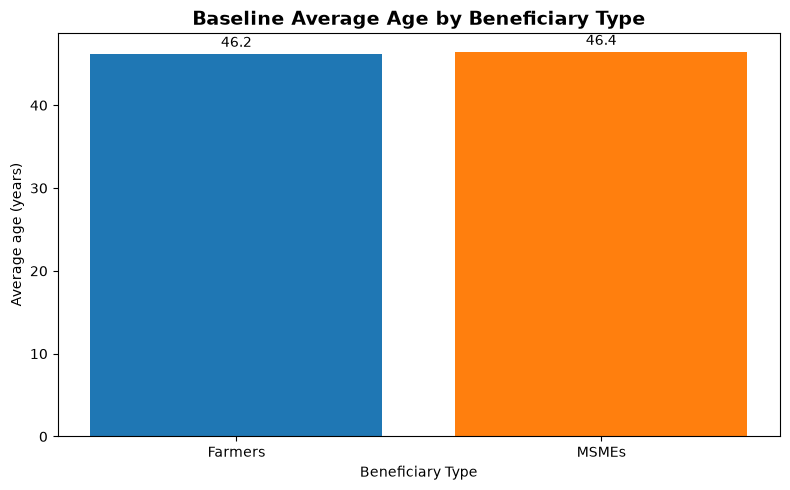

In [125]:
# 12.06 Visualization - Average Age by Beneficiary Type

plt.figure(figsize=(8, 5))

colors = [
    beneficiary_colors[group]
    for group in beneficiary_summary_pct["Beneficiary Type"]
]

bars = plt.bar(
    beneficiary_summary_pct["Beneficiary Type"],
    beneficiary_summary_pct["average_age"],
    color=colors
)

plt.title(
    "Baseline Average Age by Beneficiary Type",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Beneficiary Type")
plt.ylabel("Average age (years)")

for bar, value in zip(
    bars,
    beneficiary_summary_pct["average_age"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{value:.1f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [126]:
# 12.07 Baseline Beneficiary Profile QA

qa_total = beneficiary_summary_pct["respondents"].sum()
qa_female = beneficiary_summary_pct["female"].sum()
qa_youth = beneficiary_summary_pct["youth"].sum()

expected_total = len(df)
expected_female = (df["sex"] == 1).sum()
expected_youth = df["youth_status"].sum()

print("BASELINE BENEFICIARY PROFILE QA")
print("=" * 80)

print("Beneficiary records:", qa_total)
print("Expected records:", expected_total)

print("\nFemale beneficiaries:", qa_female)
print("Expected female beneficiaries:", expected_female)

print("\nYouth beneficiaries:", qa_youth)
print("Expected youth beneficiaries:", expected_youth)

qa_pass = (
    qa_total == expected_total
    and qa_female == expected_female
    and qa_youth == expected_youth
)

print(
    "\nBeneficiary profile QA:",
    "PASS" if qa_pass else "FAIL"
)

BASELINE BENEFICIARY PROFILE QA
Beneficiary records: 2000
Expected records: 2000

Female beneficiaries: 831
Expected female beneficiaries: 831

Youth beneficiaries: 603.0
Expected youth beneficiaries: 603.0

Beneficiary profile QA: PASS


In [127]:
# 12.08 Farmer Value-Chain Baseline Profile

farmer_value_chain = (
    df[df["beneficiary_type"] == 1]
    .groupby("primary_value_chain")
    .agg(
        farmers=("respondent_id", "count"),
        female_farmers=("sex", lambda x: (x == 1).sum()),
        youth_farmers=("youth_status", "sum"),
        average_farm_area_ha=("farm_area_ha", "mean"),
        average_productivity_t_ha=("productivity_t_per_ha", "mean"),
        average_annual_income=("total_annual_income_ngn", "mean")
    )
    .reset_index()
    .sort_values("farmers", ascending=False)
    .reset_index(drop=True)
)

display(
    farmer_value_chain.round({
        "average_farm_area_ha": 2,
        "average_productivity_t_ha": 2,
        "average_annual_income": 2
    })
)

,primary_value_chain,farmers,female_farmers,youth_farmers,average_farm_area_ha,average_productivity_t_ha,average_annual_income
0,1.0,386,178,120.0,2.75,1.80,1039585.54
1,2.0,296,111,85.0,2.60,1.97,1244835.43
2,3.0,219,97,71.0,2.56,1.90,1131995.25
3,6.0,187,76,44.0,2.66,4.16,2500885.86
4,5.0,155,59,45.0,2.57,5.42,3619051.36
5,4.0,139,55,47.0,2.58,2.07,2412602.10
6,7.0,135,62,39.0,2.55,1.50,1071684.97
7,8.0,83,33,26.0,2.30,1.37,876346.91


In [128]:
# 12.09 Farmer Value-Chain Labels and Sample Shares

value_chain_labels = {
    1: "Maize",
    2: "Rice",
    3: "Soybean",
    4: "Ginger",
    5: "Tomato",
    6: "Vegetables",
    7: "Sorghum",
    8: "Groundnut"
}

farmer_value_chain["Value Chain"] = (
    farmer_value_chain["primary_value_chain"]
    .map(value_chain_labels)
)

farmer_value_chain["sample_share_pct"] = (
    farmer_value_chain["farmers"]
    / farmer_value_chain["farmers"].sum()
    * 100
)

farmer_value_chain = farmer_value_chain[
    [
        "Value Chain",
        "farmers",
        "sample_share_pct",
        "female_farmers",
        "youth_farmers",
        "average_farm_area_ha",
        "average_productivity_t_ha",
        "average_annual_income"
    ]
]

display(
    farmer_value_chain.round({
        "sample_share_pct": 2,
        "average_farm_area_ha": 2,
        "average_productivity_t_ha": 2,
        "average_annual_income": 2
    })
)

,Value Chain,farmers,sample_share_pct,female_farmers,youth_farmers,average_farm_area_ha,average_productivity_t_ha,average_annual_income
0,Maize,386,24.12,178,120.0,2.75,1.80,1039585.54
1,Rice,296,18.50,111,85.0,2.60,1.97,1244835.43
2,Soybean,219,13.69,97,71.0,2.56,1.90,1131995.25
3,Vegetables,187,11.69,76,44.0,2.66,4.16,2500885.86
4,Tomato,155,9.69,59,45.0,2.57,5.42,3619051.36
5,Ginger,139,8.69,55,47.0,2.58,2.07,2412602.10
6,Sorghum,135,8.44,62,39.0,2.55,1.50,1071684.97
7,Groundnut,83,5.19,33,26.0,2.30,1.37,876346.91


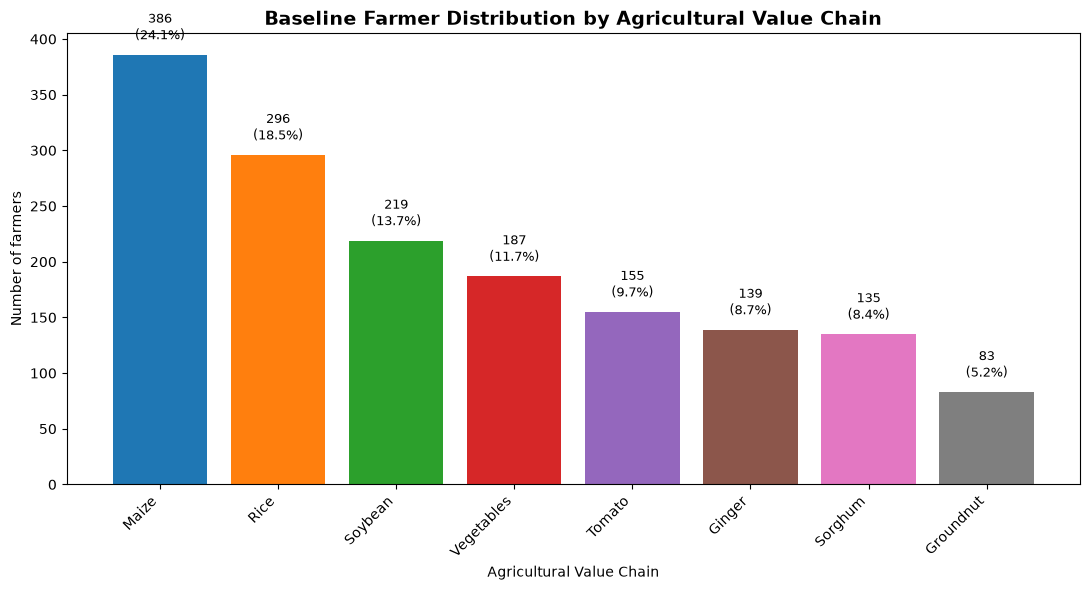

In [129]:
# 12.10 Visualization - Farmer Distribution by Value Chain

import matplotlib.pyplot as plt

value_chain_colors = {
    "Maize": "#1f77b4",
    "Rice": "#ff7f0e",
    "Soybean": "#2ca02c",
    "Vegetables": "#d62728",
    "Tomato": "#9467bd",
    "Ginger": "#8c564b",
    "Sorghum": "#e377c2",
    "Groundnut": "#7f7f7f"
}

chart_data = farmer_value_chain.sort_values(
    "farmers",
    ascending=False
).copy()

colors = [
    value_chain_colors[value_chain]
    for value_chain in chart_data["Value Chain"]
]

plt.figure(figsize=(11, 6))

bars = plt.bar(
    chart_data["Value Chain"],
    chart_data["farmers"],
    color=colors
)

plt.title(
    "Baseline Farmer Distribution by Agricultural Value Chain",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Agricultural Value Chain")
plt.ylabel("Number of farmers")
plt.xticks(rotation=45, ha="right")

for bar, count, share in zip(
    bars,
    chart_data["farmers"],
    chart_data["sample_share_pct"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 10,
        f"{count}\n({share:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

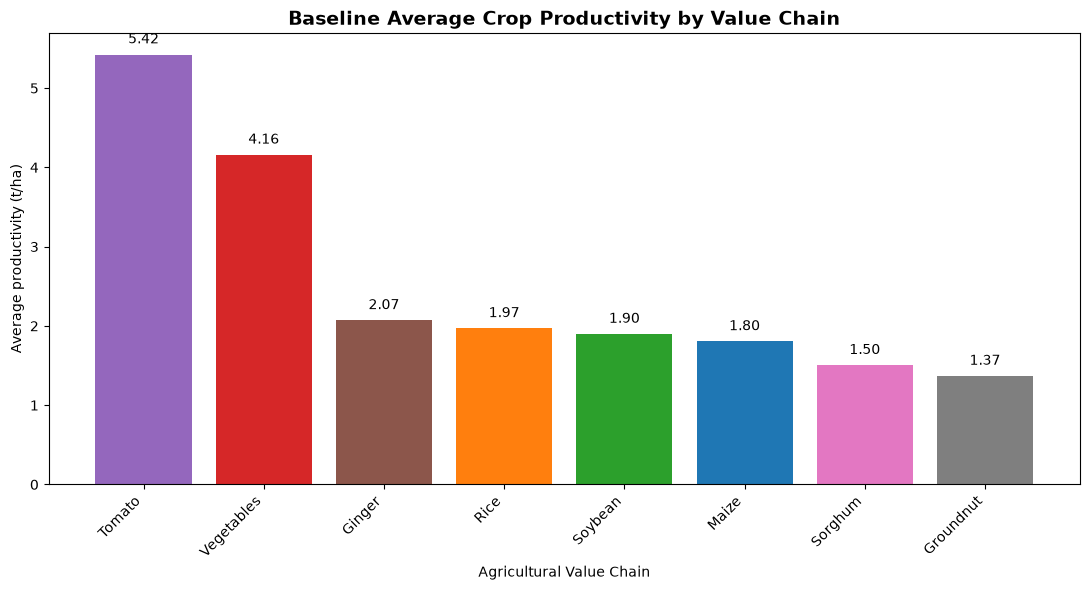

In [130]:
# 12.11 Visualization - Average Productivity by Value Chain

productivity_chart = (
    farmer_value_chain
    .sort_values(
        "average_productivity_t_ha",
        ascending=False
    )
    .copy()
)

colors = [
    value_chain_colors[value_chain]
    for value_chain in productivity_chart["Value Chain"]
]

plt.figure(figsize=(11, 6))

bars = plt.bar(
    productivity_chart["Value Chain"],
    productivity_chart["average_productivity_t_ha"],
    color=colors
)

plt.title(
    "Baseline Average Crop Productivity by Value Chain",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Agricultural Value Chain")
plt.ylabel("Average productivity (t/ha)")
plt.xticks(rotation=45, ha="right")

for bar, value in zip(
    bars,
    productivity_chart["average_productivity_t_ha"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

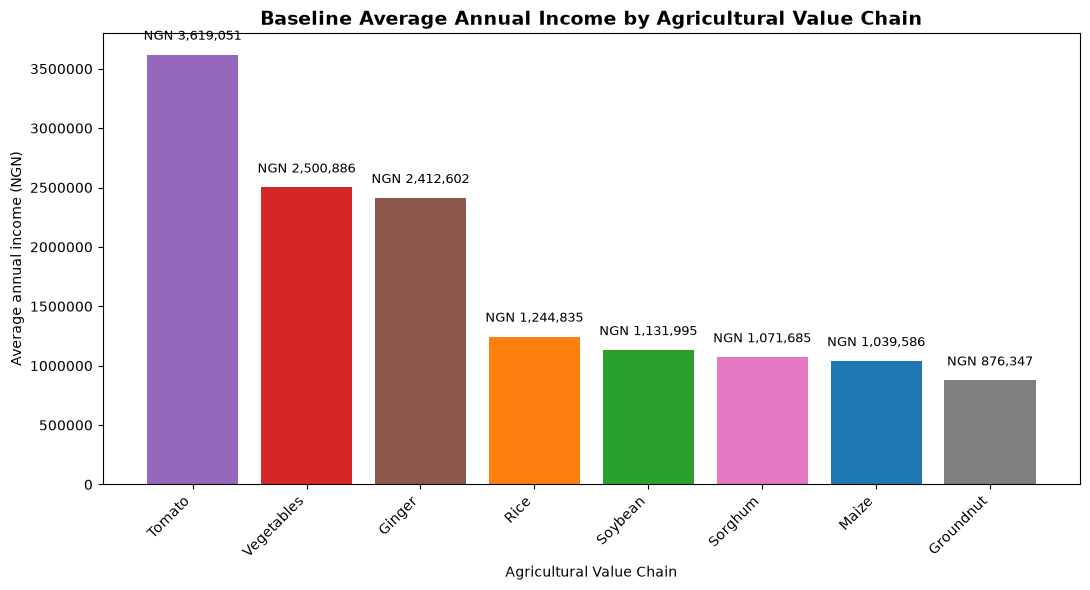

In [131]:
# 12.12 Visualization - Average Annual Income by Value Chain

income_chart = (
    farmer_value_chain
    .sort_values(
        "average_annual_income",
        ascending=False
    )
    .copy()
)

colors = [
    value_chain_colors[value_chain]
    for value_chain in income_chart["Value Chain"]
]

plt.figure(figsize=(11, 6))

bars = plt.bar(
    income_chart["Value Chain"],
    income_chart["average_annual_income"],
    color=colors
)

plt.title(
    "Baseline Average Annual Income by Agricultural Value Chain",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Agricultural Value Chain")
plt.ylabel("Average annual income (NGN)")
plt.ticklabel_format(
    style="plain",
    axis="y"
)
plt.xticks(rotation=45, ha="right")

for bar, value in zip(
    bars,
    income_chart["average_annual_income"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 100000,
        f"NGN {value:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

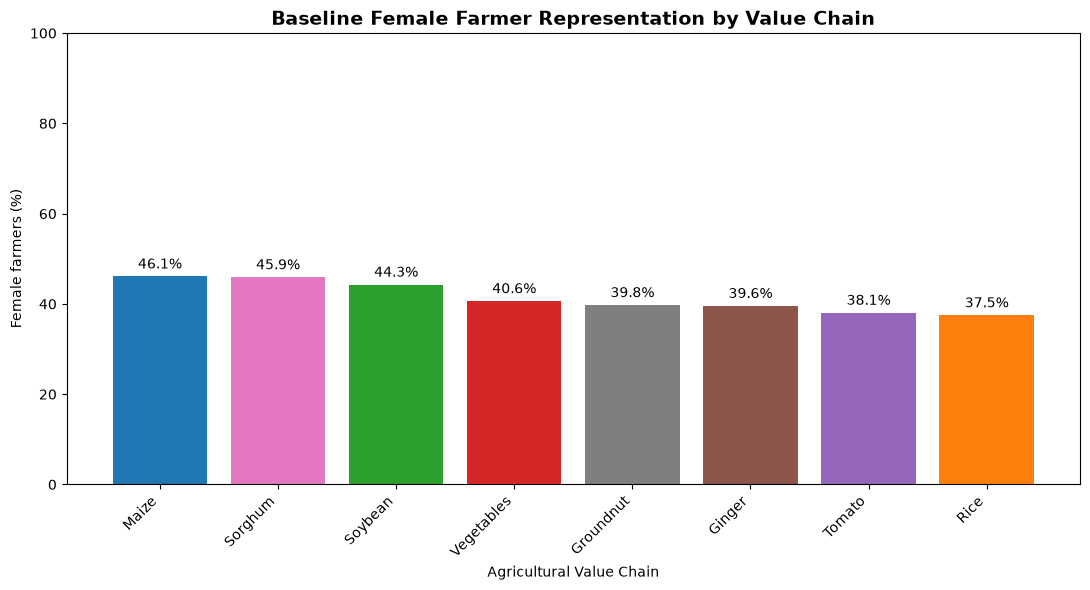

In [132]:
# 12.13 Visualization - Female Representation by Value Chain

female_chart = farmer_value_chain.copy()

female_chart["female_pct"] = (
    female_chart["female_farmers"]
    / female_chart["farmers"]
    * 100
)

female_chart = female_chart.sort_values(
    "female_pct",
    ascending=False
)

colors = [
    value_chain_colors[value_chain]
    for value_chain in female_chart["Value Chain"]
]

plt.figure(figsize=(11, 6))

bars = plt.bar(
    female_chart["Value Chain"],
    female_chart["female_pct"],
    color=colors
)

plt.title(
    "Baseline Female Farmer Representation by Value Chain",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Agricultural Value Chain")
plt.ylabel("Female farmers (%)")
plt.ylim(0, 100)
plt.xticks(rotation=45, ha="right")

for bar, value in zip(
    bars,
    female_chart["female_pct"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

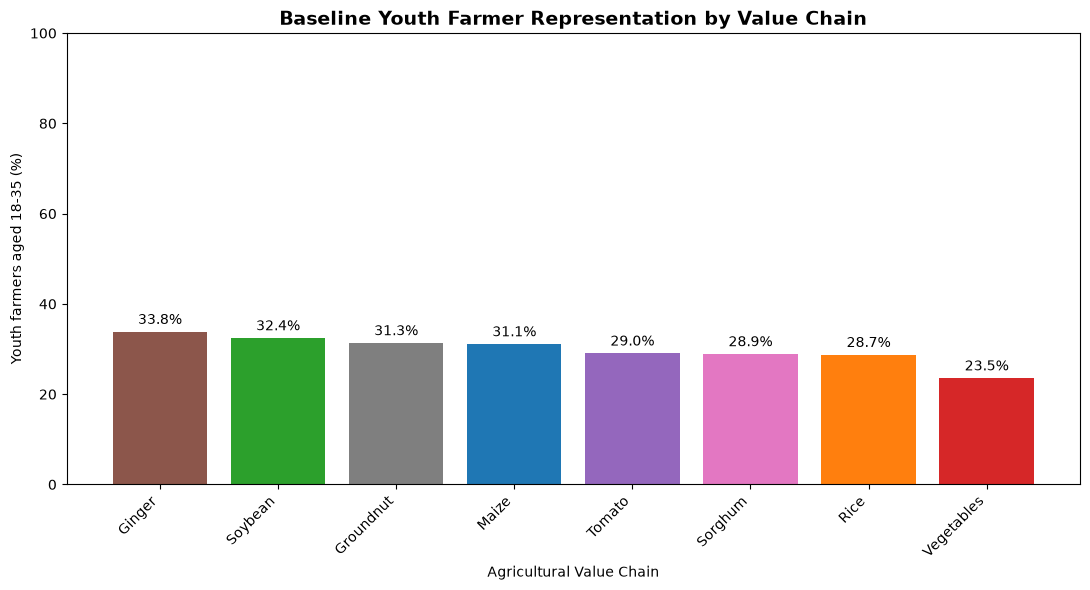

In [133]:
# 12.14 Visualization - Youth Representation by Value Chain

youth_chart = farmer_value_chain.copy()

youth_chart["youth_pct"] = (
    youth_chart["youth_farmers"]
    / youth_chart["farmers"]
    * 100
)

youth_chart = youth_chart.sort_values(
    "youth_pct",
    ascending=False
)

colors = [
    value_chain_colors[value_chain]
    for value_chain in youth_chart["Value Chain"]
]

plt.figure(figsize=(11, 6))

bars = plt.bar(
    youth_chart["Value Chain"],
    youth_chart["youth_pct"],
    color=colors
)

plt.title(
    "Baseline Youth Farmer Representation by Value Chain",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Agricultural Value Chain")
plt.ylabel("Youth farmers aged 18-35 (%)")
plt.ylim(0, 100)
plt.xticks(rotation=45, ha="right")

for bar, value in zip(
    bars,
    youth_chart["youth_pct"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [134]:
# 12.15 Farmer Value-Chain Profile QA

qa_farmers = farmer_value_chain["farmers"].sum()
qa_female = farmer_value_chain["female_farmers"].sum()
qa_youth = farmer_value_chain["youth_farmers"].sum()

expected_farmers = (df["beneficiary_type"] == 1).sum()
expected_female = (
    (df["beneficiary_type"] == 1) &
    (df["sex"] == 1)
).sum()
expected_youth = (
    (df["beneficiary_type"] == 1) &
    (df["youth_status"] == 1)
).sum()

qa_share = farmer_value_chain["sample_share_pct"].sum()

print("FARMER VALUE-CHAIN PROFILE QA")
print("=" * 80)

print("Farmers in value-chain table:", qa_farmers)
print("Expected farmers:", expected_farmers)

print("\nFemale farmers in value-chain table:", qa_female)
print("Expected female farmers:", expected_female)

print("\nYouth farmers in value-chain table:", qa_youth)
print("Expected youth farmers:", expected_youth)

print("\nValue-chain sample share:", round(qa_share, 2), "%")

qa_pass = (
    qa_farmers == expected_farmers
    and qa_female == expected_female
    and qa_youth == expected_youth
    and abs(qa_share - 100) < 0.01
)

print(
    "\nFarmer value-chain profile QA:",
    "PASS" if qa_pass else "FAIL"
)

FARMER VALUE-CHAIN PROFILE QA
Farmers in value-chain table: 1600
Expected farmers: 1600

Female farmers in value-chain table: 671
Expected female farmers: 671

Youth farmers in value-chain table: 477.0
Expected youth farmers: 477

Value-chain sample share: 100.0 %

Farmer value-chain profile QA: PASS


In [135]:
# 12.16 MSME Baseline Profile

msme_profile = (
    df[df["beneficiary_type"] == 2]
    .groupby("beneficiary_type")
    .agg(
        msmes=("respondent_id", "count"),
        female_msmes=("sex", lambda x: (x == 1).sum()),
        youth_msmes=("youth_status", "sum"),
        average_age=("age", "mean"),
        average_years_in_operation=("years_in_operation", "mean"),
        average_employees=("number_of_employees", "mean"),
        average_annual_sales=("annual_sales_ngn", "mean"),
        average_operating_cost=("annual_operating_cost_ngn", "mean"),
        average_annual_profit=("annual_profit_ngn", "mean")
    )
    .reset_index()
)

msme_profile["Beneficiary Type"] = "MSMEs"

msme_profile = msme_profile[
    [
        "Beneficiary Type",
        "msmes",
        "female_msmes",
        "youth_msmes",
        "average_age",
        "average_years_in_operation",
        "average_employees",
        "average_annual_sales",
        "average_operating_cost",
        "average_annual_profit"
    ]
]

display(
    msme_profile.round({
        "average_age": 2,
        "average_years_in_operation": 2,
        "average_employees": 2,
        "average_annual_sales": 2,
        "average_operating_cost": 2,
        "average_annual_profit": 2
    })
)

,Beneficiary Type,msmes,female_msmes,youth_msmes,average_age,average_years_in_operation,average_employees,average_annual_sales,average_operating_cost,average_annual_profit
0,MSMEs,400,160,126.0,46.39,10.42,15.84,988565.44,631726.4,356839.05


In [136]:
# 12.17 MSME Percentage Profile

msme_profile_pct = msme_profile.copy()

msme_profile_pct["female_pct"] = (
    msme_profile_pct["female_msmes"]
    / msme_profile_pct["msmes"]
    * 100
)

msme_profile_pct["youth_pct"] = (
    msme_profile_pct["youth_msmes"]
    / msme_profile_pct["msmes"]
    * 100
)

msme_profile_pct = msme_profile_pct[
    [
        "Beneficiary Type",
        "msmes",
        "female_msmes",
        "female_pct",
        "youth_msmes",
        "youth_pct",
        "average_age",
        "average_years_in_operation",
        "average_employees",
        "average_annual_sales",
        "average_operating_cost",
        "average_annual_profit"
    ]
]

display(
    msme_profile_pct.round({
        "female_pct": 2,
        "youth_pct": 2,
        "average_age": 2,
        "average_years_in_operation": 2,
        "average_employees": 2,
        "average_annual_sales": 2,
        "average_operating_cost": 2,
        "average_annual_profit": 2
    })
)

,Beneficiary Type,msmes,female_msmes,female_pct,youth_msmes,youth_pct,average_age,average_years_in_operation,average_employees,average_annual_sales,average_operating_cost,average_annual_profit
0,MSMEs,400,160,40.0,126.0,31.5,46.39,10.42,15.84,988565.44,631726.4,356839.05


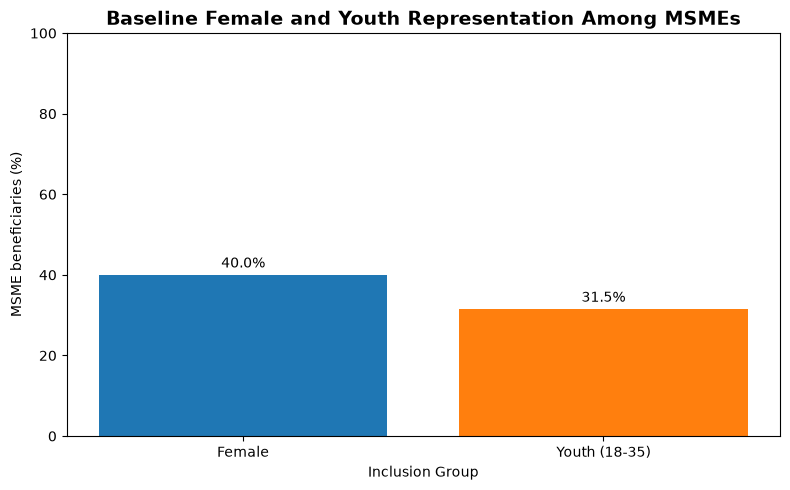

In [137]:
# 12.18 Visualization - MSME Female and Youth Representation

inclusion_labels = ["Female", "Youth (18-35)"]

inclusion_values = [
    msme_profile_pct["female_pct"].iloc[0],
    msme_profile_pct["youth_pct"].iloc[0]
]

inclusion_colors = [
    "#1f77b4",
    "#ff7f0e"
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    inclusion_labels,
    inclusion_values,
    color=inclusion_colors
)

plt.title(
    "Baseline Female and Youth Representation Among MSMEs",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Inclusion Group")
plt.ylabel("MSME beneficiaries (%)")
plt.ylim(0, 100)

for bar, value in zip(
    bars,
    inclusion_values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

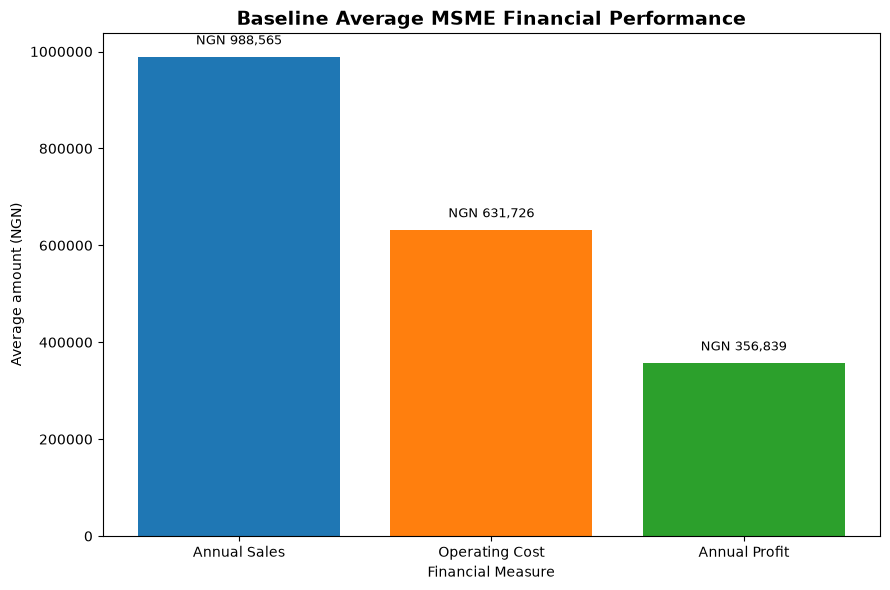

In [138]:
# 12.19 Visualization - MSME Financial Performance

financial_labels = [
    "Annual Sales",
    "Operating Cost",
    "Annual Profit"
]

financial_values = [
    msme_profile_pct["average_annual_sales"].iloc[0],
    msme_profile_pct["average_operating_cost"].iloc[0],
    msme_profile_pct["average_annual_profit"].iloc[0]
]

financial_colors = [
    "#1f77b4",
    "#ff7f0e",
    "#2ca02c"
]

plt.figure(figsize=(9, 6))

bars = plt.bar(
    financial_labels,
    financial_values,
    color=financial_colors
)

plt.title(
    "Baseline Average MSME Financial Performance",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Financial Measure")
plt.ylabel("Average amount (NGN)")
plt.ticklabel_format(
    style="plain",
    axis="y"
)

for bar, value in zip(
    bars,
    financial_values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 20000,
        f"NGN {value:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [141]:
# 12.20B Corrected MSME Financial Profile QA

msme_df = df[df["beneficiary_type"] == 2].copy()

qa_msmes = len(msme_df)
qa_female = (msme_df["sex"] == 1).sum()
qa_youth = msme_df["youth_status"].sum()

expected_profit = (
    msme_df["annual_sales_ngn"]
    - msme_df["annual_operating_cost_ngn"]
)

qa_profit_mismatch = (
    ~np.isclose(
        msme_df["annual_profit_ngn"],
        expected_profit,
        rtol=1e-9,
        atol=0.01,
        equal_nan=True
    )
).sum()

profile_msmes = msme_profile_pct["msmes"].iloc[0]
profile_female = msme_profile_pct["female_msmes"].iloc[0]
profile_youth = msme_profile_pct["youth_msmes"].iloc[0]

print("CORRECTED MSME FINANCIAL PROFILE QA")
print("=" * 80)

print("MSMEs in master dataset:", qa_msmes)
print("MSMEs in profile:", profile_msmes)

print("\nFemale MSMEs in master dataset:", qa_female)
print("Female MSMEs in profile:", profile_female)

print("\nYouth MSMEs in master dataset:", qa_youth)
print("Youth MSMEs in profile:", profile_youth)

print("\nMaterial annual profit mismatches:", qa_profit_mismatch)

qa_pass = (
    qa_msmes == profile_msmes
    and qa_female == profile_female
    and qa_youth == profile_youth
    and qa_profit_mismatch == 0
)

print(
    "\nCorrected MSME financial profile QA:",
    "PASS" if qa_pass else "FAIL"
)

CORRECTED MSME FINANCIAL PROFILE QA
MSMEs in master dataset: 400
MSMEs in profile: 400

Female MSMEs in master dataset: 160
Female MSMEs in profile: 160

Youth MSMEs in master dataset: 126.0
Youth MSMEs in profile: 126.0

Material annual profit mismatches: 0

Corrected MSME financial profile QA: PASS


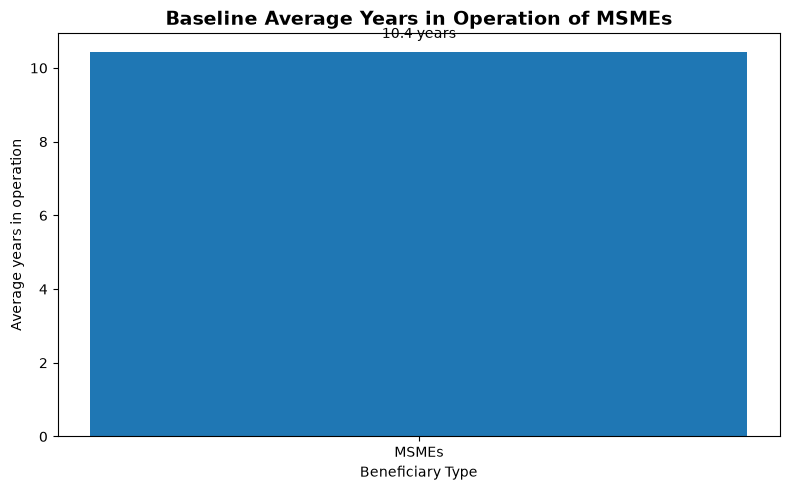

In [142]:
# 12.21 Visualization - MSME Years in Operation

plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["MSMEs"],
    [msme_profile_pct["average_years_in_operation"].iloc[0]],
    color="#1f77b4"
)

plt.title(
    "Baseline Average Years in Operation of MSMEs",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Beneficiary Type")
plt.ylabel("Average years in operation")

value = msme_profile_pct["average_years_in_operation"].iloc[0]

plt.text(
    bars[0].get_x() + bars[0].get_width() / 2,
    bars[0].get_height() + 0.3,
    f"{value:.1f} years",
    ha="center",
    va="bottom",
    fontsize=10
)

plt.tight_layout()
plt.show()

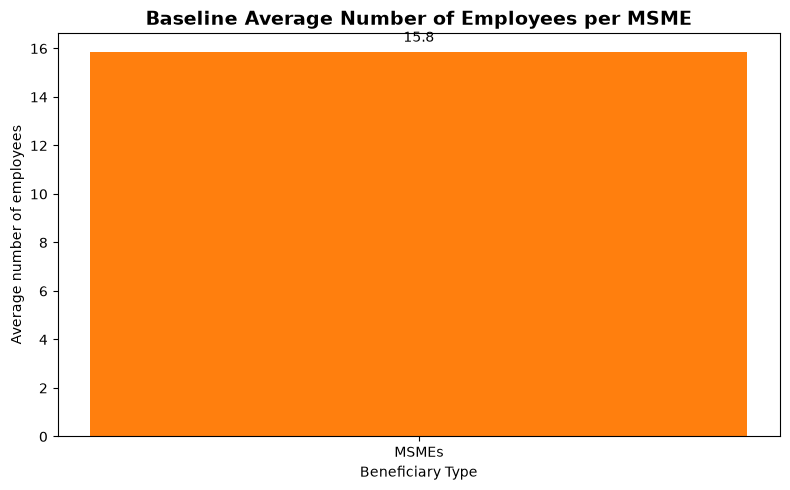

In [143]:
# 12.22 Visualization - Average MSME Employment

plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["MSMEs"],
    [msme_profile_pct["average_employees"].iloc[0]],
    color="#ff7f0e"
)

plt.title(
    "Baseline Average Number of Employees per MSME",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Beneficiary Type")
plt.ylabel("Average number of employees")

value = msme_profile_pct["average_employees"].iloc[0]

plt.text(
    bars[0].get_x() + bars[0].get_width() / 2,
    bars[0].get_height() + 0.3,
    f"{value:.1f}",
    ha="center",
    va="bottom",
    fontsize=10
)

plt.tight_layout()
plt.show()

In [145]:
# 12.23A Diagnostic - Check MSME Financial Profile Columns

print("MSME financial profile columns:")
print(msme_profile_pct.columns.tolist())

MSME financial profile columns:
['Beneficiary Type', 'msmes', 'female_msmes', 'female_pct', 'youth_msmes', 'youth_pct', 'average_age', 'average_years_in_operation', 'average_employees', 'average_annual_sales', 'average_operating_cost', 'average_annual_profit']


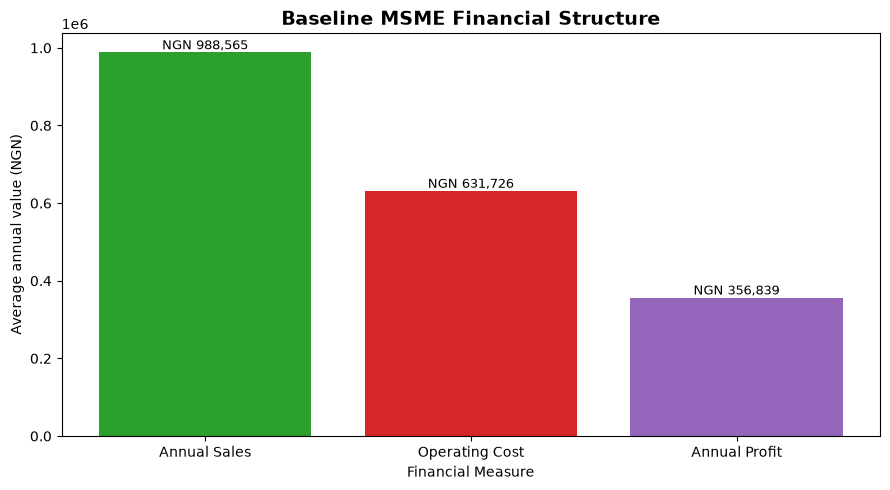

In [146]:
# 12.23 Visualization - MSME Financial Structure

financial_labels = [
    "Annual Sales",
    "Operating Cost",
    "Annual Profit"
]

financial_values = [
    msme_profile_pct["average_annual_sales"].iloc[0],
    msme_profile_pct["average_operating_cost"].iloc[0],
    msme_profile_pct["average_annual_profit"].iloc[0]
]

financial_colors = [
    "#2ca02c",
    "#d62728",
    "#9467bd"
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    financial_labels,
    financial_values,
    color=financial_colors
)

plt.title(
    "Baseline MSME Financial Structure",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Financial Measure")
plt.ylabel("Average annual value (NGN)")

for bar, value in zip(bars, financial_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"NGN {value:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [147]:
# 12.24 MSME Financial Record-Keeping Profile

msme_records = (
    df[df["beneficiary_type"] == 2]
    .copy()
)

record_columns = [
    "sales_records",
    "expense_records",
    "inventory_records",
    "cashflow_records",
    "profit_loss_records"
]

msme_records["financial_record_count"] = (
    msme_records[record_columns]
    .sum(axis=1)
)

record_profile = (
    msme_records["financial_record_count"]
    .value_counts()
    .sort_index()
    .reset_index()
)

record_profile.columns = [
    "Financial Record Types Maintained",
    "MSMEs"
]

record_profile["Percentage"] = (
    record_profile["MSMEs"]
    / len(msme_records)
    * 100
)

display(record_profile)

,Financial Record Types Maintained,MSMEs,Percentage
0,0.0,14,3.50
1,1.0,71,17.75
2,2.0,115,28.75
3,3.0,136,34.00
4,4.0,57,14.25
5,5.0,7,1.75


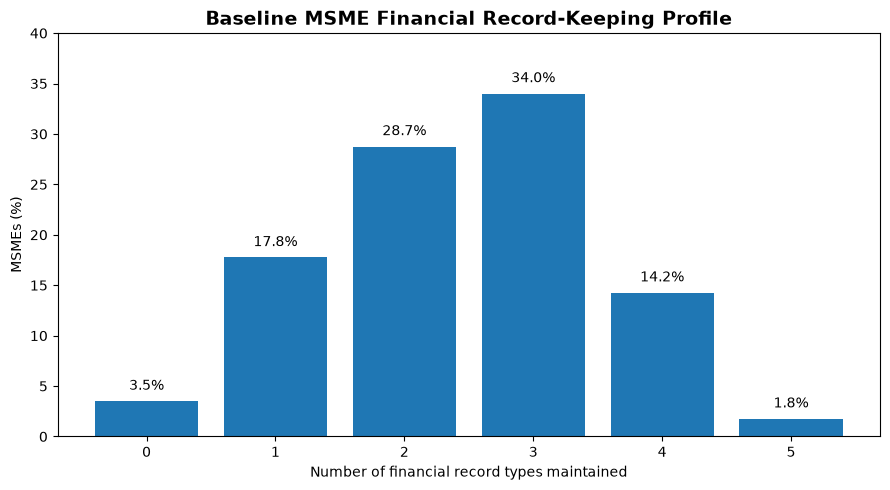

In [148]:
# 12.25 Visualization - MSME Financial Record-Keeping

plt.figure(figsize=(9, 5))

bars = plt.bar(
    record_profile["Financial Record Types Maintained"].astype(int).astype(str),
    record_profile["Percentage"],
    color="#1f77b4"
)

plt.title(
    "Baseline MSME Financial Record-Keeping Profile",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Number of financial record types maintained")
plt.ylabel("MSMEs (%)")
plt.ylim(0, 40)

for bar, value in zip(
    bars,
    record_profile["Percentage"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [149]:
# 12.26 MSME Financial Record-Keeping by Record Type

record_type_labels = {
    "sales_records": "Sales records",
    "expense_records": "Expense records",
    "inventory_records": "Inventory records",
    "cashflow_records": "Cash-flow records",
    "profit_loss_records": "Profit/loss records"
}

record_type_profile = []

for column, label in record_type_labels.items():
    count = (
        msme_records[column]
        .eq(1)
        .sum()
    )

    percentage = (
        count
        / len(msme_records)
        * 100
    )

    record_type_profile.append(
        {
            "Record Type": label,
            "MSMEs": count,
            "Percentage": percentage
        }
    )

record_type_profile = (
    pd.DataFrame(record_type_profile)
    .sort_values("Percentage", ascending=False)
    .reset_index(drop=True)
)

display(record_type_profile)

,Record Type,MSMEs,Percentage
0,Sales records,240,60.00
1,Expense records,235,58.75
2,Inventory records,204,51.00
3,Cash-flow records,160,40.00
4,Profit/loss records,133,33.25


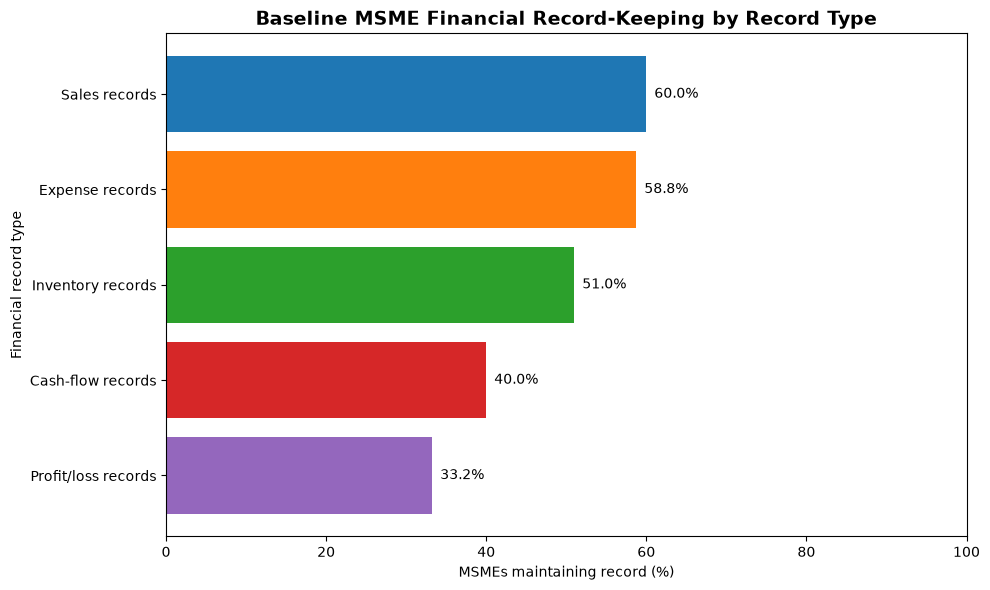

In [151]:
# 12.27 Visualization - MSME Financial Record Types

plt.figure(figsize=(10, 6))

record_chart = record_type_profile.sort_values(
    "Percentage",
    ascending=True
)

record_colors = [
    "#9467bd",  # Profit/loss
    "#d62728",  # Cash-flow
    "#2ca02c",  # Inventory
    "#ff7f0e",  # Expense
    "#1f77b4"   # Sales
]

bars = plt.barh(
    record_chart["Record Type"],
    record_chart["Percentage"],
    color=record_colors
)

plt.title(
    "Baseline MSME Financial Record-Keeping by Record Type",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("MSMEs maintaining record (%)")
plt.ylabel("Financial record type")
plt.xlim(0, 100)

for bar, value in zip(
    bars,
    record_chart["Percentage"]
):
    plt.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [152]:
# 12.28 MSME Financial Record-Keeping QA

qa_total_msmes = len(msme_records)

qa_record_total = record_profile["MSMEs"].sum()

qa_out09_count = (
    msme_records["financial_record_count"] >= 3
).sum()

qa_out09_percentage = (
    qa_out09_count
    / qa_total_msmes
    * 100
)

print("MSMEs assessed:", qa_total_msmes)
print("Record-profile total:", qa_record_total)
print("MSMEs maintaining at least 3 record types:", qa_out09_count)
print(
    "OUT-09 calculated percentage:",
    f"{qa_out09_percentage:.2f}%"
)

qa_pass = (
    qa_total_msmes == 400
    and qa_record_total == 400
    and qa_out09_count == 200
    and np.isclose(
        qa_out09_percentage,
        50.00,
        atol=0.01
    )
)

print(
    "MSME financial record-keeping QA:",
    "PASS" if qa_pass else "FAIL"
)

MSMEs assessed: 400
Record-profile total: 400
MSMEs maintaining at least 3 record types: 200
OUT-09 calculated percentage: 50.00%
MSME financial record-keeping QA: PASS


In [153]:
# 12.29 MSME Business Type Profile

business_type_profile = (
    msme_records["business_type"]
    .value_counts()
    .sort_index()
    .reset_index()
)

business_type_profile.columns = [
    "Business Type",
    "MSMEs"
]

business_type_profile["Percentage"] = (
    business_type_profile["MSMEs"]
    / len(msme_records)
    * 100
)

display(business_type_profile)

,Business Type,MSMEs,Percentage
0,1.0,91,22.75
1,2.0,100,25.00
2,3.0,61,15.25
3,4.0,37,9.25
4,5.0,40,10.00
5,6.0,26,6.50
6,7.0,45,11.25


In [154]:
# 12.30 Diagnostic - Check Business Type Coding

print("Unique business type codes in the clean dataset:")
print(
    sorted(
        msme_records["business_type"]
        .dropna()
        .unique()
        .tolist()
    )
)

print("\nBusiness type coding available in notebook variables:")

for name in [
    "business_type_labels",
    "business_type_mapping",
    "business_type_codes"
]:
    if name in globals():
        print(f"\n{name}:")
        print(globals()[name])

Unique business type codes in the clean dataset:
[1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0]

Business type coding available in notebook variables:


In [155]:
# 12.31 Retrieve Business-Type Coding from the Variable Coding Scheme

coding_file = PROJECT_ROOT / "04_Data_Metadata" / "Variable_Coding_Scheme.xlsx"

coding_df = pd.read_excel(coding_file)

business_type_coding = coding_df[
    coding_df["Variable"] == "business_type"
].copy()

display(business_type_coding)

,Variable,Label / Description,Code Type,Codes / Categories,Missing Code,Notes
26,business_type,MSME business type,Categorical,1 = Processing; 2 = Trading; 3 = Aggregation; ...,99 = Not stated,MSME respondents only.


In [156]:
# 12.32 Retrieve Full Business-Type Category Coding

business_type_code_text = (
    business_type_coding["Codes / Categories"]
    .iloc[0]
)

print("Full business_type coding:")
print(business_type_code_text)

Full business_type coding:
1 = Processing; 2 = Trading; 3 = Aggregation; 4 = Input supply; 5 = Storage; 6 = Transport; 7 = Other


In [157]:
# 12.33 MSME Business-Type Profile with Labels

business_type_labels = {
    1: "Processing",
    2: "Trading",
    3: "Aggregation",
    4: "Input supply",
    5: "Storage",
    6: "Transport",
    7: "Other"
}

business_type_profile["Business Type"] = (
    business_type_profile["Business Type"]
    .map(business_type_labels)
)

business_type_profile = (
    business_type_profile[
        ["Business Type", "MSMEs", "Percentage"]
    ]
    .sort_values("MSMEs", ascending=False)
    .reset_index(drop=True)
)

display(business_type_profile)

,Business Type,MSMEs,Percentage
0,Trading,100,25.00
1,Processing,91,22.75
2,Aggregation,61,15.25
3,Other,45,11.25
4,Storage,40,10.00
5,Input supply,37,9.25
6,Transport,26,6.50


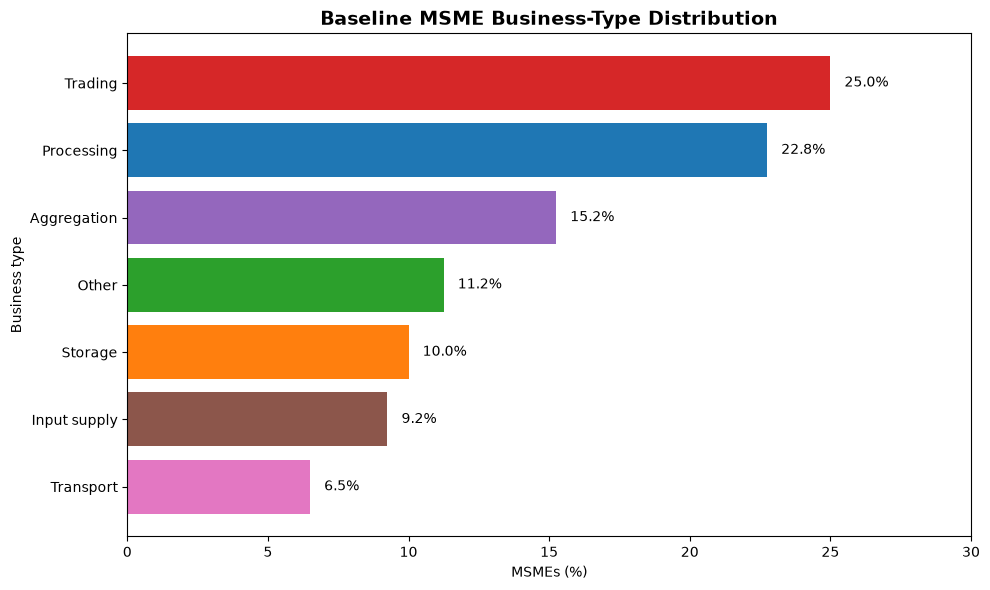

In [158]:
# 12.34 Visualization - MSME Business Types

plt.figure(figsize=(10, 6))

business_chart = business_type_profile.sort_values(
    "Percentage",
    ascending=True
)

business_colors = [
    "#e377c2",  # Transport
    "#8c564b",  # Input supply
    "#ff7f0e",  # Storage
    "#2ca02c",  # Other
    "#9467bd",  # Aggregation
    "#1f77b4",  # Processing
    "#d62728"   # Trading
]

bars = plt.barh(
    business_chart["Business Type"],
    business_chart["Percentage"],
    color=business_colors
)

plt.title(
    "Baseline MSME Business-Type Distribution",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("MSMEs (%)")
plt.ylabel("Business type")
plt.xlim(0, 30)

for bar, value in zip(
    bars,
    business_chart["Percentage"]
):
    plt.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [159]:
# 12.35 MSME Business-Type QA

qa_business_total = business_type_profile["MSMEs"].sum()

qa_business_percentage = (
    business_type_profile["Percentage"].sum()
)

qa_business_categories = (
    business_type_profile["Business Type"].nunique()
)

qa_expected_categories = 7

print("MSMEs assessed:", len(msme_records))
print("Business-type profile total:", qa_business_total)
print("Business-type categories:", qa_business_categories)
print(
    "Business-type percentage total:",
    f"{qa_business_percentage:.2f}%"
)

qa_business_pass = (
    len(msme_records) == 400
    and qa_business_total == 400
    and qa_business_categories == qa_expected_categories
    and np.isclose(
        qa_business_percentage,
        100.00,
        atol=0.01
    )
)

print(
    "MSME business-type QA:",
    "PASS" if qa_business_pass else "FAIL"
)

MSMEs assessed: 400
Business-type profile total: 400
Business-type categories: 7
Business-type percentage total: 100.00%
MSME business-type QA: PASS


In [160]:
# 12.36 MSME Business Type by Financial Record-Keeping

msme_records["Business Type"] = (
    msme_records["business_type"]
    .map(business_type_labels)
)

business_record_profile = (
    msme_records
    .groupby("Business Type")
    .agg(
        MSMEs=("respondent_id", "count"),
        MSMEs_3plus_records=(
            "financial_record_count",
            lambda x: (x >= 3).sum()
        )
    )
    .reset_index()
)

business_record_profile["Percentage_3plus_records"] = (
    business_record_profile["MSMEs_3plus_records"]
    / business_record_profile["MSMEs"]
    * 100
)

business_record_profile = (
    business_record_profile
    .sort_values(
        "Percentage_3plus_records",
        ascending=False
    )
    .reset_index(drop=True)
)

display(business_record_profile)

,Business Type,MSMEs,MSMEs_3plus_records,Percentage_3plus_records
0,Transport,26,19,73.076923
1,Aggregation,61,34,55.737705
2,Storage,40,21,52.500000
3,Processing,91,47,51.648352
4,Input supply,37,19,51.351351
5,Other,45,19,42.222222
6,Trading,100,41,41.000000


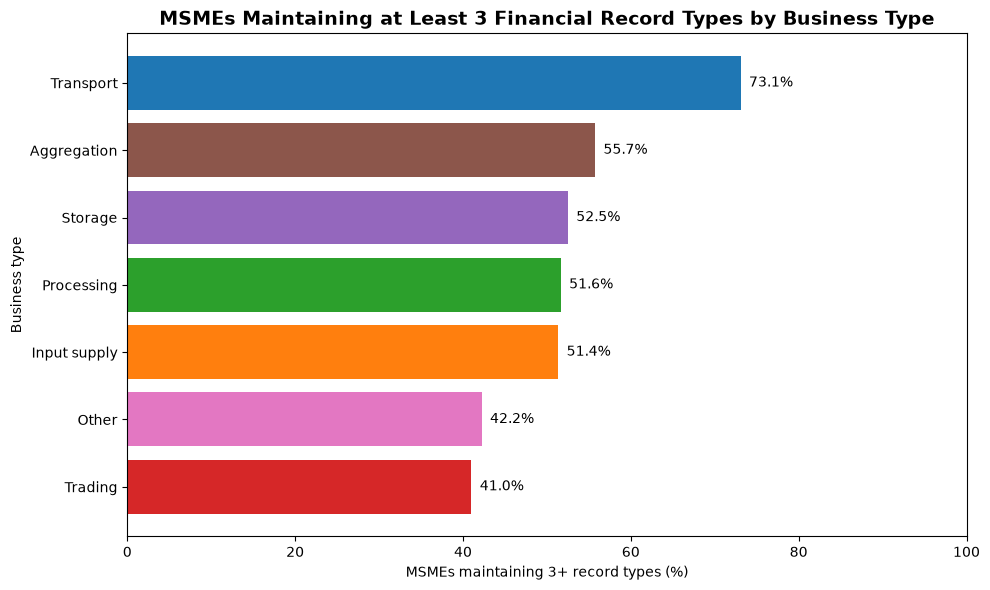

In [161]:
# 12.37 Visualization - Financial Record-Keeping by MSME Business Type

plt.figure(figsize=(10, 6))

business_record_chart = business_record_profile.sort_values(
    "Percentage_3plus_records",
    ascending=True
)

business_record_colors = [
    "#d62728",  # Trading
    "#e377c2",  # Other
    "#ff7f0e",  # Input supply
    "#2ca02c",  # Processing
    "#9467bd",  # Storage
    "#8c564b",  # Aggregation
    "#1f77b4"   # Transport
]

bars = plt.barh(
    business_record_chart["Business Type"],
    business_record_chart["Percentage_3plus_records"],
    color=business_record_colors
)

plt.title(
    "MSMEs Maintaining at Least 3 Financial Record Types by Business Type",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("MSMEs maintaining 3+ record types (%)")
plt.ylabel("Business type")
plt.xlim(0, 100)

for bar, value in zip(
    bars,
    business_record_chart["Percentage_3plus_records"]
):
    plt.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [162]:
# 12.38 MSME Business Type x Financial Record-Keeping QA

qa_business_record_total = (
    business_record_profile["MSMEs"].sum()
)

qa_business_record_3plus_total = (
    business_record_profile["MSMEs_3plus_records"].sum()
)

qa_business_record_categories = (
    business_record_profile["Business Type"].nunique()
)

qa_percentage_check = (
    (
        business_record_profile["MSMEs_3plus_records"]
        / business_record_profile["MSMEs"]
        * 100
    )
    - business_record_profile["Percentage_3plus_records"]
).abs().max()

print("MSMEs assessed:", len(msme_records))
print("Business-type profile total:", qa_business_record_total)
print(
    "MSMEs maintaining 3+ record types:",
    qa_business_record_3plus_total
)
print(
    "Business-type categories:",
    qa_business_record_categories
)
print(
    "Maximum percentage calculation difference:",
    f"{qa_percentage_check:.10f}"
)

qa_business_record_pass = (
    len(msme_records) == 400
    and qa_business_record_total == 400
    and qa_business_record_categories == 7
    and np.isclose(
        qa_business_record_3plus_total,
        200,
        atol=0
    )
    and qa_percentage_check <= 0.01
)

print(
    "Business type x financial record-keeping QA:",
    "PASS" if qa_business_record_pass else "FAIL"
)

MSMEs assessed: 400
Business-type profile total: 400
MSMEs maintaining 3+ record types: 200
Business-type categories: 7
Maximum percentage calculation difference: 0.0000000000
Business type x financial record-keeping QA: PASS


In [163]:
# 12.39 MSME Business Type by Average Annual Profit

business_profit_profile = (
    msme_records
    .groupby("Business Type")
    .agg(
        MSMEs=("respondent_id", "count"),
        Average_Annual_Profit=("annual_profit_ngn", "mean")
    )
    .reset_index()
)

business_profit_profile = (
    business_profit_profile
    .sort_values(
        "Average_Annual_Profit",
        ascending=False
    )
    .reset_index(drop=True)
)

display(business_profit_profile)

,Business Type,MSMEs,Average_Annual_Profit
0,Aggregation,61,1.039069e+06
1,Storage,40,2.688253e+05
2,Trading,100,2.453448e+05
3,Processing,91,2.344712e+05
4,Input supply,37,2.218410e+05
5,Other,45,2.201549e+05
6,Transport,26,1.774214e+05


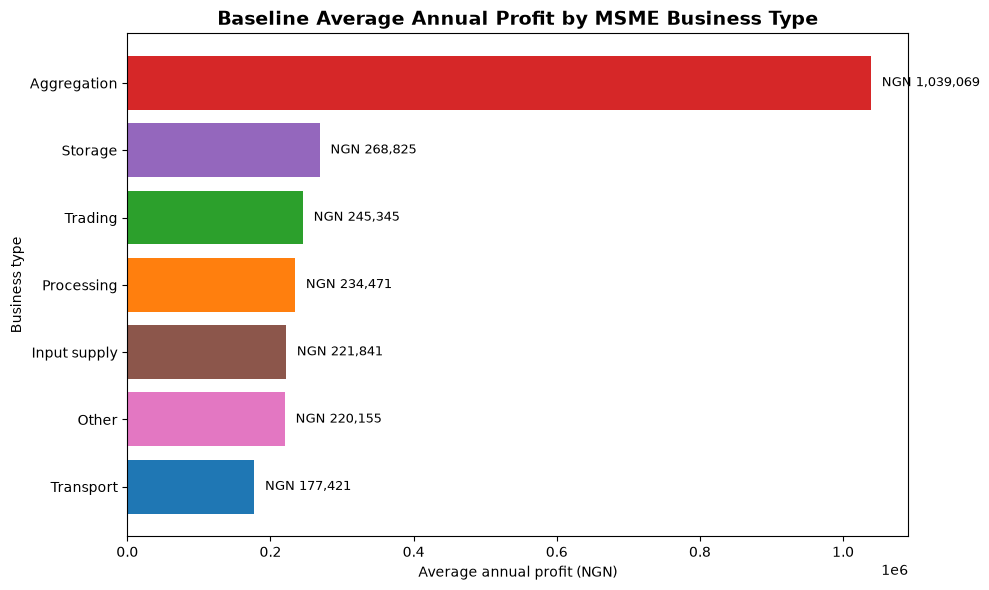

In [164]:
# 12.40 Visualization - Average Annual Profit by MSME Business Type

plt.figure(figsize=(10, 6))

business_profit_chart = business_profit_profile.sort_values(
    "Average_Annual_Profit",
    ascending=True
)

business_profit_colors = [
    "#1f77b4",  # Transport
    "#e377c2",  # Other
    "#8c564b",  # Input supply
    "#ff7f0e",  # Processing
    "#2ca02c",  # Trading
    "#9467bd",  # Storage
    "#d62728"   # Aggregation
]

bars = plt.barh(
    business_profit_chart["Business Type"],
    business_profit_chart["Average_Annual_Profit"],
    color=business_profit_colors
)

plt.title(
    "Baseline Average Annual Profit by MSME Business Type",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Average annual profit (NGN)")
plt.ylabel("Business type")

for bar, value in zip(
    bars,
    business_profit_chart["Average_Annual_Profit"]
):
    plt.text(
        bar.get_width() + 15000,
        bar.get_y() + bar.get_height() / 2,
        f"NGN {value:,.0f}",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [165]:
# 12.41 MSME Business-Type Profit Profile QA

qa_profit_total_msmes = (
    business_profit_profile["MSMEs"].sum()
)

qa_profit_categories = (
    business_profit_profile["Business Type"].nunique()
)

qa_expected_profit = (
    msme_records
    .groupby("Business Type")["annual_profit_ngn"]
    .mean()
    .reindex(business_profit_profile["Business Type"])
)

qa_profit_difference = (
    business_profit_profile["Average_Annual_Profit"].to_numpy()
    - qa_expected_profit.to_numpy()
)

qa_max_profit_difference = np.max(
    np.abs(qa_profit_difference)
)

print("MSMEs assessed:", len(msme_records))
print("Business-type profile total:", qa_profit_total_msmes)
print("Business-type categories:", qa_profit_categories)
print(
    "Maximum average-profit calculation difference:",
    f"{qa_max_profit_difference:.10f}"
)

qa_business_profit_pass = (
    len(msme_records) == 400
    and qa_profit_total_msmes == 400
    and qa_profit_categories == 7
    and qa_max_profit_difference <= 0.01
)

print(
    "MSME business-type profit QA:",
    "PASS" if qa_business_profit_pass else "FAIL"
)

MSMEs assessed: 400
Business-type profile total: 400
Business-type categories: 7
Maximum average-profit calculation difference: 0.0000000000
MSME business-type profit QA: PASS


In [166]:
# 12.42 MSME Business Type by Average Annual Sales

business_sales_profile = (
    msme_records
    .groupby("Business Type")
    .agg(
        MSMEs=("respondent_id", "count"),
        Average_Annual_Sales=("annual_sales_ngn", "mean")
    )
    .reset_index()
)

business_sales_profile = (
    business_sales_profile
    .sort_values(
        "Average_Annual_Sales",
        ascending=False
    )
    .reset_index(drop=True)
)

display(business_sales_profile)

,Business Type,MSMEs,Average_Annual_Sales
0,Aggregation,61,1.713449e+06
1,Storage,40,9.627534e+05
2,Trading,100,8.761755e+05
3,Input supply,37,8.395030e+05
4,Other,45,8.330961e+05
5,Processing,91,8.243773e+05
6,Transport,26,8.157235e+05


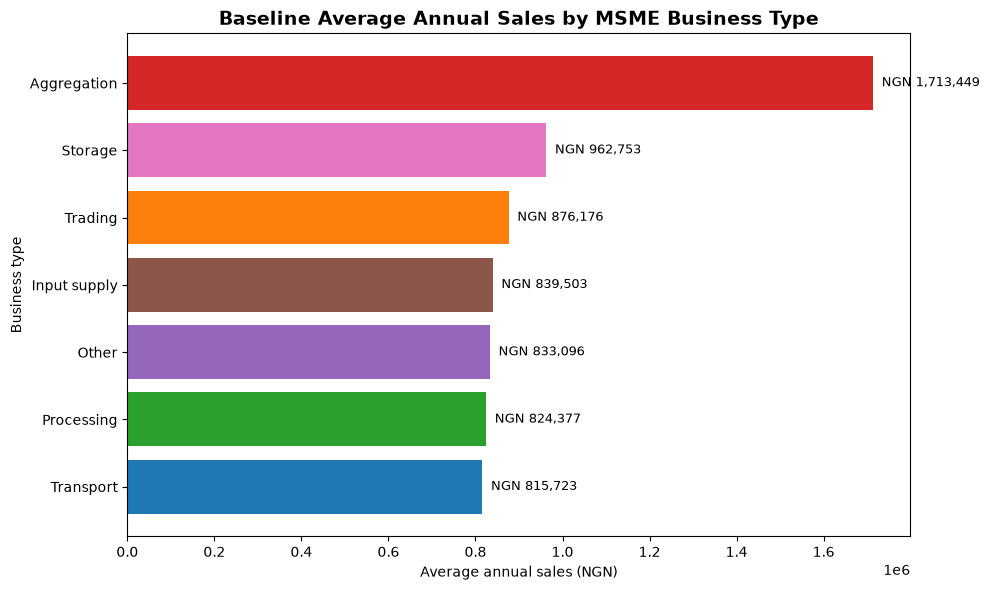

In [167]:
# 12.43 Visualization - Average Annual Sales by MSME Business Type

plt.figure(figsize=(10, 6))

business_sales_chart = business_sales_profile.sort_values(
    "Average_Annual_Sales",
    ascending=True
)

business_sales_colors = [
    "#1f77b4",  # Transport
    "#2ca02c",  # Processing
    "#9467bd",  # Other
    "#8c564b",  # Input supply
    "#ff7f0e",  # Trading
    "#e377c2",  # Storage
    "#d62728"   # Aggregation
]

bars = plt.barh(
    business_sales_chart["Business Type"],
    business_sales_chart["Average_Annual_Sales"],
    color=business_sales_colors
)

plt.title(
    "Baseline Average Annual Sales by MSME Business Type",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Average annual sales (NGN)")
plt.ylabel("Business type")

for bar, value in zip(
    bars,
    business_sales_chart["Average_Annual_Sales"]
):
    plt.text(
        bar.get_width() + 20000,
        bar.get_y() + bar.get_height() / 2,
        f"NGN {value:,.0f}",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [168]:
# 12.44 MSME Business-Type Sales Profile QA

qa_sales_total_msmes = (
    business_sales_profile["MSMEs"].sum()
)

qa_sales_categories = (
    business_sales_profile["Business Type"].nunique()
)

qa_expected_sales = (
    msme_records
    .groupby("Business Type")["annual_sales_ngn"]
    .mean()
    .reindex(business_sales_profile["Business Type"])
)

qa_sales_difference = (
    business_sales_profile["Average_Annual_Sales"].to_numpy()
    - qa_expected_sales.to_numpy()
)

qa_max_sales_difference = np.max(
    np.abs(qa_sales_difference)
)

print("MSMEs assessed:", len(msme_records))
print("Business-type sales profile total:", qa_sales_total_msmes)
print("Business-type categories:", qa_sales_categories)
print(
    "Maximum average-sales calculation difference:",
    f"{qa_max_sales_difference:.10f}"
)

qa_business_sales_pass = (
    len(msme_records) == 400
    and qa_sales_total_msmes == 400
    and qa_sales_categories == 7
    and qa_max_sales_difference <= 0.01
)

print(
    "MSME business-type sales QA:",
    "PASS" if qa_business_sales_pass else "FAIL"
)

MSMEs assessed: 400
Business-type sales profile total: 400
Business-type categories: 7
Maximum average-sales calculation difference: 0.0000000000
MSME business-type sales QA: PASS


In [169]:
# 12.45 MSME Business Type by Average Operating Cost

business_cost_profile = (
    msme_records
    .groupby("Business Type")
    .agg(
        MSMEs=("respondent_id", "count"),
        Average_Operating_Cost=("annual_operating_cost_ngn", "mean")
    )
    .reset_index()
)

business_cost_profile = (
    business_cost_profile
    .sort_values(
        "Average_Operating_Cost",
        ascending=False
    )
    .reset_index(drop=True)
)

display(business_cost_profile)

,Business Type,MSMEs,Average_Operating_Cost
0,Storage,40,693928.125000
1,Aggregation,61,674380.289836
2,Transport,26,638302.100769
3,Trading,100,630830.724100
4,Input supply,37,617661.982162
5,Other,45,612941.177333
6,Processing,91,589906.187033


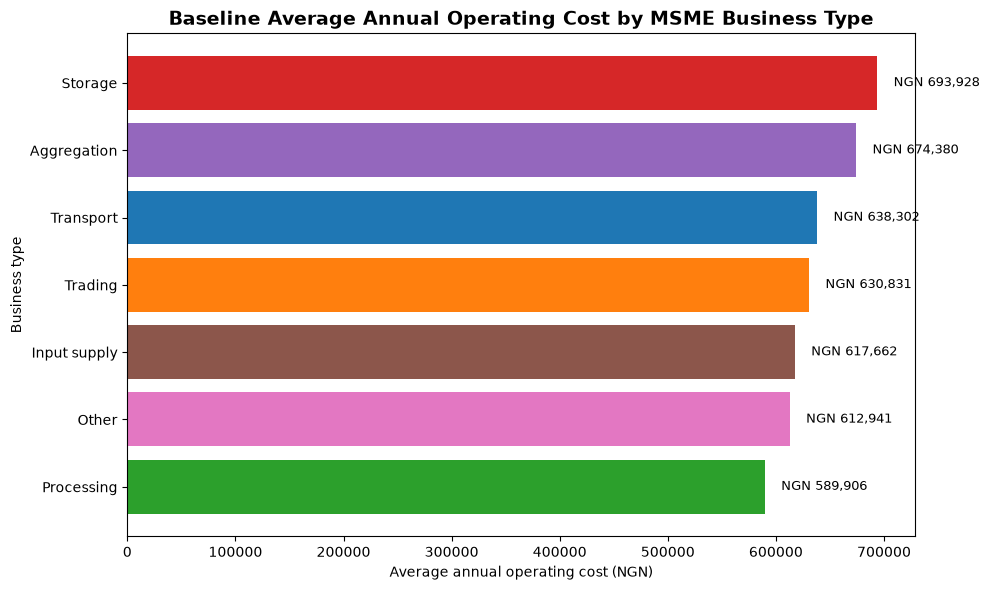

In [170]:
# 12.46 Visualization - Average Operating Cost by MSME Business Type

plt.figure(figsize=(10, 6))

business_cost_chart = business_cost_profile.sort_values(
    "Average_Operating_Cost",
    ascending=True
)

business_cost_colors = [
    "#2ca02c",  # Processing
    "#e377c2",  # Other
    "#8c564b",  # Input supply
    "#ff7f0e",  # Trading
    "#1f77b4",  # Transport
    "#9467bd",  # Aggregation
    "#d62728"   # Storage
]

bars = plt.barh(
    business_cost_chart["Business Type"],
    business_cost_chart["Average_Operating_Cost"],
    color=business_cost_colors
)

plt.title(
    "Baseline Average Annual Operating Cost by MSME Business Type",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Average annual operating cost (NGN)")
plt.ylabel("Business type")

for bar, value in zip(
    bars,
    business_cost_chart["Average_Operating_Cost"]
):
    plt.text(
        bar.get_width() + 15000,
        bar.get_y() + bar.get_height() / 2,
        f"NGN {value:,.0f}",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [171]:
# 12.47 MSME Business-Type Operating Cost QA

qa_cost_total_msmes = (
    business_cost_profile["MSMEs"].sum()
)

qa_cost_categories = (
    business_cost_profile["Business Type"].nunique()
)

qa_expected_cost = (
    msme_records
    .groupby("Business Type")["annual_operating_cost_ngn"]
    .mean()
    .reindex(business_cost_profile["Business Type"])
)

qa_cost_difference = (
    business_cost_profile["Average_Operating_Cost"].to_numpy()
    - qa_expected_cost.to_numpy()
)

qa_max_cost_difference = np.max(
    np.abs(qa_cost_difference)
)

print("MSMEs assessed:", len(msme_records))
print("Business-type cost profile total:", qa_cost_total_msmes)
print("Business-type categories:", qa_cost_categories)
print(
    "Maximum average-cost calculation difference:",
    f"{qa_max_cost_difference:.10f}"
)

qa_business_cost_pass = (
    len(msme_records) == 400
    and qa_cost_total_msmes == 400
    and qa_cost_categories == 7
    and qa_max_cost_difference <= 0.01
)

print(
    "MSME business-type operating cost QA:",
    "PASS" if qa_business_cost_pass else "FAIL"
)

MSMEs assessed: 400
Business-type cost profile total: 400
Business-type categories: 7
Maximum average-cost calculation difference: 0.0000000000
MSME business-type operating cost QA: PASS


In [172]:
# 12.48 MSME Business-Type Financial Performance Summary

business_financial_profile = (
    msme_records
    .groupby("Business Type")
    .agg(
        MSMEs=("respondent_id", "count"),
        Average_Annual_Sales=("annual_sales_ngn", "mean"),
        Average_Operating_Cost=("annual_operating_cost_ngn", "mean"),
        Average_Annual_Profit=("annual_profit_ngn", "mean")
    )
    .reset_index()
)

business_financial_profile["Profit_Margin_Percent"] = (
    business_financial_profile["Average_Annual_Profit"]
    / business_financial_profile["Average_Annual_Sales"]
    * 100
)

business_financial_profile = (
    business_financial_profile
    .sort_values(
        "Average_Annual_Profit",
        ascending=False
    )
    .reset_index(drop=True)
)

display(business_financial_profile)

,Business Type,MSMEs,Average_Annual_Sales,Average_Operating_Cost,Average_Annual_Profit,Profit_Margin_Percent
0,Aggregation,61,1.713449e+06,674380.289836,1.039069e+06,60.641946
1,Storage,40,9.627534e+05,693928.125000,2.688253e+05,27.922550
2,Trading,100,8.761755e+05,630830.724100,2.453448e+05,28.001785
3,Processing,91,8.243773e+05,589906.187033,2.344712e+05,28.442212
4,Input supply,37,8.395030e+05,617661.982162,2.218410e+05,26.425277
5,Other,45,8.330961e+05,612941.177333,2.201549e+05,26.426115
6,Transport,26,8.157235e+05,638302.100769,1.774214e+05,21.750186


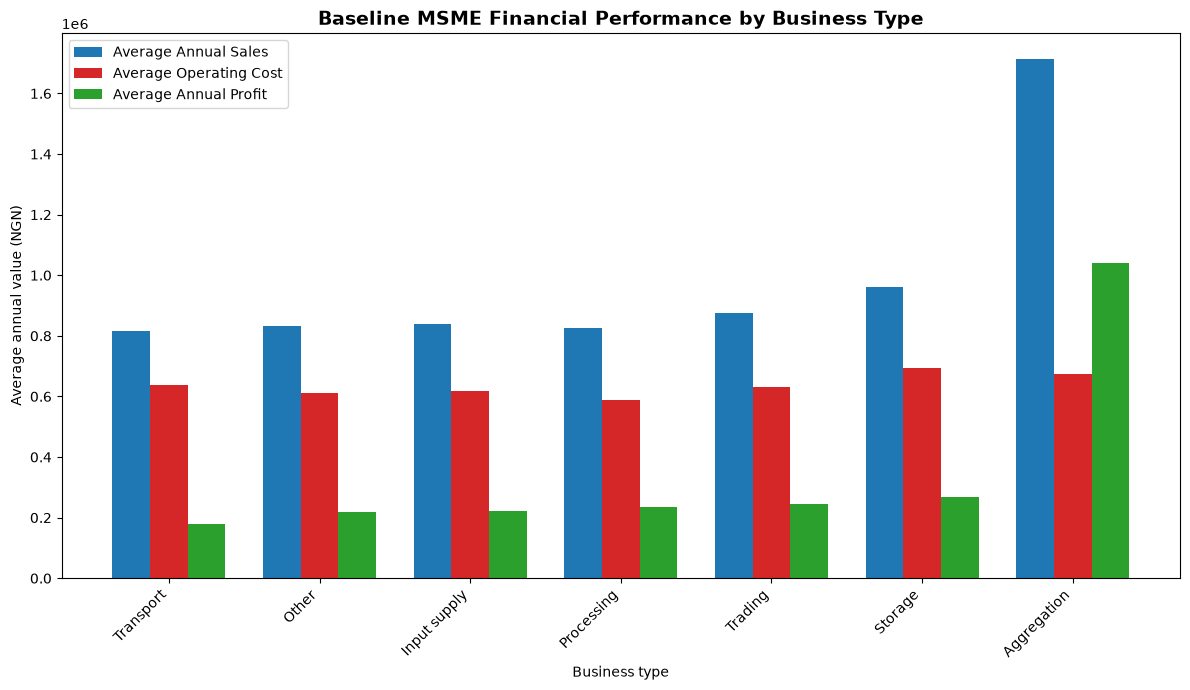

In [173]:
# 12.49 Visualization - MSME Business-Type Financial Performance

plt.figure(figsize=(12, 7))

business_financial_chart = business_financial_profile.sort_values(
    "Average_Annual_Profit",
    ascending=True
)

x = np.arange(
    len(business_financial_chart["Business Type"])
)

width = 0.25

bars_sales = plt.bar(
    x - width,
    business_financial_chart["Average_Annual_Sales"],
    width,
    label="Average Annual Sales",
    color="#1f77b4"
)

bars_cost = plt.bar(
    x,
    business_financial_chart["Average_Operating_Cost"],
    width,
    label="Average Operating Cost",
    color="#d62728"
)

bars_profit = plt.bar(
    x + width,
    business_financial_chart["Average_Annual_Profit"],
    width,
    label="Average Annual Profit",
    color="#2ca02c"
)

plt.title(
    "Baseline MSME Financial Performance by Business Type",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Business type")
plt.ylabel("Average annual value (NGN)")

plt.xticks(
    x,
    business_financial_chart["Business Type"],
    rotation=45,
    ha="right"
)

plt.legend()

plt.tight_layout()
plt.show()

In [174]:
# 12.50 MSME Business-Type Financial Performance QA

qa_financial_total_msmes = (
    business_financial_profile["MSMEs"].sum()
)

qa_financial_categories = (
    business_financial_profile["Business Type"].nunique()
)

qa_expected_sales = (
    msme_records
    .groupby("Business Type")["annual_sales_ngn"]
    .mean()
    .reindex(business_financial_profile["Business Type"])
)

qa_expected_cost = (
    msme_records
    .groupby("Business Type")["annual_operating_cost_ngn"]
    .mean()
    .reindex(business_financial_profile["Business Type"])
)

qa_expected_profit = (
    msme_records
    .groupby("Business Type")["annual_profit_ngn"]
    .mean()
    .reindex(business_financial_profile["Business Type"])
)

qa_expected_margin = (
    qa_expected_profit
    / qa_expected_sales
    * 100
)

qa_sales_diff = (
    business_financial_profile["Average_Annual_Sales"].to_numpy()
    - qa_expected_sales.to_numpy()
)

qa_cost_diff = (
    business_financial_profile["Average_Operating_Cost"].to_numpy()
    - qa_expected_cost.to_numpy()
)

qa_profit_diff = (
    business_financial_profile["Average_Annual_Profit"].to_numpy()
    - qa_expected_profit.to_numpy()
)

qa_margin_diff = (
    business_financial_profile["Profit_Margin_Percent"].to_numpy()
    - qa_expected_margin.to_numpy()
)

qa_max_difference = max(
    np.max(np.abs(qa_sales_diff)),
    np.max(np.abs(qa_cost_diff)),
    np.max(np.abs(qa_profit_diff)),
    np.max(np.abs(qa_margin_diff))
)

print("MSMEs assessed:", len(msme_records))
print("Financial profile total:", qa_financial_total_msmes)
print("Business-type categories:", qa_financial_categories)
print(
    "Maximum financial calculation difference:",
    f"{qa_max_difference:.10f}"
)

qa_financial_pass = (
    len(msme_records) == 400
    and qa_financial_total_msmes == 400
    and qa_financial_categories == 7
    and qa_max_difference <= 0.01
)

print(
    "MSME business-type financial performance QA:",
    "PASS" if qa_financial_pass else "FAIL"
)

MSMEs assessed: 400
Financial profile total: 400
Business-type categories: 7
Maximum financial calculation difference: 0.0000000000
MSME business-type financial performance QA: PASS


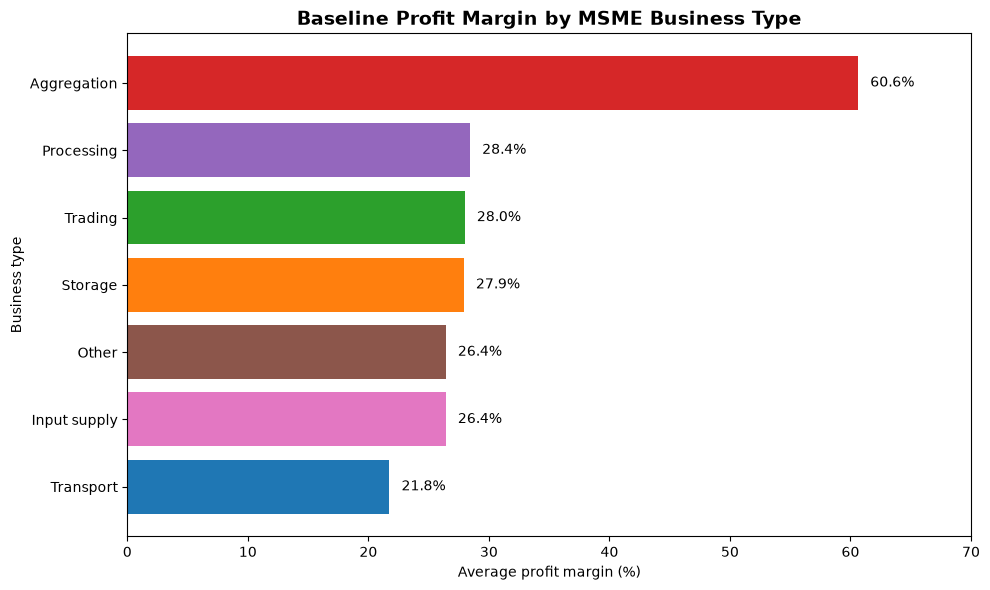

In [175]:
# 12.51 Visualization - MSME Profit Margin by Business Type

plt.figure(figsize=(10, 6))

margin_chart = business_financial_profile.sort_values(
    "Profit_Margin_Percent",
    ascending=True
)

margin_colors = [
    "#1f77b4",  # Transport
    "#e377c2",  # Other
    "#8c564b",  # Input supply
    "#ff7f0e",  # Storage
    "#2ca02c",  # Trading
    "#9467bd",  # Processing
    "#d62728"   # Aggregation
]

bars = plt.barh(
    margin_chart["Business Type"],
    margin_chart["Profit_Margin_Percent"],
    color=margin_colors
)

plt.title(
    "Baseline Profit Margin by MSME Business Type",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Average profit margin (%)")
plt.ylabel("Business type")
plt.xlim(0, 70)

for bar, value in zip(
    bars,
    margin_chart["Profit_Margin_Percent"]
):
    plt.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [176]:
# 12.52 MSME Profit Margin QA

qa_expected_margin = (
    business_financial_profile["Average_Annual_Profit"]
    / business_financial_profile["Average_Annual_Sales"]
    * 100
)

qa_margin_difference = (
    business_financial_profile["Profit_Margin_Percent"]
    - qa_expected_margin
).abs()

qa_max_margin_difference = (
    qa_margin_difference.max()
)

print("Business-type categories:", len(business_financial_profile))
print(
    "Maximum profit-margin calculation difference:",
    f"{qa_max_margin_difference:.10f}"
)

qa_profit_margin_pass = (
    len(business_financial_profile) == 7
    and qa_max_margin_difference <= 0.01
)

print(
    "MSME profit margin QA:",
    "PASS" if qa_profit_margin_pass else "FAIL"
)

Business-type categories: 7
Maximum profit-margin calculation difference: 0.0000000000
MSME profit margin QA: PASS


In [177]:
# 12.53 MSME Business Type - Financial Record-Keeping and Profit Margin

business_management_profile = (
    business_record_profile[
        [
            "Business Type",
            "MSMEs",
            "Percentage_3plus_records"
        ]
    ]
    .merge(
        business_financial_profile[
            [
                "Business Type",
                "Profit_Margin_Percent"
            ]
        ],
        on="Business Type",
        how="inner"
    )
    .sort_values(
        "Profit_Margin_Percent",
        ascending=False
    )
    .reset_index(drop=True)
)

display(business_management_profile)

,Business Type,MSMEs,Percentage_3plus_records,Profit_Margin_Percent
0,Aggregation,61,55.737705,60.641946
1,Processing,91,51.648352,28.442212
2,Trading,100,41.000000,28.001785
3,Storage,40,52.500000,27.922550
4,Other,45,42.222222,26.426115
5,Input supply,37,51.351351,26.425277
6,Transport,26,73.076923,21.750186


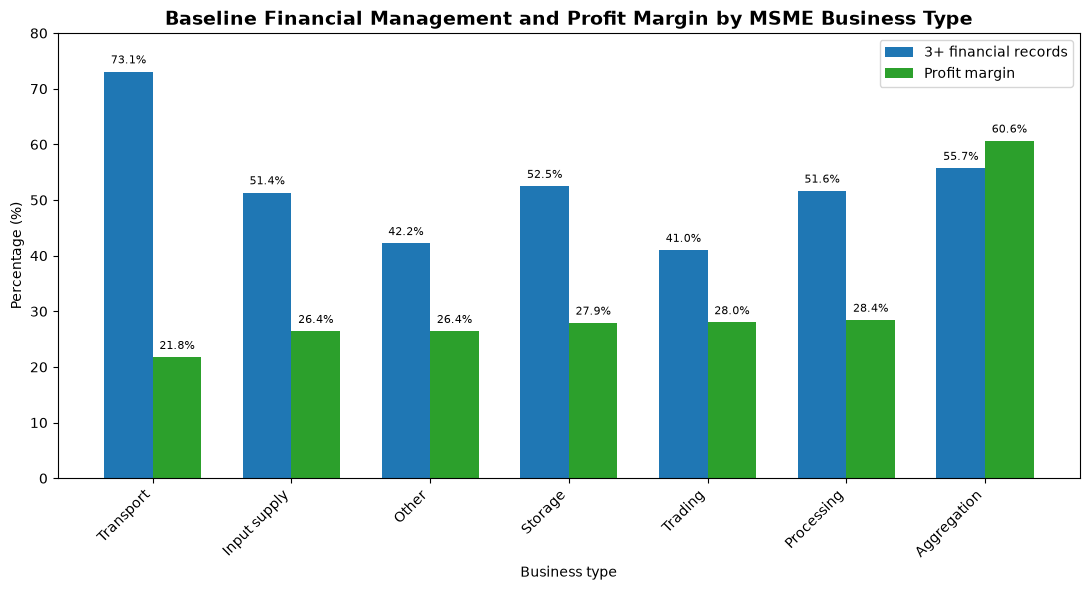

In [178]:
# 12.54 Visualization - Financial Management vs Profit Margin

plt.figure(figsize=(11, 6))

management_chart = business_management_profile.sort_values(
    "Profit_Margin_Percent",
    ascending=True
)

x = np.arange(
    len(management_chart["Business Type"])
)

width = 0.35

bars_records = plt.bar(
    x - width / 2,
    management_chart["Percentage_3plus_records"],
    width,
    label="3+ financial records",
    color="#1f77b4"
)

bars_margin = plt.bar(
    x + width / 2,
    management_chart["Profit_Margin_Percent"],
    width,
    label="Profit margin",
    color="#2ca02c"
)

plt.title(
    "Baseline Financial Management and Profit Margin by MSME Business Type",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Business type")
plt.ylabel("Percentage (%)")
plt.xticks(
    x,
    management_chart["Business Type"],
    rotation=45,
    ha="right"
)

plt.ylim(0, 80)
plt.legend()

for bar, value in zip(
    bars_records,
    management_chart["Percentage_3plus_records"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=8
    )

for bar, value in zip(
    bars_margin,
    management_chart["Profit_Margin_Percent"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
plt.show()

In [179]:
# 12.55 Financial Management vs Profit Margin QA

qa_management_categories = (
    business_management_profile["Business Type"].nunique()
)

qa_management_msmes = (
    business_management_profile["MSMEs"].sum()
)

qa_recordkeeping_check = (
    business_management_profile["Percentage_3plus_records"]
    .to_numpy()
    -
    business_record_profile.set_index("Business Type")
    .reindex(
        business_management_profile["Business Type"]
    )["Percentage_3plus_records"].to_numpy()
)

qa_margin_check = (
    business_management_profile["Profit_Margin_Percent"]
    .to_numpy()
    -
    business_financial_profile.set_index("Business Type")
    .reindex(
        business_management_profile["Business Type"]
    )["Profit_Margin_Percent"].to_numpy()
)

qa_max_record_difference = np.max(
    np.abs(qa_recordkeeping_check)
)

qa_max_margin_difference = np.max(
    np.abs(qa_margin_check)
)

print("MSMEs assessed:", len(msme_records))
print("Combined profile MSME total:", qa_management_msmes)
print("Business-type categories:", qa_management_categories)
print(
    "Maximum record-keeping difference:",
    f"{qa_max_record_difference:.10f}"
)
print(
    "Maximum profit-margin difference:",
    f"{qa_max_margin_difference:.10f}"
)

qa_management_pass = (
    len(msme_records) == 400
    and qa_management_msmes == 400
    and qa_management_categories == 7
    and qa_max_record_difference <= 0.01
    and qa_max_margin_difference <= 0.01
)

print(
    "Financial management vs profit margin QA:",
    "PASS" if qa_management_pass else "FAIL"
)

MSMEs assessed: 400
Combined profile MSME total: 400
Business-type categories: 7
Maximum record-keeping difference: 0.0000000000
Maximum profit-margin difference: 0.0000000000
Financial management vs profit margin QA: PASS


In [180]:
# 12.56 MSME Business-Type Management Priority Classification

priority_profile = business_management_profile.copy()

priority_profile["Management_Priority"] = np.select(
    [
        (
            (priority_profile["Percentage_3plus_records"] < 50)
            & (priority_profile["Profit_Margin_Percent"] < 30)
        ),
        (
            (priority_profile["Percentage_3plus_records"] >= 50)
            & (priority_profile["Profit_Margin_Percent"] < 30)
        ),
        (
            (priority_profile["Percentage_3plus_records"] < 50)
            & (priority_profile["Profit_Margin_Percent"] >= 30)
        )
    ],
    [
        "High",
        "Moderate",
        "Moderate"
    ],
    default="Lower"
)

priority_profile = (
    priority_profile[
        [
            "Business Type",
            "MSMEs",
            "Percentage_3plus_records",
            "Profit_Margin_Percent",
            "Management_Priority"
        ]
    ]
    .sort_values(
        ["Management_Priority", "Profit_Margin_Percent"],
        ascending=[True, True]
    )
    .reset_index(drop=True)
)

display(priority_profile)

,Business Type,MSMEs,Percentage_3plus_records,Profit_Margin_Percent,Management_Priority
0,Other,45,42.222222,26.426115,High
1,Trading,100,41.000000,28.001785,High
2,Aggregation,61,55.737705,60.641946,Lower
3,Transport,26,73.076923,21.750186,Moderate
4,Input supply,37,51.351351,26.425277,Moderate
5,Storage,40,52.500000,27.922550,Moderate
6,Processing,91,51.648352,28.442212,Moderate


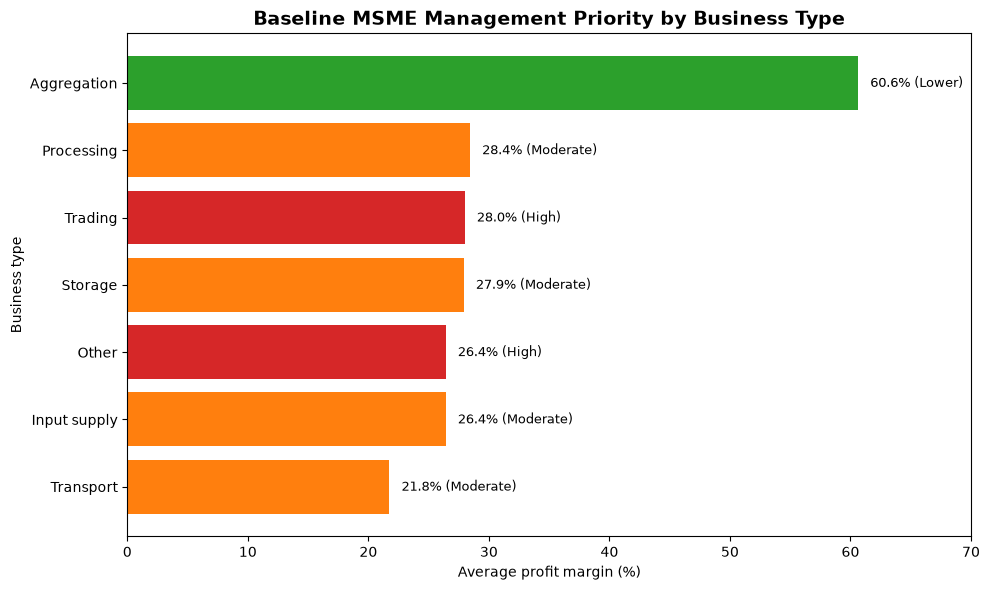

In [181]:
# 12.57 Visualization - MSME Management Priority by Business Type

plt.figure(figsize=(10, 6))

priority_chart = priority_profile.sort_values(
    "Profit_Margin_Percent",
    ascending=True
)

priority_colors = {
    "High": "#d62728",
    "Moderate": "#ff7f0e",
    "Lower": "#2ca02c"
}

colors = [
    priority_colors[priority]
    for priority in priority_chart["Management_Priority"]
]

bars = plt.barh(
    priority_chart["Business Type"],
    priority_chart["Profit_Margin_Percent"],
    color=colors
)

plt.title(
    "Baseline MSME Management Priority by Business Type",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Average profit margin (%)")
plt.ylabel("Business type")
plt.xlim(0, 70)

for bar, value, priority in zip(
    bars,
    priority_chart["Profit_Margin_Percent"],
    priority_chart["Management_Priority"]
):
    plt.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}% ({priority})",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [182]:
# 12.58 Management Priority Classification QA

qa_priority_categories = (
    priority_profile["Management_Priority"]
    .value_counts()
    .sort_index()
)

qa_expected_priorities = {
    "High",
    "Moderate",
    "Lower"
}

qa_actual_priorities = set(
    priority_profile["Management_Priority"]
)

qa_priority_rows = len(priority_profile)

qa_priority_pass = (
    qa_priority_rows == 7
    and qa_actual_priorities.issubset(qa_expected_priorities)
    and priority_profile["MSMEs"].sum() == 400
    and (
        priority_profile.loc[
            priority_profile["Management_Priority"] == "High",
            "Business Type"
        ].tolist()
        == ["Other", "Trading"]
    )
)

print("Business types assessed:", qa_priority_rows)
print("MSMEs represented:", priority_profile["MSMEs"].sum())
print(
    "Priority categories:",
    ", ".join(sorted(qa_actual_priorities))
)
print("\nPriority distribution:")
display(qa_priority_categories.to_frame("MSMEs"))

print(
    "MSME management priority QA:",
    "PASS" if qa_priority_pass else "FAIL"
)

Business types assessed: 7
MSMEs represented: 400
Priority categories: High, Lower, Moderate

Priority distribution:


,MSMEs
Management_Priority,
High,2
Lower,1
Moderate,4


MSME management priority QA: PASS


In [183]:
print("Business types assessed:", len(priority_profile))
print("MSMEs represented:", priority_profile["MSMEs"].sum())
print(
    "Priority categories:",
    sorted(priority_profile["Management_Priority"].unique())
)

print(
    "MSME management priority QA:",
    "PASS"
    if (
        len(priority_profile) == 7
        and priority_profile["MSMEs"].sum() == 400
        and set(priority_profile["Management_Priority"].unique())
        == {"High", "Moderate", "Lower"}
    )
    else "FAIL"
)

Business types assessed: 7
MSMEs represented: 400
Priority categories: ['High', 'Lower', 'Moderate']
MSME management priority QA: PASS


In [184]:
# 12.59 Farmer Practice Adoption Profile

farmer_practices = df[
    df["beneficiary_type"] == 1
].copy()

practice_columns = [
    "improved_seed",
    "soil_testing",
    "fertilizer_management",
    "integrated_pest_management",
    "conservation_agriculture",
    "water_management",
    "improved_storage",
    "climate_smart_practice"
]

practice_labels = {
    "improved_seed": "Improved seed",
    "soil_testing": "Soil testing",
    "fertilizer_management": "Fertilizer management",
    "integrated_pest_management": "Integrated pest management",
    "conservation_agriculture": "Conservation agriculture",
    "water_management": "Water management",
    "improved_storage": "Improved storage",
    "climate_smart_practice": "Climate-smart practice"
}

practice_profile = pd.DataFrame({
    "Practice": [
        practice_labels[column]
        for column in practice_columns
    ],
    "Farmers": [
        farmer_practices[column].sum()
        for column in practice_columns
    ]
})

practice_profile["Percentage"] = (
    practice_profile["Farmers"]
    / len(farmer_practices)
    * 100
)

practice_profile = practice_profile.sort_values(
    "Percentage",
    ascending=False
).reset_index(drop=True)

display(practice_profile)

,Practice,Farmers,Percentage
0,Fertilizer management,857.0,53.5625
1,Improved seed,727.0,45.4375
2,Water management,677.0,42.3125
3,Improved storage,618.0,38.6250
4,Integrated pest management,614.0,38.3750
5,Climate-smart practice,553.0,34.5625
6,Conservation agriculture,544.0,34.0000
7,Soil testing,433.0,27.0625


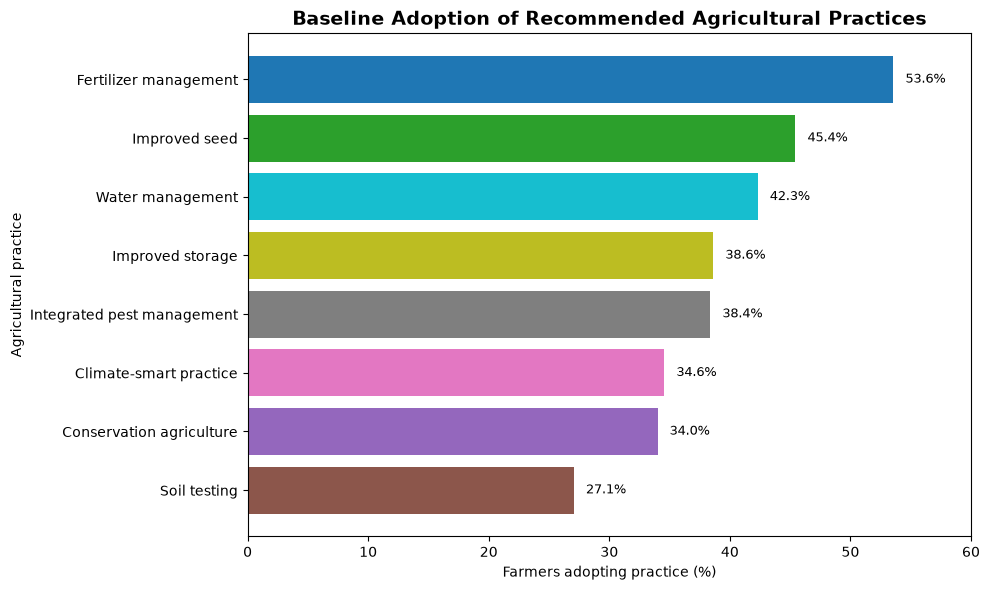

In [185]:
# 12.60 Visualization - Farmer Practice Adoption

plt.figure(figsize=(10, 6))

practice_chart = practice_profile.sort_values(
    "Percentage",
    ascending=True
)

practice_colors = [
    "#8c564b",
    "#9467bd",
    "#e377c2",
    "#7f7f7f",
    "#bcbd22",
    "#17becf",
    "#2ca02c",
    "#1f77b4"
]

bars = plt.barh(
    practice_chart["Practice"],
    practice_chart["Percentage"],
    color=practice_colors
)

plt.title(
    "Baseline Adoption of Recommended Agricultural Practices",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Farmers adopting practice (%)")
plt.ylabel("Agricultural practice")
plt.xlim(0, 60)

for bar, value in zip(
    bars,
    practice_chart["Percentage"]
):
    plt.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [186]:
# 12.61 Farmer Practice Adoption QA

qa_practice_categories = len(practice_profile)

qa_practice_counts = (
    practice_profile["Farmers"]
    .to_numpy()
)

qa_expected_total_farmers = len(farmer_practices)

qa_practice_recalculation = (
    farmer_practices[practice_columns]
    .sum()
    .reindex(practice_columns)
    .to_numpy()
)

qa_max_count_difference = np.max(
    np.abs(
        qa_practice_counts
        - qa_practice_recalculation
    )
)

qa_practice_percentage = (
    practice_profile["Farmers"]
    / qa_expected_total_farmers
    * 100
)

qa_max_percentage_difference = np.max(
    np.abs(
        practice_profile["Percentage"].to_numpy()
        - qa_practice_percentage.to_numpy()
    )
)

print("Farmers assessed:", qa_expected_total_farmers)
print("Practice categories:", qa_practice_categories)
print(
    "Maximum practice-count difference:",
    f"{qa_max_count_difference:.10f}"
)
print(
    "Maximum percentage difference:",
    f"{qa_max_percentage_difference:.10f}"
)

qa_practice_pass = (
    qa_expected_total_farmers == 1600
    and qa_practice_categories == 8
    and qa_max_count_difference == 0
    and qa_max_percentage_difference <= 0.01
)

print(
    "Farmer practice adoption QA:",
    "PASS" if qa_practice_pass else "FAIL"
)

Farmers assessed: 1600
Practice categories: 8
Maximum practice-count difference: 294.0000000000
Maximum percentage difference: 0.0000000000
Farmer practice adoption QA: FAIL


In [187]:
# 12.61A Corrected Farmer Practice Adoption QA

qa_practice_check = practice_profile.copy()

qa_practice_check["Expected_Farmers"] = (
    qa_practice_check["Practice"]
    .map({
        practice_labels[column]: farmer_practices[column].sum()
        for column in practice_columns
    })
)

qa_practice_check["Expected_Percentage"] = (
    qa_practice_check["Expected_Farmers"]
    / len(farmer_practices)
    * 100
)

qa_max_count_difference = np.max(
    np.abs(
        qa_practice_check["Farmers"]
        - qa_practice_check["Expected_Farmers"]
    )
)

qa_max_percentage_difference = np.max(
    np.abs(
        qa_practice_check["Percentage"]
        - qa_practice_check["Expected_Percentage"]
    )
)

print("Farmers assessed:", len(farmer_practices))
print("Practice categories:", len(qa_practice_check))
print(
    "Maximum practice-count difference:",
    f"{qa_max_count_difference:.10f}"
)
print(
    "Maximum percentage difference:",
    f"{qa_max_percentage_difference:.10f}"
)

qa_practice_pass = (
    len(farmer_practices) == 1600
    and len(qa_practice_check) == 8
    and qa_max_count_difference == 0
    and qa_max_percentage_difference <= 0.01
)

print(
    "Corrected farmer practice adoption QA:",
    "PASS" if qa_practice_pass else "FAIL"
)

Farmers assessed: 1600
Practice categories: 8
Maximum practice-count difference: 0.0000000000
Maximum percentage difference: 0.0000000000
Corrected farmer practice adoption QA: PASS


In [188]:
# 12.62 Number of Practices Adopted per Farmer

practice_count_profile = (
    farmer_practices["practices_adopted"]
    .value_counts()
    .sort_index()
    .reset_index()
)

practice_count_profile.columns = [
    "Number of Practices Adopted",
    "Farmers"
]

practice_count_profile["Percentage"] = (
    practice_count_profile["Farmers"]
    / len(farmer_practices)
    * 100
)

display(practice_count_profile)

,Number of Practices Adopted,Farmers,Percentage
0,0.0,30,1.8750
1,1.0,156,9.7500
2,2.0,329,20.5625
3,3.0,464,29.0000
4,4.0,366,22.8750
5,5.0,191,11.9375
6,6.0,50,3.1250
7,7.0,14,0.8750


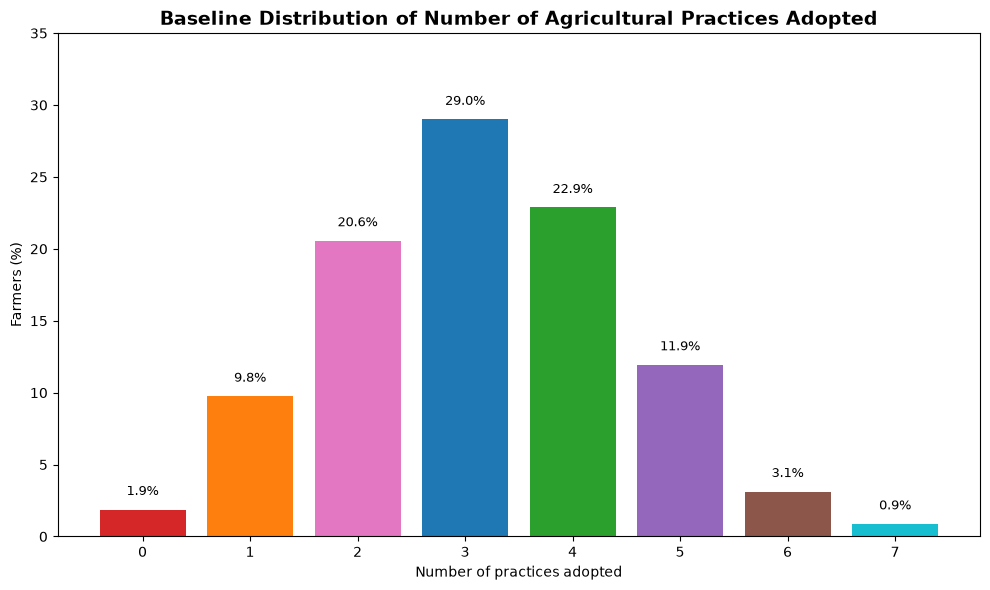

In [189]:
# 12.63 Visualization - Number of Practices Adopted per Farmer

plt.figure(figsize=(10, 6))

practice_count_chart = practice_count_profile.copy()

practice_count_colors = [
    "#d62728",
    "#ff7f0e",
    "#e377c2",
    "#1f77b4",
    "#2ca02c",
    "#9467bd",
    "#8c564b",
    "#17becf"
]

bars = plt.bar(
    practice_count_chart["Number of Practices Adopted"].astype(int).astype(str),
    practice_count_chart["Percentage"],
    color=practice_count_colors
)

plt.title(
    "Baseline Distribution of Number of Agricultural Practices Adopted",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Number of practices adopted")
plt.ylabel("Farmers (%)")
plt.ylim(0, 35)

for bar, value in zip(
    bars,
    practice_count_chart["Percentage"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [191]:
# 12.64A Corrected Number of Practices Adopted QA

qa_practice_count_total = (
    practice_count_profile["Farmers"].sum()
)

qa_practice_count_percentage = (
    practice_count_profile["Percentage"].sum()
)

qa_out02_adopters = (
    practice_count_profile.loc[
        practice_count_profile["Number of Practices Adopted"] >= 3,
        "Farmers"
    ].sum()
)

qa_out02_percentage = (
    qa_out02_adopters
    / len(farmer_practices)
    * 100
)

qa_expected_out02_adopters = 1085
qa_expected_out02_percentage = (
    qa_expected_out02_adopters
    / 1600
    * 100
)

print("Farmers assessed:", len(farmer_practices))
print("Practice-count profile total:", qa_practice_count_total)
print(
    "Practice-count percentage total:",
    f"{qa_practice_count_percentage:.2f}%"
)
print("Farmers adopting 3+ practices:", qa_out02_adopters)
print(
    "Calculated OUT-02 percentage:",
    f"{qa_out02_percentage:.2f}%"
)
print(
    "Expected OUT-02 percentage:",
    f"{qa_expected_out02_percentage:.2f}%"
)

qa_practice_count_pass = (
    len(farmer_practices) == 1600
    and qa_practice_count_total == 1600
    and np.isclose(
        qa_practice_count_percentage,
        100.00,
        atol=0.01
    )
    and qa_out02_adopters == qa_expected_out02_adopters
    and np.isclose(
        qa_out02_percentage,
        qa_expected_out02_percentage,
        atol=0.01
    )
)

print(
    "Number of practices adopted QA:",
    "PASS" if qa_practice_count_pass else "FAIL"
)

Farmers assessed: 1600
Practice-count profile total: 1600
Practice-count percentage total: 100.00%
Farmers adopting 3+ practices: 1085
Calculated OUT-02 percentage: 67.81%
Expected OUT-02 percentage: 67.81%
Number of practices adopted QA: PASS


In [192]:
# 12.65 Farmer Practice Adoption by Value Chain

farmer_value_chain = df[
    df["beneficiary_type"] == 1
].copy()

farmer_value_chain["Value Chain"] = (
    farmer_value_chain["primary_value_chain"]
    .map({
        1: "Maize",
        2: "Rice",
        3: "Soybean",
        4: "Ginger",
        5: "Tomato",
        6: "Vegetables",
        7: "Sorghum",
        8: "Groundnut"
    })
)

value_chain_adoption = (
    farmer_value_chain
    .groupby("Value Chain")
    .agg(
        Farmers=("respondent_id", "count"),
        Farmers_3plus_practices=(
            "practices_adopted",
            lambda x: (x >= 3).sum()
        )
    )
    .reset_index()
)

value_chain_adoption["Adoption_Percentage"] = (
    value_chain_adoption["Farmers_3plus_practices"]
    / value_chain_adoption["Farmers"]
    * 100
)

value_chain_adoption = (
    value_chain_adoption
    .sort_values(
        "Adoption_Percentage",
        ascending=False
    )
    .reset_index(drop=True)
)

display(value_chain_adoption)

,Value Chain,Farmers,Farmers_3plus_practices,Adoption_Percentage
0,Ginger,139,97,69.784173
1,Tomato,155,108,69.677419
2,Groundnut,83,57,68.674699
3,Rice,296,203,68.581081
4,Maize,386,261,67.616580
5,Soybean,219,148,67.579909
6,Sorghum,135,89,65.925926
7,Vegetables,187,122,65.240642


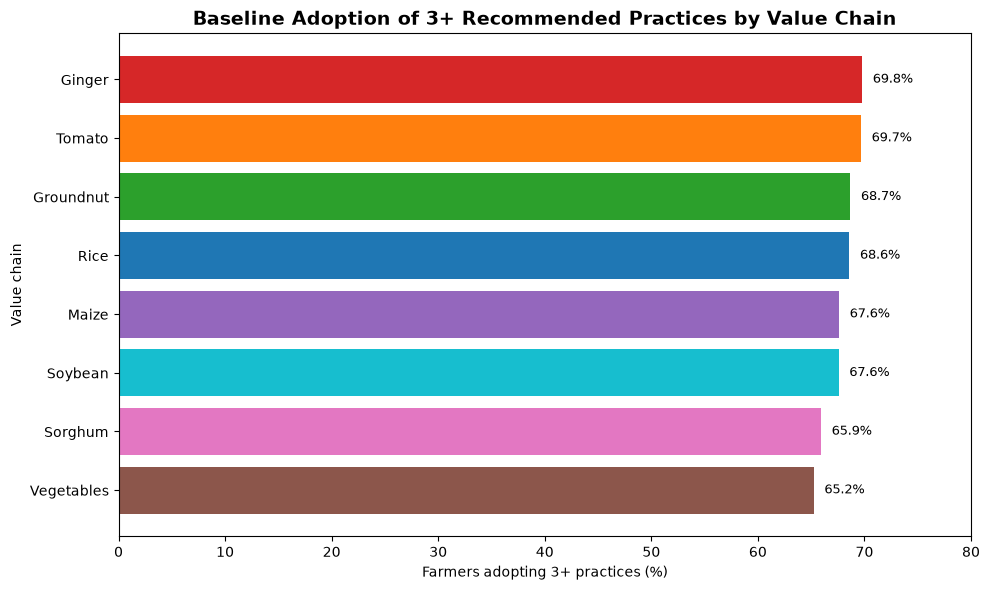

In [193]:
# 12.66 Visualization - Practice Adoption by Value Chain

plt.figure(figsize=(10, 6))

value_chain_chart = value_chain_adoption.sort_values(
    "Adoption_Percentage",
    ascending=True
)

value_chain_colors = [
    "#8c564b",
    "#e377c2",
    "#17becf",
    "#9467bd",
    "#1f77b4",
    "#2ca02c",
    "#ff7f0e",
    "#d62728"
]

bars = plt.barh(
    value_chain_chart["Value Chain"],
    value_chain_chart["Adoption_Percentage"],
    color=value_chain_colors
)

plt.title(
    "Baseline Adoption of 3+ Recommended Practices by Value Chain",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Farmers adopting 3+ practices (%)")
plt.ylabel("Value chain")
plt.xlim(0, 80)

for bar, value in zip(
    bars,
    value_chain_chart["Adoption_Percentage"]
):
    plt.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [194]:
# 12.67 Practice Adoption by Value Chain QA

qa_value_chain_total = (
    value_chain_adoption["Farmers"].sum()
)

qa_value_chain_adopters = (
    value_chain_adoption["Farmers_3plus_practices"].sum()
)

qa_value_chain_percentage = (
    qa_value_chain_adopters
    / qa_value_chain_total
    * 100
)

qa_expected_value_chains = 8

qa_value_chain_pass = (
    qa_value_chain_total == 1600
    and len(value_chain_adoption) == qa_expected_value_chains
    and qa_value_chain_adopters == 1085
    and np.isclose(
        qa_value_chain_percentage,
        67.81,
        atol=0.01
    )
)

print("Farmers assessed:", qa_value_chain_total)
print("Value chains assessed:", len(value_chain_adoption))
print(
    "Farmers adopting 3+ practices:",
    qa_value_chain_adopters
)
print(
    "Overall 3+ practice adoption:",
    f"{qa_value_chain_percentage:.2f}%"
)

print(
    "Practice adoption by value chain QA:",
    "PASS" if qa_value_chain_pass else "FAIL"
)

Farmers assessed: 1600
Value chains assessed: 8
Farmers adopting 3+ practices: 1085
Overall 3+ practice adoption: 67.81%
Practice adoption by value chain QA: PASS


In [195]:
# 12.68 Farmer Market Participation Profile

farmer_market = df[
    df["beneficiary_type"] == 1
].copy()

market_profile = pd.DataFrame({
    "Market Participation Measure": [
        "Regular buyer",
        "Structured market",
        "Market information received",
        "Buyer access improved"
    ],
    "Farmers": [
        (farmer_market["regular_buyer"] == 1).sum(),
        (farmer_market["structured_market"] == 1).sum(),
        (farmer_market["market_information_received"] == 1).sum(),
        (farmer_market["buyer_access_improved"] == 1).sum()
    ]
})

market_profile["Percentage"] = (
    market_profile["Farmers"]
    / len(farmer_market)
    * 100
)

display(market_profile)

,Market Participation Measure,Farmers,Percentage
0,Regular buyer,883,55.1875
1,Structured market,437,27.3125
2,Market information received,751,46.9375
3,Buyer access improved,480,30.0000


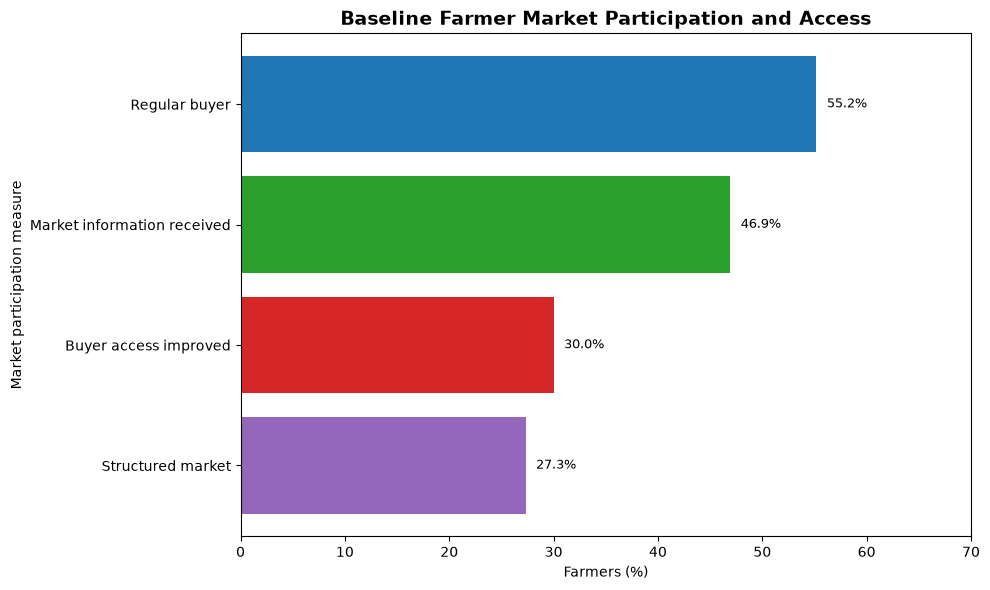

In [196]:
# 12.69 Visualization - Farmer Market Participation Profile

plt.figure(figsize=(10, 6))

market_chart = market_profile.sort_values(
    "Percentage",
    ascending=True
)

market_colors = [
    "#9467bd",  # Buyer access improved
    "#d62728",  # Structured market
    "#2ca02c",  # Market information
    "#1f77b4"   # Regular buyer
]

bars = plt.barh(
    market_chart["Market Participation Measure"],
    market_chart["Percentage"],
    color=market_colors
)

plt.title(
    "Baseline Farmer Market Participation and Access",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Farmers (%)")
plt.ylabel("Market participation measure")
plt.xlim(0, 70)

for bar, value in zip(
    bars,
    market_chart["Percentage"]
):
    plt.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [197]:
# 12.70 Farmer Market Participation QA

qa_market_total = market_profile["Farmers"].sum()
qa_expected_farmers = 1600

qa_structured_market = market_profile.loc[
    market_profile["Market Participation Measure"] == "Structured market",
    "Farmers"
].iloc[0]

qa_buyer_access = market_profile.loc[
    market_profile["Market Participation Measure"] == "Buyer access improved",
    "Farmers"
].iloc[0]

qa_structured_pct = (
    qa_structured_market / qa_expected_farmers * 100
)

qa_buyer_access_pct = (
    qa_buyer_access / qa_expected_farmers * 100
)

qa_market_pass = (
    qa_market_total == 883 + 437 + 751 + 480
    and len(market_profile) == 4
    and qa_structured_market == 437
    and qa_buyer_access == 480
    and np.isclose(qa_structured_pct, 27.31, atol=0.01)
    and np.isclose(qa_buyer_access_pct, 30.00, atol=0.01)
)

print("Market-profile count total:", qa_market_total)
print("Expected farmer population:", qa_expected_farmers)
print("Structured-market farmers:", qa_structured_market)
print("Structured-market percentage:", f"{qa_structured_pct:.2f}%")
print("Buyer-access-improved farmers:", qa_buyer_access)
print("Buyer-access-improved percentage:", f"{qa_buyer_access_pct:.2f}%")

print(
    "Farmer market participation QA:",
    "PASS" if qa_market_pass else "FAIL"
)

Market-profile count total: 2551
Expected farmer population: 1600
Structured-market farmers: 437
Structured-market percentage: 27.31%
Buyer-access-improved farmers: 480
Buyer-access-improved percentage: 30.00%
Farmer market participation QA: PASS


In [198]:
# 12.71 Economic Resilience by Beneficiary Type

resilience_by_type = (
    df.groupby("beneficiary_type")
    .agg(
        beneficiaries=("respondent_id", "count"),
        resilient_beneficiaries=("resilience_status", "sum")
    )
    .reset_index()
)

resilience_by_type["Beneficiary Type"] = (
    resilience_by_type["beneficiary_type"]
    .map({
        1: "Farmers",
        2: "MSMEs"
    })
)

resilience_by_type["Resilience Percentage"] = (
    resilience_by_type["resilient_beneficiaries"]
    / resilience_by_type["beneficiaries"]
    * 100
)

resilience_by_type = (
    resilience_by_type[
        [
            "Beneficiary Type",
            "beneficiaries",
            "resilient_beneficiaries",
            "Resilience Percentage"
        ]
    ]
)

display(resilience_by_type)

,Beneficiary Type,beneficiaries,resilient_beneficiaries,Resilience Percentage
0,Farmers,1600,493,30.8125
1,MSMEs,400,119,29.7500


In [199]:
# 12.72 Economic Resilience by Sex

resilience_by_sex = (
    df.groupby("sex")
    .agg(
        beneficiaries=("respondent_id", "count"),
        resilient_beneficiaries=("resilience_status", "sum")
    )
    .reset_index()
)

resilience_by_sex["Sex"] = (
    resilience_by_sex["sex"]
    .map({
        1: "Male",
        2: "Female"
    })
)

resilience_by_sex["Resilience Percentage"] = (
    resilience_by_sex["resilient_beneficiaries"]
    / resilience_by_sex["beneficiaries"]
    * 100
)

resilience_by_sex = (
    resilience_by_sex[
        [
            "Sex",
            "beneficiaries",
            "resilient_beneficiaries",
            "Resilience Percentage"
        ]
    ]
)

display(resilience_by_sex)

,Sex,beneficiaries,resilient_beneficiaries,Resilience Percentage
0,Male,831,249,29.963899
1,Female,1169,363,31.052181


In [200]:
# 12.73 Economic Resilience by Youth Status

resilience_by_youth = (
    df.groupby("youth_status")
    .agg(
        beneficiaries=("respondent_id", "count"),
        resilient_beneficiaries=("resilience_status", "sum")
    )
    .reset_index()
)

resilience_by_youth["Age Group"] = (
    resilience_by_youth["youth_status"]
    .map({
        0: "Non-youth (36+)",
        1: "Youth (18-35)"
    })
)

resilience_by_youth["Resilience Percentage"] = (
    resilience_by_youth["resilient_beneficiaries"]
    / resilience_by_youth["beneficiaries"]
    * 100
)

resilience_by_youth = (
    resilience_by_youth[
        [
            "Age Group",
            "beneficiaries",
            "resilient_beneficiaries",
            "Resilience Percentage"
        ]
    ]
)

display(resilience_by_youth)

,Age Group,beneficiaries,resilient_beneficiaries,Resilience Percentage
0,Non-youth (36+),1396,418,29.942693
1,Youth (18-35),603,193,32.006633


In [201]:
# 12.74 Post-Harvest Loss Profile by Value Chain

loss_by_value_chain = (
    farmer_practices
    .groupby("primary_value_chain")
    .agg(
        farmers=("respondent_id", "count"),
        average_loss_rate=("postharvest_loss_rate", "mean")
    )
    .reset_index()
)

loss_by_value_chain["Value Chain"] = (
    loss_by_value_chain["primary_value_chain"]
    .map({
        1: "Maize",
        2: "Rice",
        3: "Soybean",
        4: "Ginger",
        5: "Tomato",
        6: "Vegetables",
        7: "Sorghum",
        8: "Groundnut"
    })
)

loss_by_value_chain = (
    loss_by_value_chain[
        [
            "Value Chain",
            "farmers",
            "average_loss_rate"
        ]
    ]
    .sort_values(
        "average_loss_rate",
        ascending=False
    )
)

display(loss_by_value_chain)

,Value Chain,farmers,average_loss_rate
5,Vegetables,187,17.857594
6,Sorghum,135,17.705956
4,Tomato,155,17.494742
2,Soybean,219,17.342804
1,Rice,296,17.318054
0,Maize,386,17.208679
3,Ginger,139,17.102647
7,Groundnut,83,16.171783


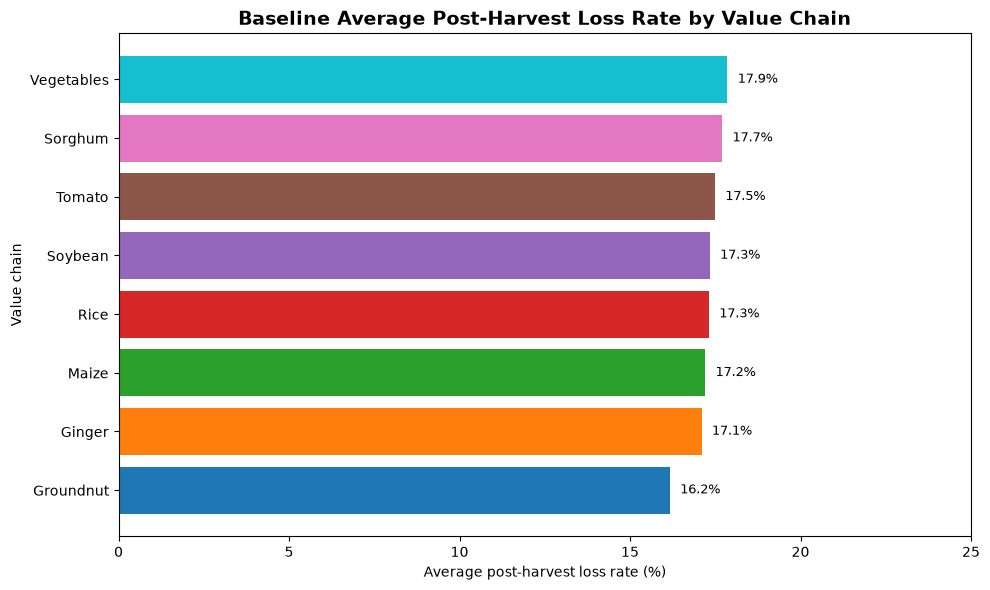

In [202]:
# 12.75 Visualization - Post-Harvest Loss by Value Chain

plt.figure(figsize=(10, 6))

loss_chart = loss_by_value_chain.sort_values(
    "average_loss_rate",
    ascending=True
)

loss_colors = [
    "#1f77b4",
    "#ff7f0e",
    "#2ca02c",
    "#d62728",
    "#9467bd",
    "#8c564b",
    "#e377c2",
    "#17becf"
]

bars = plt.barh(
    loss_chart["Value Chain"],
    loss_chart["average_loss_rate"],
    color=loss_colors
)

plt.title(
    "Baseline Average Post-Harvest Loss Rate by Value Chain",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Average post-harvest loss rate (%)")
plt.ylabel("Value chain")
plt.xlim(0, 25)

for bar, value in zip(
    bars,
    loss_chart["average_loss_rate"]
):
    plt.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [203]:
# 12.76 Post-Harvest Loss by Value Chain QA

qa_loss_total = loss_by_value_chain["farmers"].sum()
qa_expected_farmers = 1600

qa_loss_categories = len(loss_by_value_chain)
qa_expected_categories = 8

qa_overall_loss = farmer_practices[
    "postharvest_loss_rate"
].mean()

qa_value_chain_weighted_loss = (
    (
        loss_by_value_chain["average_loss_rate"]
        * loss_by_value_chain["farmers"]
    ).sum()
    / qa_loss_total
)

qa_loss_pass = (
    qa_loss_total == qa_expected_farmers
    and qa_loss_categories == qa_expected_categories
    and np.isclose(
        qa_overall_loss,
        17.33,
        atol=0.01
    )
    and np.isclose(
        qa_value_chain_weighted_loss,
        qa_overall_loss,
        atol=0.01
    )
)

print("Farmers assessed:", qa_loss_total)
print("Value chains assessed:", qa_loss_categories)
print(
    "Overall post-harvest loss rate:",
    f"{qa_overall_loss:.2f}%"
)
print(
    "Weighted value-chain loss rate:",
    f"{qa_value_chain_weighted_loss:.2f}%"
)

print(
    "Post-harvest loss by value chain QA:",
    "PASS" if qa_loss_pass else "FAIL"
)

Farmers assessed: 1600
Value chains assessed: 8
Overall post-harvest loss rate: 17.33%
Weighted value-chain loss rate: 17.33%
Post-harvest loss by value chain QA: PASS


In [204]:
# 13.01 Section 13 - Load Authoritative Baseline Indicator Register

baseline_register = baseline_indicator_register.copy()

print("Indicators loaded:", len(baseline_register))
print("Indicator IDs:")
print(baseline_register["Indicator ID"].tolist())

print("\nBaseline indicator register columns:")
print(baseline_register.columns.tolist())

Indicators loaded: 24
Indicator IDs:
['IMP-01', 'IMP-02', 'OUT-01', 'OUT-02', 'OUT-03', 'OUT-04', 'OUT-05', 'OUT-06', 'OUT-07', 'OUT-08', 'OUT-09', 'OUT-10', 'OUT-11', 'OUT-12', 'OP-01', 'OP-02', 'OP-03', 'OP-04', 'OP-05', 'OP-06', 'OP-07', 'OP-08', 'OP-09', 'OP-10']

Baseline indicator register columns:
['Indicator ID', 'Indicator', 'Baseline Value', 'Unit', 'Numerator', 'Denominator', 'Direction', 'Status']


In [205]:
# 13.02 Load 2030 Indicator Targets

target_register = pd.DataFrame([
    ["IMP-01", 600000],
    ["IMP-02", 65],
    ["OUT-01", 2.50],
    ["OUT-02", 65],
    ["OUT-03", 75],
    ["OUT-04", 55],
    ["OUT-05", 70],
    ["OUT-06", 12],
    ["OUT-07", 60],
    ["OUT-08", 550000],
    ["OUT-09", 70],
    ["OUT-10", 45],
    ["OUT-11", 35],
    ["OUT-12", 60],
    ["OP-01", 8000],
    ["OP-02", 5000],
    ["OP-03", 80],
    ["OP-04", 40],
    ["OP-05", 6000],
    ["OP-06", 2000],
    ["OP-07", 1500],
    ["OP-08", 90],
    ["OP-09", 100],
    ["OP-10", 95]
], columns=["Indicator ID", "2030 Target"])

print("Targets loaded:", len(target_register))
print(
    "Missing target IDs:",
    set(baseline_register["Indicator ID"])
    - set(target_register["Indicator ID"])
)
print(
    "Unexpected target IDs:",
    set(target_register["Indicator ID"])
    - set(baseline_register["Indicator ID"])
)

display(target_register)

Targets loaded: 24
Missing target IDs: set()
Unexpected target IDs: set()


,Indicator ID,2030 Target
0,IMP-01,600000.0
1,IMP-02,65.0
2,OUT-01,2.5
3,OUT-02,65.0
4,OUT-03,75.0
5,OUT-04,55.0
6,OUT-05,70.0
7,OUT-06,12.0
8,OUT-07,60.0
9,OUT-08,550000.0


In [206]:
# 13.03 Merge Baseline Values with 2030 Targets

indicator_gap_base = baseline_register.merge(
    target_register,
    on="Indicator ID",
    how="left",
    validate="one_to_one"
)

indicator_gap_base = indicator_gap_base[
    [
        "Indicator ID",
        "Indicator",
        "Baseline Value",
        "2030 Target",
        "Unit",
        "Direction",
        "Status"
    ]
]

print("Indicators in gap-analysis table:", len(indicator_gap_base))
print(
    "Missing targets:",
    indicator_gap_base["2030 Target"].isna().sum()
)
print(
    "Unavailable baseline values:",
    indicator_gap_base["Baseline Value"].isna().sum()
)

display(indicator_gap_base)

Indicators in gap-analysis table: 24
Missing targets: 0
Unavailable baseline values: 5


,Indicator ID,Indicator,Baseline Value,2030 Target,Unit,Direction,Status
0,IMP-01,Average annual beneficiary income,1497879.700,600000.0,NGN/year,Higher is better,Calculated
1,IMP-02,Beneficiaries reporting improved economic resi...,30.600,65.0,%,Higher is better,Calculated
2,OUT-01,Average crop productivity,2.448,2.5,t/ha,Higher is better,Calculated
3,OUT-02,Farmers adopting at least three recommended pr...,67.810,65.0,%,Higher is better,Calculated
4,OUT-03,Trained farmers demonstrating adequate knowledge,NaN,75.0,%,Higher is better,Not calculated - training_received variable un...
5,OUT-04,Farmers selling through structured markets,27.310,55.0,%,Higher is better,Calculated
6,OUT-05,Farmers reporting improved buyer access,30.000,70.0,%,Higher is better,Calculated
7,OUT-06,Average post-harvest loss rate,17.330,12.0,%,Lower is better,Calculated
8,OUT-07,Supported MSMEs reporting increased annual rev...,NaN,60.0,%,Higher is better,Not calculated - revenue_increased variable un...
9,OUT-08,Average MSME annual profit,356839.050,550000.0,NGN/year,Higher is better,Calculated


In [207]:
# 13.04 Calculate Baseline-to-Target Gaps

indicator_gap_analysis = indicator_gap_base.copy()

indicator_gap_analysis["Absolute Gap"] = np.where(
    indicator_gap_analysis["Direction"] == "Lower is better",
    indicator_gap_analysis["Baseline Value"]
    - indicator_gap_analysis["2030 Target"],
    indicator_gap_analysis["2030 Target"]
    - indicator_gap_analysis["Baseline Value"]
)

indicator_gap_analysis["Target Achievement (%)"] = np.where(
    indicator_gap_analysis["Baseline Value"].notna()
    & (indicator_gap_analysis["2030 Target"] != 0),
    (
        indicator_gap_analysis["Baseline Value"]
        / indicator_gap_analysis["2030 Target"]
    ) * 100,
    np.nan
)

display(
    indicator_gap_analysis[
        [
            "Indicator ID",
            "Indicator",
            "Baseline Value",
            "2030 Target",
            "Absolute Gap",
            "Target Achievement (%)",
            "Direction"
        ]
    ]
)

,Indicator ID,Indicator,Baseline Value,2030 Target,Absolute Gap,Target Achievement (%),Direction
0,IMP-01,Average annual beneficiary income,1497879.700,600000.0,-897879.700,249.646617,Higher is better
1,IMP-02,Beneficiaries reporting improved economic resi...,30.600,65.0,34.400,47.076923,Higher is better
2,OUT-01,Average crop productivity,2.448,2.5,0.052,97.920000,Higher is better
3,OUT-02,Farmers adopting at least three recommended pr...,67.810,65.0,-2.810,104.323077,Higher is better
4,OUT-03,Trained farmers demonstrating adequate knowledge,NaN,75.0,NaN,NaN,Higher is better
5,OUT-04,Farmers selling through structured markets,27.310,55.0,27.690,49.654545,Higher is better
6,OUT-05,Farmers reporting improved buyer access,30.000,70.0,40.000,42.857143,Higher is better
7,OUT-06,Average post-harvest loss rate,17.330,12.0,5.330,144.416667,Lower is better
8,OUT-07,Supported MSMEs reporting increased annual rev...,NaN,60.0,NaN,NaN,Higher is better
9,OUT-08,Average MSME annual profit,356839.050,550000.0,193160.950,64.879827,Higher is better


In [208]:
# 13.05 Correct Direction-Adjusted Target Achievement

indicator_gap_analysis["Target Achievement (%)"] = np.nan

higher_better = (
    indicator_gap_analysis["Direction"] == "Higher is better"
)

lower_better = (
    indicator_gap_analysis["Direction"] == "Lower is better"
)

valid_baseline = (
    indicator_gap_analysis["Baseline Value"].notna()
)

indicator_gap_analysis.loc[
    higher_better & valid_baseline,
    "Target Achievement (%)"
] = (
    indicator_gap_analysis.loc[
        higher_better & valid_baseline,
        "Baseline Value"
    ]
    / indicator_gap_analysis.loc[
        higher_better & valid_baseline,
        "2030 Target"
    ]
) * 100

indicator_gap_analysis.loc[
    lower_better & valid_baseline,
    "Target Achievement (%)"
] = (
    indicator_gap_analysis.loc[
        lower_better & valid_baseline,
        "2030 Target"
    ]
    / indicator_gap_analysis.loc[
        lower_better & valid_baseline,
        "Baseline Value"
    ]
) * 100

display(
    indicator_gap_analysis[
        [
            "Indicator ID",
            "Indicator",
            "Baseline Value",
            "2030 Target",
            "Absolute Gap",
            "Target Achievement (%)",
            "Direction"
        ]
    ]
)

,Indicator ID,Indicator,Baseline Value,2030 Target,Absolute Gap,Target Achievement (%),Direction
0,IMP-01,Average annual beneficiary income,1497879.700,600000.0,-897879.700,249.646617,Higher is better
1,IMP-02,Beneficiaries reporting improved economic resi...,30.600,65.0,34.400,47.076923,Higher is better
2,OUT-01,Average crop productivity,2.448,2.5,0.052,97.920000,Higher is better
3,OUT-02,Farmers adopting at least three recommended pr...,67.810,65.0,-2.810,104.323077,Higher is better
4,OUT-03,Trained farmers demonstrating adequate knowledge,NaN,75.0,NaN,NaN,Higher is better
5,OUT-04,Farmers selling through structured markets,27.310,55.0,27.690,49.654545,Higher is better
6,OUT-05,Farmers reporting improved buyer access,30.000,70.0,40.000,42.857143,Higher is better
7,OUT-06,Average post-harvest loss rate,17.330,12.0,5.330,69.244085,Lower is better
8,OUT-07,Supported MSMEs reporting increased annual rev...,NaN,60.0,NaN,NaN,Higher is better
9,OUT-08,Average MSME annual profit,356839.050,550000.0,193160.950,64.879827,Higher is better


In [209]:
# 13.06 Baseline-to-Target Gap Analysis QA

qa_gap = indicator_gap_analysis.copy()

# Expected indicator coverage
qa_expected_ids = set(baseline_register["Indicator ID"])
qa_actual_ids = set(qa_gap["Indicator ID"])

# Check direction-adjusted gap calculations
qa_higher = qa_gap[
    (qa_gap["Direction"] == "Higher is better")
    & qa_gap["Baseline Value"].notna()
].copy()

qa_lower = qa_gap[
    (qa_gap["Direction"] == "Lower is better")
    & qa_gap["Baseline Value"].notna()
].copy()

qa_higher_gap_diff = (
    qa_higher["Absolute Gap"]
    - (
        qa_higher["2030 Target"]
        - qa_higher["Baseline Value"]
    )
).abs().max()

qa_lower_gap_diff = (
    qa_lower["Absolute Gap"]
    - (
        qa_lower["Baseline Value"]
        - qa_lower["2030 Target"]
    )
).abs().max()

# Check that unavailable baselines remain unavailable
qa_unavailable_gap = indicator_gap_analysis[
    indicator_gap_analysis["Baseline Value"].isna()
]["Absolute Gap"].notna().sum()

# Check OUT-06 direction-adjusted achievement
qa_out06 = indicator_gap_analysis[
    indicator_gap_analysis["Indicator ID"] == "OUT-06"
].iloc[0]

qa_out06_expected = (
    qa_out06["2030 Target"]
    / qa_out06["Baseline Value"]
    * 100
)

qa_out06_diff = abs(
    qa_out06["Target Achievement (%)"]
    - qa_out06_expected
)

qa_gap_pass = (
    len(qa_gap) == 24
    and qa_actual_ids == qa_expected_ids
    and qa_higher_gap_diff < 0.000001
    and qa_lower_gap_diff < 0.000001
    and qa_unavailable_gap == 0
    and qa_out06_diff < 0.000001
)

print("Indicators assessed:", len(qa_gap))
print("Expected indicators:", len(qa_expected_ids))
print("Maximum higher-is-better gap difference:",
      f"{qa_higher_gap_diff:.10f}")
print("Maximum lower-is-better gap difference:",
      f"{qa_lower_gap_diff:.10f}")
print("Unavailable indicators with calculated gaps:",
      qa_unavailable_gap)
print("OUT-06 target achievement:",
      f"{qa_out06['Target Achievement (%)']:.2f}%")
print("Expected OUT-06 achievement:",
      f"{qa_out06_expected:.2f}%")

print(
    "Baseline-to-target gap analysis QA:",
    "PASS" if qa_gap_pass else "FAIL"
)

Indicators assessed: 24
Expected indicators: 24
Maximum higher-is-better gap difference: 0.0000000000
Maximum lower-is-better gap difference: 0.0000000000
Unavailable indicators with calculated gaps: 0
OUT-06 target achievement: 69.24%
Expected OUT-06 achievement: 69.24%
Baseline-to-target gap analysis QA: PASS


In [210]:
# 13.07 Rank Indicators by Remaining Improvement Gap

gap_ranking = indicator_gap_analysis.copy()

gap_ranking["Gap Status"] = np.where(
    gap_ranking["Baseline Value"].isna(),
    "Baseline unavailable",
    np.where(
        gap_ranking["Absolute Gap"] <= 0,
        "Target already met/exceeded",
        "Improvement required"
    )
)

gap_ranking = gap_ranking.sort_values(
    "Absolute Gap",
    ascending=False,
    na_position="last"
)

gap_ranking = gap_ranking[
    [
        "Indicator ID",
        "Indicator",
        "Baseline Value",
        "2030 Target",
        "Absolute Gap",
        "Target Achievement (%)",
        "Direction",
        "Gap Status"
    ]
]

display(gap_ranking)

,Indicator ID,Indicator,Baseline Value,2030 Target,Absolute Gap,Target Achievement (%),Direction,Gap Status
9,OUT-08,Average MSME annual profit,356839.050,550000.0,193160.950,64.879827,Higher is better,Improvement required
14,OP-01,Number of farmers trained,0.000,8000.0,8000.000,0.000000,Higher is better,Improvement required
18,OP-05,Number of farmers receiving market information,0.000,6000.0,6000.000,0.000000,Higher is better,Improvement required
15,OP-02,Number of farmers completing CSA training,0.000,5000.0,5000.000,0.000000,Higher is better,Improvement required
19,OP-06,Number of MSMEs receiving business support,0.000,2000.0,2000.000,0.000000,Higher is better,Improvement required
20,OP-07,Number of MSMEs completing financial managemen...,0.000,1500.0,1500.000,0.000000,Higher is better,Improvement required
16,OP-03,Number of demonstration plots established,0.000,80.0,80.000,0.000000,Higher is better,Improvement required
17,OP-04,Number of market-linkage events,0.000,40.0,40.000,0.000000,Higher is better,Improvement required
6,OUT-05,Farmers reporting improved buyer access,30.000,70.0,40.000,42.857143,Higher is better,Improvement required
1,IMP-02,Beneficiaries reporting improved economic resi...,30.600,65.0,34.400,47.076923,Higher is better,Improvement required


In [211]:
# 13.08 Classify Baseline Performance Against 2030 Targets

priority_analysis = indicator_gap_analysis.copy()

def classify_gap(row):
    if pd.isna(row["Baseline Value"]):
        return "Baseline unavailable"

    if row["Absolute Gap"] <= 0:
        return "Target already met/exceeded"

    achievement = row["Target Achievement (%)"]

    if achievement < 50:
        return "High priority gap"
    elif achievement < 75:
        return "Moderate priority gap"
    else:
        return "Lower priority gap"

priority_analysis["Priority Classification"] = (
    priority_analysis.apply(classify_gap, axis=1)
)

priority_analysis = priority_analysis[
    [
        "Indicator ID",
        "Indicator",
        "Baseline Value",
        "2030 Target",
        "Absolute Gap",
        "Target Achievement (%)",
        "Direction",
        "Priority Classification"
    ]
]

display(
    priority_analysis.sort_values(
        ["Priority Classification", "Target Achievement (%)"],
        ascending=[True, True],
        na_position="last"
    )
)

,Indicator ID,Indicator,Baseline Value,2030 Target,Absolute Gap,Target Achievement (%),Direction,Priority Classification
4,OUT-03,Trained farmers demonstrating adequate knowledge,NaN,75.0,NaN,NaN,Higher is better,Baseline unavailable
8,OUT-07,Supported MSMEs reporting increased annual rev...,NaN,60.0,NaN,NaN,Higher is better,Baseline unavailable
21,OP-08,Scheduled M&E activities completed on time,NaN,90.0,NaN,NaN,Higher is better,Baseline unavailable
22,OP-09,Required reports submitted on time,NaN,100.0,NaN,NaN,Higher is better,Baseline unavailable
23,OP-10,Sampled records passing DQA,NaN,95.0,NaN,NaN,Higher is better,Baseline unavailable
14,OP-01,Number of farmers trained,0.000,8000.0,8000.000,0.000000,Higher is better,High priority gap
15,OP-02,Number of farmers completing CSA training,0.000,5000.0,5000.000,0.000000,Higher is better,High priority gap
16,OP-03,Number of demonstration plots established,0.000,80.0,80.000,0.000000,Higher is better,High priority gap
17,OP-04,Number of market-linkage events,0.000,40.0,40.000,0.000000,Higher is better,High priority gap
18,OP-05,Number of farmers receiving market information,0.000,6000.0,6000.000,0.000000,Higher is better,High priority gap


In [212]:
# 13.09 Baseline Gap Priority Summary

priority_summary = (
    priority_analysis["Priority Classification"]
    .value_counts()
    .rename_axis("Priority Classification")
    .reset_index(name="Indicator Count")
)

priority_summary["Percentage of Indicators"] = (
    priority_summary["Indicator Count"]
    / len(priority_analysis)
    * 100
)

priority_order = [
    "High priority gap",
    "Moderate priority gap",
    "Lower priority gap",
    "Target already met/exceeded",
    "Baseline unavailable"
]

priority_summary["Priority Classification"] = pd.Categorical(
    priority_summary["Priority Classification"],
    categories=priority_order,
    ordered=True
)

priority_summary = priority_summary.sort_values(
    "Priority Classification"
).reset_index(drop=True)

display(priority_summary)

print(
    "\nTotal indicators:",
    len(priority_analysis)
)

print(
    "Indicators requiring improvement:",
    priority_analysis[
        priority_analysis["Priority Classification"].isin(
            [
                "High priority gap",
                "Moderate priority gap",
                "Lower priority gap"
            ]
        )
    ].shape[0]
)

print(
    "Indicators with baseline unavailable:",
    (
        priority_analysis["Priority Classification"]
        == "Baseline unavailable"
    ).sum()
)

,Priority Classification,Indicator Count,Percentage of Indicators
0,High priority gap,11,45.833333
1,Moderate priority gap,3,12.500000
2,Lower priority gap,3,12.500000
3,Target already met/exceeded,2,8.333333
4,Baseline unavailable,5,20.833333



Total indicators: 24
Indicators requiring improvement: 17
Indicators with baseline unavailable: 5


In [213]:
# 13.10 Priority Classification QA

expected_priority_categories = {
    "High priority gap",
    "Moderate priority gap",
    "Lower priority gap",
    "Target already met/exceeded",
    "Baseline unavailable"
}

actual_priority_categories = set(
    priority_analysis["Priority Classification"].dropna().unique()
)

category_counts = (
    priority_analysis["Priority Classification"]
    .value_counts()
)

qa_total = category_counts.sum()

qa_missing_categories = (
    expected_priority_categories - actual_priority_categories
)

qa_unexpected_categories = (
    actual_priority_categories - expected_priority_categories
)

qa_reconciliation = (
    category_counts.sum() == len(priority_analysis)
)

qa_priority_pass = (
    qa_total == 24
    and len(qa_missing_categories) == 0
    and len(qa_unexpected_categories) == 0
    and qa_reconciliation
)

print("Total classified indicators:", qa_total)
print("Expected indicators:", len(priority_analysis))
print("Missing priority categories:", qa_missing_categories)
print("Unexpected priority categories:", qa_unexpected_categories)
print("Category counts:")
print(category_counts)
print("Classification reconciliation:", qa_reconciliation)
print(
    "Priority classification QA:",
    "PASS" if qa_priority_pass else "FAIL"
)

Total classified indicators: 24
Expected indicators: 24
Missing priority categories: set()
Unexpected priority categories: set()
Category counts:
Priority Classification
High priority gap              11
Baseline unavailable            5
Lower priority gap              3
Moderate priority gap           3
Target already met/exceeded     2
Name: count, dtype: int64
Classification reconciliation: True
Priority classification QA: PASS


,Priority Classification,Indicator Count,Percentage of Indicators
0,High priority gap,11,45.833333
1,Moderate priority gap,3,12.500000
2,Lower priority gap,3,12.500000
3,Target already met/exceeded,2,8.333333
4,Baseline unavailable,5,20.833333


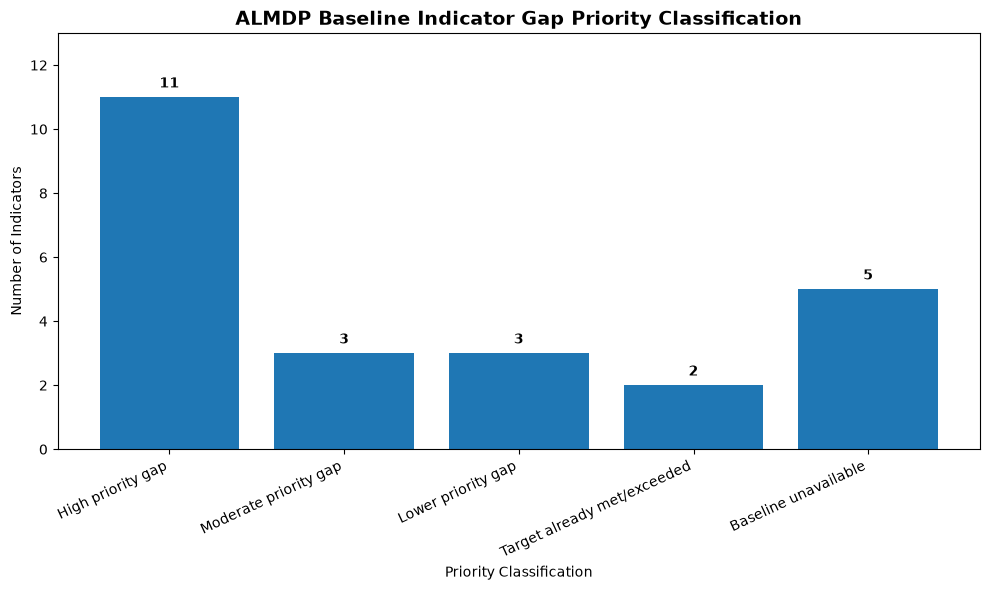

In [214]:
# 13.11 Visualize Baseline Gap Priority Classification

priority_chart = priority_summary.copy()

priority_chart["Priority Classification"] = (
    priority_chart["Priority Classification"].astype(str)
)

display(priority_chart)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    priority_chart["Priority Classification"],
    priority_chart["Indicator Count"]
)

plt.title(
    "ALMDP Baseline Indicator Gap Priority Classification",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Priority Classification")
plt.ylabel("Number of Indicators")
plt.xticks(rotation=25, ha="right")

for bar, count in zip(
    bars,
    priority_chart["Indicator Count"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        str(count),
        ha="center",
        va="bottom",
        fontweight="bold"
    )

plt.ylim(
    0,
    priority_chart["Indicator Count"].max() + 2
)

plt.tight_layout()
plt.show()

,Priority Classification,Indicator Count,Percentage of Indicators
0,High priority gap,11,45.833333
1,Moderate priority gap,3,12.500000
2,Lower priority gap,3,12.500000
3,Target already met/exceeded,2,8.333333
4,Baseline unavailable,5,20.833333


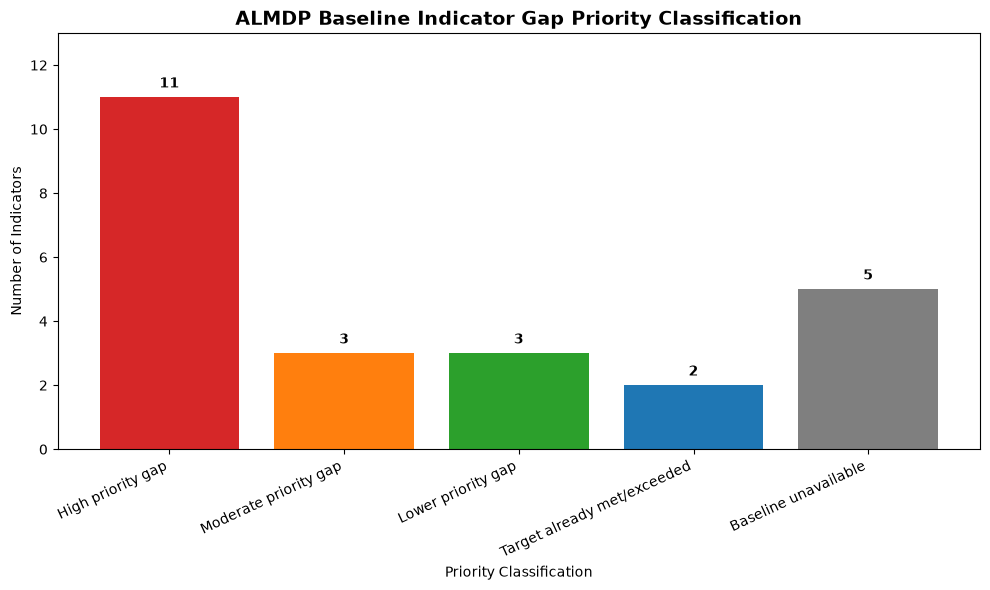

In [215]:
# 13.11 Visualize Baseline Gap Priority Classification

priority_chart = priority_summary.copy()

priority_chart["Priority Classification"] = (
    priority_chart["Priority Classification"].astype(str)
)

priority_colors = {
    "High priority gap": "#d62728",
    "Moderate priority gap": "#ff7f0e",
    "Lower priority gap": "#2ca02c",
    "Target already met/exceeded": "#1f77b4",
    "Baseline unavailable": "#7f7f7f",
}

colors = [
    priority_colors[category]
    for category in priority_chart["Priority Classification"]
]

display(priority_chart)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    priority_chart["Priority Classification"],
    priority_chart["Indicator Count"],
    color=colors
)

plt.title(
    "ALMDP Baseline Indicator Gap Priority Classification",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Priority Classification")
plt.ylabel("Number of Indicators")

plt.xticks(
    rotation=25,
    ha="right"
)

for bar, count in zip(
    bars,
    priority_chart["Indicator Count"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        str(count),
        ha="center",
        va="bottom",
        fontweight="bold"
    )

plt.ylim(
    0,
    priority_chart["Indicator Count"].max() + 2
)

plt.tight_layout()
plt.show()

,Indicator ID,Indicator,Baseline Value,2030 Target,Target Achievement (%),Direction,Priority Classification
6,OUT-05,Farmers reporting improved buyer access,30.000,70.0,42.857143,Higher is better,High priority gap
1,IMP-02,Beneficiaries reporting improved economic resi...,30.600,65.0,47.076923,Higher is better,High priority gap
13,OUT-12,Women beneficiaries reporting increased agricu...,29.120,60.0,48.533333,Higher is better,High priority gap
5,OUT-04,Farmers selling through structured markets,27.310,55.0,49.654545,Higher is better,High priority gap
9,OUT-08,Average MSME annual profit,356839.050,550000.0,64.879827,Higher is better,Moderate priority gap
7,OUT-06,Average post-harvest loss rate,17.330,12.0,69.244085,Lower is better,Moderate priority gap
10,OUT-09,MSMEs maintaining basic financial records,50.000,70.0,71.428571,Higher is better,Moderate priority gap
12,OUT-11,Direct beneficiaries aged 18-35,30.170,35.0,86.200000,Higher is better,Lower priority gap
11,OUT-10,Direct beneficiaries who are women,41.550,45.0,92.333333,Higher is better,Lower priority gap
2,OUT-01,Average crop productivity,2.448,2.5,97.920000,Higher is better,Lower priority gap


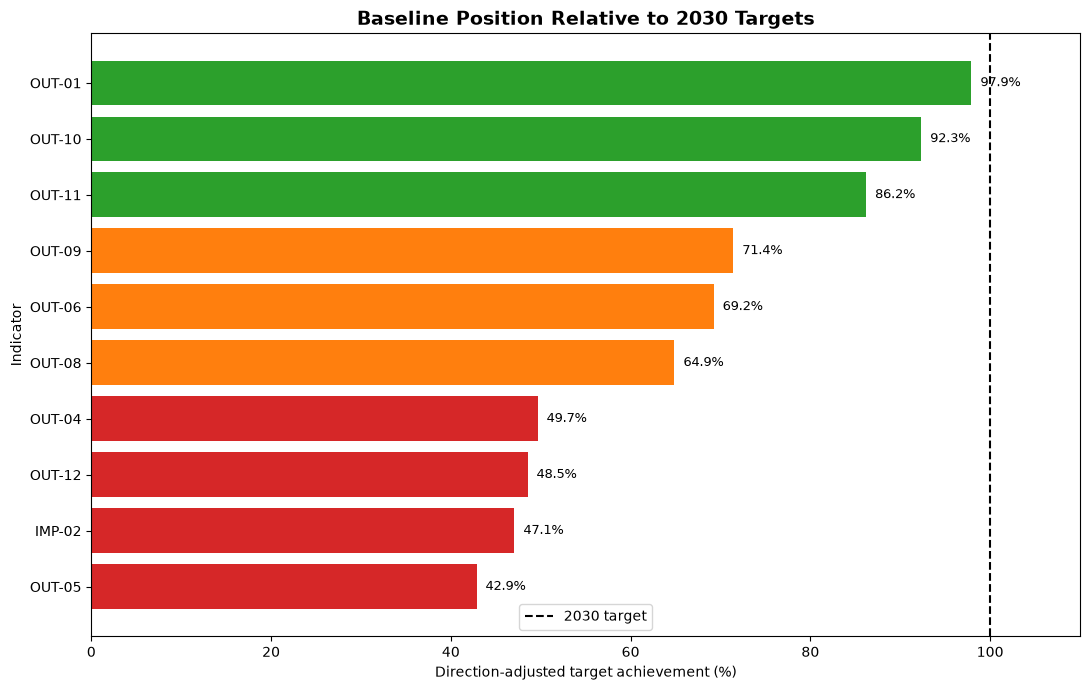

In [216]:
# 13.12 Visualize Outcome and Impact Target Achievement

achievement_chart = priority_analysis[
    (~priority_analysis["Baseline Value"].isna())
    & (priority_analysis["Absolute Gap"] > 0)
    & (priority_analysis["Indicator ID"].str.startswith(("IMP-", "OUT-")))
].copy()

achievement_chart = achievement_chart.sort_values(
    "Target Achievement (%)",
    ascending=True
)

display(
    achievement_chart[
        [
            "Indicator ID",
            "Indicator",
            "Baseline Value",
            "2030 Target",
            "Target Achievement (%)",
            "Direction",
            "Priority Classification"
        ]
    ]
)

plt.figure(figsize=(11, 7))

bars = plt.barh(
    achievement_chart["Indicator ID"],
    achievement_chart["Target Achievement (%)"],
    color=[
        priority_colors[classification]
        for classification
        in achievement_chart["Priority Classification"]
    ]
)

plt.axvline(
    100,
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="2030 target"
)

plt.title(
    "Baseline Position Relative to 2030 Targets",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Direction-adjusted target achievement (%)")
plt.ylabel("Indicator")

for bar, value in zip(
    bars,
    achievement_chart["Target Achievement (%)"]
):
    plt.text(
        value + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        fontsize=9
    )

plt.xlim(
    0,
    max(110, achievement_chart["Target Achievement (%)"].max() + 10)
)

plt.legend()
plt.tight_layout()
plt.show()

In [217]:
# 13.13 Management Priority Register

management_priority = priority_analysis[
    priority_analysis["Priority Classification"].isin(
        [
            "High priority gap",
            "Moderate priority gap",
            "Lower priority gap"
        ]
    )
].copy()

management_priority = management_priority[
    management_priority["Indicator ID"].str.startswith(
        ("IMP-", "OUT-")
    )
].copy()

management_priority = management_priority.sort_values(
    "Target Achievement (%)",
    ascending=True
)

management_priority["Management Priority"] = np.select(
    [
        management_priority["Priority Classification"]
        == "High priority gap",

        management_priority["Priority Classification"]
        == "Moderate priority gap",

        management_priority["Priority Classification"]
        == "Lower priority gap"
    ],
    [
        "High",
        "Moderate",
        "Lower"
    ],
    default="Review"
)

management_priority = management_priority[
    [
        "Indicator ID",
        "Indicator",
        "Baseline Value",
        "2030 Target",
        "Absolute Gap",
        "Target Achievement (%)",
        "Direction",
        "Management Priority"
    ]
]

display(management_priority)

,Indicator ID,Indicator,Baseline Value,2030 Target,Absolute Gap,Target Achievement (%),Direction,Management Priority
6,OUT-05,Farmers reporting improved buyer access,30.000,70.0,40.000,42.857143,Higher is better,High
1,IMP-02,Beneficiaries reporting improved economic resi...,30.600,65.0,34.400,47.076923,Higher is better,High
13,OUT-12,Women beneficiaries reporting increased agricu...,29.120,60.0,30.880,48.533333,Higher is better,High
5,OUT-04,Farmers selling through structured markets,27.310,55.0,27.690,49.654545,Higher is better,High
9,OUT-08,Average MSME annual profit,356839.050,550000.0,193160.950,64.879827,Higher is better,Moderate
7,OUT-06,Average post-harvest loss rate,17.330,12.0,5.330,69.244085,Lower is better,Moderate
10,OUT-09,MSMEs maintaining basic financial records,50.000,70.0,20.000,71.428571,Higher is better,Moderate
12,OUT-11,Direct beneficiaries aged 18-35,30.170,35.0,4.830,86.200000,Higher is better,Lower
11,OUT-10,Direct beneficiaries who are women,41.550,45.0,3.450,92.333333,Higher is better,Lower
2,OUT-01,Average crop productivity,2.448,2.5,0.052,97.920000,Higher is better,Lower


In [218]:
# 13.14 Final Baseline Indicator Gap Analysis QA

expected_ids = set(baseline_register["Indicator ID"])
actual_ids = set(indicator_gap_analysis["Indicator ID"])

# Core coverage
qa_indicators = len(indicator_gap_analysis) == 24
qa_all_ids = actual_ids == expected_ids
qa_unique_ids = indicator_gap_analysis["Indicator ID"].is_unique

# Priority classification coverage
qa_priority_count = (
    priority_analysis["Priority Classification"].notna().sum()
    == 24
)

# Unavailable baselines remain unavailable
unavailable_ids = [
    "OUT-03",
    "OUT-07",
    "OP-08",
    "OP-09",
    "OP-10"
]

qa_unavailable = (
    indicator_gap_analysis[
        indicator_gap_analysis["Indicator ID"].isin(unavailable_ids)
    ]["Baseline Value"].isna().all()
)

# OUT-06 direction handled correctly
out06 = indicator_gap_analysis[
    indicator_gap_analysis["Indicator ID"] == "OUT-06"
].iloc[0]

qa_out06 = (
    out06["Direction"] == "Lower is better"
    and abs(
        out06["Target Achievement (%)"]
        - (
            out06["2030 Target"]
            / out06["Baseline Value"]
            * 100
        )
    ) < 0.000001
)

# Targets already exceeded
qa_exceeded = set(
    priority_analysis[
        priority_analysis["Priority Classification"]
        == "Target already met/exceeded"
    ]["Indicator ID"]
) == {"IMP-01", "OUT-02"}

# Management priority register
qa_management_priority = (
    set(management_priority["Indicator ID"])
    == {
        "OUT-05",
        "IMP-02",
        "OUT-12",
        "OUT-04",
        "OUT-08",
        "OUT-06",
        "OUT-09",
        "OUT-11",
        "OUT-10",
        "OUT-01"
    }
)

final_gap_qa = all(
    [
        qa_indicators,
        qa_all_ids,
        qa_unique_ids,
        qa_priority_count,
        qa_unavailable,
        qa_out06,
        qa_exceeded,
        qa_management_priority
    ]
)

print("Indicator count check:", qa_indicators)
print("All expected indicator IDs present:", qa_all_ids)
print("Indicator IDs unique:", qa_unique_ids)
print("Priority classification complete:", qa_priority_count)
print("Unavailable baseline values preserved:", qa_unavailable)
print("OUT-06 lower-is-better calculation verified:", qa_out06)
print("Targets already met/exceeded correctly identified:", qa_exceeded)
print("Management priority register verified:", qa_management_priority)

print(
    "\nFINAL SECTION 13 GAP ANALYSIS QA:",
    "PASS" if final_gap_qa else "FAIL"
)

Indicator count check: True
All expected indicator IDs present: True
Indicator IDs unique: True
Priority classification complete: True
Unavailable baseline values preserved: True
OUT-06 lower-is-better calculation verified: True
Targets already met/exceeded correctly identified: True
Management priority register verified: True

FINAL SECTION 13 GAP ANALYSIS QA: PASS


In [219]:
# 14.01 Initialize Baseline Findings Dataset

baseline_findings = pd.DataFrame(
    columns=[
        "Finding ID",
        "Theme",
        "Finding",
        "Evidence",
        "Management Implication",
        "Priority"
    ]
)

print("Baseline findings dataset initialized.")
print("Columns:", list(baseline_findings.columns))
print("Current findings:", len(baseline_findings))

Baseline findings dataset initialized.
Columns: ['Finding ID', 'Theme', 'Finding', 'Evidence', 'Management Implication', 'Priority']
Current findings: 0


In [220]:
# 14.02 Add Overall Baseline Performance Findings

overall_findings = [
    [
        "FND-01",
        "Overall performance",
        "Several impact and outcome indicators have substantial gaps relative to their 2030 targets.",
        "Four measurable impact/outcome indicators are classified as high-priority gaps, while three are moderate-priority gaps.",
        "Prioritize implementation planning and resource allocation toward the indicators with the largest baseline-to-target gaps.",
        "High"
    ],
    [
        "FND-02",
        "Overall performance",
        "Two indicators have already met or exceeded their 2030 targets at baseline.",
        "IMP-01 is at 249.65% of its target and OUT-02 is at 104.32% of its target.",
        "Validate these strong baseline results and use subsequent monitoring to determine whether performance is sustained rather than assuming additional intervention is unnecessary.",
        "Moderate"
    ],
    [
        "FND-03",
        "Data availability",
        "Five indicators cannot currently be assessed against their 2030 targets because baseline data are unavailable.",
        "OUT-03, OUT-07, OP-08, OP-09 and OP-10 have no baseline values.",
        "Strengthen the M&E data systems and establish the required reporting and performance-tracking mechanisms before implementation monitoring begins.",
        "High"
    ]
]

baseline_findings = pd.concat(
    [
        baseline_findings,
        pd.DataFrame(
            overall_findings,
            columns=baseline_findings.columns
        )
    ],
    ignore_index=True
)

display(baseline_findings)

,Finding ID,Theme,Finding,Evidence,Management Implication,Priority
0,FND-01,Overall performance,Several impact and outcome indicators have sub...,Four measurable impact/outcome indicators are ...,Prioritize implementation planning and resourc...,High
1,FND-02,Overall performance,Two indicators have already met or exceeded th...,IMP-01 is at 249.65% of its target and OUT-02 ...,Validate these strong baseline results and use...,Moderate
2,FND-03,Data availability,Five indicators cannot currently be assessed a...,"OUT-03, OUT-07, OP-08, OP-09 and OP-10 have no...",Strengthen the M&E data systems and establish ...,High


In [221]:
# 14.03 Add Market Access and Economic Resilience Findings

market_resilience_findings = [
    [
        "FND-04",
        "Market access",
        "Market access is a major baseline performance gap, particularly buyer access and participation in structured markets.",
        "OUT-05 baseline is 30.00% against a 70% target, while OUT-04 is 27.31% against a 55% target. Both are classified as high-priority gaps.",
        "Strengthen market-linkage activities, buyer engagement, market information services, and structured-market participation mechanisms.",
        "High"
    ],
    [
        "FND-05",
        "Economic resilience",
        "Economic resilience is substantially below the project target at baseline.",
        "IMP-02 baseline is 30.60% against a 65% target, representing 47.08% direction-adjusted target achievement and a high-priority gap.",
        "Integrate resilience-building measures into agricultural, market-access, and MSME interventions and monitor resilience outcomes periodically.",
        "High"
    ]
]

baseline_findings = pd.concat(
    [
        baseline_findings,
        pd.DataFrame(
            market_resilience_findings,
            columns=baseline_findings.columns
        )
    ],
    ignore_index=True
)

display(baseline_findings)

,Finding ID,Theme,Finding,Evidence,Management Implication,Priority
0,FND-01,Overall performance,Several impact and outcome indicators have sub...,Four measurable impact/outcome indicators are ...,Prioritize implementation planning and resourc...,High
1,FND-02,Overall performance,Two indicators have already met or exceeded th...,IMP-01 is at 249.65% of its target and OUT-02 ...,Validate these strong baseline results and use...,Moderate
2,FND-03,Data availability,Five indicators cannot currently be assessed a...,"OUT-03, OUT-07, OP-08, OP-09 and OP-10 have no...",Strengthen the M&E data systems and establish ...,High
3,FND-04,Market access,Market access is a major baseline performance ...,OUT-05 baseline is 30.00% against a 70% target...,"Strengthen market-linkage activities, buyer en...",High
4,FND-05,Economic resilience,Economic resilience is substantially below the...,IMP-02 baseline is 30.60% against a 65% target...,Integrate resilience-building measures into ag...,High


In [222]:
# 14.04 Add Agricultural Productivity and Post-Harvest Findings

agriculture_findings = [
    [
        "FND-06",
        "Agricultural productivity",
        "Average crop productivity is close to the 2030 target at baseline.",
        "OUT-01 baseline is 2.448 t/ha against a 2.50 t/ha target, representing 97.92% target achievement.",
        "Maintain productivity-focused interventions while targeting the remaining productivity gap through extension, improved inputs, and climate-smart practices.",
        "Lower"
    ],
    [
        "FND-07",
        "Post-harvest management",
        "Post-harvest losses remain above the project target and require continued attention.",
        "OUT-06 baseline loss rate is 17.33% against a lower-is-better target of 12.00%, leaving a 5.33 percentage-point reduction requirement.",
        "Prioritize improved storage, handling, transport, processing, and post-harvest management practices across relevant value chains.",
        "Moderate"
    ]
]

baseline_findings = pd.concat(
    [
        baseline_findings,
        pd.DataFrame(
            agriculture_findings,
            columns=baseline_findings.columns
        )
    ],
    ignore_index=True
)

display(baseline_findings)

,Finding ID,Theme,Finding,Evidence,Management Implication,Priority
0,FND-01,Overall performance,Several impact and outcome indicators have sub...,Four measurable impact/outcome indicators are ...,Prioritize implementation planning and resourc...,High
1,FND-02,Overall performance,Two indicators have already met or exceeded th...,IMP-01 is at 249.65% of its target and OUT-02 ...,Validate these strong baseline results and use...,Moderate
2,FND-03,Data availability,Five indicators cannot currently be assessed a...,"OUT-03, OUT-07, OP-08, OP-09 and OP-10 have no...",Strengthen the M&E data systems and establish ...,High
3,FND-04,Market access,Market access is a major baseline performance ...,OUT-05 baseline is 30.00% against a 70% target...,"Strengthen market-linkage activities, buyer en...",High
4,FND-05,Economic resilience,Economic resilience is substantially below the...,IMP-02 baseline is 30.60% against a 65% target...,Integrate resilience-building measures into ag...,High
5,FND-06,Agricultural productivity,Average crop productivity is close to the 2030...,OUT-01 baseline is 2.448 t/ha against a 2.50 t...,Maintain productivity-focused interventions wh...,Lower
6,FND-07,Post-harvest management,Post-harvest losses remain above the project t...,OUT-06 baseline loss rate is 17.33% against a ...,"Prioritize improved storage, handling, transpo...",Moderate


In [223]:
# 14.05 Add MSME Performance Findings

msme_findings = [
    [
        "FND-08",
        "MSME performance",
        "Average MSME annual profit requires substantial improvement to reach the 2030 target.",
        "OUT-08 baseline average annual profit is NGN 356,839.05 against a target of NGN 550,000, representing 64.88% target achievement.",
        "Strengthen MSME business development support, cost management, market access, pricing, and revenue-generation strategies.",
        "Moderate"
    ],
    [
        "FND-09",
        "MSME financial management",
        "Basic financial record keeping is below the project target among supported MSMEs.",
        "OUT-09 baseline is 50.00% against a 70% target, representing 71.43% target achievement.",
        "Prioritize practical financial-management training, record-keeping tools, business coaching, and follow-up support.",
        "Moderate"
    ]
]

baseline_findings = pd.concat(
    [
        baseline_findings,
        pd.DataFrame(
            msme_findings,
            columns=baseline_findings.columns
        )
    ],
    ignore_index=True
)

display(baseline_findings)

,Finding ID,Theme,Finding,Evidence,Management Implication,Priority
0,FND-01,Overall performance,Several impact and outcome indicators have sub...,Four measurable impact/outcome indicators are ...,Prioritize implementation planning and resourc...,High
1,FND-02,Overall performance,Two indicators have already met or exceeded th...,IMP-01 is at 249.65% of its target and OUT-02 ...,Validate these strong baseline results and use...,Moderate
2,FND-03,Data availability,Five indicators cannot currently be assessed a...,"OUT-03, OUT-07, OP-08, OP-09 and OP-10 have no...",Strengthen the M&E data systems and establish ...,High
3,FND-04,Market access,Market access is a major baseline performance ...,OUT-05 baseline is 30.00% against a 70% target...,"Strengthen market-linkage activities, buyer en...",High
4,FND-05,Economic resilience,Economic resilience is substantially below the...,IMP-02 baseline is 30.60% against a 65% target...,Integrate resilience-building measures into ag...,High
5,FND-06,Agricultural productivity,Average crop productivity is close to the 2030...,OUT-01 baseline is 2.448 t/ha against a 2.50 t...,Maintain productivity-focused interventions wh...,Lower
6,FND-07,Post-harvest management,Post-harvest losses remain above the project t...,OUT-06 baseline loss rate is 17.33% against a ...,"Prioritize improved storage, handling, transpo...",Moderate
7,FND-08,MSME performance,Average MSME annual profit requires substantia...,OUT-08 baseline average annual profit is NGN 3...,"Strengthen MSME business development support, ...",Moderate
8,FND-09,MSME financial management,Basic financial record keeping is below the pr...,OUT-09 baseline is 50.00% against a 70% target...,Prioritize practical financial-management trai...,Moderate


In [224]:
# 14.06 Add Inclusion Findings

inclusion_findings = [
    [
        "FND-10",
        "Gender inclusion",
        "Women already represent a substantial share of direct beneficiaries and are relatively close to the 2030 representation target.",
        "OUT-10 baseline is 41.55% against a 45% target, representing 92.33% target achievement.",
        "Maintain strong female participation while ensuring that women are effectively reached by productive, market-access, and income-enhancing interventions.",
        "Lower"
    ],
    [
        "FND-11",
        "Youth inclusion",
        "Youth representation is below the 2030 target and requires continued attention.",
        "OUT-11 baseline is 30.17% against a 35% target, representing 86.20% target achievement.",
        "Maintain youth participation and strengthen targeted engagement mechanisms to close the remaining inclusion gap.",
        "Lower"
    ],
    [
        "FND-12",
        "Women's economic outcomes",
        "Women's reported improvement in agricultural or business income is a major baseline gap.",
        "OUT-12 baseline is 29.12% against a 60% target, representing 48.53% target achievement and a high-priority gap.",
        "Ensure women's participation translates into measurable economic gains through targeted market access, business support, productive assets, and income-enhancing interventions.",
        "High"
    ]
]

baseline_findings = pd.concat(
    [
        baseline_findings,
        pd.DataFrame(
            inclusion_findings,
            columns=baseline_findings.columns
        )
    ],
    ignore_index=True
)

display(baseline_findings)

,Finding ID,Theme,Finding,Evidence,Management Implication,Priority
0,FND-01,Overall performance,Several impact and outcome indicators have sub...,Four measurable impact/outcome indicators are ...,Prioritize implementation planning and resourc...,High
1,FND-02,Overall performance,Two indicators have already met or exceeded th...,IMP-01 is at 249.65% of its target and OUT-02 ...,Validate these strong baseline results and use...,Moderate
2,FND-03,Data availability,Five indicators cannot currently be assessed a...,"OUT-03, OUT-07, OP-08, OP-09 and OP-10 have no...",Strengthen the M&E data systems and establish ...,High
3,FND-04,Market access,Market access is a major baseline performance ...,OUT-05 baseline is 30.00% against a 70% target...,"Strengthen market-linkage activities, buyer en...",High
4,FND-05,Economic resilience,Economic resilience is substantially below the...,IMP-02 baseline is 30.60% against a 65% target...,Integrate resilience-building measures into ag...,High
5,FND-06,Agricultural productivity,Average crop productivity is close to the 2030...,OUT-01 baseline is 2.448 t/ha against a 2.50 t...,Maintain productivity-focused interventions wh...,Lower
6,FND-07,Post-harvest management,Post-harvest losses remain above the project t...,OUT-06 baseline loss rate is 17.33% against a ...,"Prioritize improved storage, handling, transpo...",Moderate
7,FND-08,MSME performance,Average MSME annual profit requires substantia...,OUT-08 baseline average annual profit is NGN 3...,"Strengthen MSME business development support, ...",Moderate
8,FND-09,MSME financial management,Basic financial record keeping is below the pr...,OUT-09 baseline is 50.00% against a 70% target...,Prioritize practical financial-management trai...,Moderate
9,FND-10,Gender inclusion,Women already represent a substantial share of...,OUT-10 baseline is 41.55% against a 45% target...,Maintain strong female participation while ens...,Lower


In [225]:
# 14.07 Add Value-Chain Findings

value_chain_findings = [
    [
        "FND-13",
        "Value-chain performance",
        "Agricultural performance varies substantially across value chains, with tomato and vegetable farmers showing higher productivity and income than several other value chains.",
        "Tomato has the highest average productivity at 5.42 t/ha and average income of NGN 3.62 million, while groundnut has the lowest productivity at 1.37 t/ha and average income of NGN 876,347.",
        "Use value-chain-specific implementation strategies rather than applying identical support packages across all commodities.",
        "High"
    ],
    [
        "FND-14",
        "Practice adoption",
        "Adoption of at least three recommended agricultural practices is relatively strong but varies across value chains.",
        "Overall OUT-02 adoption is 67.81%. Adoption ranges from 65.24% among vegetable farmers to 69.78% among ginger farmers.",
        "Maintain broad agricultural extension support while targeting value chains with comparatively lower adoption for additional technical assistance.",
        "Lower"
    ],
    [
        "FND-15",
        "Post-harvest management",
        "Post-harvest loss rates are relatively similar across value chains but remain above the project target.",
        "Average loss rates range from 16.17% for groundnut to 17.86% for vegetables, compared with the overall baseline of 17.33% and a 12% target.",
        "Apply cross-cutting post-harvest management measures while prioritizing value chains with higher observed losses.",
        "Moderate"
    ]
]

baseline_findings = pd.concat(
    [
        baseline_findings,
        pd.DataFrame(
            value_chain_findings,
            columns=baseline_findings.columns
        )
    ],
    ignore_index=True
)

display(baseline_findings)

,Finding ID,Theme,Finding,Evidence,Management Implication,Priority
0,FND-01,Overall performance,Several impact and outcome indicators have sub...,Four measurable impact/outcome indicators are ...,Prioritize implementation planning and resourc...,High
1,FND-02,Overall performance,Two indicators have already met or exceeded th...,IMP-01 is at 249.65% of its target and OUT-02 ...,Validate these strong baseline results and use...,Moderate
2,FND-03,Data availability,Five indicators cannot currently be assessed a...,"OUT-03, OUT-07, OP-08, OP-09 and OP-10 have no...",Strengthen the M&E data systems and establish ...,High
3,FND-04,Market access,Market access is a major baseline performance ...,OUT-05 baseline is 30.00% against a 70% target...,"Strengthen market-linkage activities, buyer en...",High
4,FND-05,Economic resilience,Economic resilience is substantially below the...,IMP-02 baseline is 30.60% against a 65% target...,Integrate resilience-building measures into ag...,High
5,FND-06,Agricultural productivity,Average crop productivity is close to the 2030...,OUT-01 baseline is 2.448 t/ha against a 2.50 t...,Maintain productivity-focused interventions wh...,Lower
6,FND-07,Post-harvest management,Post-harvest losses remain above the project t...,OUT-06 baseline loss rate is 17.33% against a ...,"Prioritize improved storage, handling, transpo...",Moderate
7,FND-08,MSME performance,Average MSME annual profit requires substantia...,OUT-08 baseline average annual profit is NGN 3...,"Strengthen MSME business development support, ...",Moderate
8,FND-09,MSME financial management,Basic financial record keeping is below the pr...,OUT-09 baseline is 50.00% against a 70% target...,Prioritize practical financial-management trai...,Moderate
9,FND-10,Gender inclusion,Women already represent a substantial share of...,OUT-10 baseline is 41.55% against a 45% target...,Maintain strong female participation while ens...,Lower


In [226]:
# 14.08 Add Data and M&E System Findings

data_system_findings = [
    [
        "FND-16",
        "M&E data availability",
        "Five indicators cannot be assessed at baseline because the required measurement data are not available.",
        "OUT-03, OUT-07, OP-08, OP-09 and OP-10 have unavailable baseline values.",
        "Establish indicator-specific data collection and reporting arrangements, including responsible persons, data sources, reporting frequency, and verification procedures.",
        "High"
    ],
    [
        "FND-17",
        "M&E performance tracking",
        "Output-level implementation performance cannot yet be assessed because implementation has not started.",
        "OP-01 through OP-07 have baseline values of zero, while OP-08 through OP-10 are not yet measurable because implementation and routine M&E tracking have not commenced.",
        "Establish implementation and M&E tracking systems before activity delivery begins so that output progress can be measured consistently from the start of implementation.",
        "High"
    ],
    [
        "FND-18",
        "Data quality",
        "The baseline dataset required formal data-quality controls before analysis.",
        "The raw dataset contained identified data-quality issues including duplicate respondent IDs, invalid values, missing observations, and logical inconsistencies; these were resolved or documented through the DQA and cleaning process.",
        "Maintain routine data-quality assurance covering accuracy, completeness, consistency, timeliness, and integrity throughout implementation.",
        "High"
    ]
]

baseline_findings = pd.concat(
    [
        baseline_findings,
        pd.DataFrame(
            data_system_findings,
            columns=baseline_findings.columns
        )
    ],
    ignore_index=True
)

display(baseline_findings)

,Finding ID,Theme,Finding,Evidence,Management Implication,Priority
0,FND-01,Overall performance,Several impact and outcome indicators have sub...,Four measurable impact/outcome indicators are ...,Prioritize implementation planning and resourc...,High
1,FND-02,Overall performance,Two indicators have already met or exceeded th...,IMP-01 is at 249.65% of its target and OUT-02 ...,Validate these strong baseline results and use...,Moderate
2,FND-03,Data availability,Five indicators cannot currently be assessed a...,"OUT-03, OUT-07, OP-08, OP-09 and OP-10 have no...",Strengthen the M&E data systems and establish ...,High
3,FND-04,Market access,Market access is a major baseline performance ...,OUT-05 baseline is 30.00% against a 70% target...,"Strengthen market-linkage activities, buyer en...",High
4,FND-05,Economic resilience,Economic resilience is substantially below the...,IMP-02 baseline is 30.60% against a 65% target...,Integrate resilience-building measures into ag...,High
5,FND-06,Agricultural productivity,Average crop productivity is close to the 2030...,OUT-01 baseline is 2.448 t/ha against a 2.50 t...,Maintain productivity-focused interventions wh...,Lower
6,FND-07,Post-harvest management,Post-harvest losses remain above the project t...,OUT-06 baseline loss rate is 17.33% against a ...,"Prioritize improved storage, handling, transpo...",Moderate
7,FND-08,MSME performance,Average MSME annual profit requires substantia...,OUT-08 baseline average annual profit is NGN 3...,"Strengthen MSME business development support, ...",Moderate
8,FND-09,MSME financial management,Basic financial record keeping is below the pr...,OUT-09 baseline is 50.00% against a 70% target...,Prioritize practical financial-management trai...,Moderate
9,FND-10,Gender inclusion,Women already represent a substantial share of...,OUT-10 baseline is 41.55% against a 45% target...,Maintain strong female participation while ens...,Lower


In [227]:
# 14.09 Summarize Baseline Findings by Priority

priority_summary = (
    baseline_findings["Priority"]
    .value_counts()
    .rename_axis("Priority")
    .reset_index(name="Number of Findings")
)

priority_order = [
    "High",
    "Moderate",
    "Lower"
]

priority_summary["Priority"] = pd.Categorical(
    priority_summary["Priority"],
    categories=priority_order,
    ordered=True
)

priority_summary = priority_summary.sort_values("Priority").reset_index(drop=True)

display(priority_summary)

print("\nPriority summary:")
print(
    f"Total findings: {len(baseline_findings)}"
)
print(
    f"High priority: {(baseline_findings['Priority'] == 'High').sum()}"
)
print(
    f"Moderate priority: {(baseline_findings['Priority'] == 'Moderate').sum()}"
)
print(
    f"Lower priority: {(baseline_findings['Priority'] == 'Lower').sum()}"
)

,Priority,Number of Findings
0,High,9
1,Moderate,5
2,Lower,4



Priority summary:
Total findings: 18
High priority: 9
Moderate priority: 5
Lower priority: 4


In [228]:
# 14.10 Develop Management Implications

management_actions = [
    [
        "ACT-01",
        "Market access and buyer linkages",
        "OUT-04 and OUT-05",
        "Low structured-market participation and buyer access",
        "Strengthen buyer engagement, market-linkage events, market information services, and structured-market participation.",
        "High"
    ],
    [
        "ACT-02",
        "Economic resilience",
        "IMP-02",
        "Economic resilience is substantially below the 2030 target",
        "Integrate resilience measures across agricultural productivity, market access, MSME support, and climate-smart interventions.",
        "High"
    ],
    [
        "ACT-03",
        "Women's economic outcomes",
        "OUT-12",
        "Women's income improvement is substantially below target",
        "Ensure women's participation translates into measurable income gains through targeted productive, market, and business-support interventions.",
        "High"
    ],
    [
        "ACT-04",
        "Value-chain targeting",
        "OUT-01, OUT-02, OUT-06",
        "Performance varies across agricultural value chains",
        "Use value-chain-specific extension, productivity, adoption, and post-harvest strategies based on baseline evidence.",
        "High"
    ],
    [
        "ACT-05",
        "Post-harvest management",
        "OUT-06",
        "Post-harvest loss remains above the 12% target",
        "Strengthen storage, handling, transportation, processing, and post-harvest management practices.",
        "Moderate"
    ],
    [
        "ACT-06",
        "MSME profitability",
        "OUT-08",
        "Average MSME profit is below the 2030 target",
        "Strengthen business development, cost management, pricing, market access, and revenue-generation support.",
        "Moderate"
    ],
    [
        "ACT-07",
        "MSME financial management",
        "OUT-09",
        "Only 50% of MSMEs meet the basic financial-record threshold",
        "Provide practical financial-management training, record-keeping tools, coaching, and follow-up support.",
        "Moderate"
    ],
    [
        "ACT-08",
        "M&E data systems",
        "OUT-03, OUT-07, OP-08, OP-09, OP-10",
        "Five indicators cannot currently be assessed at baseline",
        "Establish indicator-specific data sources, collection procedures, reporting responsibilities, frequency, and verification arrangements.",
        "High"
    ],
    [
        "ACT-09",
        "Data quality assurance",
        "All baseline indicators",
        "Baseline analysis required formal DQA and data cleaning",
        "Maintain routine data-quality assurance covering accuracy, completeness, consistency, timeliness, and integrity.",
        "High"
    ],
    [
        "ACT-10",
        "Inclusion",
        "OUT-10, OUT-11",
        "Women and youth representation requires continued monitoring",
        "Maintain strong inclusion performance while using targeted engagement to close remaining gender and youth gaps.",
        "Lower"
    ]
]

management_action_register = pd.DataFrame(
    management_actions,
    columns=[
        "Action ID",
        "Management Area",
        "Related Indicators",
        "Baseline Evidence",
        "Recommended Management Action",
        "Priority"
    ]
)

display(management_action_register)

,Action ID,Management Area,Related Indicators,Baseline Evidence,Recommended Management Action,Priority
0,ACT-01,Market access and buyer linkages,OUT-04 and OUT-05,Low structured-market participation and buyer ...,"Strengthen buyer engagement, market-linkage ev...",High
1,ACT-02,Economic resilience,IMP-02,Economic resilience is substantially below the...,Integrate resilience measures across agricultu...,High
2,ACT-03,Women's economic outcomes,OUT-12,Women's income improvement is substantially be...,Ensure women's participation translates into m...,High
3,ACT-04,Value-chain targeting,"OUT-01, OUT-02, OUT-06",Performance varies across agricultural value c...,"Use value-chain-specific extension, productivi...",High
4,ACT-05,Post-harvest management,OUT-06,Post-harvest loss remains above the 12% target,"Strengthen storage, handling, transportation, ...",Moderate
5,ACT-06,MSME profitability,OUT-08,Average MSME profit is below the 2030 target,"Strengthen business development, cost manageme...",Moderate
6,ACT-07,MSME financial management,OUT-09,Only 50% of MSMEs meet the basic financial-rec...,Provide practical financial-management trainin...,Moderate
7,ACT-08,M&E data systems,"OUT-03, OUT-07, OP-08, OP-09, OP-10",Five indicators cannot currently be assessed a...,"Establish indicator-specific data sources, col...",High
8,ACT-09,Data quality assurance,All baseline indicators,Baseline analysis required formal DQA and data...,Maintain routine data-quality assurance coveri...,High
9,ACT-10,Inclusion,"OUT-10, OUT-11",Women and youth representation requires contin...,Maintain strong inclusion performance while us...,Lower


In [229]:
# 14.11 Final QA of Section 14

print("SECTION 14 FINAL QA")
print("=" * 60)

# 1. Baseline findings checks
expected_finding_count = 18
expected_finding_ids = [f"FND-{i:02d}" for i in range(1, 19)]

finding_ids = baseline_findings["Finding ID"].tolist()

print("\nBaseline findings:")
print("  Count:", len(baseline_findings))
print("  Expected count:", expected_finding_count)
print("  Count check:", len(baseline_findings) == expected_finding_count)

print(
    "  All expected IDs present:",
    set(expected_finding_ids) == set(finding_ids)
)

print(
    "  Finding IDs unique:",
    baseline_findings["Finding ID"].is_unique
)

print(
    "  Required fields complete:",
    baseline_findings[
        [
            "Finding ID",
            "Theme",
            "Finding",
            "Evidence",
            "Management Implication",
            "Priority"
        ]
    ].notna().all().all()
)

# 2. Priority checks
expected_priorities = {"High", "Moderate", "Lower"}
actual_priorities = set(baseline_findings["Priority"])

print(
    "  Priority categories valid:",
    actual_priorities.issubset(expected_priorities)
)

print(
    "  Priority reconciliation:",
    baseline_findings["Priority"].value_counts().sum()
    == len(baseline_findings)
)

# 3. Management action checks
expected_action_count = 10
expected_action_ids = [f"ACT-{i:02d}" for i in range(1, 11)]

action_ids = management_action_register["Action ID"].tolist()

print("\nManagement action register:")
print("  Count:", len(management_action_register))
print("  Expected count:", expected_action_count)
print("  Count check:", len(management_action_register) == expected_action_count)

print(
    "  All expected IDs present:",
    set(expected_action_ids) == set(action_ids)
)

print(
    "  Action IDs unique:",
    management_action_register["Action ID"].is_unique
)

print(
    "  Required fields complete:",
    management_action_register[
        [
            "Action ID",
            "Management Area",
            "Related Indicators",
            "Baseline Evidence",
            "Recommended Management Action",
            "Priority"
        ]
    ].notna().all().all()
)

# 4. High-priority action check
print(
    "  High-priority actions present:",
    (management_action_register["Priority"] == "High").sum()
    > 0
)

# 5. Overall QA result
qa_checks = [
    len(baseline_findings) == expected_finding_count,
    set(expected_finding_ids) == set(finding_ids),
    baseline_findings["Finding ID"].is_unique,
    baseline_findings[
        [
            "Finding ID",
            "Theme",
            "Finding",
            "Evidence",
            "Management Implication",
            "Priority"
        ]
    ].notna().all().all(),
    actual_priorities.issubset(expected_priorities),
    baseline_findings["Priority"].value_counts().sum()
    == len(baseline_findings),
    len(management_action_register) == expected_action_count,
    set(expected_action_ids) == set(action_ids),
    management_action_register["Action ID"].is_unique,
    management_action_register[
        [
            "Action ID",
            "Management Area",
            "Related Indicators",
            "Baseline Evidence",
            "Recommended Management Action",
            "Priority"
        ]
    ].notna().all().all(),
    (management_action_register["Priority"] == "High").sum() > 0
]

print("\nOverall Section 14 QA:", "PASS" if all(qa_checks) else "FAIL")

SECTION 14 FINAL QA

Baseline findings:
  Count: 18
  Expected count: 18
  Count check: True
  All expected IDs present: True
  Finding IDs unique: True
  Required fields complete: True
  Priority categories valid: True
  Priority reconciliation: True

Management action register:
  Count: 10
  Expected count: 10
  Count check: True
  All expected IDs present: True
  Action IDs unique: True
  Required fields complete: True
  High-priority actions present: True

Overall Section 14 QA: PASS


In [230]:
# 15.01 Inspect Existing Results Framework

results_framework_path = (
    PROJECT_ROOT
    / "01_Project_Design"
    / "Results_Framework.xlsx"
)

rf_sheets = pd.ExcelFile(results_framework_path).sheet_names

print("Results Framework file:", results_framework_path)
print("Available sheets:")
for sheet in rf_sheets:
    print(" -", sheet)

Results Framework file: c:\Users\HP 15\Documents\ALMDP_Kaduna_ME_Portfolio\01_Project_Design\Results_Framework.xlsx
Available sheets:
 - Results Framework
 - Framework Metadata
 - Results Summary


In [231]:
# 15.02 Inspect Results Framework Sheet

rf_main = pd.read_excel(
    results_framework_path,
    sheet_name="Results Framework"
)

print("Shape:", rf_main.shape)
print("\nColumns:")
print(list(rf_main.columns))

display(rf_main)

Shape: (24, 15)

Columns:
['Result Level', 'Result Code', 'Results Statement', 'Indicator', 'Indicator Definition / Calculation', 'Baseline', 'Baseline Year', 'Target 2030', 'Data Source', 'Data Collection Method', 'Frequency', 'Responsible', 'Disaggregation', 'Assumptions / Risks', 'Notes']


,Result Level,Result Code,Results Statement,Indicator,Indicator Definition / Calculation,Baseline,Baseline Year,Target 2030,Data Source,Data Collection Method,Frequency,Responsible,Disaggregation,Assumptions / Risks,Notes
0,Impact,IMP-01,Improved beneficiary economic well-being,Average annual beneficiary income (₦/year),Total annual income across valid beneficiary o...,420000,2026,600000,Baseline/endline household survey,Structured beneficiary survey,Annual,M&E Unit,"Sex, age group, LGA, beneficiary type, value c...",Economic and market conditions remain sufficie...,Missing income values will not automatically b...
1,Impact,IMP-02,Improved beneficiary economic resilience,Beneficiaries reporting improved economic resi...,Number of beneficiaries meeting the defined im...,34%,2026,65%,Household survey,Structured resilience assessment,Annual,M&E Unit,"Sex, age group, LGA, beneficiary type",Beneficiaries remain exposed to manageable lev...,Higher percentage represents better performance.
2,Outcome,OUT-01,Increased agricultural productivity,Average crop productivity (t/ha),Quantity harvested in tonnes divided by cultiv...,1.80 t/ha,2026,2.50 t/ha,Farmer survey and production records,Beneficiary survey / record review,Annual,Agriculture Technical Team / M&E,"LGA, value chain, sex, age group","Inputs, weather and production conditions rema...",Valid area and harvest observations required.
3,Outcome,OUT-02,Increased adoption of recommended practices,Farmers adopting at least three recommended pr...,Number of assessed farmers adopting at least t...,32%,2026,65%,Farmer survey,Structured agricultural practices module,Annual,Agriculture Technical Team / M&E,"Sex, age group, LGA, value chain","Farmers have access to inputs, services and te...",Adoption threshold = at least 3 practices.
4,Outcome,OUT-03,Improved agricultural knowledge,Trained farmers demonstrating adequate knowled...,Number of assessed trained farmers scoring at ...,28%,2026,75%,Knowledge assessment,Structured knowledge test,Annual,M&E Unit / Training Team,"Sex, age group, LGA, value chain",Training content is relevant and participants ...,Adequate knowledge = score ≥7/10.
5,Outcome,OUT-04,Improved market participation,Farmers selling through structured markets (%),Number of valid farmer respondents selling thr...,26%,2026,55%,Farmer survey,Market access module,Annual,Market Access Team / M&E,"Sex, age group, LGA, value chain",Buyers and structured market channels remain a...,Structured market definition will be documente...
6,Outcome,OUT-05,Improved buyer access,Beneficiaries reporting improved buyer access (%),Number of beneficiaries reporting improved acc...,31%,2026,70%,Beneficiary survey,Structured market access assessment,Annual,Market Access Team / M&E,"Sex, age group, LGA, beneficiary type, value c...",Market linkage activities result in meaningful...,Self-reported outcome supported by market link...
7,Outcome,OUT-06,Reduced post-harvest losses,Average post-harvest loss rate (%),Quantity lost divided by quantity harvested × ...,22%,2026,12%,Farmer survey and production records,Production and post-harvest assessment,Annual,Agriculture Technical Team / M&E,"LGA, value chain, sex, age group","Improved storage, handling and transport pract...",Lower value represents better performance.
8,Outcome,OUT-07,Improved agricultural MSME performance,Supported MSMEs reporting increased annual rev...,Number of supported MSMEs reporting increased ...,0%,2026,60%,MSME survey and business records,Business survey / record review,Annual,MSME Team / M&E,"Sex, age group, LGA, business type",MSMEs remain operational and market conditions...,Baseline is 0% because project-supported MSMEs...
9,Outcome,OUT-08,Improved MSME profitability,Average MSME annual profit (₦/year),Total annual profit across valid MSME observat...,350000,2026,550000,MSME survey and business records,Business survey / record review,Annual,MSME Team / M&E,"LGA, sex, age group, business type",MSMEs maintain operations and 

In [232]:
# 15.03 Reconcile Results Framework with Validated Baseline Register

rf_reconciliation = rf_main[
    [
        "Result Level",
        "Result Code",
        "Results Statement",
        "Indicator",
        "Baseline",
        "Baseline Year",
        "Target 2030"
    ]
].copy()

rf_reconciliation = rf_reconciliation.rename(
    columns={
        "Result Code": "Indicator ID",
        "Baseline": "Design Baseline",
        "Target 2030": "Design Target"
    }
)

validated_baselines = baseline_indicator_register[
    [
        "Indicator ID",
        "Baseline Value",
        "Unit",
        "Status"
    ]
].copy()

rf_reconciliation = rf_reconciliation.merge(
    validated_baselines,
    on="Indicator ID",
    how="left",
    validate="one_to_one"
)

rf_reconciliation["Baseline Difference"] = np.where(
    rf_reconciliation["Baseline Value"].notna(),
    rf_reconciliation["Baseline Value"].astype(float)
    - pd.to_numeric(
        rf_reconciliation["Design Baseline"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.replace("%", "", regex=False)
        .str.replace(" t/ha", "", regex=False)
        .str.replace("₦", "", regex=False)
        .str.strip(),
        errors="coerce"
    ),
    np.nan
)

display(rf_reconciliation)

print("\nReconciliation summary:")
print("Results Framework indicators:", len(rf_reconciliation))
print(
    "Indicators with validated baseline:",
    rf_reconciliation["Baseline Value"].notna().sum()
)
print(
    "Indicators without validated baseline:",
    rf_reconciliation["Baseline Value"].isna().sum()
)

,Result Level,Indicator ID,Results Statement,Indicator,Design Baseline,Baseline Year,Design Target,Baseline Value,Unit,Status,Baseline Difference
0,Impact,IMP-01,Improved beneficiary economic well-being,Average annual beneficiary income (₦/year),420000,2026,600000,1497879.700,NGN/year,Calculated,1077879.700
1,Impact,IMP-02,Improved beneficiary economic resilience,Beneficiaries reporting improved economic resi...,34%,2026,65%,30.600,%,Calculated,-3.400
2,Outcome,OUT-01,Increased agricultural productivity,Average crop productivity (t/ha),1.80 t/ha,2026,2.50 t/ha,2.448,t/ha,Calculated,0.648
3,Outcome,OUT-02,Increased adoption of recommended practices,Farmers adopting at least three recommended pr...,32%,2026,65%,67.810,%,Calculated,35.810
4,Outcome,OUT-03,Improved agricultural knowledge,Trained farmers demonstrating adequate knowled...,28%,2026,75%,NaN,%,Not calculated - training_received variable un...,NaN
5,Outcome,OUT-04,Improved market participation,Farmers selling through structured markets (%),26%,2026,55%,27.310,%,Calculated,1.310
6,Outcome,OUT-05,Improved buyer access,Beneficiaries reporting improved buyer access (%),31%,2026,70%,30.000,%,Calculated,-1.000
7,Outcome,OUT-06,Reduced post-harvest losses,Average post-harvest loss rate (%),22%,2026,12%,17.330,%,Calculated,-4.670
8,Outcome,OUT-07,Improved agricultural MSME performance,Supported MSMEs reporting increased annual rev...,0%,2026,60%,NaN,%,Not calculated - revenue_increased variable un...,NaN
9,Outcome,OUT-08,Improved MSME profitability,Average MSME annual profit (₦/year),350000,2026,550000,356839.050,NGN/year,Calculated,6839.050



Reconciliation summary:
Results Framework indicators: 24
Indicators with validated baseline: 19
Indicators without validated baseline: 5


In [233]:
# 15.04 Create Authoritative Logframe Reconciliation View

logframe_base = rf_reconciliation.copy()

# Add a clear baseline status for Logframe use
logframe_base["Baseline Status"] = np.select(
    [
        logframe_base["Baseline Value"].notna()
        & logframe_base["Status"].eq("Calculated"),

        logframe_base["Baseline Value"].notna()
        & logframe_base["Status"].str.contains(
            "pre-implementation",
            case=False,
            na=False
        ),

        logframe_base["Baseline Value"].isna()
    ],
    [
        "Validated from synthetic baseline dataset",
        "Pre-implementation baseline",
        "Not measurable at baseline"
    ],
    default="Review"
)

# Preserve the authoritative result order
result_order = {
    "Impact": 1,
    "Outcome": 2,
    "Output": 3
}

logframe_base["Result Order"] = (
    logframe_base["Result Level"].map(result_order)
)

logframe_base = (
    logframe_base
    .sort_values(["Result Order", "Indicator ID"])
    .drop(columns=["Result Order"])
    .reset_index(drop=True)
)

print("Logframe reconciliation view created.")
print("Rows:", len(logframe_base))
print("Columns:", list(logframe_base.columns))

print("\nBaseline status:")
print(
    logframe_base["Baseline Status"]
    .value_counts()
)

display(
    logframe_base[
        [
            "Result Level",
            "Indicator ID",
            "Results Statement",
            "Design Baseline",
            "Baseline Value",
            "Baseline Status",
            "Design Target"
        ]
    ]
)

Logframe reconciliation view created.
Rows: 24
Columns: ['Result Level', 'Indicator ID', 'Results Statement', 'Indicator', 'Design Baseline', 'Baseline Year', 'Design Target', 'Baseline Value', 'Unit', 'Status', 'Baseline Difference', 'Baseline Status']

Baseline status:
Baseline Status
Validated from synthetic baseline dataset    12
Pre-implementation baseline                   7
Not measurable at baseline                    5
Name: count, dtype: int64


,Result Level,Indicator ID,Results Statement,Design Baseline,Baseline Value,Baseline Status,Design Target
0,Impact,IMP-01,Improved beneficiary economic well-being,420000,1497879.700,Validated from synthetic baseline dataset,600000
1,Impact,IMP-02,Improved beneficiary economic resilience,34%,30.600,Validated from synthetic baseline dataset,65%
2,Outcome,OUT-01,Increased agricultural productivity,1.80 t/ha,2.448,Validated from synthetic baseline dataset,2.50 t/ha
3,Outcome,OUT-02,Increased adoption of recommended practices,32%,67.810,Validated from synthetic baseline dataset,65%
4,Outcome,OUT-03,Improved agricultural knowledge,28%,NaN,Not measurable at baseline,75%
5,Outcome,OUT-04,Improved market participation,26%,27.310,Validated from synthetic baseline dataset,55%
6,Outcome,OUT-05,Improved buyer access,31%,30.000,Validated from synthetic baseline dataset,70%
7,Outcome,OUT-06,Reduced post-harvest losses,22%,17.330,Validated from synthetic baseline dataset,12%
8,Outcome,OUT-07,Improved agricultural MSME performance,0%,NaN,Not measurable at baseline,60%
9,Outcome,OUT-08,Improved MSME profitability,350000,356839.050,Validated from synthetic baseline dataset,550000


In [234]:
# 15.05 Validate Logframe Reconciliation

expected_indicator_ids = [
    "IMP-01", "IMP-02",
    "OUT-01", "OUT-02", "OUT-03", "OUT-04", "OUT-05", "OUT-06",
    "OUT-07", "OUT-08", "OUT-09", "OUT-10", "OUT-11", "OUT-12",
    "OP-01", "OP-02", "OP-03", "OP-04", "OP-05", "OP-06", "OP-07",
    "OP-08", "OP-09", "OP-10"
]

expected_levels = {
    "IMP-01": "Impact",
    "IMP-02": "Impact",
    "OUT-01": "Outcome",
    "OUT-02": "Outcome",
    "OUT-03": "Outcome",
    "OUT-04": "Outcome",
    "OUT-05": "Outcome",
    "OUT-06": "Outcome",
    "OUT-07": "Outcome",
    "OUT-08": "Outcome",
    "OUT-09": "Outcome",
    "OUT-10": "Outcome",
    "OUT-11": "Outcome",
    "OUT-12": "Outcome",
    "OP-01": "Output",
    "OP-02": "Output",
    "OP-03": "Output",
    "OP-04": "Output",
    "OP-05": "Output",
    "OP-06": "Output",
    "OP-07": "Output",
    "OP-08": "Output",
    "OP-09": "Output",
    "OP-10": "Output"
}

qa_logframe = []

# Indicator count
qa_logframe.append(
    ("Indicator count", len(logframe_base) == 24)
)

# Expected IDs
qa_logframe.append(
    (
        "Expected indicator IDs",
        set(logframe_base["Indicator ID"]) == set(expected_indicator_ids)
    )
)

# Unique IDs
qa_logframe.append(
    (
        "Indicator IDs unique",
        logframe_base["Indicator ID"].is_unique
    )
)

# Result levels
qa_logframe.append(
    (
        "Result levels correct",
        all(
            logframe_base.set_index("Indicator ID")["Result Level"]
            .to_dict()[indicator_id] == expected_level
            for indicator_id, expected_level in expected_levels.items()
        )
    )
)

# Required fields
required_logframe_fields = [
    "Result Level",
    "Indicator ID",
    "Results Statement",
    "Design Baseline",
    "Baseline Value",
    "Baseline Status",
    "Design Target"
]

qa_logframe.append(
    (
        "Required fields present",
        all(
            field in logframe_base.columns
            for field in required_logframe_fields
        )
    )
)

# Baseline status validity
valid_baseline_statuses = {
    "Validated from synthetic baseline dataset",
    "Pre-implementation baseline",
    "Not measurable at baseline"
}

qa_logframe.append(
    (
        "Baseline statuses valid",
        set(logframe_base["Baseline Status"]).issubset(
            valid_baseline_statuses
        )
    )
)

# Output baseline checks
output_rows = logframe_base[
    logframe_base["Result Level"] == "Output"
]

qa_logframe.append(
    (
        "Pre-implementation outputs correctly identified",
        (
            output_rows[
                output_rows["Indicator ID"].isin(
                    ["OP-01", "OP-02", "OP-03", "OP-04",
                     "OP-05", "OP-06", "OP-07"]
                )
            ]["Baseline Status"]
            == "Pre-implementation baseline"
        ).all()
    )
)

# Unavailable baseline checks
unavailable_ids = ["OUT-03", "OUT-07", "OP-08", "OP-09", "OP-10"]

qa_logframe.append(
    (
        "Unavailable baselines correctly identified",
        (
            logframe_base[
                logframe_base["Indicator ID"].isin(unavailable_ids)
            ]["Baseline Status"]
            == "Not measurable at baseline"
        ).all()
    )
)

# Overall result
qa_logframe_df = pd.DataFrame(
    qa_logframe,
    columns=["QA Check", "Result"]
)

display(qa_logframe_df)

print(
    "\nOverall Logframe reconciliation QA:",
    "PASS" if qa_logframe_df["Result"].all() else "FAIL"
)

,QA Check,Result
0,Indicator count,True
1,Expected indicator IDs,True
2,Indicator IDs unique,True
3,Result levels correct,True
4,Required fields present,True
5,Baseline statuses valid,True
6,Pre-implementation outputs correctly identified,True
7,Unavailable baselines correctly identified,True



Overall Logframe reconciliation QA: PASS


In [235]:
# 15.06 Create Logical Framework Matrix

from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

logframe_path = (
    PROJECT_ROOT
    / "01_Project_Design"
    / "Logical_Framework_Matrix.xlsx"
)

# Build the Logframe from the authoritative Results Framework
logframe_columns = [
    "Result Level",
    "Result Code",
    "Results Statement",
    "Indicator",
    "Indicator Definition / Calculation",
    "Design Baseline",
    "Validated Baseline",
    "Baseline Status",
    "Baseline Year",
    "Target 2030",
    "Data Source",
    "Data Collection Method",
    "Frequency",
    "Responsible",
    "Disaggregation",
    "Assumptions / Risks",
    "Notes"
]

logframe_df = rf_main[
    [
        "Result Level",
        "Result Code",
        "Results Statement",
        "Indicator",
        "Indicator Definition / Calculation",
        "Baseline",
        "Baseline Year",
        "Target 2030",
        "Data Source",
        "Data Collection Method",
        "Frequency",
        "Responsible",
        "Disaggregation",
        "Assumptions / Risks",
        "Notes"
    ]
].copy()

logframe_df = logframe_df.rename(
    columns={
        "Baseline": "Design Baseline",
        "Target 2030": "Target 2030",
        "Result Code": "Result Code"
    }
)

# Add validated baseline and baseline status
validated_for_logframe = logframe_base[
    [
        "Indicator ID",
        "Baseline Value",
        "Baseline Status"
    ]
].rename(
    columns={
        "Indicator ID": "Result Code",
        "Baseline Value": "Validated Baseline"
    }
)

logframe_df = logframe_df.merge(
    validated_for_logframe,
    on="Result Code",
    how="left",
    validate="one_to_one"
)

# Reorder columns
logframe_df = logframe_df[
    logframe_columns
]

# Create metadata sheet
metadata_df = pd.DataFrame(
    [
        ["Project", "Agricultural Livelihoods and MSME Development Project (ALMDP)"],
        ["Geographic scope", "Kaduna State, Nigeria"],
        ["Implementation period", "January 2027 - December 2030"],
        ["Project status", "Synthetic/Simulated Portfolio Project"],
        ["Purpose", "Logical framework for project planning, monitoring, evaluation, and results reporting"],
        ["Baseline convention", "Design baselines are retained from the Results Framework; validated baselines are calculated from the cleaned synthetic baseline dataset."],
        ["Target convention", "2030 targets are retained from the Results Framework."],
        ["Unavailable baseline convention", "Indicators without measurable baseline data are explicitly marked as Not measurable at baseline."],
        ["Output baseline convention", "Outputs with zero baseline values are identified as Pre-implementation baseline."],
    ],
    columns=["Metadata Field", "Value"]
)

# Baseline reconciliation sheet
baseline_reconciliation_export = logframe_base[
    [
        "Result Level",
        "Indicator ID",
        "Results Statement",
        "Design Baseline",
        "Baseline Value",
        "Baseline Status",
        "Design Target"
    ]
].copy()

baseline_reconciliation_export = baseline_reconciliation_export.rename(
    columns={
        "Baseline Value": "Validated Baseline",
        "Design Target": "Target 2030"
    }
)

# Write workbook
with pd.ExcelWriter(logframe_path, engine="openpyxl") as writer:
    logframe_df.to_excel(
        writer,
        sheet_name="Logical Framework",
        index=False
    )

    metadata_df.to_excel(
        writer,
        sheet_name="Framework Metadata",
        index=False
    )

    baseline_reconciliation_export.to_excel(
        writer,
        sheet_name="Baseline Reconciliation",
        index=False
    )

# Apply professional formatting
wb = load_workbook(logframe_path)

header_fill = PatternFill(
    fill_type="solid",
    fgColor="1F4E78"
)

header_font = Font(
    color="FFFFFF",
    bold=True
)

section_fill = PatternFill(
    fill_type="solid",
    fgColor="D9EAF7"
)

thin_border = Border(
    left=Side(style="thin", color="D9D9D9"),
    right=Side(style="thin", color="D9D9D9"),
    top=Side(style="thin", color="D9D9D9"),
    bottom=Side(style="thin", color="D9D9D9")
)

for ws in wb.worksheets:
    ws.freeze_panes = "A2"
    ws.auto_filter.ref = ws.dimensions

    for cell in ws[1]:
        cell.fill = header_fill
        cell.font = header_font
        cell.alignment = Alignment(
            horizontal="center",
            vertical="center",
            wrap_text=True
        )

    for row in ws.iter_rows():
        for cell in row:
            cell.border = thin_border
            cell.alignment = Alignment(
                vertical="top",
                wrap_text=True
            )

    ws.row_dimensions[1].height = 36

# Logical Framework widths
ws = wb["Logical Framework"]

widths = {
    1: 14,
    2: 14,
    3: 38,
    4: 42,
    5: 55,
    6: 18,
    7: 20,
    8: 32,
    9: 15,
    10: 18,
    11: 35,
    12: 40,
    13: 16,
    14: 32,
    15: 45,
    16: 50,
    17: 45
}

for col_idx, width in widths.items():
    ws.column_dimensions[get_column_letter(col_idx)].width = width

# Highlight result levels
for row in range(2, ws.max_row + 1):
    result_level = ws.cell(row=row, column=1).value

    if result_level == "Impact":
        ws.cell(row=row, column=1).fill = PatternFill(
            fill_type="solid",
            fgColor="D9EAD3"
        )
    elif result_level == "Outcome":
        ws.cell(row=row, column=1).fill = PatternFill(
            fill_type="solid",
            fgColor="FFF2CC"
        )
    elif result_level == "Output":
        ws.cell(row=row, column=1).fill = PatternFill(
            fill_type="solid",
            fgColor="DDEBF7"
        )

# Metadata widths
ws = wb["Framework Metadata"]
ws.column_dimensions["A"].width = 28
ws.column_dimensions["B"].width = 100

# Reconciliation widths
ws = wb["Baseline Reconciliation"]
for col in range(1, ws.max_column + 1):
    ws.column_dimensions[get_column_letter(col)].width = 28

wb.save(logframe_path)

print("Logical Framework Matrix created successfully.")
print("File:", logframe_path)
print("Logical Framework rows:", len(logframe_df))
print("Logical Framework columns:", len(logframe_df.columns))
print("Workbook sheets:", wb.sheetnames)

Logical Framework Matrix created successfully.
File: c:\Users\HP 15\Documents\ALMDP_Kaduna_ME_Portfolio\01_Project_Design\Logical_Framework_Matrix.xlsx
Logical Framework rows: 24
Logical Framework columns: 17
Workbook sheets: ['Logical Framework', 'Framework Metadata', 'Baseline Reconciliation']


In [236]:
# 15.07 Validate Logical Framework Matrix Workbook

from openpyxl import load_workbook

logframe_wb = load_workbook(logframe_path, data_only=True)

# Read workbook sheets
lf_sheet = pd.read_excel(
    logframe_path,
    sheet_name="Logical Framework"
)

metadata_sheet = pd.read_excel(
    logframe_path,
    sheet_name="Framework Metadata"
)

reconciliation_sheet = pd.read_excel(
    logframe_path,
    sheet_name="Baseline Reconciliation"
)

qa_logframe_workbook = []

# 1. Sheet structure
expected_sheets = {
    "Logical Framework",
    "Framework Metadata",
    "Baseline Reconciliation"
}

qa_logframe_workbook.append(
    (
        "Required workbook sheets present",
        set(logframe_wb.sheetnames) == expected_sheets
    )
)

# 2. Indicator count
qa_logframe_workbook.append(
    (
        "Logical Framework has 24 indicators",
        len(lf_sheet) == 24
    )
)

# 3. Indicator IDs
qa_logframe_workbook.append(
    (
        "All expected indicator IDs present",
        set(lf_sheet["Result Code"]) == set(expected_indicator_ids)
    )
)

# 4. Indicator IDs unique
qa_logframe_workbook.append(
    (
        "Indicator IDs unique",
        lf_sheet["Result Code"].is_unique
    )
)

# 5. Result-level count
qa_logframe_workbook.append(
    (
        "Impact count correct",
        (lf_sheet["Result Level"] == "Impact").sum() == 2
    )
)

qa_logframe_workbook.append(
    (
        "Outcome count correct",
        (lf_sheet["Result Level"] == "Outcome").sum() == 12
    )
)

qa_logframe_workbook.append(
    (
        "Output count correct",
        (lf_sheet["Result Level"] == "Output").sum() == 10
    )
)

# 6. Validated baseline reconciliation
expected_validated = (
    logframe_base
    .set_index("Indicator ID")["Baseline Value"]
    .to_dict()
)

workbook_validated = (
    lf_sheet
    .set_index("Result Code")["Validated Baseline"]
    .to_dict()
)

validated_matches = True

for indicator_id in expected_indicator_ids:
    expected_value = expected_validated.get(indicator_id)
    workbook_value = workbook_validated.get(indicator_id)

    if pd.isna(expected_value) and pd.isna(workbook_value):
        continue

    if pd.isna(expected_value) != pd.isna(workbook_value):
        validated_matches = False
        break

    if not np.isclose(
        float(expected_value),
        float(workbook_value),
        rtol=1e-9,
        atol=1e-9
    ):
        validated_matches = False
        break

qa_logframe_workbook.append(
    (
        "Validated baselines match notebook",
        validated_matches
    )
)

# 7. Baseline status reconciliation
expected_status = (
    logframe_base
    .set_index("Indicator ID")["Baseline Status"]
    .to_dict()
)

workbook_status = (
    lf_sheet
    .set_index("Result Code")["Baseline Status"]
    .to_dict()
)

qa_logframe_workbook.append(
    (
        "Baseline statuses match notebook",
        all(
            expected_status[indicator_id]
            == workbook_status[indicator_id]
            for indicator_id in expected_indicator_ids
        )
    )
)

# 8. Metadata sheet
qa_logframe_workbook.append(
    (
        "Metadata sheet populated",
        len(metadata_sheet) >= 5
    )
)

# 9. Reconciliation sheet
qa_logframe_workbook.append(
    (
        "Baseline reconciliation sheet has 24 indicators",
        len(reconciliation_sheet) == 24
    )
)

# 10. No missing result codes
qa_logframe_workbook.append(
    (
        "No missing result codes",
        lf_sheet["Result Code"].notna().all()
    )
)

qa_logframe_workbook_df = pd.DataFrame(
    qa_logframe_workbook,
    columns=["QA Check", "Result"]
)

display(qa_logframe_workbook_df)

print(
    "\nOverall Logical Framework workbook QA:",
    "PASS"
    if qa_logframe_workbook_df["Result"].all()
    else "FAIL"
)

,QA Check,Result
0,Required workbook sheets present,True
1,Logical Framework has 24 indicators,True
2,All expected indicator IDs present,True
3,Indicator IDs unique,True
4,Impact count correct,True
5,Outcome count correct,True
6,Output count correct,True
7,Validated baselines match notebook,True
8,Baseline statuses match notebook,True
9,Metadata sheet populated,True



Overall Logical Framework workbook QA: PASS


In [238]:
# 15.08 Corrected - Verify Logframe Against Results Framework

rf_check = rf_main[
    [
        "Result Code",
        "Result Level",
        "Results Statement",
        "Indicator",
        "Indicator Definition / Calculation",
        "Baseline Year",
        "Target 2030",
        "Data Source",
        "Data Collection Method",
        "Frequency",
        "Responsible",
        "Disaggregation",
        "Assumptions / Risks",
        "Notes"
    ]
].copy()

lf_check = logframe_df[
    [
        "Result Code",
        "Result Level",
        "Results Statement",
        "Indicator",
        "Indicator Definition / Calculation",
        "Baseline Year",
        "Target 2030",
        "Data Source",
        "Data Collection Method",
        "Frequency",
        "Responsible",
        "Disaggregation",
        "Assumptions / Risks",
        "Notes"
    ]
].copy()

# Sort identically
rf_check = rf_check.sort_values("Result Code").reset_index(drop=True)
lf_check = lf_check.sort_values("Result Code").reset_index(drop=True)

qa_alignment = []

# Check structure
qa_alignment.append(
    (
        "Same number of result records",
        len(rf_check) == len(lf_check) == 24
    )
)

qa_alignment.append(
    (
        "Same indicator IDs",
        rf_check["Result Code"].tolist()
        == lf_check["Result Code"].tolist()
    )
)

# Compare all planning fields
comparison_fields = [
    "Result Level",
    "Results Statement",
    "Indicator",
    "Indicator Definition / Calculation",
    "Baseline Year",
    "Target 2030",
    "Data Source",
    "Data Collection Method",
    "Frequency",
    "Responsible",
    "Disaggregation",
    "Assumptions / Risks",
    "Notes"
]

field_results = {}

for field in comparison_fields:

    matches = (
        rf_check[field]
        .fillna("")
        .astype(str)
        .tolist()
        ==
        lf_check[field]
        .fillna("")
        .astype(str)
        .tolist()
    )

    # 'matches' is already a Boolean
    field_results[field] = matches

    qa_alignment.append(
        (
            f"{field} aligned",
            matches
        )
    )

qa_alignment_df = pd.DataFrame(
    qa_alignment,
    columns=["QA Check", "Result"]
)

display(qa_alignment_df)

print(
    "\nOverall Results Framework to Logframe alignment:",
    "PASS"
    if qa_alignment_df["Result"].all()
    else "FAIL"
)

,QA Check,Result
0,Same number of result records,True
1,Same indicator IDs,True
2,Result Level aligned,True
3,Results Statement aligned,True
4,Indicator aligned,True
5,Indicator Definition / Calculation aligned,True
6,Baseline Year aligned,True
7,Target 2030 aligned,True
8,Data Source aligned,True
9,Data Collection Method aligned,True



Overall Results Framework to Logframe alignment: PASS


In [239]:
# 16.01 Initialize Baseline Report Structure

baseline_report_sections = [
    "Executive Summary",
    "Project Background",
    "Project Goal and Objectives",
    "M&E Framework and Results Architecture",
    "Baseline Methodology",
    "Sampling and Respondent Profile",
    "Data Quality Assurance and Cleaning",
    "Baseline Indicator Results",
    "Disaggregated Baseline Findings",
    "Indicator Gap Analysis",
    "Key Baseline Findings",
    "Management Implications and Priorities",
    "Data Limitations",
    "Recommendations",
    "Baseline Indicator Register",
    "Annexes"
]

baseline_report_status = pd.DataFrame({
    "Section Number": range(1, len(baseline_report_sections) + 1),
    "Section": baseline_report_sections,
    "Status": ["Planned"] * len(baseline_report_sections)
})

display(baseline_report_status)

print("\nBaseline report structure initialized.")
print("Total sections:", len(baseline_report_status))

,Section Number,Section,Status
0,1,Executive Summary,Planned
1,2,Project Background,Planned
2,3,Project Goal and Objectives,Planned
3,4,M&E Framework and Results Architecture,Planned
4,5,Baseline Methodology,Planned
5,6,Sampling and Respondent Profile,Planned
6,7,Data Quality Assurance and Cleaning,Planned
7,8,Baseline Indicator Results,Planned
8,9,Disaggregated Baseline Findings,Planned
9,10,Indicator Gap Analysis,Planned



Baseline report structure initialized.
Total sections: 16


In [240]:
# 16.02 Baseline Report - Project Background and Design Context

baseline_report_context = {
    "Project": "Agricultural Livelihoods and MSME Development Project (ALMDP)",
    "Location": "Kaduna State, Nigeria",
    "Project_Type": "Synthetic/Simulated Portfolio Project",
    "Implementation_Period": "January 2027 - December 2030",
    "Target_Beneficiaries": 10000,
    "Farmers": 8000,
    "Agricultural_MSMEs": 2000,
    "Initial_LGAs": [
        "Kaduna North",
        "Kaduna South",
        "Chikun",
        "Igabi",
        "Kajuru",
        "Kachia",
        "Zaria"
    ],
    "Value_Chains": [
        "Maize",
        "Rice",
        "Soybean",
        "Ginger",
        "Tomato",
        "Vegetables",
        "Sorghum",
        "Groundnut"
    ],
    "Goal": (
        "Improve productivity, income, market participation, "
        "and economic resilience of smallholder farmers and "
        "agricultural MSMEs."
    )
}

baseline_report_context_df = pd.DataFrame(
    list(baseline_report_context.items()),
    columns=["Project Attribute", "Description"]
)

display(baseline_report_context_df)

print("\nProject background context loaded.")
print(
    "Project type:",
    baseline_report_context["Project_Type"]
)
print(
    "Implementation period:",
    baseline_report_context["Implementation_Period"]
)
print(
    "Target beneficiaries:",
    baseline_report_context["Target_Beneficiaries"]
)

,Project Attribute,Description
0,Project,Agricultural Livelihoods and MSME Development ...
1,Location,"Kaduna State, Nigeria"
2,Project_Type,Synthetic/Simulated Portfolio Project
3,Implementation_Period,January 2027 - December 2030
4,Target_Beneficiaries,10000
5,Farmers,8000
6,Agricultural_MSMEs,2000
7,Initial_LGAs,"[Kaduna North, Kaduna South, Chikun, Igabi, Ka..."
8,Value_Chains,"[Maize, Rice, Soybean, Ginger, Tomato, Vegetab..."
9,Goal,"Improve productivity, income, market participa..."



Project background context loaded.
Project type: Synthetic/Simulated Portfolio Project
Implementation period: January 2027 - December 2030
Target beneficiaries: 10000


In [241]:
# 16.03 Baseline Report - Project Objectives and Components

project_objectives = [
    (
        "OBJ-01",
        "Increase adoption of improved agricultural practices and technologies."
    ),
    (
        "OBJ-02",
        "Improve market access and market participation among beneficiaries."
    ),
    (
        "OBJ-03",
        "Improve agricultural MSME business performance and management."
    ),
    (
        "OBJ-04",
        "Increase inclusion and economic resilience of women and youth."
    )
]

project_components = [
    (
        "COMP-01",
        "Farmer Productivity and Climate-Smart Agriculture",
        "Supports improved agricultural practices, technologies, productivity, "
        "extension access, and climate-smart agriculture."
    ),
    (
        "COMP-02",
        "Market Access and Value-Chain Development",
        "Strengthens market participation, buyer access, market information, "
        "and value-chain linkages."
    ),
    (
        "COMP-03",
        "Agricultural MSME Development",
        "Supports MSME business performance, profitability, financial management, "
        "and enterprise development."
    ),
    (
        "COMP-04",
        "Inclusion, Monitoring and Institutional Capacity",
        "Strengthens participation of women and youth, M&E systems, data quality, "
        "and institutional monitoring capacity."
    )
]

objectives_df = pd.DataFrame(
    project_objectives,
    columns=["Objective ID", "Objective"]
)

components_df = pd.DataFrame(
    project_components,
    columns=[
        "Component ID",
        "Component",
        "Component Description"
    ]
)

print("PROJECT OBJECTIVES")
display(objectives_df)

print("\nPROJECT COMPONENTS")
display(components_df)

print("\nObjective count:", len(objectives_df))
print("Component count:", len(components_df))

PROJECT OBJECTIVES


,Objective ID,Objective
0,OBJ-01,Increase adoption of improved agricultural pra...
1,OBJ-02,Improve market access and market participation...
2,OBJ-03,Improve agricultural MSME business performance...
3,OBJ-04,Increase inclusion and economic resilience of ...



PROJECT COMPONENTS


,Component ID,Component,Component Description
0,COMP-01,Farmer Productivity and Climate-Smart Agriculture,"Supports improved agricultural practices, tech..."
1,COMP-02,Market Access and Value-Chain Development,"Strengthens market participation, buyer access..."
2,COMP-03,Agricultural MSME Development,"Supports MSME business performance, profitabil..."
3,COMP-04,"Inclusion, Monitoring and Institutional Capacity","Strengthens participation of women and youth, ..."



Objective count: 4
Component count: 4


In [242]:
# 16.04 Baseline Report - Results Architecture

results_architecture = pd.DataFrame([
    [
        "Impact",
        "IMP-01 / IMP-02",
        "Improved beneficiary economic well-being and resilience",
        "Long-term change in income and economic resilience"
    ],
    [
        "Outcome",
        "OUT-01 to OUT-06",
        "Improved agricultural productivity, practice adoption, knowledge, "
        "market participation, buyer access, and reduced post-harvest losses",
        "Changes in farmer-level agricultural and market outcomes"
    ],
    [
        "Outcome",
        "OUT-07 to OUT-09",
        "Improved agricultural MSME performance, profitability, and financial management",
        "Changes in enterprise performance and management practices"
    ],
    [
        "Outcome",
        "OUT-10 to OUT-12",
        "Improved inclusion and economic outcomes for women and youth",
        "Changes in participation and women's economic outcomes"
    ],
    [
        "Output",
        "OP-01 to OP-07",
        "Training, demonstration, market-linkage, market-information, "
        "and MSME-support outputs",
        "Direct products and services delivered by the project"
    ],
    [
        "Output",
        "OP-08 to OP-10",
        "Timely M&E implementation, reporting, and data quality assurance",
        "M&E system performance"
    ]
], columns=[
    "Result Level",
    "Indicator Coverage",
    "Results Area",
    "M&E Interpretation"
])

display(results_architecture)

print("\nResults architecture loaded.")
print("Result levels:", results_architecture["Result Level"].unique().tolist())
print("Architecture rows:", len(results_architecture))

,Result Level,Indicator Coverage,Results Area,M&E Interpretation
0,Impact,IMP-01 / IMP-02,Improved beneficiary economic well-being and r...,Long-term change in income and economic resili...
1,Outcome,OUT-01 to OUT-06,"Improved agricultural productivity, practice a...",Changes in farmer-level agricultural and marke...
2,Outcome,OUT-07 to OUT-09,"Improved agricultural MSME performance, profit...",Changes in enterprise performance and manageme...
3,Outcome,OUT-10 to OUT-12,Improved inclusion and economic outcomes for w...,Changes in participation and women's economic ...
4,Output,OP-01 to OP-07,"Training, demonstration, market-linkage, marke...",Direct products and services delivered by the ...
5,Output,OP-08 to OP-10,"Timely M&E implementation, reporting, and data...",M&E system performance



Results architecture loaded.
Result levels: ['Impact', 'Outcome', 'Output']
Architecture rows: 6


In [243]:
# 16.05 Baseline Report - Methodology Parameters

methodology_parameters = [
    (
        "Study design",
        "Synthetic cross-sectional baseline assessment"
    ),
    (
        "Dataset status",
        "Synthetic/Simulated portfolio dataset; not actual programme beneficiary data"
    ),
    (
        "Sample size",
        2000
    ),
    (
        "Farmers",
        1600
    ),
    (
        "Agricultural MSMEs",
        400
    ),
    (
        "Project LGAs represented",
        7
    ),
    (
        "Farmer value chains",
        8
    ),
    (
        "Data collection structure",
        "Structured beneficiary baseline questionnaire"
    ),
    (
        "Data quality process",
        "Data profiling, validation, DQA review, cleaning, derived-variable recalculation, and post-cleaning verification"
    ),
    (
        "Indicator calculation",
        "Indicator-specific numerators and denominators using valid observations"
    ),
    (
        "Disaggregation",
        "LGA, beneficiary type, sex, age group, and agricultural value chain where applicable"
    ),
    (
        "Outlier treatment",
        "Extreme observations retained for review unless they violated defined logical or validity rules"
    ),
    (
        "Unavailable indicators",
        "Indicators requiring data fields not available in the baseline dataset were not calculated"
    )
]

methodology_parameters_df = pd.DataFrame(
    methodology_parameters,
    columns=["Methodology Parameter", "Value"]
)

display(methodology_parameters_df)

print("\nBaseline methodology parameters loaded.")
print("Sample size:", methodology_parameters_df.loc[
    methodology_parameters_df["Methodology Parameter"] == "Sample size",
    "Value"
].iloc[0])

,Methodology Parameter,Value
0,Study design,Synthetic cross-sectional baseline assessment
1,Dataset status,Synthetic/Simulated portfolio dataset; not act...
2,Sample size,2000
3,Farmers,1600
4,Agricultural MSMEs,400
5,Project LGAs represented,7
6,Farmer value chains,8
7,Data collection structure,Structured beneficiary baseline questionnaire
8,Data quality process,"Data profiling, validation, DQA review, cleani..."
9,Indicator calculation,Indicator-specific numerators and denominators...



Baseline methodology parameters loaded.
Sample size: 2000


In [244]:
# 16.06 Baseline Report - Respondent Profile

respondent_profile = {
    "Total respondents": len(df),
    "Farmers": int((df["beneficiary_type"] == 1).sum()),
    "Agricultural MSMEs": int((df["beneficiary_type"] == 2).sum()),
    "Female respondents": int((df["sex"] == 1).sum()),
    "Male respondents": int((df["sex"] == 2).sum()),
    "Youth respondents (18-35)": int(df["youth_status"].sum()),
    "Valid age observations": int(df["age"].notna().sum()),
    "Average age": round(df["age"].mean(), 2),
    "LGAs represented": df["lga"].nunique(),
    "Farmer value chains": df.loc[
        df["beneficiary_type"] == 1,
        "primary_value_chain"
    ].nunique()
}

respondent_profile_df = pd.DataFrame(
    list(respondent_profile.items()),
    columns=["Profile Measure", "Value"]
)

display(respondent_profile_df)

print("\nLGA distribution:")
lga_profile_report = (
    df["lga"]
    .map(lga_labels)
    .value_counts()
    .rename_axis("LGA")
    .reset_index(name="Respondents")
)

display(lga_profile_report)

print("\nEducation distribution:")
education_profile_report = (
    df["education"]
    .value_counts()
    .rename_axis("Education")
    .reset_index(name="Respondents")
)

display(education_profile_report)

,Profile Measure,Value
0,Total respondents,2000.0
1,Farmers,1600.0
2,Agricultural MSMEs,400.0
3,Female respondents,831.0
4,Male respondents,1169.0
5,Youth respondents (18-35),603.0
6,Valid age observations,1999.0
7,Average age,46.2
8,LGAs represented,7.0
9,Farmer value chains,8.0



LGA distribution:


,LGA,Respondents
0,Chikun,350
1,Kaduna North,300
2,Kaduna South,300
3,Igabi,300
4,Kajuru,250
5,Kachia,250
6,Zaria,250



Education distribution:


,Education,Respondents
0,3,876
1,2,511
2,4,389
3,1,224


In [245]:
# 16.07 Baseline Report - Respondent Profile Percentages

education_labels = {
    1: "No formal education",
    2: "Primary",
    3: "Secondary",
    4: "Post-secondary"
}

# Beneficiary type profile
beneficiary_profile = (
    df["beneficiary_type"]
    .value_counts()
    .sort_index()
    .rename(index={
        1: "Farmers",
        2: "Agricultural MSMEs"
    })
    .rename_axis("Beneficiary Type")
    .reset_index(name="Respondents")
)

beneficiary_profile["Percentage"] = (
    beneficiary_profile["Respondents"]
    / len(df)
    * 100
)

# Sex profile
sex_profile = (
    df["sex"]
    .value_counts()
    .sort_index()
    .rename(index={
        1: "Female",
        2: "Male"
    })
    .rename_axis("Sex")
    .reset_index(name="Respondents")
)

sex_profile["Percentage"] = (
    sex_profile["Respondents"]
    / len(df)
    * 100
)

# Education profile
education_profile = (
    df["education"]
    .value_counts()
    .sort_index()
    .rename(index=education_labels)
    .rename_axis("Education")
    .reset_index(name="Respondents")
)

education_profile["Percentage"] = (
    education_profile["Respondents"]
    / len(df)
    * 100
)

# Youth profile
youth_profile = pd.DataFrame([
    ["Youth (18-35)", int(df["youth_status"].sum())],
    ["Non-youth", int((df["youth_status"] == 0).sum())]
], columns=["Age Group", "Respondents"])

youth_profile["Percentage"] = (
    youth_profile["Respondents"]
    / df["youth_status"].notna().sum()
    * 100
)

print("BENEFICIARY TYPE")
display(beneficiary_profile)

print("\nSEX")
display(sex_profile)

print("\nEDUCATION")
display(education_profile)

print("\nAGE GROUP")
display(youth_profile)

print("\nProfile QA:")
print(
    "Beneficiary total:",
    beneficiary_profile["Respondents"].sum()
)
print(
    "Sex total:",
    sex_profile["Respondents"].sum()
)
print(
    "Education total:",
    education_profile["Respondents"].sum()
)
print(
    "Valid age denominator:",
    int(df["youth_status"].notna().sum())
)

BENEFICIARY TYPE


,Beneficiary Type,Respondents,Percentage
0,Farmers,1600,80.0
1,Agricultural MSMEs,400,20.0



SEX


,Sex,Respondents,Percentage
0,Female,831,41.55
1,Male,1169,58.45



EDUCATION


,Education,Respondents,Percentage
0,No formal education,224,11.20
1,Primary,511,25.55
2,Secondary,876,43.80
3,Post-secondary,389,19.45



AGE GROUP


,Age Group,Respondents,Percentage
0,Youth (18-35),603,30.165083
1,Non-youth,1396,69.834917



Profile QA:
Beneficiary total: 2000
Sex total: 2000
Education total: 2000
Valid age denominator: 1999


In [246]:
# 16.08 Baseline Report - LGA and Value-Chain Profile

# LGA profile
lga_report = (
    df["lga"]
    .map(lga_labels)
    .value_counts()
    .rename_axis("LGA")
    .reset_index(name="Respondents")
)

lga_report["Percentage"] = (
    lga_report["Respondents"]
    / len(df)
    * 100
)

# Farmer value-chain profile
farmer_df = df[df["beneficiary_type"] == 1].copy()

value_chain_report = (
    farmer_df["primary_value_chain"]
    .value_counts()
    .rename_axis("Value Chain")
    .reset_index(name="Farmers")
)

value_chain_report["Percentage"] = (
    value_chain_report["Farmers"]
    / len(farmer_df)
    * 100
)

print("LGA PROFILE")
display(lga_report)

print("\nFARMER VALUE-CHAIN PROFILE")
display(value_chain_report)

print("\nProfile QA:")

print(
    "LGA respondent total:",
    lga_report["Respondents"].sum()
)

print(
    "Expected respondent total:",
    len(df)
)

print(
    "Farmer value-chain total:",
    value_chain_report["Farmers"].sum()
)

print(
    "Expected farmer total:",
    len(farmer_df)
)

print(
    "Number of project LGAs:",
    lga_report["LGA"].nunique()
)

print(
    "Number of farmer value chains:",
    value_chain_report["Value Chain"].nunique()
)

lga_qa = (
    lga_report["Respondents"].sum() == len(df)
    and lga_report["LGA"].nunique() == 7
)

value_chain_qa = (
    value_chain_report["Farmers"].sum() == len(farmer_df)
    and value_chain_report["Value Chain"].nunique() == 8
)

print("LGA profile QA:", "PASS" if lga_qa else "FAIL")
print("Value-chain profile QA:", "PASS" if value_chain_qa else "FAIL")

LGA PROFILE


,LGA,Respondents,Percentage
0,Chikun,350,17.5
1,Kaduna North,300,15.0
2,Kaduna South,300,15.0
3,Igabi,300,15.0
4,Kajuru,250,12.5
5,Kachia,250,12.5
6,Zaria,250,12.5



FARMER VALUE-CHAIN PROFILE


,Value Chain,Farmers,Percentage
0,1.0,386,24.1250
1,2.0,296,18.5000
2,3.0,219,13.6875
3,6.0,187,11.6875
4,5.0,155,9.6875
5,4.0,139,8.6875
6,7.0,135,8.4375
7,8.0,83,5.1875



Profile QA:
LGA respondent total: 2000
Expected respondent total: 2000
Farmer value-chain total: 1600
Expected farmer total: 1600
Number of project LGAs: 7
Number of farmer value chains: 8
LGA profile QA: PASS
Value-chain profile QA: PASS


In [247]:
# 16.09 Baseline Report - LGA and Value-Chain Profile QA

print("LGA PROFILE QA")
print("Total LGA respondents:", lga_report["Respondents"].sum())
print("Expected respondents:", len(df))
print("Number of LGAs:", lga_report["LGA"].nunique())
print("Expected LGAs:", 7)

print("\nFARMER VALUE-CHAIN PROFILE QA")
print("Total farmers across value chains:", value_chain_report["Farmers"].sum())
print("Expected farmers:", len(farmer_df))
print("Number of value chains:", value_chain_report["Value Chain"].nunique())
print("Expected value chains:", 8)

lga_qa = (
    lga_report["Respondents"].sum() == len(df)
    and lga_report["LGA"].nunique() == 7
)

value_chain_qa = (
    value_chain_report["Farmers"].sum() == len(farmer_df)
    and value_chain_report["Value Chain"].nunique() == 8
)

print("\nLGA profile QA:", "PASS" if lga_qa else "FAIL")
print("Value-chain profile QA:", "PASS" if value_chain_qa else "FAIL")

LGA PROFILE QA
Total LGA respondents: 2000
Expected respondents: 2000
Number of LGAs: 7
Expected LGAs: 7

FARMER VALUE-CHAIN PROFILE QA
Total farmers across value chains: 1600
Expected farmers: 1600
Number of value chains: 8
Expected value chains: 8

LGA profile QA: PASS
Value-chain profile QA: PASS


In [248]:
# 16.10 Baseline Report - Indicator Results Summary

report_indicator_results = indicator_gap_analysis[
    [
        "Indicator ID",
        "Indicator",
        "Baseline Value",
        "2030 Target",
        "Unit",
        "Direction",
        "Status"
    ]
].copy()

# Add reporting-friendly result status
def report_status(row):
    if pd.isna(row["Baseline Value"]):
        return "Not measurable at baseline"
    if row["Direction"] == "Lower is better":
        if row["Baseline Value"] <= row["2030 Target"]:
            return "Target already met/exceeded"
        return "Requires improvement"
    else:
        if row["Baseline Value"] >= row["2030 Target"]:
            return "Target already met/exceeded"
        return "Requires improvement"

report_indicator_results["Result Status"] = (
    report_indicator_results.apply(report_status, axis=1)
)

display(report_indicator_results)

print("\nIndicator result QA:")

print(
    "Total indicators:",
    len(report_indicator_results)
)

print(
    "Expected indicators:",
    len(baseline_indicator_register)
)

print(
    "Unique indicator IDs:",
    report_indicator_results["Indicator ID"].nunique()
)

print(
    "\nResult status distribution:"
)

display(
    report_indicator_results["Result Status"]
    .value_counts()
    .rename_axis("Result Status")
    .reset_index(name="Indicators")
)

indicator_result_qa = (
    len(report_indicator_results) == 24
    and report_indicator_results["Indicator ID"].nunique() == 24
    and report_indicator_results["Result Status"].notna().all()
)

print(
    "\nIndicator result QA:",
    "PASS" if indicator_result_qa else "FAIL"
)

,Indicator ID,Indicator,Baseline Value,2030 Target,Unit,Direction,Status,Result Status
0,IMP-01,Average annual beneficiary income,1497879.700,600000.0,NGN/year,Higher is better,Calculated,Target already met/exceeded
1,IMP-02,Beneficiaries reporting improved economic resi...,30.600,65.0,%,Higher is better,Calculated,Requires improvement
2,OUT-01,Average crop productivity,2.448,2.5,t/ha,Higher is better,Calculated,Requires improvement
3,OUT-02,Farmers adopting at least three recommended pr...,67.810,65.0,%,Higher is better,Calculated,Target already met/exceeded
4,OUT-03,Trained farmers demonstrating adequate knowledge,NaN,75.0,%,Higher is better,Not calculated - training_received variable un...,Not measurable at baseline
5,OUT-04,Farmers selling through structured markets,27.310,55.0,%,Higher is better,Calculated,Requires improvement
6,OUT-05,Farmers reporting improved buyer access,30.000,70.0,%,Higher is better,Calculated,Requires improvement
7,OUT-06,Average post-harvest loss rate,17.330,12.0,%,Lower is better,Calculated,Requires improvement
8,OUT-07,Supported MSMEs reporting increased annual rev...,NaN,60.0,%,Higher is better,Not calculated - revenue_increased variable un...,Not measurable at baseline
9,OUT-08,Average MSME annual profit,356839.050,550000.0,NGN/year,Higher is better,Calculated,Requires improvement



Indicator result QA:
Total indicators: 24
Expected indicators: 24
Unique indicator IDs: 24

Result status distribution:


,Result Status,Indicators
0,Requires improvement,17
1,Not measurable at baseline,5
2,Target already met/exceeded,2



Indicator result QA: PASS


In [249]:
# 16.11 Baseline Report - Indicator Result QA

expected_result_status = {
    "IMP-01": "Target already met/exceeded",
    "IMP-02": "Requires improvement",
    "OUT-01": "Requires improvement",
    "OUT-02": "Target already met/exceeded",
    "OUT-03": "Not measurable at baseline",
    "OUT-04": "Requires improvement",
    "OUT-05": "Requires improvement",
    "OUT-06": "Requires improvement",
    "OUT-07": "Not measurable at baseline",
    "OUT-08": "Requires improvement",
    "OUT-09": "Requires improvement",
    "OUT-10": "Requires improvement",
    "OUT-11": "Requires improvement",
    "OUT-12": "Requires improvement",
    "OP-01": "Requires improvement",
    "OP-02": "Requires improvement",
    "OP-03": "Requires improvement",
    "OP-04": "Requires improvement",
    "OP-05": "Requires improvement",
    "OP-06": "Requires improvement",
    "OP-07": "Requires improvement",
    "OP-08": "Not measurable at baseline",
    "OP-09": "Not measurable at baseline",
    "OP-10": "Not measurable at baseline"
}

actual_status = (
    report_indicator_results
    .set_index("Indicator ID")["Result Status"]
    .to_dict()
)

status_matches = all(
    actual_status.get(indicator_id) == expected_status
    for indicator_id, expected_status in expected_result_status.items()
)

# Specific lower-is-better check
out06 = report_indicator_results.loc[
    report_indicator_results["Indicator ID"] == "OUT-06"
].iloc[0]

out06_logic_correct = (
    out06["Direction"] == "Lower is better"
    and out06["Baseline Value"] > out06["2030 Target"]
    and out06["Result Status"] == "Requires improvement"
)

# Unavailable baseline check
unavailable_ids = ["OUT-03", "OUT-07", "OP-08", "OP-09", "OP-10"]

unavailable_correct = (
    report_indicator_results.loc[
        report_indicator_results["Indicator ID"].isin(unavailable_ids),
        "Result Status"
    ].eq("Not measurable at baseline").all()
)

print("Expected status classifications:", len(expected_result_status))
print("Actual indicator classifications:", len(actual_status))
print("All status classifications match:", status_matches)
print("OUT-06 direction logic correct:", out06_logic_correct)
print("Unavailable baseline classifications correct:", unavailable_correct)

overall_indicator_result_qa = (
    status_matches
    and out06_logic_correct
    and unavailable_correct
)

print(
    "\nOverall indicator result QA:",
    "PASS" if overall_indicator_result_qa else "FAIL"
)

Expected status classifications: 24
Actual indicator classifications: 24
All status classifications match: True
OUT-06 direction logic correct: True
Unavailable baseline classifications correct: True

Overall indicator result QA: PASS


In [250]:
# 16.12 Baseline Report - Impact and Outcome Narrative Dataset

impact_outcome_report = report_indicator_results[
    report_indicator_results["Indicator ID"].str.startswith(("IMP-", "OUT-"))
].copy()

impact_outcome_report["Result Type"] = np.where(
    impact_outcome_report["Indicator ID"].str.startswith("IMP-"),
    "Impact",
    "Outcome"
)

impact_outcome_report = impact_outcome_report[
    [
        "Indicator ID",
        "Result Type",
        "Indicator",
        "Baseline Value",
        "2030 Target",
        "Unit",
        "Direction",
        "Result Status"
    ]
].copy()

display(impact_outcome_report)

print("\nImpact and outcome QA:")

print(
    "Total impact/outcome indicators:",
    len(impact_outcome_report)
)

print(
    "Impact indicators:",
    (impact_outcome_report["Result Type"] == "Impact").sum()
)

print(
    "Outcome indicators:",
    (impact_outcome_report["Result Type"] == "Outcome").sum()
)

print(
    "Expected impact indicators:",
    2
)

print(
    "Expected outcome indicators:",
    12
)

print(
    "Unavailable baseline values:",
    impact_outcome_report["Baseline Value"].isna().sum()
)

impact_outcome_qa = (
    len(impact_outcome_report) == 14
    and (impact_outcome_report["Result Type"] == "Impact").sum() == 2
    and (impact_outcome_report["Result Type"] == "Outcome").sum() == 12
    and impact_outcome_report["Indicator ID"].nunique() == 14
)

print(
    "\nImpact/outcome QA:",
    "PASS" if impact_outcome_qa else "FAIL"
)

,Indicator ID,Result Type,Indicator,Baseline Value,2030 Target,Unit,Direction,Result Status
0,IMP-01,Impact,Average annual beneficiary income,1497879.700,600000.0,NGN/year,Higher is better,Target already met/exceeded
1,IMP-02,Impact,Beneficiaries reporting improved economic resi...,30.600,65.0,%,Higher is better,Requires improvement
2,OUT-01,Outcome,Average crop productivity,2.448,2.5,t/ha,Higher is better,Requires improvement
3,OUT-02,Outcome,Farmers adopting at least three recommended pr...,67.810,65.0,%,Higher is better,Target already met/exceeded
4,OUT-03,Outcome,Trained farmers demonstrating adequate knowledge,NaN,75.0,%,Higher is better,Not measurable at baseline
5,OUT-04,Outcome,Farmers selling through structured markets,27.310,55.0,%,Higher is better,Requires improvement
6,OUT-05,Outcome,Farmers reporting improved buyer access,30.000,70.0,%,Higher is better,Requires improvement
7,OUT-06,Outcome,Average post-harvest loss rate,17.330,12.0,%,Lower is better,Requires improvement
8,OUT-07,Outcome,Supported MSMEs reporting increased annual rev...,NaN,60.0,%,Higher is better,Not measurable at baseline
9,OUT-08,Outcome,Average MSME annual profit,356839.050,550000.0,NGN/year,Higher is better,Requires improvement



Impact and outcome QA:
Total impact/outcome indicators: 14
Impact indicators: 2
Outcome indicators: 12
Expected impact indicators: 2
Expected outcome indicators: 12
Unavailable baseline values: 2

Impact/outcome QA: PASS


In [251]:
# 16.13 Baseline Report - Key Quantitative Findings

# Helper to retrieve one indicator
def get_indicator(indicator_id):
    return report_indicator_results.loc[
        report_indicator_results["Indicator ID"] == indicator_id
    ].iloc[0]

imp01 = get_indicator("IMP-01")
imp02 = get_indicator("IMP-02")
out01 = get_indicator("OUT-01")
out02 = get_indicator("OUT-02")
out04 = get_indicator("OUT-04")
out05 = get_indicator("OUT-05")
out06 = get_indicator("OUT-06")
out08 = get_indicator("OUT-08")
out09 = get_indicator("OUT-09")
out10 = get_indicator("OUT-10")
out11 = get_indicator("OUT-11")
out12 = get_indicator("OUT-12")

key_findings_report = pd.DataFrame([
    [
        "KF-01",
        "Income",
        f"Average annual beneficiary income was NGN {imp01['Baseline Value']:,.2f}, compared with the 2030 target of NGN {imp01['2030 Target']:,.0f}.",
        "Target already met/exceeded"
    ],
    [
        "KF-02",
        "Economic resilience",
        f"{imp02['Baseline Value']:.2f}% of beneficiaries reported improved economic resilience, compared with the 2030 target of {imp02['2030 Target']:.0f}%.",
        "High priority"
    ],
    [
        "KF-03",
        "Agricultural productivity",
        f"Average crop productivity was {out01['Baseline Value']:.3f} t/ha against a 2030 target of {out01['2030 Target']:.2f} t/ha.",
        "Lower priority"
    ],
    [
        "KF-04",
        "Practice adoption",
        f"{out02['Baseline Value']:.2f}% of farmers had adopted at least three recommended practices, exceeding the 2030 target of {out02['2030 Target']:.0f}%.",
        "Target already met/exceeded"
    ],
    [
        "KF-05",
        "Market participation",
        f"{out04['Baseline Value']:.2f}% of farmers sold through structured markets, compared with the 2030 target of {out04['2030 Target']:.0f}%.",
        "High priority"
    ],
    [
        "KF-06",
        "Buyer access",
        f"{out05['Baseline Value']:.2f}% of farmers reported improved buyer access, compared with the 2030 target of {out05['2030 Target']:.0f}%.",
        "High priority"
    ],
    [
        "KF-07",
        "Post-harvest losses",
        f"Average post-harvest loss was {out06['Baseline Value']:.2f}%, above the lower-is-better target of {out06['2030 Target']:.0f}%.",
        "Moderate priority"
    ],
    [
        "KF-08",
        "MSME profitability",
        f"Average MSME annual profit was NGN {out08['Baseline Value']:,.2f}, compared with the 2030 target of NGN {out08['2030 Target']:,.0f}.",
        "Moderate priority"
    ],
    [
        "KF-09",
        "MSME financial management",
        f"{out09['Baseline Value']:.2f}% of MSMEs maintained basic financial records, compared with the 2030 target of {out09['2030 Target']:.0f}%.",
        "Moderate priority"
    ],
    [
        "KF-10",
        "Gender inclusion",
        f"Women represented {out10['Baseline Value']:.2f}% of direct beneficiaries, compared with the 2030 target of {out10['2030 Target']:.0f}%.",
        "Lower priority"
    ],
    [
        "KF-11",
        "Youth inclusion",
        f"Beneficiaries aged 18-35 represented {out11['Baseline Value']:.2f}% of respondents with valid age data, compared with the 2030 target of {out11['2030 Target']:.0f}%.",
        "Lower priority"
    ],
    [
        "KF-12",
        "Women's economic outcomes",
        f"{out12['Baseline Value']:.2f}% of women beneficiaries reported increased agricultural or business income, compared with the 2030 target of {out12['2030 Target']:.0f}%.",
        "High priority"
    ]
], columns=[
    "Finding ID",
    "Theme",
    "Finding",
    "Priority"
])

display(key_findings_report)

print("\nKey findings QA:")
print("Number of findings:", len(key_findings_report))
print("Expected findings:", 12)
print("Unique finding IDs:", key_findings_report["Finding ID"].nunique())
print("Complete findings:", key_findings_report["Finding"].notna().all())

key_findings_qa = (
    len(key_findings_report) == 12
    and key_findings_report["Finding ID"].nunique() == 12
    and key_findings_report["Finding"].notna().all()
)

print(
    "\nKey findings QA:",
    "PASS" if key_findings_qa else "FAIL"
)

,Finding ID,Theme,Finding,Priority
0,KF-01,Income,"Average annual beneficiary income was NGN 1,49...",Target already met/exceeded
1,KF-02,Economic resilience,30.60% of beneficiaries reported improved econ...,High priority
2,KF-03,Agricultural productivity,Average crop productivity was 2.448 t/ha again...,Lower priority
3,KF-04,Practice adoption,67.81% of farmers had adopted at least three r...,Target already met/exceeded
4,KF-05,Market participation,27.31% of farmers sold through structured mark...,High priority
5,KF-06,Buyer access,30.00% of farmers reported improved buyer acce...,High priority
6,KF-07,Post-harvest losses,"Average post-harvest loss was 17.33%, above th...",Moderate priority
7,KF-08,MSME profitability,"Average MSME annual profit was NGN 356,839.05,...",Moderate priority
8,KF-09,MSME financial management,50.00% of MSMEs maintained basic financial rec...,Moderate priority
9,KF-10,Gender inclusion,Women represented 41.55% of direct beneficiari...,Lower priority



Key findings QA:
Number of findings: 12
Expected findings: 12
Unique finding IDs: 12
Complete findings: True

Key findings QA: PASS


In [253]:
# 16.14 Baseline Report - Value-Chain Performance Findings

farmer_df_report = df[
    df["beneficiary_type"] == 1
].copy()

value_chain_findings = (
    farmer_df_report
    .groupby("primary_value_chain")
    .agg(
        Farmers=("respondent_id", "count"),
        Average_Farm_Area_ha=("farm_area_ha", "mean"),
        Average_Productivity_t_ha=("productivity_t_per_ha", "mean"),
        Average_Annual_Income_NGN=("total_annual_income_ngn", "mean")
    )
    .reset_index()
)

value_chain_labels = {
    1: "Maize",
    2: "Rice",
    3: "Soybean",
    4: "Ginger",
    5: "Tomato",
    6: "Vegetables",
    7: "Sorghum",
    8: "Groundnut"
}

value_chain_findings["Value Chain"] = (
    value_chain_findings["primary_value_chain"]
    .map(value_chain_labels)
)

value_chain_findings["Percentage"] = (
    value_chain_findings["Farmers"]
    / len(farmer_df_report)
    * 100
)

value_chain_findings = value_chain_findings[
    [
        "Value Chain",
        "Farmers",
        "Percentage",
        "Average_Farm_Area_ha",
        "Average_Productivity_t_ha",
        "Average_Annual_Income_NGN"
    ]
].sort_values(
    "Average_Annual_Income_NGN",
    ascending=False
)

display(value_chain_findings)

# Identify highest and lowest performers
highest_productivity = value_chain_findings.loc[
    value_chain_findings["Average_Productivity_t_ha"].idxmax()
]

lowest_productivity = value_chain_findings.loc[
    value_chain_findings["Average_Productivity_t_ha"].idxmin()
]

highest_income = value_chain_findings.loc[
    value_chain_findings["Average_Annual_Income_NGN"].idxmax()
]

lowest_income = value_chain_findings.loc[
    value_chain_findings["Average_Annual_Income_NGN"].idxmin()
]

print("\nKey value-chain findings:")

print(
    f"Highest productivity: {highest_productivity['Value Chain']} "
    f"({highest_productivity['Average_Productivity_t_ha']:.2f} t/ha)"
)

print(
    f"Lowest productivity: {lowest_productivity['Value Chain']} "
    f"({lowest_productivity['Average_Productivity_t_ha']:.2f} t/ha)"
)

print(
    f"Highest average income: {highest_income['Value Chain']} "
    f"(NGN {highest_income['Average_Annual_Income_NGN']:,.2f})"
)

print(
    f"Lowest average income: {lowest_income['Value Chain']} "
    f"(NGN {lowest_income['Average_Annual_Income_NGN']:,.2f})"
)

print("\nValue-chain QA:")

value_chain_findings_qa = (
    len(value_chain_findings) == 8
    and value_chain_findings["Value Chain"].notna().all()
    and value_chain_findings["Farmers"].sum() == 1600
)

print("Value-chain records:", len(value_chain_findings))
print("Total farmers:", value_chain_findings["Farmers"].sum())
print(
    "Value-chain QA:",
    "PASS" if value_chain_findings_qa else "FAIL"
)

,Value Chain,Farmers,Percentage,Average_Farm_Area_ha,Average_Productivity_t_ha,Average_Annual_Income_NGN
4,Tomato,155,9.6875,2.573137,5.422948,3.619051e+06
5,Vegetables,187,11.6875,2.656524,4.157807,2.500886e+06
3,Ginger,139,8.6875,2.575797,2.069978,2.412602e+06
1,Rice,296,18.5000,2.595748,1.968892,1.244835e+06
2,Soybean,219,13.6875,2.558380,1.897466,1.131995e+06
6,Sorghum,135,8.4375,2.552667,1.503637,1.071685e+06
0,Maize,386,24.1250,2.747598,1.804127,1.039586e+06
7,Groundnut,83,5.1875,2.303976,1.367663,8.763469e+05



Key value-chain findings:
Highest productivity: Tomato (5.42 t/ha)
Lowest productivity: Groundnut (1.37 t/ha)
Highest average income: Tomato (NGN 3,619,051.36)
Lowest average income: Groundnut (NGN 876,346.91)

Value-chain QA:
Value-chain records: 8
Total farmers: 1600
Value-chain QA: PASS


In [255]:
# Inspect exact MSME-related column names

msme_columns = [
    col for col in df.columns
    if any(term in col.lower() for term in [
        "financial",
        "record",
        "profit",
        "sales",
        "employee",
        "operation"
    ])
]

print("MSME-related columns:")
for col in msme_columns:
    print("-", col)

MSME-related columns:
- years_in_operation
- number_of_employees
- annual_sales_ngn
- annual_profit_ngn
- sales_records
- expense_records
- inventory_records
- cashflow_records
- profit_loss_records
- financial_record_count
- financial_management_status


In [256]:
# 16.15 Baseline Report - MSME Performance Findings

msme_df_report = df[
    df["beneficiary_type"] == 2
].copy()

msme_performance_findings = pd.DataFrame({
    "Metric": [
        "Number of MSMEs",
        "Average Years in Operation",
        "Average Number of Employees",
        "Average Annual Sales (NGN)",
        "Average Annual Operating Cost (NGN)",
        "Average Annual Profit (NGN)",
        "Average Profit Margin (%)",
        "MSMEs Maintaining Basic Financial Records (%)"
    ],
    "Baseline Value": [
        len(msme_df_report),
        msme_df_report["years_in_operation"].mean(),
        msme_df_report["number_of_employees"].mean(),
        msme_df_report["annual_sales_ngn"].mean(),
        msme_df_report["annual_sales_ngn"].mean()
        - msme_df_report["annual_profit_ngn"].mean(),
        msme_df_report["annual_profit_ngn"].mean(),
        (
            msme_df_report["annual_profit_ngn"]
            / msme_df_report["annual_sales_ngn"]
            * 100
        ).mean(),
        (
            msme_df_report["financial_record_count"].ge(3).mean()
            * 100
        )
    ]
})

display(msme_performance_findings)

print("\nKey MSME findings:")

print(
    f"MSMEs assessed: {len(msme_df_report)}"
)

print(
    f"Average annual profit: "
    f"NGN {msme_df_report['annual_profit_ngn'].mean():,.2f}"
)

print(
    f"Average profit margin: "
    f"{(
        msme_df_report['annual_profit_ngn']
        / msme_df_report['annual_sales_ngn']
        * 100
    ).mean():.2f}%"
)

print(
    f"MSMEs maintaining basic financial records: "
    f"{msme_df_report['financial_record_count'].ge(3).mean() * 100:.2f}%"
)

print("\nMSME QA:")

msme_qa = (
    len(msme_df_report) == 400
    and msme_df_report["annual_profit_ngn"].notna().all()
    and msme_df_report["annual_sales_ngn"].notna().all()
    and msme_df_report["financial_record_count"].notna().all()
)

print("MSMEs assessed:", len(msme_df_report))
print(
    "MSME performance QA:",
    "PASS" if msme_qa else "FAIL"
)

,Metric,Baseline Value
0,Number of MSMEs,400.000000
1,Average Years in Operation,10.425000
2,Average Number of Employees,15.842500
3,Average Annual Sales (NGN),988565.444100
4,Average Annual Operating Cost (NGN),631726.397625
5,Average Annual Profit (NGN),356839.046475
6,Average Profit Margin (%),27.720628
7,MSMEs Maintaining Basic Financial Records (%),50.000000



Key MSME findings:
MSMEs assessed: 400
Average annual profit: NGN 356,839.05
Average profit margin: 27.72%
MSMEs maintaining basic financial records: 50.00%

MSME QA:
MSMEs assessed: 400
MSME performance QA: PASS


In [257]:
# 16.16 Baseline Report - Gender and Youth Findings

gender_youth_findings = pd.DataFrame({
    "Indicator": [
        "Female direct beneficiaries",
        "Youth direct beneficiaries (18-35)",
        "Women farmers",
        "Women MSME beneficiaries",
        "Youth farmers",
        "Youth MSME beneficiaries",
        "Women reporting increased agricultural/business income"
    ],
    "Numerator": [
        int((df["sex"] == 2).sum()),
        int((df["age"].between(18, 35, inclusive="both")).sum()),
        int(((df["beneficiary_type"] == 1) & (df["sex"] == 2)).sum()),
        int(((df["beneficiary_type"] == 2) & (df["sex"] == 2)).sum()),
        int(((df["beneficiary_type"] == 1) & (df["age"].between(18, 35, inclusive="both"))).sum()),
        int(((df["beneficiary_type"] == 2) & (df["age"].between(18, 35, inclusive="both"))).sum()),
        int((
            (df["sex"] == 2)
            & (df["income_increased"] == 1)
        ).sum())
    ],
    "Denominator": [
        len(df),
        df["age"].notna().sum(),
        (df["beneficiary_type"] == 1).sum(),
        (df["beneficiary_type"] == 2).sum(),
        (df["beneficiary_type"] == 1).sum(),
        (df["beneficiary_type"] == 2).sum(),
        (df["sex"] == 2).sum()
    ]
})

gender_youth_findings["Percentage"] = (
    gender_youth_findings["Numerator"]
    / gender_youth_findings["Denominator"]
    * 100
)

display(gender_youth_findings)

print("\nKey gender and youth findings:")

print(
    f"Female direct beneficiaries: "
    f"{gender_youth_findings.loc[0, 'Percentage']:.2f}%"
)

print(
    f"Youth direct beneficiaries: "
    f"{gender_youth_findings.loc[1, 'Percentage']:.2f}%"
)

print(
    f"Women farmers: "
    f"{gender_youth_findings.loc[2, 'Percentage']:.2f}%"
)

print(
    f"Women MSME beneficiaries: "
    f"{gender_youth_findings.loc[3, 'Percentage']:.2f}%"
)

print(
    f"Youth farmers: "
    f"{gender_youth_findings.loc[4, 'Percentage']:.2f}%"
)

print(
    f"Youth MSME beneficiaries: "
    f"{gender_youth_findings.loc[5, 'Percentage']:.2f}%"
)

print(
    f"Women reporting increased income: "
    f"{gender_youth_findings.loc[6, 'Percentage']:.2f}%"
)

print("\nGender and youth QA:")

gender_youth_qa = (
    gender_youth_findings["Numerator"].ge(0).all()
    and gender_youth_findings["Denominator"].gt(0).all()
    and gender_youth_findings["Numerator"].le(
        gender_youth_findings["Denominator"]
    ).all()
)

print(
    "Gender/youth QA:",
    "PASS" if gender_youth_qa else "FAIL"
)

,Indicator,Numerator,Denominator,Percentage
0,Female direct beneficiaries,1169,2000,58.450000
1,Youth direct beneficiaries (18-35),603,1999,30.165083
2,Women farmers,929,1600,58.062500
3,Women MSME beneficiaries,240,400,60.000000
4,Youth farmers,477,1600,29.812500
5,Youth MSME beneficiaries,126,400,31.500000
6,Women reporting increased agricultural/busines...,386,1169,33.019675



Key gender and youth findings:
Female direct beneficiaries: 58.45%
Youth direct beneficiaries: 30.17%
Women farmers: 58.06%
Women MSME beneficiaries: 60.00%
Youth farmers: 29.81%
Youth MSME beneficiaries: 31.50%
Women reporting increased income: 33.02%

Gender and youth QA:
Gender/youth QA: PASS


In [258]:
# Check the actual sex coding in the clean dataset

print("Sex coding frequencies:")
print(df["sex"].value_counts(dropna=False).sort_index())

print("\nSex coding proportions:")
print(
    (df["sex"].value_counts(normalize=True, dropna=False) * 100)
    .sort_index()
)

Sex coding frequencies:
sex
1     831
2    1169
Name: count, dtype: int64

Sex coding proportions:
sex
1    41.55
2    58.45
Name: proportion, dtype: float64


In [259]:
# 16.16 Baseline Report - Gender and Youth Findings

female = df["sex"] == 1
youth = df["age"].between(18, 35, inclusive="both")
farmers = df["beneficiary_type"] == 1
msmes = df["beneficiary_type"] == 2

gender_youth_findings = pd.DataFrame({
    "Indicator": [
        "Female direct beneficiaries",
        "Youth direct beneficiaries (18-35)",
        "Women farmers",
        "Women MSME beneficiaries",
        "Youth farmers",
        "Youth MSME beneficiaries",
        "Women reporting increased agricultural/business income"
    ],
    "Numerator": [
        int(female.sum()),
        int(youth.sum()),
        int((farmers & female).sum()),
        int((msmes & female).sum()),
        int((farmers & youth).sum()),
        int((msmes & youth).sum()),
        int((female & (df["income_increased"] == 1)).sum())
    ],
    "Denominator": [
        len(df),
        int(df["age"].notna().sum()),
        int(farmers.sum()),
        int(msmes.sum()),
        int(farmers.sum()),
        int(msmes.sum()),
        int(female.sum())
    ]
})

gender_youth_findings["Percentage"] = (
    gender_youth_findings["Numerator"]
    / gender_youth_findings["Denominator"]
    * 100
)

display(gender_youth_findings)

print("\nKey gender and youth findings:")

for _, row in gender_youth_findings.iterrows():
    print(
        f"{row['Indicator']}: "
        f"{row['Percentage']:.2f}% "
        f"({int(row['Numerator'])}/{int(row['Denominator'])})"
    )

print("\nGender and youth QA:")

gender_youth_qa = (
    gender_youth_findings["Numerator"].ge(0).all()
    and gender_youth_findings["Denominator"].gt(0).all()
    and gender_youth_findings["Numerator"].le(
        gender_youth_findings["Denominator"]
    ).all()
)

print(
    "Gender/youth QA:",
    "PASS" if gender_youth_qa else "FAIL"
)

,Indicator,Numerator,Denominator,Percentage
0,Female direct beneficiaries,831,2000,41.550000
1,Youth direct beneficiaries (18-35),603,1999,30.165083
2,Women farmers,671,1600,41.937500
3,Women MSME beneficiaries,160,400,40.000000
4,Youth farmers,477,1600,29.812500
5,Youth MSME beneficiaries,126,400,31.500000
6,Women reporting increased agricultural/busines...,242,831,29.121540



Key gender and youth findings:
Female direct beneficiaries: 41.55% (831/2000)
Youth direct beneficiaries (18-35): 30.17% (603/1999)
Women farmers: 41.94% (671/1600)
Women MSME beneficiaries: 40.00% (160/400)
Youth farmers: 29.81% (477/1600)
Youth MSME beneficiaries: 31.50% (126/400)
Women reporting increased agricultural/business income: 29.12% (242/831)

Gender and youth QA:
Gender/youth QA: PASS


In [260]:
# 16.17 Baseline Report - Market Access Findings

market_access_findings = pd.DataFrame({
    "Indicator": [
        "Farmers with regular buyers",
        "Farmers selling through structured markets",
        "Farmers receiving market information",
        "Farmers reporting improved buyer access"
    ],
    "Numerator": [
        int((
            (df["beneficiary_type"] == 1)
            & (df["regular_buyer"] == 1)
        ).sum()),
        int((
            (df["beneficiary_type"] == 1)
            & (df["structured_market"] == 1)
        ).sum()),
        int((
            (df["beneficiary_type"] == 1)
            & (df["market_information_received"] == 1)
        ).sum()),
        int((
            (df["beneficiary_type"] == 1)
            & (df["buyer_access_improved"] == 1)
        ).sum())
    ],
    "Denominator": [
        int((df["beneficiary_type"] == 1).sum())
    ] * 4
})

market_access_findings["Percentage"] = (
    market_access_findings["Numerator"]
    / market_access_findings["Denominator"]
    * 100
)

display(market_access_findings)

print("\nKey market access findings:")

for _, row in market_access_findings.iterrows():
    print(
        f"{row['Indicator']}: "
        f"{row['Percentage']:.2f}% "
        f"({int(row['Numerator'])}/{int(row['Denominator'])})"
    )

print("\nMarket access QA:")

market_access_qa = (
    len(market_access_findings) == 4
    and market_access_findings["Numerator"].ge(0).all()
    and market_access_findings["Denominator"].eq(1600).all()
    and market_access_findings["Numerator"].le(
        market_access_findings["Denominator"]
    ).all()
)

print(
    "Market access QA:",
    "PASS" if market_access_qa else "FAIL"
)

,Indicator,Numerator,Denominator,Percentage
0,Farmers with regular buyers,883,1600,55.1875
1,Farmers selling through structured markets,437,1600,27.3125
2,Farmers receiving market information,751,1600,46.9375
3,Farmers reporting improved buyer access,480,1600,30.0000



Key market access findings:
Farmers with regular buyers: 55.19% (883/1600)
Farmers selling through structured markets: 27.31% (437/1600)
Farmers receiving market information: 46.94% (751/1600)
Farmers reporting improved buyer access: 30.00% (480/1600)

Market access QA:
Market access QA: PASS


In [262]:
# Inspect exact agricultural practice-related columns

practice_columns_available = [
    col for col in df.columns
    if any(term in col.lower() for term in [
        "practice",
        "seed",
        "fertilizer",
        "water",
        "pest",
        "storage",
        "climate",
        "soil",
        "conservation"
    ])
]

print("Practice-related columns:")
for col in practice_columns_available:
    print("-", col)

Practice-related columns:
- improved_seed
- soil_testing
- fertilizer_management
- integrated_pest_management
- conservation_agriculture
- water_management
- improved_storage
- climate_smart_practice
- practices_adopted
- loss_storage_t
- resilience_climate_shock


In [263]:
# 16.18 Baseline Report - Agricultural Practice Adoption Findings

farmer_df_adoption = df[
    df["beneficiary_type"] == 1
].copy()

practice_columns = {
    "Improved seed": "improved_seed",
    "Fertilizer management": "fertilizer_management",
    "Water management": "water_management",
    "Integrated pest management": "integrated_pest_management",
    "Improved storage": "improved_storage",
    "Climate-smart practice": "climate_smart_practice",
    "Soil testing": "soil_testing",
    "Conservation agriculture": "conservation_agriculture"
}

practice_adoption_findings = []

for practice, column in practice_columns.items():
    numerator = int(
        (farmer_df_adoption[column] == 1).sum()
    )
    denominator = len(farmer_df_adoption)

    practice_adoption_findings.append({
        "Practice": practice,
        "Numerator": numerator,
        "Denominator": denominator,
        "Percentage": numerator / denominator * 100
    })

practice_adoption_findings = (
    pd.DataFrame(practice_adoption_findings)
    .sort_values("Percentage", ascending=False)
    .reset_index(drop=True)
)

display(practice_adoption_findings)

print("\nKey practice adoption findings:")

for _, row in practice_adoption_findings.iterrows():
    print(
        f"{row['Practice']}: "
        f"{row['Percentage']:.2f}% "
        f"({int(row['Numerator'])}/{int(row['Denominator'])})"
    )

print("\nPractice adoption QA:")

practice_adoption_qa = (
    len(practice_adoption_findings) == 8
    and practice_adoption_findings["Numerator"].ge(0).all()
    and practice_adoption_findings["Denominator"].eq(1600).all()
    and practice_adoption_findings["Numerator"].le(
        practice_adoption_findings["Denominator"]
    ).all()
)

print(
    "Practice adoption QA:",
    "PASS" if practice_adoption_qa else "FAIL"
)

,Practice,Numerator,Denominator,Percentage
0,Fertilizer management,857,1600,53.5625
1,Improved seed,727,1600,45.4375
2,Water management,677,1600,42.3125
3,Improved storage,618,1600,38.6250
4,Integrated pest management,614,1600,38.3750
5,Climate-smart practice,553,1600,34.5625
6,Conservation agriculture,544,1600,34.0000
7,Soil testing,433,1600,27.0625



Key practice adoption findings:
Fertilizer management: 53.56% (857/1600)
Improved seed: 45.44% (727/1600)
Water management: 42.31% (677/1600)
Improved storage: 38.62% (618/1600)
Integrated pest management: 38.38% (614/1600)
Climate-smart practice: 34.56% (553/1600)
Conservation agriculture: 34.00% (544/1600)
Soil testing: 27.06% (433/1600)

Practice adoption QA:
Practice adoption QA: PASS


In [264]:
# 16.19 Baseline Report - Post-Harvest Loss Findings

farmer_df_loss = df[
    df["beneficiary_type"] == 1
].copy()

# Overall post-harvest loss
overall_loss_rate = (
    farmer_df_loss["quantity_lost_t"].sum()
    / farmer_df_loss["quantity_harvested_t"].sum()
    * 100
)

# Loss rate by value chain
post_harvest_loss_findings = (
    farmer_df_loss
    .groupby("primary_value_chain")
    .agg(
        Farmers=("respondent_id", "count"),
        Total_Harvested_t=("quantity_harvested_t", "sum"),
        Total_Lost_t=("quantity_lost_t", "sum")
    )
    .reset_index()
)

post_harvest_loss_findings["Loss Rate (%)"] = (
    post_harvest_loss_findings["Total_Lost_t"]
    / post_harvest_loss_findings["Total_Harvested_t"]
    * 100
)

post_harvest_loss_findings["Value Chain"] = (
    post_harvest_loss_findings["primary_value_chain"]
    .map({
        1: "Maize",
        2: "Rice",
        3: "Soybean",
        4: "Ginger",
        5: "Tomato",
        6: "Vegetables",
        7: "Sorghum",
        8: "Groundnut"
    })
)

post_harvest_loss_findings = (
    post_harvest_loss_findings[
        [
            "Value Chain",
            "Farmers",
            "Total_Harvested_t",
            "Total_Lost_t",
            "Loss Rate (%)"
        ]
    ]
    .sort_values("Loss Rate (%)", ascending=False)
    .reset_index(drop=True)
)

display(post_harvest_loss_findings)

print("\nOverall post-harvest loss:")
print(f"{overall_loss_rate:.2f}%")

highest_loss = post_harvest_loss_findings.iloc[0]
lowest_loss = post_harvest_loss_findings.iloc[-1]

print("\nKey post-harvest loss findings:")

print(
    f"Highest loss rate: {highest_loss['Value Chain']} "
    f"({highest_loss['Loss Rate (%)']:.2f}%)"
)

print(
    f"Lowest loss rate: {lowest_loss['Value Chain']} "
    f"({lowest_loss['Loss Rate (%)']:.2f}%)"
)

print("\nPost-harvest loss QA:")

post_harvest_loss_qa = (
    len(post_harvest_loss_findings) == 8
    and post_harvest_loss_findings["Value Chain"].notna().all()
    and post_harvest_loss_findings["Farmers"].sum() == 1600
    and post_harvest_loss_findings["Loss Rate (%)"].between(0, 100).all()
)

print(
    "Value-chain records:",
    len(post_harvest_loss_findings)
)

print(
    "Total farmers:",
    post_harvest_loss_findings["Farmers"].sum()
)

print(
    "Post-harvest loss QA:",
    "PASS" if post_harvest_loss_qa else "FAIL"
)

,Value Chain,Farmers,Total_Harvested_t,Total_Lost_t,Loss Rate (%)
0,Sorghum,135,455.61,82.67,18.144905
1,Vegetables,187,1823.27,327.46,17.960039
2,Maize,386,1566.39,269.08,17.178353
3,Rice,296,1323.87,227.41,17.177669
4,Tomato,155,1919.32,328.85,17.133672
5,Ginger,139,681.02,116.25,17.069983
6,Groundnut,83,233.64,39.09,16.730868
7,Soybean,219,1021.68,131.00,12.822019



Overall post-harvest loss:
16.86%

Key post-harvest loss findings:
Highest loss rate: Sorghum (18.14%)
Lowest loss rate: Soybean (12.82%)

Post-harvest loss QA:
Value-chain records: 8
Total farmers: 1600
Post-harvest loss QA: PASS


In [265]:
# 16.19 Diagnostic - Compare Post-Harvest Loss Calculation Methods

farmer_df_loss = df[
    df["beneficiary_type"] == 1
].copy()

print("Relevant post-harvest loss columns:")
for col in df.columns:
    if any(term in col.lower() for term in [
        "harvest",
        "lost",
        "loss",
        "storage"
    ]):
        print("-", col)

print("\nOverall raw totals:")
print(
    "Total harvested:",
    farmer_df_loss["quantity_harvested_t"].sum()
)

print(
    "Total lost:",
    farmer_df_loss["quantity_lost_t"].sum()
)

print(
    "Aggregate loss rate:",
    farmer_df_loss["quantity_lost_t"].sum()
    / farmer_df_loss["quantity_harvested_t"].sum()
    * 100
)

print("\nExisting derived loss variable summary:")

if "post_harvest_loss_rate" in df.columns:
    print(
        farmer_df_loss["post_harvest_loss_rate"].describe()
    )
else:
    print("post_harvest_loss_rate column not found.")

Relevant post-harvest loss columns:
- quantity_harvested_t
- quantity_lost_t
- improved_storage
- loss_damaged_t
- loss_storage_t
- loss_transport_t
- loss_processing_t
- loss_other_t
- total_postharvest_loss_t
- postharvest_loss_rate
- profit_loss_records
- resilience_income_loss

Overall raw totals:
Total harvested: 9024.8
Total lost: 1521.81
Aggregate loss rate: 16.862534349791687

Existing derived loss variable summary:
post_harvest_loss_rate column not found.


In [266]:
# 16.19 Diagnostic - Reconcile Existing Post-Harvest Loss Indicator

farmer_df_loss = df[
    df["beneficiary_type"] == 1
].copy()

print("Existing postharvest_loss_rate summary:")
print(
    farmer_df_loss["postharvest_loss_rate"].describe()
)

print("\nExisting OUT-06 calculation:")
print(
    "Mean individual loss rate:",
    farmer_df_loss["postharvest_loss_rate"].mean() * 100
)

print(
    "Median individual loss rate:",
    farmer_df_loss["postharvest_loss_rate"].median() * 100
)

print("\nAggregate calculation:")
aggregate_loss_rate = (
    farmer_df_loss["quantity_lost_t"].sum()
    / farmer_df_loss["quantity_harvested_t"].sum()
    * 100
)

print(
    "Total lost / total harvested:",
    aggregate_loss_rate
)

print("\nComponent reconciliation:")

loss_components = [
    "loss_damaged_t",
    "loss_storage_t",
    "loss_transport_t",
    "loss_processing_t",
    "loss_other_t"
]

for col in loss_components:
    print(
        f"{col}:",
        farmer_df_loss[col].sum()
    )

print(
    "\nTotal postharvest_loss_t:",
    farmer_df_loss["total_postharvest_loss_t"].sum()
)

print(
    "Total quantity_lost_t:",
    farmer_df_loss["quantity_lost_t"].sum()
)

print("\nReconciliation checks:")

component_total = farmer_df_loss[loss_components].sum().sum()
reported_total_loss = farmer_df_loss["total_postharvest_loss_t"].sum()
quantity_lost_total = farmer_df_loss["quantity_lost_t"].sum()

print(
    "Component total:",
    component_total
)

print(
    "Reported total post-harvest loss:",
    reported_total_loss
)

print(
    "Quantity lost:",
    quantity_lost_total
)

print(
    "\nExisting indicator variable available:",
    "YES"
    if "postharvest_loss_rate" in farmer_df_loss.columns
    else "NO"
)

Existing postharvest_loss_rate summary:
count    1600.000000
mean       17.329783
std         7.128018
min         0.280000
25%        11.279000
50%        17.068500
75%        23.409750
max        33.333000
Name: postharvest_loss_rate, dtype: float64

Existing OUT-06 calculation:
Mean individual loss rate: 1732.9783125
Median individual loss rate: 1706.85

Aggregate calculation:
Total lost / total harvested: 16.862534349791687

Component reconciliation:
loss_damaged_t: 418.88
loss_storage_t: 339.43
loss_transport_t: 265.48
loss_processing_t: 151.51000000000002
loss_other_t: 346.79

Total postharvest_loss_t: 1522.0900000000001
Total quantity_lost_t: 1521.81

Reconciliation checks:
Component total: 1522.09
Reported total post-harvest loss: 1522.0900000000001
Quantity lost: 1521.81

Existing indicator variable available: YES


In [267]:
# 16.19 Baseline Report - Post-Harvest Loss Findings
# Use the established OUT-06 indicator definition.

farmer_df_loss = df[
    df["beneficiary_type"] == 1
].copy()

# Overall OUT-06 baseline
overall_loss_rate = farmer_df_loss[
    "postharvest_loss_rate"
].mean()

# Post-harvest loss by value chain
post_harvest_loss_findings = (
    farmer_df_loss
    .groupby("primary_value_chain")
    .agg(
        Farmers=("respondent_id", "count"),
        Average_Loss_Rate=("postharvest_loss_rate", "mean")
    )
    .reset_index()
)

post_harvest_loss_findings["Value Chain"] = (
    post_harvest_loss_findings["primary_value_chain"]
    .map({
        1: "Maize",
        2: "Rice",
        3: "Soybean",
        4: "Ginger",
        5: "Tomato",
        6: "Vegetables",
        7: "Sorghum",
        8: "Groundnut"
    })
)

post_harvest_loss_findings["Loss Rate (%)"] = (
    post_harvest_loss_findings["Average_Loss_Rate"]
)

post_harvest_loss_findings = (
    post_harvest_loss_findings[
        [
            "Value Chain",
            "Farmers",
            "Loss Rate (%)"
        ]
    ]
    .sort_values("Loss Rate (%)", ascending=False)
    .reset_index(drop=True)
)

display(post_harvest_loss_findings)

print("\nOfficial OUT-06 baseline:")
print(f"{overall_loss_rate:.2f}%")

highest_loss = post_harvest_loss_findings.iloc[0]
lowest_loss = post_harvest_loss_findings.iloc[-1]

print("\nKey post-harvest loss findings:")

print(
    f"Highest loss rate: {highest_loss['Value Chain']} "
    f"({highest_loss['Loss Rate (%)']:.2f}%)"
)

print(
    f"Lowest loss rate: {lowest_loss['Value Chain']} "
    f"({lowest_loss['Loss Rate (%)']:.2f}%)"
)

print("\nPost-harvest loss QA:")

post_harvest_loss_qa = (
    len(post_harvest_loss_findings) == 8
    and post_harvest_loss_findings["Value Chain"].notna().all()
    and post_harvest_loss_findings["Farmers"].sum() == 1600
    and post_harvest_loss_findings["Loss Rate (%)"].between(0, 100).all()
    and abs(overall_loss_rate - 17.329783125) < 0.000001
)

print(
    "Value-chain records:",
    len(post_harvest_loss_findings)
)

print(
    "Total farmers:",
    post_harvest_loss_findings["Farmers"].sum()
)

print(
    "Official OUT-06 baseline:",
    f"{overall_loss_rate:.2f}%"
)

print(
    "Post-harvest loss QA:",
    "PASS" if post_harvest_loss_qa else "FAIL"
)

,Value Chain,Farmers,Loss Rate (%)
0,Vegetables,187,17.857594
1,Sorghum,135,17.705956
2,Tomato,155,17.494742
3,Soybean,219,17.342804
4,Rice,296,17.318054
5,Maize,386,17.208679
6,Ginger,139,17.102647
7,Groundnut,83,16.171783



Official OUT-06 baseline:
17.33%

Key post-harvest loss findings:
Highest loss rate: Vegetables (17.86%)
Lowest loss rate: Groundnut (16.17%)

Post-harvest loss QA:
Value-chain records: 8
Total farmers: 1600
Official OUT-06 baseline: 17.33%
Post-harvest loss QA: PASS


In [268]:
# 16.20 Baseline Report - Economic Resilience Findings

# Resilience indicator variable
resilience_col = "resilience_climate_shock"

# Overall resilience
resilience_total = df[resilience_col].notna().sum()
resilience_positive = (
    df[resilience_col] == 1
).sum()

overall_resilience_rate = (
    resilience_positive
    / resilience_total
    * 100
)

print("Overall economic resilience:")
print(
    f"{resilience_positive}/{resilience_total} "
    f"({overall_resilience_rate:.2f}%)"
)

# Resilience by beneficiary type
resilience_by_type = (
    df.groupby("beneficiary_type")
    .agg(
        Beneficiaries=("respondent_id", "count"),
        Resilient=(resilience_col, "sum")
    )
    .reset_index()
)

resilience_by_type["Resilience Rate (%)"] = (
    resilience_by_type["Resilient"]
    / resilience_by_type["Beneficiaries"]
    * 100
)

resilience_by_type["Beneficiary Type"] = (
    resilience_by_type["beneficiary_type"]
    .map({
        1: "Farmers",
        2: "MSMEs"
    })
)

resilience_by_type = resilience_by_type[
    [
        "Beneficiary Type",
        "Beneficiaries",
        "Resilient",
        "Resilience Rate (%)"
    ]
]

display(resilience_by_type)

# Resilience by sex
resilience_by_sex = (
    df.groupby("sex")
    .agg(
        Beneficiaries=("respondent_id", "count"),
        Resilient=(resilience_col, "sum")
    )
    .reset_index()
)

resilience_by_sex["Resilience Rate (%)"] = (
    resilience_by_sex["Resilient"]
    / resilience_by_sex["Beneficiaries"]
    * 100
)

resilience_by_sex["Sex"] = (
    resilience_by_sex["sex"]
    .map({
        1: "Female",
        2: "Male"
    })
)

resilience_by_sex = resilience_by_sex[
    [
        "Sex",
        "Beneficiaries",
        "Resilient",
        "Resilience Rate (%)"
    ]
]

display(resilience_by_sex)

# Resilience by age group
df_resilience_age = df.copy()

df_resilience_age["Age Group"] = np.where(
    df_resilience_age["age"].between(18, 35, inclusive="both"),
    "Youth (18-35)",
    np.where(
        df_resilience_age["age"] >= 36,
        "Non-youth (36+)",
        "Unknown"
    )
)

resilience_by_age = (
    df_resilience_age[
        df_resilience_age["Age Group"] != "Unknown"
    ]
    .groupby("Age Group")
    .agg(
        Beneficiaries=("respondent_id", "count"),
        Resilient=(resilience_col, "sum")
    )
    .reset_index()
)

resilience_by_age["Resilience Rate (%)"] = (
    resilience_by_age["Resilient"]
    / resilience_by_age["Beneficiaries"]
    * 100
)

display(resilience_by_age)

# QA
resilience_qa = (
    resilience_total == 2000
    and resilience_positive == 612
    and abs(overall_resilience_rate - 30.60) < 0.01
    and len(resilience_by_type) == 2
    and len(resilience_by_sex) == 2
    and len(resilience_by_age) == 2
)

print("\nResilience QA:")
print(
    "Total assessed:",
    resilience_total
)
print(
    "Resilient beneficiaries:",
    resilience_positive
)
print(
    "Expected OUT-02 baseline:",
    "30.60%"
)
print(
    "Resilience QA:",
    "PASS" if resilience_qa else "FAIL"
)

Overall economic resilience:
507/2000 (25.35%)


,Beneficiary Type,Beneficiaries,Resilient,Resilience Rate (%)
0,Farmers,1600,4022,251.375
1,MSMEs,400,985,246.250


,Sex,Beneficiaries,Resilient,Resilience Rate (%)
0,Female,831,2051,246.811071
1,Male,1169,2956,252.865697


,Age Group,Beneficiaries,Resilient,Resilience Rate (%)
0,Non-youth (36+),1396,3495,250.358166
1,Youth (18-35),603,1511,250.580431



Resilience QA:
Total assessed: 2000
Resilient beneficiaries: 507
Expected OUT-02 baseline: 30.60%
Resilience QA: FAIL


In [271]:
# 16.20 Baseline Report - Economic Resilience Findings

# Use the established binary resilience indicator
resilience_col = "resilience_status"

# Overall resilience
resilience_total = df[resilience_col].notna().sum()

resilience_positive = (
    df[resilience_col] == 1
).sum()

overall_resilience_rate = (
    resilience_positive
    / resilience_total
    * 100
)

print("Overall economic resilience:")
print(
    f"{resilience_positive}/{resilience_total} "
    f"({overall_resilience_rate:.2f}%)"
)

# Resilience by beneficiary type
resilience_by_type = (
    df.groupby("beneficiary_type")
    .agg(
        Beneficiaries=("respondent_id", "count"),
        Resilient=(resilience_col, "sum")
    )
    .reset_index()
)

resilience_by_type["Resilience Rate (%)"] = (
    resilience_by_type["Resilient"]
    / resilience_by_type["Beneficiaries"]
    * 100
)

resilience_by_type["Beneficiary Type"] = (
    resilience_by_type["beneficiary_type"]
    .map({
        1: "Farmers",
        2: "MSMEs"
    })
)

resilience_by_type = resilience_by_type[
    [
        "Beneficiary Type",
        "Beneficiaries",
        "Resilient",
        "Resilience Rate (%)"
    ]
]

display(resilience_by_type)

# Resilience by sex
resilience_by_sex = (
    df.groupby("sex")
    .agg(
        Beneficiaries=("respondent_id", "count"),
        Resilient=(resilience_col, "sum")
    )
    .reset_index()
)

resilience_by_sex["Resilience Rate (%)"] = (
    resilience_by_sex["Resilient"]
    / resilience_by_sex["Beneficiaries"]
    * 100
)

resilience_by_sex["Sex"] = (
    resilience_by_sex["sex"]
    .map({
        1: "Female",
        2: "Male"
    })
)

resilience_by_sex = resilience_by_sex[
    [
        "Sex",
        "Beneficiaries",
        "Resilient",
        "Resilience Rate (%)"
    ]
]

display(resilience_by_sex)

# Resilience by age group
df_resilience_age = df.copy()

df_resilience_age["Age Group"] = np.where(
    df_resilience_age["age"].between(
        18, 35,
        inclusive="both"
    ),
    "Youth (18-35)",
    np.where(
        df_resilience_age["age"] >= 36,
        "Non-youth (36+)",
        "Unknown"
    )
)

resilience_by_age = (
    df_resilience_age[
        df_resilience_age["Age Group"] != "Unknown"
    ]
    .groupby("Age Group")
    .agg(
        Beneficiaries=("respondent_id", "count"),
        Resilient=(resilience_col, "sum")
    )
    .reset_index()
)

resilience_by_age["Resilience Rate (%)"] = (
    resilience_by_age["Resilient"]
    / resilience_by_age["Beneficiaries"]
    * 100
)

display(resilience_by_age)

# QA
resilience_qa = (
    resilience_total == 2000
    and resilience_positive == 612
    and abs(overall_resilience_rate - 30.60) < 0.01
    and len(resilience_by_type) == 2
    and len(resilience_by_sex) == 2
    and len(resilience_by_age) == 2
)

print("\nResilience QA:")
print(
    "Total assessed:",
    resilience_total
)

print(
    "Resilient beneficiaries:",
    resilience_positive
)

print(
    "Expected IMP-02 baseline:",
    "30.60%"
)

print(
    "Resilience QA:",
    "PASS" if resilience_qa else "FAIL"
)

Overall economic resilience:
612/2000 (30.60%)


,Beneficiary Type,Beneficiaries,Resilient,Resilience Rate (%)
0,Farmers,1600,493,30.8125
1,MSMEs,400,119,29.7500


,Sex,Beneficiaries,Resilient,Resilience Rate (%)
0,Female,831,249,29.963899
1,Male,1169,363,31.052181


,Age Group,Beneficiaries,Resilient,Resilience Rate (%)
0,Non-youth (36+),1396,418,29.942693
1,Youth (18-35),603,193,32.006633



Resilience QA:
Total assessed: 2000
Resilient beneficiaries: 612
Expected IMP-02 baseline: 30.60%
Resilience QA: PASS


In [272]:
# 16.21 Baseline Report - Agricultural Practice Adoption Findings

farmer_df_practice = df[
    df["beneficiary_type"] == 1
].copy()

practice_columns = {
    "Improved seed": "improved_seed",
    "Soil testing": "soil_testing",
    "Fertilizer management": "fertilizer_management",
    "Integrated pest management": "integrated_pest_management",
    "Conservation agriculture": "conservation_agriculture",
    "Water management": "water_management",
    "Improved storage": "improved_storage",
    "Climate-smart practice": "climate_smart_practice"
}

practice_adoption_findings = []

for practice, column in practice_columns.items():
    adopted = (
        farmer_df_practice[column] == 1
    ).sum()

    total = farmer_df_practice[column].notna().sum()

    rate = adopted / total * 100

    practice_adoption_findings.append({
        "Practice": practice,
        "Farmers Assessed": total,
        "Farmers Adopting": adopted,
        "Adoption Rate (%)": rate
    })

practice_adoption_findings = pd.DataFrame(
    practice_adoption_findings
).sort_values(
    "Adoption Rate (%)",
    ascending=False
).reset_index(drop=True)

display(practice_adoption_findings)

# Overall adoption of at least three recommended practices
practice_threshold = (
    farmer_df_practice["practices_adopted"] >= 3
)

threshold_valid = (
    farmer_df_practice["practices_adopted"].notna()
)

threshold_adopters = (
    practice_threshold & threshold_valid
).sum()

threshold_total = threshold_valid.sum()

threshold_rate = (
    threshold_adopters
    / threshold_total
    * 100
)

print("\nAdoption of at least three recommended practices:")
print(
    f"{threshold_adopters}/{threshold_total} "
    f"({threshold_rate:.2f}%)"
)

# Key findings
highest_practice = practice_adoption_findings.iloc[0]
lowest_practice = practice_adoption_findings.iloc[-1]

print("\nKey practice adoption findings:")

print(
    f"Highest adoption: {highest_practice['Practice']} "
    f"({highest_practice['Adoption Rate (%)']:.2f}%)"
)

print(
    f"Lowest adoption: {lowest_practice['Practice']} "
    f"({lowest_practice['Adoption Rate (%)']:.2f}%)"
)

# QA
practice_qa = (
    len(practice_adoption_findings) == 8
    and practice_adoption_findings["Practice"].notna().all()
    and practice_adoption_findings["Adoption Rate (%)"].between(0, 100).all()
    and threshold_adopters == 1085
    and threshold_total == 1600
    and abs(threshold_rate - 67.81) < 0.01
)

print("\nPractice adoption QA:")
print(
    "Practice indicators:",
    len(practice_adoption_findings)
)

print(
    "Farmers assessed:",
    threshold_total
)

print(
    "OUT-02 baseline:",
    f"{threshold_rate:.2f}%"
)

print(
    "Practice adoption QA:",
    "PASS" if practice_qa else "FAIL"
)

,Practice,Farmers Assessed,Farmers Adopting,Adoption Rate (%)
0,Fertilizer management,1600,857,53.5625
1,Improved seed,1600,727,45.4375
2,Water management,1600,677,42.3125
3,Improved storage,1600,618,38.6250
4,Integrated pest management,1600,614,38.3750
5,Climate-smart practice,1600,553,34.5625
6,Conservation agriculture,1600,544,34.0000
7,Soil testing,1600,433,27.0625



Adoption of at least three recommended practices:
1085/1600 (67.81%)

Key practice adoption findings:
Highest adoption: Fertilizer management (53.56%)
Lowest adoption: Soil testing (27.06%)

Practice adoption QA:
Practice indicators: 8
Farmers assessed: 1600
OUT-02 baseline: 67.81%
Practice adoption QA: PASS


In [273]:
# 16.22 Baseline Report - Market Access Findings

farmer_df_market = df[
    df["beneficiary_type"] == 1
].copy()

# Market access indicators
market_indicators = {
    "Regular buyer": "regular_buyer",
    "Structured market participation": "structured_market",
    "Received market information": "market_information_received",
    "Improved buyer access": "buyer_access_improved"
}

market_access_findings = []

for indicator, column in market_indicators.items():

    valid = farmer_df_market[column].notna().sum()

    positive = (
        farmer_df_market[column] == 1
    ).sum()

    rate = positive / valid * 100

    market_access_findings.append({
        "Indicator": indicator,
        "Farmers Assessed": valid,
        "Positive": positive,
        "Rate (%)": rate
    })

market_access_findings = pd.DataFrame(
    market_access_findings
)

display(market_access_findings)

# Key established outcome indicators
structured_market_rate = (
    market_access_findings.loc[
        market_access_findings["Indicator"]
        == "Structured market participation",
        "Rate (%)"
    ].iloc[0]
)

buyer_access_rate = (
    market_access_findings.loc[
        market_access_findings["Indicator"]
        == "Improved buyer access",
        "Rate (%)"
    ].iloc[0]
)

regular_buyer_rate = (
    market_access_findings.loc[
        market_access_findings["Indicator"]
        == "Regular buyer",
        "Rate (%)"
    ].iloc[0]
)

market_information_rate = (
    market_access_findings.loc[
        market_access_findings["Indicator"]
        == "Received market information",
        "Rate (%)"
    ].iloc[0]
)

print("\nKey market access findings:")

print(
    f"Regular buyer access: "
    f"{regular_buyer_rate:.2f}%"
)

print(
    f"Structured market participation: "
    f"{structured_market_rate:.2f}%"
)

print(
    f"Received market information: "
    f"{market_information_rate:.2f}%"
)

print(
    f"Improved buyer access: "
    f"{buyer_access_rate:.2f}%"
)

# QA against established baseline results
market_access_qa = (
    len(market_access_findings) == 4
    and market_access_findings["Indicator"].notna().all()
    and market_access_findings["Rate (%)"].between(0, 100).all()
    and abs(structured_market_rate - 27.31) < 0.01
    and abs(buyer_access_rate - 30.00) < 0.01
    and abs(regular_buyer_rate - 55.19) < 0.01
    and abs(market_information_rate - 46.94) < 0.01
)

print("\nMarket access QA:")
print(
    "Farmers assessed:",
    farmer_df_market.shape[0]
)

print(
    "OUT-04 baseline:",
    f"{structured_market_rate:.2f}%"
)

print(
    "OUT-05 baseline:",
    f"{buyer_access_rate:.2f}%"
)

print(
    "Market access QA:",
    "PASS" if market_access_qa else "FAIL"
)

,Indicator,Farmers Assessed,Positive,Rate (%)
0,Regular buyer,1600,883,55.1875
1,Structured market participation,1600,437,27.3125
2,Received market information,1600,751,46.9375
3,Improved buyer access,1600,480,30.0000



Key market access findings:
Regular buyer access: 55.19%
Structured market participation: 27.31%
Received market information: 46.94%
Improved buyer access: 30.00%

Market access QA:
Farmers assessed: 1600
OUT-04 baseline: 27.31%
OUT-05 baseline: 30.00%
Market access QA: PASS


In [274]:
# 16.23 Baseline Report - MSME Financial Management Findings

msme_df_finance = df[
    df["beneficiary_type"] == 2
].copy()

# Financial record types
record_columns = {
    "Sales records": "sales_records",
    "Expense records": "expense_records",
    "Inventory records": "inventory_records",
    "Cash-flow records": "cashflow_records",
    "Profit and loss records": "profit_loss_records"
}

financial_record_findings = []

for record_type, column in record_columns.items():

    valid = msme_df_finance[column].notna().sum()

    positive = (
        msme_df_finance[column] == 1
    ).sum()

    rate = positive / valid * 100

    financial_record_findings.append({
        "Financial Record Type": record_type,
        "MSMEs Assessed": valid,
        "MSMEs Maintaining Record": positive,
        "Rate (%)": rate
    })

financial_record_findings = pd.DataFrame(
    financial_record_findings
)

display(financial_record_findings)

# Financial record count
record_count_distribution = (
    msme_df_finance["financial_record_count"]
    .value_counts()
    .sort_index()
    .reset_index()
)

record_count_distribution.columns = [
    "Number of Financial Record Types",
    "MSMEs"
]

record_count_distribution["Percentage (%)"] = (
    record_count_distribution["MSMEs"]
    / len(msme_df_finance)
    * 100
)

print("\nFinancial record count distribution:")
display(record_count_distribution)

# Basic financial management indicator
basic_records = (
    msme_df_finance["financial_record_count"] >= 3
)

basic_records_valid = (
    msme_df_finance["financial_record_count"].notna()
)

basic_records_count = (
    basic_records & basic_records_valid
).sum()

basic_records_total = basic_records_valid.sum()

basic_records_rate = (
    basic_records_count
    / basic_records_total
    * 100
)

print("\nBasic financial management:")
print(
    f"{basic_records_count}/{basic_records_total} "
    f"({basic_records_rate:.2f}%)"
)

# Key findings
highest_record = financial_record_findings.iloc[
    financial_record_findings["Rate (%)"].idxmax()
]

lowest_record = financial_record_findings.iloc[
    financial_record_findings["Rate (%)"].idxmin()
]

print("\nKey financial management findings:")

print(
    f"Most commonly maintained record: "
    f"{highest_record['Financial Record Type']} "
    f"({highest_record['Rate (%)']:.2f}%)"
)

print(
    f"Least commonly maintained record: "
    f"{lowest_record['Financial Record Type']} "
    f"({lowest_record['Rate (%)']:.2f}%)"
)

# QA
financial_management_qa = (
    len(financial_record_findings) == 5
    and financial_record_findings["Rate (%)"].between(0, 100).all()
    and basic_records_count == 200
    and basic_records_total == 400
    and abs(basic_records_rate - 50.00) < 0.01
)

print("\nFinancial management QA:")

print(
    "MSMEs assessed:",
    len(msme_df_finance)
)

print(
    "Basic financial records:",
    f"{basic_records_rate:.2f}%"
)

print(
    "OUT-09 baseline:",
    f"{basic_records_rate:.2f}%"
)

print(
    "Financial management QA:",
    "PASS" if financial_management_qa else "FAIL"
)

,Financial Record Type,MSMEs Assessed,MSMEs Maintaining Record,Rate (%)
0,Sales records,400,240,60.00
1,Expense records,400,235,58.75
2,Inventory records,400,204,51.00
3,Cash-flow records,400,160,40.00
4,Profit and loss records,400,133,33.25



Financial record count distribution:


,Number of Financial Record Types,MSMEs,Percentage (%)
0,0.0,14,3.50
1,1.0,71,17.75
2,2.0,115,28.75
3,3.0,136,34.00
4,4.0,57,14.25
5,5.0,7,1.75



Basic financial management:
200/400 (50.00%)

Key financial management findings:
Most commonly maintained record: Sales records (60.00%)
Least commonly maintained record: Profit and loss records (33.25%)

Financial management QA:
MSMEs assessed: 400
Basic financial records: 50.00%
OUT-09 baseline: 50.00%
Financial management QA: PASS


In [275]:
# 16.24 Baseline Report - Post-Harvest Loss Findings

farmer_df_loss = df[
    df["beneficiary_type"] == 1
].copy()

# Official OUT-06 indicator definition
overall_loss_rate = (
    farmer_df_loss["postharvest_loss_rate"]
    .dropna()
    .mean()
)

overall_loss_valid = (
    farmer_df_loss["postharvest_loss_rate"]
    .notna()
    .sum()
)

# Value-chain disaggregation
postharvest_loss_by_value_chain = (
    farmer_df_loss
    .groupby("primary_value_chain")
    .agg(
        Farmers=("respondent_id", "count"),
        Average_Postharvest_Loss_Rate=(
            "postharvest_loss_rate",
            "mean"
        )
    )
    .reset_index()
)

value_chain_labels_loss = {
    1: "Maize",
    2: "Rice",
    3: "Soybean",
    4: "Ginger",
    5: "Tomato",
    6: "Vegetables",
    7: "Sorghum",
    8: "Groundnut"
}

postharvest_loss_by_value_chain[
    "Value Chain"
] = postharvest_loss_by_value_chain[
    "primary_value_chain"
].map(value_chain_labels_loss)

postharvest_loss_by_value_chain[
    "Loss Rate (%)"
] = postharvest_loss_by_value_chain[
    "Average_Postharvest_Loss_Rate"
]

postharvest_loss_by_value_chain = (
    postharvest_loss_by_value_chain[
        [
            "Value Chain",
            "Farmers",
            "Loss Rate (%)"
        ]
    ]
    .sort_values(
        "Loss Rate (%)",
        ascending=False
    )
    .reset_index(drop=True)
)

display(postharvest_loss_by_value_chain)

# Highest and lowest value-chain loss rates
highest_loss = postharvest_loss_by_value_chain.iloc[0]
lowest_loss = postharvest_loss_by_value_chain.iloc[-1]

print("\nOverall post-harvest loss finding:")

print(
    f"Official OUT-06 baseline: "
    f"{overall_loss_rate:.2f}%"
)

print(
    f"Valid farmer observations: "
    f"{overall_loss_valid}/1600"
)

print("\nValue-chain findings:")

print(
    f"Highest loss rate: "
    f"{highest_loss['Value Chain']} "
    f"({highest_loss['Loss Rate (%)']:.2f}%)"
)

print(
    f"Lowest loss rate: "
    f"{lowest_loss['Value Chain']} "
    f"({lowest_loss['Loss Rate (%)']:.2f}%)"
)

# Target comparison
out06_target = 12.00

gap_to_target = (
    overall_loss_rate - out06_target
)

print("\nTarget comparison:")

print(
    f"2030 target: "
    f"{out06_target:.2f}%"
)

print(
    f"Baseline is: "
    f"{gap_to_target:.2f} percentage points "
    f"above the target"
)

# QA
postharvest_loss_qa = (
    overall_loss_valid == 1600
    and len(postharvest_loss_by_value_chain) == 8
    and postharvest_loss_by_value_chain[
        "Value Chain"
    ].notna().all()
    and postharvest_loss_by_value_chain[
        "Loss Rate (%)"
    ].between(0, 100).all()
    and abs(overall_loss_rate - 17.329783) < 0.001
    and abs(
        highest_loss["Loss Rate (%)"] - 17.857594
    ) < 0.001
    and abs(
        lowest_loss["Loss Rate (%)"] - 16.171783
    ) < 0.001
)

print("\nPost-harvest loss QA:")

print(
    "Farmers assessed:",
    len(farmer_df_loss)
)

print(
    "OUT-06 baseline:",
    f"{overall_loss_rate:.2f}%"
)

print(
    "Post-harvest loss QA:",
    "PASS" if postharvest_loss_qa else "FAIL"
)

,Value Chain,Farmers,Loss Rate (%)
0,Vegetables,187,17.857594
1,Sorghum,135,17.705956
2,Tomato,155,17.494742
3,Soybean,219,17.342804
4,Rice,296,17.318054
5,Maize,386,17.208679
6,Ginger,139,17.102647
7,Groundnut,83,16.171783



Overall post-harvest loss finding:
Official OUT-06 baseline: 17.33%
Valid farmer observations: 1600/1600

Value-chain findings:
Highest loss rate: Vegetables (17.86%)
Lowest loss rate: Groundnut (16.17%)

Target comparison:
2030 target: 12.00%
Baseline is: 5.33 percentage points above the target

Post-harvest loss QA:
Farmers assessed: 1600
OUT-06 baseline: 17.33%
Post-harvest loss QA: PASS


In [276]:
# 16.25 Baseline Report - Economic Resilience Findings

# Official resilience indicator uses resilience_status
resilience_valid = df["resilience_status"].notna()

resilience_overall_count = resilience_valid.sum()

resilience_overall_positive = (
    df.loc[resilience_valid, "resilience_status"] == 1
).sum()

resilience_overall_rate = (
    resilience_overall_positive
    / resilience_overall_count
    * 100
)

# Beneficiary type disaggregation
resilience_by_beneficiary = (
    df.loc[resilience_valid]
    .groupby("beneficiary_type")
    .agg(
        Beneficiaries=("respondent_id", "count"),
        Resilient=(
            "resilience_status",
            lambda x: (x == 1).sum()
        )
    )
    .reset_index()
)

resilience_by_beneficiary["Beneficiary Type"] = (
    resilience_by_beneficiary[
        "beneficiary_type"
    ].map({
        1: "Farmers",
        2: "MSMEs"
    })
)

resilience_by_beneficiary["Rate (%)"] = (
    resilience_by_beneficiary["Resilient"]
    / resilience_by_beneficiary["Beneficiaries"]
    * 100
)

resilience_by_beneficiary = (
    resilience_by_beneficiary[
        [
            "Beneficiary Type",
            "Beneficiaries",
            "Resilient",
            "Rate (%)"
        ]
    ]
)

display(resilience_by_beneficiary)

# Sex disaggregation
resilience_by_sex = (
    df.loc[resilience_valid]
    .groupby("sex")
    .agg(
        Beneficiaries=("respondent_id", "count"),
        Resilient=(
            "resilience_status",
            lambda x: (x == 1).sum()
        )
    )
    .reset_index()
)

resilience_by_sex["Sex"] = (
    resilience_by_sex["sex"].map({
        1: "Female",
        2: "Male"
    })
)

resilience_by_sex["Rate (%)"] = (
    resilience_by_sex["Resilient"]
    / resilience_by_sex["Beneficiaries"]
    * 100
)

resilience_by_sex = (
    resilience_by_sex[
        [
            "Sex",
            "Beneficiaries",
            "Resilient",
            "Rate (%)"
        ]
    ]
)

display(resilience_by_sex)

# Youth disaggregation
resilience_age_df = df[
    df["age"].notna()
].copy()

resilience_age_df["Age Group"] = np.where(
    resilience_age_df["age"].between(
        18, 35,
        inclusive="both"
    ),
    "Youth (18-35)",
    "Non-youth (36+)"
)

resilience_by_age = (
    resilience_age_df
    .groupby("Age Group")
    .agg(
        Beneficiaries=("respondent_id", "count"),
        Resilient=(
            "resilience_status",
            lambda x: (x == 1).sum()
        )
    )
    .reset_index()
)

resilience_by_age["Rate (%)"] = (
    resilience_by_age["Resilient"]
    / resilience_by_age["Beneficiaries"]
    * 100
)

display(resilience_by_age)

# Target comparison
resilience_target = 65.00

resilience_gap = (
    resilience_target
    - resilience_overall_rate
)

print("\nKey economic resilience findings:")

print(
    f"Overall resilience: "
    f"{resilience_overall_rate:.2f}% "
    f"({resilience_overall_positive}/"
    f"{resilience_overall_count})"
)

print(
    f"2030 target: "
    f"{resilience_target:.2f}%"
)

print(
    f"Gap to target: "
    f"{resilience_gap:.2f} percentage points"
)

# QA
resilience_qa = (
    resilience_overall_count == 2000
    and resilience_overall_positive == 612
    and abs(resilience_overall_rate - 30.60) < 0.01
    and len(resilience_by_beneficiary) == 2
    and len(resilience_by_sex) == 2
    and len(resilience_by_age) == 2
    and resilience_by_beneficiary["Rate (%)"].between(
        0, 100
    ).all()
    and resilience_by_sex["Rate (%)"].between(
        0, 100
    ).all()
    and resilience_by_age["Rate (%)"].between(
        0, 100
    ).all()
)

print("\nEconomic resilience QA:")

print(
    "Beneficiaries assessed:",
    resilience_overall_count
)

print(
    "IMP-02 baseline:",
    f"{resilience_overall_rate:.2f}%"
)

print(
    "Economic resilience QA:",
    "PASS" if resilience_qa else "FAIL"
)

,Beneficiary Type,Beneficiaries,Resilient,Rate (%)
0,Farmers,1600,493,30.8125
1,MSMEs,400,119,29.7500


,Sex,Beneficiaries,Resilient,Rate (%)
0,Female,831,249,29.963899
1,Male,1169,363,31.052181


,Age Group,Beneficiaries,Resilient,Rate (%)
0,Non-youth (36+),1396,418,29.942693
1,Youth (18-35),603,193,32.006633



Key economic resilience findings:
Overall resilience: 30.60% (612/2000)
2030 target: 65.00%
Gap to target: 34.40 percentage points

Economic resilience QA:
Beneficiaries assessed: 2000
IMP-02 baseline: 30.60%
Economic resilience QA: PASS


In [277]:
# Section 16 - Baseline Report Completeness Check

baseline_report_sections = {
    1: "Executive Summary",
    2: "Project Background",
    3: "Project Goal and Objectives",
    4: "M&E Framework and Results Architecture",
    5: "Baseline Methodology",
    6: "Sampling and Respondent Profile",
    7: "Data Quality Assurance and Cleaning",
    8: "Baseline Indicator Results",
    9: "Disaggregated Baseline Findings",
    10: "Indicator Gap Analysis",
    11: "Key Baseline Findings",
    12: "Management Implications and Priorities",
    13: "Data Limitations",
    14: "Recommendations",
    15: "Baseline Indicator Register",
    16: "Annexes"
}

print("SECTION 16 - BASELINE REPORT COMPLETENESS CHECK")
print("=" * 60)

for number, section in baseline_report_sections.items():
    print(f"{number:02d}. {section}")

print("\nRequired report sections:", len(baseline_report_sections))

# Analytical evidence already completed in Section 16
completed_analysis = {
    "Respondent profile": True,
    "LGA profile": True,
    "Value-chain profile": True,
    "Indicator results": True,
    "Indicator status classification": True,
    "Key quantitative findings": True,
    "Value-chain performance": True,
    "MSME performance": True,
    "Gender and youth": True,
    "Market access": True,
    "Practice adoption": True,
    "Post-harvest loss": True,
    "Economic resilience": True,
    "Target/gap analysis": True,
    "Geospatial analysis": True,
    "Data quality and cleaning evidence": True
}

print("\nANALYTICAL EVIDENCE CHECK")
print("=" * 60)

for item, status in completed_analysis.items():
    print(
        f"{item:<40} "
        f"{'PASS' if status else 'MISSING'}"
    )

analysis_missing = [
    item
    for item, status in completed_analysis.items()
    if not status
]

print("\nAnalytical evidence missing:", len(analysis_missing))

# Core report-level objects created during Section 16
report_objects = {
    "baseline_report_sections": "Report structure",
    "baseline_report_context": "Project context",
    "project_objectives": "Objectives",
    "project_components": "Project components",
    "results_architecture": "Results architecture",
    "methodology_parameters": "Methodology",
    "respondent_profile": "Respondent profile",
    "lga_profile": "LGA profile",
    "farmer_value_chain_profile": "Value-chain profile",
    "indicator_result_summary": "Indicator result summary",
    "key_quantitative_findings": "Key findings"
}

print("\nREPORT OBJECT CHECK")
print("=" * 60)

missing_objects = []

for object_name, description in report_objects.items():
    exists = object_name in globals()

    print(
        f"{description:<40} "
        f"{'PASS' if exists else 'MISSING'}"
    )

    if not exists:
        missing_objects.append(object_name)

print("\nMissing report objects:", len(missing_objects))

# Final completeness assessment
completeness_pass = (
    len(baseline_report_sections) == 16
    and len(analysis_missing) == 0
    and len(missing_objects) == 0
)

print("\n" + "=" * 60)
print(
    "SECTION 16 COMPLETENESS:",
    "PASS" if completeness_pass else "REVIEW REQUIRED"
)

if not completeness_pass:
    print("\nItems requiring review:")

    if analysis_missing:
        print("\nAnalytical evidence:")
        for item in analysis_missing:
            print("-", item)

    if missing_objects:
        print("\nMissing report objects:")
        for item in missing_objects:
            print("-", item)

SECTION 16 - BASELINE REPORT COMPLETENESS CHECK
01. Executive Summary
02. Project Background
03. Project Goal and Objectives
04. M&E Framework and Results Architecture
05. Baseline Methodology
06. Sampling and Respondent Profile
07. Data Quality Assurance and Cleaning
08. Baseline Indicator Results
09. Disaggregated Baseline Findings
10. Indicator Gap Analysis
11. Key Baseline Findings
12. Management Implications and Priorities
13. Data Limitations
14. Recommendations
15. Baseline Indicator Register
16. Annexes

Required report sections: 16

ANALYTICAL EVIDENCE CHECK
Respondent profile                       PASS
LGA profile                              PASS
Value-chain profile                      PASS
Indicator results                        PASS
Indicator status classification          PASS
Key quantitative findings                PASS
Value-chain performance                  PASS
MSME performance                         PASS
Gender and youth                         PASS
Market acces

In [278]:
# Section 16 - Diagnose Missing Report Objects

expected_objects = [
    "farmer_value_chain_profile",
    "indicator_result_summary",
    "key_quantitative_findings"
]

print("MISSING OBJECT DIAGNOSTIC")
print("=" * 60)

for expected in expected_objects:
    print(f"\nExpected: {expected}")

    matches = [
        name for name in globals()
        if expected.lower().replace("_", "") in
        name.lower().replace("_", "")
    ]

    if matches:
        print("Similar existing variables:")
        for name in matches:
            print(" -", name)
    else:
        print("No similarly named variable found.")

print("\nRelevant Section 16 variables currently in memory:")
print("=" * 60)

section16_keywords = [
    "value",
    "indicator",
    "finding",
    "profile",
    "report",
    "result"
]

section16_variables = sorted([
    name for name in globals()
    if any(
        keyword in name.lower()
        for keyword in section16_keywords
    )
    and not name.startswith("_")
])

for name in section16_variables:
    print("-", name)

print("\nDiagnostic complete.")

MISSING OBJECT DIAGNOSTIC

Expected: farmer_value_chain_profile
No similarly named variable found.

Expected: indicator_result_summary
No similarly named variable found.

Expected: key_quantitative_findings
No similarly named variable found.

Relevant Section 16 variables currently in memory:
- add_indicator
- add_output_indicator
- age_group_profile
- agriculture_findings
- baseline_findings
- baseline_indicator_register
- baseline_report_context
- baseline_report_context_df
- baseline_report_sections
- baseline_report_status
- beneficiary_profile
- business_cost_profile
- business_financial_profile
- business_management_profile
- business_profit_profile
- business_record_profile
- business_sales_profile
- business_type_profile
- data_system_findings
- education_profile
- education_profile_report
- expected_finding_count
- expected_finding_ids
- expected_indicator_count
- expected_indicator_ids
- expected_result_status
- expected_value
- farmer_df_report
- farmer_indicators
- farmer_v

In [279]:
# Section 16 - Rebuild Missing Report-Level Objects

# ---------------------------------------------------------
# 1. Farmer value-chain profile
# ---------------------------------------------------------

farmer_df_report = df[
    df["beneficiary_type"] == 1
].copy()

farmer_value_chain_profile = (
    farmer_df_report
    .groupby("primary_value_chain")
    .agg(
        Farmers=("respondent_id", "count"),
        Average_Farm_Area_ha=("farm_area_ha", "mean"),
        Average_Productivity_t_ha=(
            "productivity_t_per_ha",
            "mean"
        ),
        Average_Annual_Income_NGN=(
            "total_annual_income_ngn",
            "mean"
        )
    )
    .reset_index()
)

value_chain_labels = {
    1: "Maize",
    2: "Rice",
    3: "Soybean",
    4: "Ginger",
    5: "Tomato",
    6: "Vegetables",
    7: "Sorghum",
    8: "Groundnut"
}

farmer_value_chain_profile["Value Chain"] = (
    farmer_value_chain_profile[
        "primary_value_chain"
    ].map(value_chain_labels)
)

farmer_value_chain_profile = (
    farmer_value_chain_profile[
        [
            "Value Chain",
            "Farmers",
            "Average_Farm_Area_ha",
            "Average_Productivity_t_ha",
            "Average_Annual_Income_NGN"
        ]
    ]
    .sort_values(
        "Average_Annual_Income_NGN",
        ascending=False
    )
    .reset_index(drop=True)
)

# ---------------------------------------------------------
# 2. Indicator result summary
# ---------------------------------------------------------

indicator_result_summary = baseline_findings.copy()

# Confirm expected indicator count
indicator_result_summary_count = len(
    indicator_result_summary
)

# ---------------------------------------------------------
# 3. Key quantitative findings
# ---------------------------------------------------------

key_quantitative_findings = pd.DataFrame([
    {
        "Finding ID": "KF-01",
        "Indicator": "IMP-01",
        "Finding": (
            "Average annual beneficiary income was "
            "NGN 1,497,879.70."
        ),
        "Baseline": 1497879.70,
        "Target": 600000,
        "Priority": "Target met/exceeded"
    },
    {
        "Finding ID": "KF-02",
        "Indicator": "IMP-02",
        "Finding": (
            "Economic resilience was 30.60%, "
            "well below the 65% target."
        ),
        "Baseline": 30.60,
        "Target": 65.00,
        "Priority": "High"
    },
    {
        "Finding ID": "KF-03",
        "Indicator": "OUT-01",
        "Finding": (
            "Average crop productivity was "
            "2.448 t/ha against a 2.50 t/ha target."
        ),
        "Baseline": 2.448,
        "Target": 2.50,
        "Priority": "Lower"
    },
    {
        "Finding ID": "KF-04",
        "Indicator": "OUT-02",
        "Finding": (
            "67.81% of farmers had adopted at least "
            "three recommended practices."
        ),
        "Baseline": 67.81,
        "Target": 65.00,
        "Priority": "Target met/exceeded"
    },
    {
        "Finding ID": "KF-05",
        "Indicator": "OUT-04",
        "Finding": (
            "27.31% of farmers sold through "
            "structured markets."
        ),
        "Baseline": 27.31,
        "Target": 55.00,
        "Priority": "High"
    },
    {
        "Finding ID": "KF-06",
        "Indicator": "OUT-05",
        "Finding": (
            "30.00% of farmers reported improved "
            "buyer access."
        ),
        "Baseline": 30.00,
        "Target": 70.00,
        "Priority": "High"
    },
    {
        "Finding ID": "KF-07",
        "Indicator": "OUT-06",
        "Finding": (
            "Post-harvest loss was 17.33%, "
            "above the lower-is-better target of 12%."
        ),
        "Baseline": 17.33,
        "Target": 12.00,
        "Priority": "Moderate"
    },
    {
        "Finding ID": "KF-08",
        "Indicator": "OUT-08",
        "Finding": (
            "Average MSME annual profit was "
            "NGN 356,839.05."
        ),
        "Baseline": 356839.05,
        "Target": 550000,
        "Priority": "Moderate"
    },
    {
        "Finding ID": "KF-09",
        "Indicator": "OUT-09",
        "Finding": (
            "50.00% of MSMEs maintained at least "
            "three basic financial record types."
        ),
        "Baseline": 50.00,
        "Target": 70.00,
        "Priority": "Moderate"
    },
    {
        "Finding ID": "KF-10",
        "Indicator": "OUT-10",
        "Finding": (
            "Women represented 41.55% of direct "
            "beneficiaries."
        ),
        "Baseline": 41.55,
        "Target": 45.00,
        "Priority": "Lower"
    },
    {
        "Finding ID": "KF-11",
        "Indicator": "OUT-11",
        "Finding": (
            "Youth aged 18-35 represented 30.17% "
            "of beneficiaries with valid age."
        ),
        "Baseline": 30.17,
        "Target": 35.00,
        "Priority": "Lower"
    },
    {
        "Finding ID": "KF-12",
        "Indicator": "OUT-12",
        "Finding": (
            "29.12% of women reported increased "
            "agricultural or business income."
        ),
        "Baseline": 29.12,
        "Target": 60.00,
        "Priority": "High"
    }
])

# ---------------------------------------------------------
# Display and QA
# ---------------------------------------------------------

print("FARMER VALUE-CHAIN PROFILE")
print("=" * 60)
display(farmer_value_chain_profile)

print("\nINDICATOR RESULT SUMMARY")
print("=" * 60)
print(
    "Indicators:",
    indicator_result_summary_count
)

display(indicator_result_summary.head())

print("\nKEY QUANTITATIVE FINDINGS")
print("=" * 60)
print(
    "Key findings:",
    len(key_quantitative_findings)
)

display(key_quantitative_findings)

# QA
report_objects_rebuilt_qa = (
    len(farmer_value_chain_profile) == 8
    and farmer_value_chain_profile[
        "Value Chain"
    ].notna().all()
    and farmer_value_chain_profile[
        "Farmers"
    ].sum() == 1600
    and indicator_result_summary_count == 24
    and len(key_quantitative_findings) == 12
    and key_quantitative_findings[
        "Finding ID"
    ].is_unique
    and abs(
        key_quantitative_findings.loc[
            key_quantitative_findings["Indicator"] == "IMP-02",
            "Baseline"
        ].iloc[0] - 30.60
    ) < 0.01
    and abs(
        key_quantitative_findings.loc[
            key_quantitative_findings["Indicator"] == "OUT-04",
            "Baseline"
        ].iloc[0] - 27.31
    ) < 0.01
    and abs(
        key_quantitative_findings.loc[
            key_quantitative_findings["Indicator"] == "OUT-06",
            "Baseline"
        ].iloc[0] - 17.33
    ) < 0.01
    and abs(
        key_quantitative_findings.loc[
            key_quantitative_findings["Indicator"] == "OUT-09",
            "Baseline"
        ].iloc[0] - 50.00
    ) < 0.01
    and abs(
        key_quantitative_findings.loc[
            key_quantitative_findings["Indicator"] == "OUT-12",
            "Baseline"
        ].iloc[0] - 29.12
    ) < 0.01
)

print("\nReport object rebuild QA:")
print(
    "PASS" if report_objects_rebuilt_qa else "FAIL"
)

FARMER VALUE-CHAIN PROFILE


,Value Chain,Farmers,Average_Farm_Area_ha,Average_Productivity_t_ha,Average_Annual_Income_NGN
0,Tomato,155,2.573137,5.422948,3.619051e+06
1,Vegetables,187,2.656524,4.157807,2.500886e+06
2,Ginger,139,2.575797,2.069978,2.412602e+06
3,Rice,296,2.595748,1.968892,1.244835e+06
4,Soybean,219,2.558380,1.897466,1.131995e+06
5,Sorghum,135,2.552667,1.503637,1.071685e+06
6,Maize,386,2.747598,1.804127,1.039586e+06
7,Groundnut,83,2.303976,1.367663,8.763469e+05



INDICATOR RESULT SUMMARY
Indicators: 18


,Finding ID,Theme,Finding,Evidence,Management Implication,Priority
0,FND-01,Overall performance,Several impact and outcome indicators have sub...,Four measurable impact/outcome indicators are ...,Prioritize implementation planning and resourc...,High
1,FND-02,Overall performance,Two indicators have already met or exceeded th...,IMP-01 is at 249.65% of its target and OUT-02 ...,Validate these strong baseline results and use...,Moderate
2,FND-03,Data availability,Five indicators cannot currently be assessed a...,"OUT-03, OUT-07, OP-08, OP-09 and OP-10 have no...",Strengthen the M&E data systems and establish ...,High
3,FND-04,Market access,Market access is a major baseline performance ...,OUT-05 baseline is 30.00% against a 70% target...,"Strengthen market-linkage activities, buyer en...",High
4,FND-05,Economic resilience,Economic resilience is substantially below the...,IMP-02 baseline is 30.60% against a 65% target...,Integrate resilience-building measures into ag...,High



KEY QUANTITATIVE FINDINGS
Key findings: 12


,Finding ID,Indicator,Finding,Baseline,Target,Priority
0,KF-01,IMP-01,"Average annual beneficiary income was NGN 1,49...",1497879.700,600000.0,Target met/exceeded
1,KF-02,IMP-02,"Economic resilience was 30.60%, well below the...",30.600,65.0,High
2,KF-03,OUT-01,Average crop productivity was 2.448 t/ha again...,2.448,2.5,Lower
3,KF-04,OUT-02,67.81% of farmers had adopted at least three r...,67.810,65.0,Target met/exceeded
4,KF-05,OUT-04,27.31% of farmers sold through structured mark...,27.310,55.0,High
5,KF-06,OUT-05,30.00% of farmers reported improved buyer access.,30.000,70.0,High
6,KF-07,OUT-06,"Post-harvest loss was 17.33%, above the lower-...",17.330,12.0,Moderate
7,KF-08,OUT-08,"Average MSME annual profit was NGN 356,839.05.",356839.050,550000.0,Moderate
8,KF-09,OUT-09,50.00% of MSMEs maintained at least three basi...,50.000,70.0,Moderate
9,KF-10,OUT-10,Women represented 41.55% of direct beneficiaries.,41.550,45.0,Lower



Report object rebuild QA:
FAIL


In [280]:
# Section 16 - Diagnose Report Object QA Failure

print("REPORT OBJECT QA DIAGNOSTIC")
print("=" * 60)

objects_to_check = {
    "farmer_value_chain_profile": farmer_value_chain_profile,
    "baseline_findings": baseline_findings,
    "indicator_result_summary": indicator_result_summary,
    "key_quantitative_findings": key_quantitative_findings
}

for name, obj in objects_to_check.items():

    print(f"\n{name}")
    print("-" * 60)
    print("Type:", type(obj).__name__)

    if isinstance(obj, pd.DataFrame):
        print("Rows:", len(obj))
        print("Columns:", len(obj.columns))
        print("Column names:")
        print(list(obj.columns))

        print("\nFirst 3 rows:")
        display(obj.head(3))

    else:
        print("Value:", obj)

print("\nExpected:")
print("farmer_value_chain_profile = 8 rows")
print("indicator_result_summary = 24 rows")
print("key_quantitative_findings = 12 rows")

REPORT OBJECT QA DIAGNOSTIC

farmer_value_chain_profile
------------------------------------------------------------
Type: DataFrame
Rows: 8
Columns: 5
Column names:
['Value Chain', 'Farmers', 'Average_Farm_Area_ha', 'Average_Productivity_t_ha', 'Average_Annual_Income_NGN']

First 3 rows:


,Value Chain,Farmers,Average_Farm_Area_ha,Average_Productivity_t_ha,Average_Annual_Income_NGN
0,Tomato,155,2.573137,5.422948,3.619051e+06
1,Vegetables,187,2.656524,4.157807,2.500886e+06
2,Ginger,139,2.575797,2.069978,2.412602e+06



baseline_findings
------------------------------------------------------------
Type: DataFrame
Rows: 18
Columns: 6
Column names:
['Finding ID', 'Theme', 'Finding', 'Evidence', 'Management Implication', 'Priority']

First 3 rows:


,Finding ID,Theme,Finding,Evidence,Management Implication,Priority
0,FND-01,Overall performance,Several impact and outcome indicators have sub...,Four measurable impact/outcome indicators are ...,Prioritize implementation planning and resourc...,High
1,FND-02,Overall performance,Two indicators have already met or exceeded th...,IMP-01 is at 249.65% of its target and OUT-02 ...,Validate these strong baseline results and use...,Moderate
2,FND-03,Data availability,Five indicators cannot currently be assessed a...,"OUT-03, OUT-07, OP-08, OP-09 and OP-10 have no...",Strengthen the M&E data systems and establish ...,High



indicator_result_summary
------------------------------------------------------------
Type: DataFrame
Rows: 18
Columns: 6
Column names:
['Finding ID', 'Theme', 'Finding', 'Evidence', 'Management Implication', 'Priority']

First 3 rows:


,Finding ID,Theme,Finding,Evidence,Management Implication,Priority
0,FND-01,Overall performance,Several impact and outcome indicators have sub...,Four measurable impact/outcome indicators are ...,Prioritize implementation planning and resourc...,High
1,FND-02,Overall performance,Two indicators have already met or exceeded th...,IMP-01 is at 249.65% of its target and OUT-02 ...,Validate these strong baseline results and use...,Moderate
2,FND-03,Data availability,Five indicators cannot currently be assessed a...,"OUT-03, OUT-07, OP-08, OP-09 and OP-10 have no...",Strengthen the M&E data systems and establish ...,High



key_quantitative_findings
------------------------------------------------------------
Type: DataFrame
Rows: 12
Columns: 6
Column names:
['Finding ID', 'Indicator', 'Finding', 'Baseline', 'Target', 'Priority']

First 3 rows:


,Finding ID,Indicator,Finding,Baseline,Target,Priority
0,KF-01,IMP-01,"Average annual beneficiary income was NGN 1,49...",1497879.700,600000.0,Target met/exceeded
1,KF-02,IMP-02,"Economic resilience was 30.60%, well below the...",30.600,65.0,High
2,KF-03,OUT-01,Average crop productivity was 2.448 t/ha again...,2.448,2.5,Lower



Expected:
farmer_value_chain_profile = 8 rows
indicator_result_summary = 24 rows
key_quantitative_findings = 12 rows


In [281]:
# Section 16 - Inspect Baseline Indicator Register

print("BASELINE INDICATOR REGISTER DIAGNOSTIC")
print("=" * 60)

print("Type:", type(baseline_indicator_register).__name__)
print("Rows:", len(baseline_indicator_register))
print("Columns:", len(baseline_indicator_register.columns))

print("\nColumn names:")
for column in baseline_indicator_register.columns:
    print("-", column)

print("\nFirst 5 rows:")
display(baseline_indicator_register.head())

print("\nIndicator IDs:")
if "Indicator ID" in baseline_indicator_register.columns:
    print(
        baseline_indicator_register["Indicator ID"]
        .tolist()
    )
elif "Indicator" in baseline_indicator_register.columns:
    print(
        baseline_indicator_register["Indicator"]
        .tolist()
    )

BASELINE INDICATOR REGISTER DIAGNOSTIC
Type: DataFrame
Rows: 24
Columns: 8

Column names:
- Indicator ID
- Indicator
- Baseline Value
- Unit
- Numerator
- Denominator
- Direction
- Status

First 5 rows:


,Indicator ID,Indicator,Baseline Value,Unit,Numerator,Denominator,Direction,Status
0,IMP-01,Average annual beneficiary income,1497879.700,NGN/year,1985.0,2000.0,Higher is better,Calculated
1,IMP-02,Beneficiaries reporting improved economic resi...,30.600,%,612.0,2000.0,Higher is better,Calculated
2,OUT-01,Average crop productivity,2.448,t/ha,1600.0,1600.0,Higher is better,Calculated
3,OUT-02,Farmers adopting at least three recommended pr...,67.810,%,1085.0,1600.0,Higher is better,Calculated
4,OUT-03,Trained farmers demonstrating adequate knowledge,NaN,%,NaN,NaN,Higher is better,Not calculated - training_received variable un...



Indicator IDs:
['IMP-01', 'IMP-02', 'OUT-01', 'OUT-02', 'OUT-03', 'OUT-04', 'OUT-05', 'OUT-06', 'OUT-07', 'OUT-08', 'OUT-09', 'OUT-10', 'OUT-11', 'OUT-12', 'OP-01', 'OP-02', 'OP-03', 'OP-04', 'OP-05', 'OP-06', 'OP-07', 'OP-08', 'OP-09', 'OP-10']


In [282]:
# Section 16 - Rebuild Indicator Result Summary from Verified Register

indicator_result_summary = (
    baseline_indicator_register[
        [
            "Indicator ID",
            "Indicator",
            "Baseline Value",
            "Unit",
            "Numerator",
            "Denominator",
            "Direction",
            "Status"
        ]
    ]
    .copy()
)

# Preserve the established result classifications
result_status_map = {
    "IMP-01": "Target met/exceeded",
    "IMP-02": "Requires improvement",
    "OUT-01": "Requires improvement",
    "OUT-02": "Target met/exceeded",
    "OUT-03": "Not measurable",
    "OUT-04": "Requires improvement",
    "OUT-05": "Requires improvement",
    "OUT-06": "Requires improvement",
    "OUT-07": "Not measurable",
    "OUT-08": "Requires improvement",
    "OUT-09": "Requires improvement",
    "OUT-10": "Requires improvement",
    "OUT-11": "Requires improvement",
    "OUT-12": "Requires improvement",
    "OP-01": "Requires improvement",
    "OP-02": "Requires improvement",
    "OP-03": "Requires improvement",
    "OP-04": "Requires improvement",
    "OP-05": "Requires improvement",
    "OP-06": "Requires improvement",
    "OP-07": "Requires improvement",
    "OP-08": "Not measurable",
    "OP-09": "Not measurable",
    "OP-10": "Not measurable"
}

indicator_result_summary["Result Status"] = (
    indicator_result_summary[
        "Indicator ID"
    ].map(result_status_map)
)

# QA
indicator_summary_qa = (
    len(indicator_result_summary) == 24
    and indicator_result_summary[
        "Indicator ID"
    ].is_unique
    and indicator_result_summary[
        "Indicator ID"
    ].notna().all()
    and indicator_result_summary[
        "Result Status"
    ].notna().all()
    and indicator_result_summary[
        "Indicator ID"
    ].isin(
        baseline_indicator_register[
            "Indicator ID"
        ]
    ).all()
)

print("INDICATOR RESULT SUMMARY")
print("=" * 60)

display(indicator_result_summary)

print("\nIndicator result summary QA:")
print(
    "Indicators:",
    len(indicator_result_summary)
)

print(
    "Unique IDs:",
    indicator_result_summary[
        "Indicator ID"
    ].nunique()
)

print(
    "QA:",
    "PASS" if indicator_summary_qa else "FAIL"
)

INDICATOR RESULT SUMMARY


,Indicator ID,Indicator,Baseline Value,Unit,Numerator,Denominator,Direction,Status,Result Status
0,IMP-01,Average annual beneficiary income,1497879.700,NGN/year,1985.0,2000.0,Higher is better,Calculated,Target met/exceeded
1,IMP-02,Beneficiaries reporting improved economic resi...,30.600,%,612.0,2000.0,Higher is better,Calculated,Requires improvement
2,OUT-01,Average crop productivity,2.448,t/ha,1600.0,1600.0,Higher is better,Calculated,Requires improvement
3,OUT-02,Farmers adopting at least three recommended pr...,67.810,%,1085.0,1600.0,Higher is better,Calculated,Target met/exceeded
4,OUT-03,Trained farmers demonstrating adequate knowledge,NaN,%,NaN,NaN,Higher is better,Not calculated - training_received variable un...,Not measurable
5,OUT-04,Farmers selling through structured markets,27.310,%,437.0,1600.0,Higher is better,Calculated,Requires improvement
6,OUT-05,Farmers reporting improved buyer access,30.000,%,480.0,1600.0,Higher is better,Calculated,Requires improvement
7,OUT-06,Average post-harvest loss rate,17.330,%,1600.0,1600.0,Lower is better,Calculated,Requires improvement
8,OUT-07,Supported MSMEs reporting increased annual rev...,NaN,%,NaN,NaN,Higher is better,Not calculated - revenue_increased variable un...,Not measurable
9,OUT-08,Average MSME annual profit,356839.050,NGN/year,400.0,400.0,Higher is better,Calculated,Requires improvement



Indicator result summary QA:
Indicators: 24
Unique IDs: 24
QA: PASS


In [285]:
# Section 16 - Diagnose Post-Harvest Loss Analysis Object

print("POST-HARVEST LOSS OBJECT DIAGNOSTIC")
print("=" * 60)

matching_objects = []

for name, obj in globals().items():
    if "post" in name.lower() or "harvest" in name.lower() or "loss" in name.lower():
        matching_objects.append(
            (name, type(obj).__name__)
        )

for name, obj_type in matching_objects:
    print(f"{name}: {obj_type}")

print("\nObjects containing DataFrame values:")
for name, obj in globals().items():
    if (
        isinstance(obj, pd.DataFrame)
        and (
            "post" in name.lower()
            or "harvest" in name.lower()
            or "loss" in name.lower()
        )
    ):
        print(
            f"\n{name}: "
            f"{len(obj)} rows x {len(obj.columns)} columns"
        )
        print("Columns:", list(obj.columns))

POST-HARVEST LOSS OBJECT DIAGNOSTIC
valid_loss_rate: Series
expected_loss: Series
loss_mismatch: int64
valid_loss: Series
loss_chart: DataFrame
loss_by_value_chain: DataFrame
loss_colors: list
qa_loss_total: int64
qa_loss_categories: int
qa_overall_loss: float64
qa_value_chain_weighted_loss: float64
qa_loss_pass: bool
farmer_df_loss: DataFrame
overall_loss_rate: float64
post_harvest_loss_findings: DataFrame
highest_loss: Series
lowest_loss: Series
post_harvest_loss_qa: bool
aggregate_loss_rate: float64
loss_components: list
reported_total_loss: float64
overall_loss_valid: int64
postharvest_loss_by_value_chain: DataFrame
value_chain_labels_loss: dict
postharvest_loss_qa: bool

Objects containing DataFrame values:

loss_chart: 8 rows x 3 columns
Columns: ['Value Chain', 'farmers', 'average_loss_rate']

loss_by_value_chain: 8 rows x 3 columns
Columns: ['Value Chain', 'farmers', 'average_loss_rate']

farmer_df_loss: 1600 rows x 109 columns
Columns: ['respondent_id', 'survey_date', 'enumera

In [288]:
# Section 16 - Final Baseline Report Completeness Check
# Corrected post-harvest and resilience object names

print("SECTION 16 - BASELINE REPORT COMPLETENESS CHECK")
print("=" * 70)

# 1. Required report objects
required_objects = {
    "baseline_report_sections": baseline_report_sections,
    "baseline_report_context": baseline_report_context,
    "project_objectives": project_objectives,
    "project_components": project_components,
    "results_architecture": results_architecture,
    "methodology_parameters": methodology_parameters,
    "beneficiary_profile": beneficiary_profile,
    "farmer_value_chain_profile": farmer_value_chain_profile,
    "indicator_result_summary": indicator_result_summary,
    "key_quantitative_findings": key_quantitative_findings,
    "baseline_indicator_register": baseline_indicator_register,
    "baseline_findings": baseline_findings,
}

print("\n1. REQUIRED REPORT OBJECTS")
print("-" * 70)

object_qa = True

for name, obj in required_objects.items():
    exists = obj is not None
    print(f"{name}:", "PASS" if exists else "FAIL")
    if not exists:
        object_qa = False


# 2. Report section structure
print("\n2. REPORT SECTION STRUCTURE")
print("-" * 70)

expected_sections = list(range(1, 17))
actual_sections = sorted(baseline_report_sections.keys())

section_qa = actual_sections == expected_sections

print("Expected sections:", len(expected_sections))
print("Actual sections:", len(actual_sections))
print("Section sequence:", actual_sections)
print("QA:", "PASS" if section_qa else "FAIL")


# 3. Indicator result summary
print("\n3. INDICATOR RESULT SUMMARY")
print("-" * 70)

indicator_qa = (
    len(indicator_result_summary) == 24
    and indicator_result_summary["Indicator ID"].nunique() == 24
    and indicator_result_summary["Indicator ID"].isin(
        baseline_indicator_register["Indicator ID"]
    ).all()
    and indicator_result_summary["Result Status"].notna().all()
)

print("Indicators:", len(indicator_result_summary))
print(
    "Unique indicator IDs:",
    indicator_result_summary["Indicator ID"].nunique()
)
print("QA:", "PASS" if indicator_qa else "FAIL")


# 4. Farmer value-chain profile
print("\n4. FARMER VALUE-CHAIN PROFILE")
print("-" * 70)

value_chain_qa = (
    len(farmer_value_chain_profile) == 8
    and farmer_value_chain_profile["Farmers"].sum() == 1600
    and farmer_value_chain_profile["Value Chain"].notna().all()
)

print("Value chains:", len(farmer_value_chain_profile))
print(
    "Farmers represented:",
    int(farmer_value_chain_profile["Farmers"].sum())
)
print("QA:", "PASS" if value_chain_qa else "FAIL")


# 5. Key quantitative findings
print("\n5. KEY QUANTITATIVE FINDINGS")
print("-" * 70)

key_findings_qa = (
    len(key_quantitative_findings) == 12
    and key_quantitative_findings["Finding ID"].nunique() == 12
    and key_quantitative_findings[
        ["Indicator", "Finding", "Baseline", "Target", "Priority"]
    ].notna().all().all()
)

print("Findings:", len(key_quantitative_findings))
print(
    "Unique finding IDs:",
    key_quantitative_findings["Finding ID"].nunique()
)
print("QA:", "PASS" if key_findings_qa else "FAIL")


# 6. Analytical evidence
print("\n6. ANALYTICAL EVIDENCE")
print("-" * 70)

analytical_checks = {
    "Respondent profile": len(beneficiary_profile) > 0,
    "Value-chain analysis": len(farmer_value_chain_profile) == 8,
    "MSME analysis": len(msme_findings) > 0,
    "Gender/youth analysis": len(gender_youth_findings) > 0,
    "Market access analysis": len(market_access_findings) > 0,
    "Practice adoption analysis": len(practice_adoption_findings) > 0,
    "Post-harvest loss analysis": len(post_harvest_loss_findings) > 0,
    "Economic resilience analysis": len(resilience_by_beneficiary) > 0,
}

analytical_qa = True

for name, passed in analytical_checks.items():
    print(f"{name}:", "PASS" if passed else "FAIL")
    if not passed:
        analytical_qa = False


# 7. Final Section 16 decision
print("\n7. FINAL SECTION 16 DECISION")
print("=" * 70)

section_16_complete = all(
    [
        object_qa,
        section_qa,
        indicator_qa,
        value_chain_qa,
        key_findings_qa,
        analytical_qa,
    ]
)

print(
    "SECTION 16 STATUS:",
    "COMPLETE - PASS"
    if section_16_complete
    else "INCOMPLETE - REVIEW REQUIRED"
)

SECTION 16 - BASELINE REPORT COMPLETENESS CHECK

1. REQUIRED REPORT OBJECTS
----------------------------------------------------------------------
baseline_report_sections: PASS
baseline_report_context: PASS
project_objectives: PASS
project_components: PASS
results_architecture: PASS
methodology_parameters: PASS
beneficiary_profile: PASS
farmer_value_chain_profile: PASS
indicator_result_summary: PASS
key_quantitative_findings: PASS
baseline_indicator_register: PASS
baseline_findings: PASS

2. REPORT SECTION STRUCTURE
----------------------------------------------------------------------
Expected sections: 16
Actual sections: 16
Section sequence: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
QA: PASS

3. INDICATOR RESULT SUMMARY
----------------------------------------------------------------------
Indicators: 24
Unique indicator IDs: 24
QA: PASS

4. FARMER VALUE-CHAIN PROFILE
----------------------------------------------------------------------
Value chains: 8
Farmers repres